# Model umum dengan baseline awal sensor

Batch 06 menguji apakah representasi relatif terhadap baseline meningkatkan
klasifikasi Low, Medium, dan High. Training memakai window 25 detik dan
sepuluh fitur core. Ketiga CSV dibaca dari Drive untuk pemeriksaan data.

Raw dan baseline-relative dibandingkan pada baris serta fold yang identik.
Evaluasi utama menahan seluruh data seorang peserta dari fitting. Ini bukan
training classifier personal. Test tidak dievaluasi oleh notebook ini.


## Mount dan lokasi data

Root sama dengan batch sebelumnya. Salin notebook ini ke folder exp01 di
Drive, buka di Google Colab, lalu Run all. Tidak perlu file Python pendamping,
requirements, rekaman mentah, atau output batch sebelumnya. Ubah PROJECT_ROOT
hanya jika nama/lokasi folder proyek berbeda. Setiap Run all membuat run baru.


In [1]:
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')
PROJECT_ROOT = Path('/content/drive/MyDrive/Penelitian-Adaptive-IDE')
DATASET_ROOT = PROJECT_ROOT / 'Dataset/v2_session_phase'
OUTPUT_ROOT = PROJECT_ROOT / 'models/batch-06/outputs/exp01'

Mounted at /content/drive


## Lingkungan

Model tabular memakai CPU, tidak memerlukan GPU. Paket yang belum tersedia
dipasang otomatis; versi aktual disimpan di plan.json bersama hash tiga CSV.


In [2]:
import importlib.util
import subprocess
import sys

packages = {'numpy': 'numpy', 'pandas': 'pandas>=2.0', 'sklearn': 'scikit-learn>=1.4',
            'joblib': 'joblib', 'matplotlib': 'matplotlib', 'threadpoolctl': 'threadpoolctl'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

## Kontrak fitur dan eksperimen

Dua model tetap: Logistic Regression C=1 dan Extra Trees 200 trees dengan
min_samples_leaf=5. Dummy memilih kelas mayoritas fitting. Tidak ada search,
balancing, relabel, atau pemilihan seed dari skor.

Pada hrv_rmssd, hanya RMSSD diubah menjadi RMSSD / baseline_rmssd_ms - 1.
SDNN tetap mentah karena CSV tidak menyimpan baseline SDNN independen.
Pada hrv_eye, fitur eye juga dinormalkan terhadap satu window pre_task awal
yang lengkap. Acuan ini belum membuktikan kondisi istirahat fisiologis.
Statistik scaling setelah transformasi hanya dihitung dari fitting fold.


In [3]:
"""Definitions embedded in the standalone Batch 06 Colab notebook.

Only sensor CSVs are runtime inputs. Source timing evidence is supplied as a
small, separately checksummed reference, never as predictor columns.
"""

import hashlib
import importlib.metadata
import json
import platform
import uuid
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score
from sklearn.model_selection import GroupShuffleSplit, LeaveOneGroupOut
from sklearn.preprocessing import RobustScaler
from threadpoolctl import threadpool_limits


VERSION = "batch06-baseline-v1"
LABELS = ("Low", "Medium", "High")
CORE = [
    "rmssd_ms", "sdnn_ms", "blink_rate_per_minute", "ear_left_mean",
    "ear_left_std", "ear_right_mean", "ear_right_std",
    "iris_size_estimate_mean", "iris_size_estimate_std", "iris_size_delta_mean",
]
FAMILIES = ("logistic_regression", "extra_trees", "dummy")
MODELS = {
    "logistic_regression": {"C": 1.0, "max_iter": 3000},
    "extra_trees": {
        "n_estimators": 200, "min_samples_leaf": 5,
        "max_features": 0.8, "random_state": 42, "n_jobs": 2,
    },
    "dummy": {"strategy": "most_frequent"},
}


def sha256_file(path):
    hasher = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            hasher.update(chunk)
    return hasher.hexdigest()


def object_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, allow_nan=False).encode()).hexdigest()


def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    temporary.replace(path)


def bool_values(values):
    return values.astype(str).str.lower().isin(("true", "1"))


def validate_frame(frame, window):
    required = CORE + [
        "window_id", "session_id", "participant_id", "window_start", "window_end",
        "window_seconds", "cognitive_load_label", "study_phase", "quality_tier",
        "baseline_rmssd_ms", "baseline_coverage", "baseline_usable",
    ]
    missing = set(required) - set(frame)
    if missing:
        raise ValueError(f"CSV {window}s kekurangan kolom: {sorted(missing)}")
    result = frame.copy()
    if result.empty or result.window_id.duplicated().any():
        raise ValueError(f"CSV {window}s kosong atau window_id berulang.")
    for col in ("window_id", "session_id", "participant_id"):
        if result[col].isna().any() or result[col].astype(str).str.strip().eq("").any():
            raise ValueError(f"Identitas {col} kosong.")
        result[col] = result[col].astype(str)
    if not set(result.cognitive_load_label).issubset(LABELS):
        raise ValueError("Target harus Low, Medium, atau High.")
    if not set(result.quality_tier).issubset(("good", "acceptable")):
        raise ValueError("Gunakan good_acceptable.csv, bukan all_data.csv.")
    for col in ("window_start", "window_end"):
        if not result[col].map(lambda v: pd.Timestamp(v).tzinfo is not None).all():
            raise ValueError("Timestamp harus menyimpan zona waktu.")
    result["_start"] = pd.to_datetime(result.window_start, utc=True).dt.as_unit("ns").astype("int64")
    result["_end"] = pd.to_datetime(result.window_end, utc=True).dt.as_unit("ns").astype("int64")
    if not np.allclose((result._end - result._start) / 1e9, window, rtol=0, atol=1e-6):
        raise ValueError("Durasi timestamp berbeda dari panjang window.")
    if not pd.to_numeric(result.window_seconds, errors="raise").eq(window).all():
        raise ValueError("window_seconds tidak sesuai folder.")
    x = result[CORE].to_numpy(float)
    if not np.isfinite(x).all():
        raise ValueError("Core berisi missing/infinity; tidak ada imputasi.")
    nonnegative = [c for c in CORE if c != "iris_size_delta_mean"]
    if result[nonnegative].lt(0).any().any() or result.iris_size_estimate_mean.le(0).any():
        raise ValueError("Fitur sensor berada di luar rentang yang diizinkan.")
    if not result[["ear_left_mean", "ear_right_mean"]].le(1).all().all():
        raise ValueError("EAR lebih dari satu.")
    if result.groupby("session_id").participant_id.nunique().gt(1).any():
        raise ValueError("Satu sesi dipetakan ke beberapa orang.")
    result["_key"] = result.session_id + "|" + result._end.astype(str)
    if result._key.duplicated().any():
        raise ValueError("Endpoint sesi berulang.")
    result["_y"] = result.cognitive_load_label.map(dict(zip(LABELS, range(3)))).astype(int)
    return result.sort_values(["session_id", "_end"]).reset_index(drop=True)


def load_views(dataset_root):
    frames, hashes, paths = {}, {}, {}
    for window in (15, 25, 45):
        path = Path(dataset_root) / f"window_{window}s_step_5s/good_acceptable.csv"
        if not path.is_file():
            raise FileNotFoundError(f"Dataset tidak ditemukan: {path}")
        hashes[str(window)] = sha256_file(path)
        paths[str(window)] = str(path)
        frames[window] = validate_frame(pd.read_csv(path, float_precision="round_trip"), window)
    joined = pd.concat([f[["_key", "session_id", "participant_id", "_y"]] for f in frames.values()])
    if joined.groupby("_key")._y.nunique().gt(1).any():
        raise ValueError("Target endpoint berbeda antarwindow.")
    if joined.groupby("session_id").participant_id.nunique().gt(1).any():
        raise ValueError("Grup peserta berbeda antarwindow.")
    return frames, hashes, paths


def split_frame(frame, hashes, reference):
    """Reuse historical assignments only for exactly matching dataset hashes."""
    result = frame.copy()
    if hashes == reference["dataset_sha256"]:
        records = reference["development"]["window_ids"]["25"]
        mapping = {r["window_id"]: r["split"] for r in records}
        if set(mapping) != set(result.window_id):
            raise ValueError("Snapshot split tidak cocok dengan window_id.")
        result["_split"] = result.window_id.map(mapping)
        protocol = "batch05_train_only_historical_reference"
    else:
        # A new dataset gets a new, fixed, participant-separated development
        # assignment. Test is reserved and is never evaluated by this notebook.
        groups = result.participant_id.to_numpy()
        if len(set(groups)) < 8:
            raise ValueError("Dataset baru memerlukan >=8 orang untuk split grup tiga bagian.")
        outer, test = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(result, groups=groups))
        fit_pos, val_pos = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=43).split(result.iloc[outer], groups=groups[outer]))
        result["_split"] = "test"
        result.loc[outer[fit_pos], "_split"] = "train"
        result.loc[outer[val_pos], "_split"] = "validation"
        protocol = "new_dataset_fixed_participant_split_42_43"
        a = set(result.loc[result._split.eq("train"), "participant_id"])
        b = set(result.loc[result._split.eq("validation"), "participant_id"])
        c = set(result.loc[result._split.eq("test"), "participant_id"])
        if a & b or a & c or b & c:
            raise ValueError("Grup orang bocor antarbagian.")
    if set(result.loc[result._split.eq("train"), "_y"]) != {0, 1, 2}:
        raise ValueError("Train tidak mempunyai tiga kelas; split tidak dicari ulang.")
    return result, protocol


def audit_baselines(frame, source_evidence):
    """Choose references using time/quality metadata, never prediction scores.

    Existing source evidence contains first-task boundaries from canonical event
    ledgers and baseline completion from hrv.csv. The Drive CSV remains the
    authority for feature values. Unknown sources are reported, not guessed.
    """
    records, references = [], {}
    for sid, group in frame.groupby("session_id", sort=True):
        record = {"session_id": str(sid), "participant_id": str(group.participant_id.iloc[0])}
        source = source_evidence.get(str(sid))
        hrv_reasons, eye_reasons = [], []
        reference = {}
        if source is None:
            hrv_reasons.append("source_timing_not_audited")
            eye_reasons.append("source_timing_not_audited")
        else:
            if str(source["participant_id"]) != str(group.participant_id.iloc[0]):
                raise ValueError(f"Grup orang berbeda dari audit sumber: {sid}")
            first_task_ns = int(source["first_task_ns"])
            end_ns = int(source["baseline_end_ns"])
            record.update({
                "baseline_end_ns": end_ns, "first_task_ns": first_task_ns,
                "baseline_duration_seconds": source["baseline_duration_seconds"],
                "source_evidence": "embedded_canonical_source_audit",
            })
            usable = bool_values(group.baseline_usable)
            base = pd.to_numeric(group.baseline_rmssd_ms, errors="coerce")
            coverage = pd.to_numeric(group.baseline_coverage, errors="coerce")
            if not usable.all() or not np.isfinite(base).all() or not base.gt(0).all():
                hrv_reasons.append("baseline_unusable_in_csv")
            if not coverage.ge(0.8 - 1e-9).all():
                hrv_reasons.append("baseline_coverage_below_80_percent")
            if source["baseline_status"] != "ready":
                hrv_reasons.append("source_baseline_not_ready")
            if end_ns > first_task_ns:
                hrv_reasons.append("baseline_overlaps_first_task")
            if usable.all() and (
                not np.allclose(base, source["baseline_rmssd_ms"], rtol=1e-9, atol=1e-8)
                or not np.allclose(coverage, source["baseline_coverage"], rtol=1e-9, atol=1e-8)
            ):
                hrv_reasons.append("csv_baseline_differs_from_source_audit")
            if not hrv_reasons:
                reference.update({"rmssd": float(base.iloc[0]), "hrv_available_ns": end_ns})
                record["baseline_rmssd_ms"] = float(base.iloc[0])
            # A 25-second sensor window is a pre-task reference, not a verified
            # resting measurement. It must precede even practice/first set.
            candidates = group[
                group.study_phase.eq("pre_task")
                & group._end.lt(first_task_ns)
                & group._start.ge(end_ns)
            ].sort_values("_end")
            if candidates.empty:
                eye_reasons.append("no_eligible_initial_25s_pretask_window")
            else:
                row = candidates.iloc[0]
                if row[["ear_left_mean", "ear_right_mean", "iris_size_estimate_mean"]].le(0).any():
                    eye_reasons.append("nonpositive_eye_reference")
                else:
                    reference.update({
                        "eye_values": {col: float(row[col]) for col in CORE},
                        "eye_window_id": str(row.window_id),
                        "eye_available_ns": int(row._end),
                    })
                    record.update({"eye_window_id": str(row.window_id), "eye_reference_end_ns": int(row._end)})
            if hrv_reasons:
                eye_reasons.append("hrv_reference_unusable")
        record.update({
            "hrv_eligible": not hrv_reasons,
            "hrv_rejection_reason": ";".join(hrv_reasons),
            "joint_eligible": not eye_reasons,
            "joint_rejection_reason": ";".join(eye_reasons),
        })
        if not hrv_reasons:
            references[str(sid)] = reference
        records.append(record)
    return pd.DataFrame(records), references


def make_cohort(frame, audit, references, cohort):
    column = "hrv_eligible" if cohort == "hrv_rmssd" else "joint_eligible"
    eligible = set(audit.loc[audit[column], "session_id"])
    result = frame[frame.session_id.isin(eligible)].copy()
    kept = []
    for index, row in result.iterrows():
        ref = references[row.session_id]
        available = ref["hrv_available_ns"]
        if cohort == "hrv_eye":
            available = max(available, ref["eye_available_ns"])
        # Separate the complete feature support from the calibration interval.
        # The 1-second margin also avoids endpoint-rounding overlap.
        if int(row._start) >= available + 10**9:
            kept.append(index)
    return result.loc[kept].reset_index(drop=True)


def representation(frame, references, cohort, mode):
    x = frame[CORE].to_numpy(float).copy()
    if mode == "raw":
        return x
    if mode != "baseline_relative":
        raise ValueError("Representasi tidak dikenal.")
    for pos, row in enumerate(frame.itertuples(index=False)):
        ref = references[str(row.session_id)]
        # Only recorded RMSSD has an independent baseline in the supplied CSVs.
        x[pos, 0] = x[pos, 0] / ref["rmssd"] - 1.0
        if cohort == "hrv_eye":
            b = ref["eye_values"]
            x[pos, 2] -= b["blink_rate_per_minute"]  # zero blink baseline is valid
            for mean, std in ((3, 4), (5, 6), (7, 8)):
                denominator = b[CORE[mean]]
                if denominator <= 0:
                    raise ValueError("Baseline mean harus positif.")
                x[pos, mean] = x[pos, mean] / denominator - 1.0
                x[pos, std] /= denominator
            # Recorded delta is dimensionless; centering preserves its units.
            x[pos, 9] -= b["iris_size_delta_mean"]
    if not np.isfinite(x).all():
        raise ValueError("Normalisasi menghasilkan missing/infinity.")
    return x


def metrics(y, prediction):
    return {
        "rows": int(len(y)),
        "accuracy": float(accuracy_score(y, prediction)),
        "macro_f1": float(f1_score(y, prediction, labels=[0, 1, 2], average="macro", zero_division=0)),
        "recall": recall_score(y, prediction, labels=[0, 1, 2], average=None, zero_division=0).tolist(),
        "confusion_matrix": confusion_matrix(y, prediction, labels=[0, 1, 2]).tolist(),
    }


def estimator(family):
    if family == "logistic_regression":
        return LogisticRegression(**MODELS[family])
    if family == "extra_trees":
        return ExtraTreesClassifier(**MODELS[family])
    if family == "dummy":
        return DummyClassifier(**MODELS[family])
    raise ValueError(f"Keluarga model tidak dikenal: {family}")


def fit_predict(x, y, fit_ids, held_ids, family):
    if set(y[fit_ids]) != {0, 1, 2}:
        raise ValueError("Fitting fold tidak mempunyai tiga kelas.")
    scaler = RobustScaler().fit(x[fit_ids])
    model = estimator(family)
    with threadpool_limits(limits=2):
        model.fit(scaler.transform(x[fit_ids]), y[fit_ids])
        prediction = model.predict(scaler.transform(x[held_ids]))
        fitting = model.predict(scaler.transform(x[fit_ids]))
    return prediction, fitting, {"scaler": scaler, "estimator": model}


def make_folds(train, reference, protocol):
    folds = {"participant_held_out": []}
    groups = train.participant_id.to_numpy()
    if len(set(groups)) < 4:
        return {}, "fewer_than_four_train_participants"
    y = train._y.to_numpy()
    for number, (fit_ids, held_ids) in enumerate(LeaveOneGroupOut().split(train, y, groups)):
        if set(y[fit_ids]) != {0, 1, 2}:
            return {}, "participant_fold_training_missing_class"
        if set(groups[fit_ids]) & set(groups[held_ids]):
            raise ValueError("Peserta bocor ke fold fitting.")
        folds["participant_held_out"].append((number, fit_ids, held_ids))
    if protocol.startswith("batch05"):
        historical = []
        for fold in reference["development"]["cv"]["folds"]:
            a, b = set(fold["fit_endpoint_keys"]), set(fold["validation_endpoint_keys"])
            fit_ids = np.flatnonzero(train._key.isin(a))
            held_ids = np.flatnonzero(train._key.isin(b))
            if not len(fit_ids) or not len(held_ids) or set(y[fit_ids]) != {0, 1, 2}:
                historical = []
                break
            # Independently verify the historical time separation after subset selection.
            for sid in set(train.iloc[fit_ids].session_id) & set(train.iloc[held_ids].session_id):
                left = train.iloc[fit_ids].loc[lambda f: f.session_id.eq(sid), "_end"].to_numpy()
                right = train.iloc[held_ids].loc[lambda f: f.session_id.eq(sid), "_end"].to_numpy()
                if np.abs(left[:, None] - right).min() < 45 * 10**9:
                    raise ValueError("Guard fold historis kurang dari 45 detik.")
            historical.append((int(fold["fold"]), fit_ids, held_ids))
        if historical:
            covered = np.concatenate([r[2] for r in historical])
            if sorted(covered.tolist()) != list(range(len(train))):
                raise ValueError("Fold historis tidak mencakup Train tepat sekali.")
            folds["historical_block_cv"] = historical
    return folds, ""


def prediction_table(frame, prediction, cohort, protocol, family, mode, fold):
    result = frame[["window_id", "participant_id", "session_id", "study_phase", "cognitive_load_label"]].copy()
    result["predicted_label"] = [LABELS[int(v)] for v in prediction]
    result["cohort"], result["protocol"] = cohort, protocol
    result["family"], result["representation"], result["fold"] = family, mode, fold
    return result


def evaluate_cohort(frame, references, cohort, reference, protocol, run):
    train = frame[frame._split.eq("train")].reset_index(drop=True)
    folds, reason = make_folds(train, reference, protocol)
    if reason:
        return {"status": "skipped", "reason": reason}, [], [], []
    y = train._y.to_numpy()
    summaries, fold_records, predictions = [], [], []
    # Freeze endpoint assignments and model budget before any fitting.
    manifest = {
        name: [{"fold": n, "fit_window_ids": train.iloc[a].window_id.tolist(), "held_window_ids": train.iloc[b].window_id.tolist()} for n, a, b in cases]
        for name, cases in folds.items()
    }
    save_json(run / f"{cohort}_fold_manifest.json", manifest)
    maximum_fits = sum(len(cases) for cases in folds.values()) * 5
    print(f"{cohort}: Train={len(train)}, orang={train.participant_id.nunique()}, batas CV={maximum_fits} fitting", flush=True)
    count = 0
    for name, cases in folds.items():
        for family in FAMILIES:
            modes = ("raw",) if family == "dummy" else ("raw", "baseline_relative")
            for mode in modes:
                x = representation(train, references, cohort, mode)
                oof = np.full(len(train), -1, dtype=int)
                for number, fit_ids, held_ids in cases:
                    prediction, fitting, _ = fit_predict(x, y, fit_ids, held_ids, family)
                    if (oof[held_ids] != -1).any():
                        raise ValueError("Prediksi OOF ditulis dua kali.")
                    oof[held_ids] = prediction
                    scored = metrics(y[held_ids], prediction)
                    fit_scored = metrics(y[fit_ids], fitting)
                    record = {
                        "cohort": cohort, "protocol": name, "family": family,
                        "representation": mode, "fold": number,
                        "held_participants": ";".join(sorted(set(train.iloc[held_ids].participant_id))),
                        "rows": len(held_ids), "fit_rows": len(fit_ids),
                        "accuracy": scored["accuracy"], "macro_f1": scored["macro_f1"],
                        "train_accuracy": fit_scored["accuracy"], "train_macro_f1": fit_scored["macro_f1"],
                    }
                    fold_records.append(record)
                    table = prediction_table(train.iloc[held_ids], prediction, cohort, name, family, mode, number)
                    predictions.append(table)
                    job = run / "jobs" / f"{cohort}_{name}_{family}_{mode}_{number}.json"
                    save_json(job, {**record, "metrics": scored})
                    count += 1
                    if count % 5 == 0:
                        print(f"  {cohort}: {count}/{maximum_fits} fitting CV selesai", flush=True)
                if (oof < 0).any():
                    raise ValueError("OOF tidak lengkap.")
                scored = metrics(y, oof)
                current_folds = [r for r in fold_records if r["protocol"] == name and r["family"] == family and r["representation"] == mode]
                summaries.append({
                    "cohort": cohort, "protocol": name, "family": family, "representation": mode,
                    "rows": len(train), "participants": int(train.participant_id.nunique()),
                    "accuracy": scored["accuracy"], "macro_f1": scored["macro_f1"],
                    "recall_low": scored["recall"][0], "recall_medium": scored["recall"][1], "recall_high": scored["recall"][2],
                    "mean_participant_accuracy": float(np.mean([r["accuracy"] for r in current_folds])),
                    "fold_macro_f1_std": float(np.std([r["macro_f1"] for r in current_folds], ddof=1)),
                })
    return {"status": "complete", "cv_fits": count, "train_rows": len(train), "train_participants": int(train.participant_id.nunique())}, summaries, fold_records, predictions


def paired_results(leaderboard, folds):
    records = []
    for keys, group in leaderboard[leaderboard.family.ne("dummy")].groupby(["cohort", "protocol", "family"]):
        a = group[group.representation.eq("raw")].iloc[0]
        b = group[group.representation.eq("baseline_relative")].iloc[0]
        matched = folds[(folds.cohort.eq(keys[0])) & (folds.protocol.eq(keys[1])) & (folds.family.eq(keys[2]))]
        pivot = matched.pivot(index="fold", columns="representation", values="accuracy")
        delta = pivot.baseline_relative - pivot.raw
        records.append({
            "cohort": keys[0], "protocol": keys[1], "family": keys[2],
            "raw_accuracy": float(a.accuracy), "relative_accuracy": float(b.accuracy),
            "accuracy_delta_pp": float(100 * (b.accuracy - a.accuracy)),
            "raw_macro_f1": float(a.macro_f1), "relative_macro_f1": float(b.macro_f1),
            "macro_f1_delta_pp": float(100 * (b.macro_f1 - a.macro_f1)),
            "folds_improved_accuracy": int((delta > 1e-12).sum()),
            "folds_worse_accuracy": int((delta < -1e-12).sum()), "folds": int(len(delta)),
        })
    return pd.DataFrame(records)


def lock_candidates(leaderboard):
    locks = {}
    main = leaderboard[(leaderboard.protocol.eq("participant_held_out")) & leaderboard.family.ne("dummy")]
    for cohort, group in main.groupby("cohort"):
        locks[cohort] = {}
        for mode, rows in group.groupby("representation"):
            rows = rows[(rows[["recall_low", "recall_medium", "recall_high"]] > 0).all(axis=1)]
            if rows.empty:
                continue
            selected = rows.sort_values(["macro_f1", "accuracy", "family"], ascending=[False, False, True]).iloc[0]
            locks[cohort][mode] = {"family": str(selected.family), "oof_macro_f1": float(selected.macro_f1)}
    return locks


def evaluate_validation(cohorts, references, locks, run):
    records, tables = [], []
    for cohort, candidates in locks.items():
        frame = cohorts[cohort].reset_index(drop=True)
        fit_ids = np.flatnonzero(frame._split.eq("train"))
        held_ids = np.flatnonzero(frame._split.eq("validation"))
        if not len(held_ids):
            continue
        for mode, chosen in candidates.items():
            x = representation(frame, references, cohort, mode)
            y = frame._y.to_numpy()
            predicted, fitting, bundle = fit_predict(x, y, fit_ids, held_ids, chosen["family"])
            # Serialize only the selected model. No Test features are transformed.
            bundle.update({
                "version": VERSION, "cohort": cohort, "representation": mode,
                "features": CORE, "labels": LABELS,
                "baseline_contract": "New sessions supply audited initial reference; no session-ID lookup learned by the classifier.",
            })
            path = run / "models" / f"{cohort}_{mode}.joblib"
            path.parent.mkdir(exist_ok=True)
            joblib.dump(bundle, path)
            scored = metrics(y[held_ids], predicted)
            records.append({
                "cohort": cohort, "representation": mode, "family": chosen["family"],
                "rows": len(held_ids), "accuracy": scored["accuracy"], "macro_f1": scored["macro_f1"],
                "recall_low": scored["recall"][0], "recall_medium": scored["recall"][1], "recall_high": scored["recall"][2],
                "train_accuracy": metrics(y[fit_ids], fitting)["accuracy"],
                "model_sha256": sha256_file(path),
            })
            tables.append(prediction_table(frame.iloc[held_ids], predicted, cohort, "validation", chosen["family"], mode, -1))
    return pd.DataFrame(records), tables


def export_figures(run, leaderboard, paired):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    directory = run / "figures"
    directory.mkdir(exist_ok=True)
    view = leaderboard[leaderboard.protocol.eq("participant_held_out")].copy()
    view["name"] = view.cohort + " / " + view.family + " / " + view.representation
    fig, ax = plt.subplots(figsize=(11, max(4, len(view) * 0.42)))
    ax.barh(view.name, view.macro_f1 * 100, color=np.where(view.representation.eq("raw"), "#68859b", "#159b88"))
    ax.set(xlabel="Macro-F1 OOF (%)", title="Batch 06: participant held out, Train only", xlim=(0, 100))
    ax.invert_yaxis()
    fig.tight_layout()
    fig.savefig(directory / "participant_oof.png", dpi=170)
    plt.close(fig)
    view = paired[paired.protocol.eq("participant_held_out")]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.barh(view.cohort + " / " + view.family, view.macro_f1_delta_pp, color="#159b88")
    ax.axvline(0, color="black", linewidth=1)
    ax.set(xlabel="Macro-F1 relative minus raw (percentage points)", title="Paired baseline comparison on identical windows")
    fig.tight_layout()
    fig.savefig(directory / "paired_change.png", dpi=170)
    plt.close(fig)


def write_report(run, audit, cohort_status, leaderboard, paired, validation, protocol):
    lines = [
        "# Hasil eksperimen baseline Batch 06", "",
        "Window 25 detik, 10 fitur core, model umum Logistic Regression dan Extra Trees. "
        "Pembanding raw dan baseline-relative memakai baris serta fold identik. "
        "Test tidak dievaluasi. Hasil ini merupakan evaluasi development eksploratif.", "",
        f"Protokol split: `{protocol}`.", "",
        "## Ketersediaan acuan awal", "",
        f"Sesi dalam CSV: {len(audit)}; baseline RMSSD layak: {int(audit.hrv_eligible.sum())}; "
        f"baseline RMSSD dan acuan eye awal layak: {int(audit.joint_eligible.sum())}.", "",
        "`hrv_rmssd` mengganti RMSSD dengan RMSSD / baseline - 1; sembilan fitur lain tetap. "
        "`hrv_eye` juga menormalkan statistik eye terhadap window pre_task murni 25 detik. "
        "SDNN tetap mentah karena CSV tidak menyimpan baseline SDNN independen. "
        "Pre_task adalah acuan sensor sebelum tugas, bukan bukti kondisi istirahat fisiologis.", "",
        "Batas awal tugas dan akhir baseline berasal dari audit sumber kanonis yang disertakan. "
        "Nilai baseline RMSSD dan coverage harus cocok dengan CSV Drive. Sumber baru yang belum "
        "diaudit dikeluarkan dan dilaporkan. Notebook tidak mengklaim telah membaca ulang sumber mentah di Drive.", "",
        "## Perbandingan peserta yang ditahan dari fitting", "",
        "| Subset | Model | Representasi | Accuracy OOF | Macro-F1 OOF | Recall Low/Medium/High |", "|---|---|---|---:|---:|---|",
    ]
    for row in leaderboard[leaderboard.protocol.eq("participant_held_out")].itertuples():
        recalls = "/".join(f"{getattr(row, 'recall_' + label.lower()):.2%}" for label in LABELS)
        lines.append(f"| {row.cohort} | {row.family} | {row.representation} | {row.accuracy:.2%} | {row.macro_f1:.2%} | {recalls} |")
    lines.extend(["", "## Perubahan berpasangan", "", "| Subset | Model | Delta accuracy | Delta Macro-F1 | Fold accuracy naik/total |", "|---|---|---:|---:|---:|"])
    for row in paired[paired.protocol.eq("participant_held_out")].itertuples():
        lines.append(f"| {row.cohort} | {row.family} | {row.accuracy_delta_pp:+.2f} pp | {row.macro_f1_delta_pp:+.2f} pp | {row.folds_improved_accuracy}/{row.folds} |")
    lines.extend(["", "OOF menggabungkan prediksi held-out setiap window Train tepat sekali. "
                  "Fold seorang peserta dapat tidak mempunyai ketiga kelas; Macro-F1 per fold memakai tiga kelas tetap. "
                  "Window overlap bukan sampel independen. Selisih deskriptif bukan bukti signifikansi statistik.", "",
                  "## Validation kandidat terkunci", "",
                  "Model dipilih menurut OOF peserta sebelum validation. Tidak ada pemilihan ulang menurut validation.", "",
                  "| Subset | Representasi | Model | Baris | Accuracy | Macro-F1 |", "|---|---|---|---:|---:|---:|"])
    for row in validation.itertuples():
        lines.append(f"| {row.cohort} | {row.representation} | {row.family} | {row.rows} | {row.accuracy:.2%} | {row.macro_f1:.2%} |")
    lines.extend(["", "## Interpretasi", "",
                  "Manfaat baseline dinilai dari perbandingan raw-relative pada subset dan protokol yang sama. "
                  "Skor subset kecil tidak dibandingkan langsung dengan seluruh data batch sebelumnya. "
                  "Subset eye dengan hanya beberapa orang merupakan kontrol eksploratif dengan ketidakpastian besar. "
                  "Validation historis masih berisi sesi yang dikenal, sedangkan OOF peserta menahan seluruh rekaman orang tersebut. "
                  "Dataset baru memakai split berbasis orang untuk Train, validation, dan Test.", "",
                  "Baseline RMSSD recorder umumnya lebih panjang daripada window tugas 25 detik; "
                  "rasio ini menguji representasi relatif, bukan kesetaraan pengukuran HRV dua durasi. "
                  "Belum ada rating beban mental independen. Perbaikan skor tidak memvalidasi label difficulty secara fisiologis.", "",
                  "## Status subset", "", "```json", json.dumps(cohort_status, indent=2), "```", ""])
    (run / "RESULTS.md").write_text("\n".join(lines), encoding="utf-8")


def run_experiment(dataset_root, output_root, reference, source_evidence, implementation_sha256):
    frames, hashes, paths = load_views(dataset_root)
    frame, protocol = split_frame(frames[25], hashes, reference)
    # Test rows are retained only in the read-only split ledger. All baseline
    # extraction and fitting below operate on Train/validation or pre-task refs.
    audit, references = audit_baselines(frame, source_evidence)
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    run = Path(output_root) / f"baseline_{stamp}_{uuid.uuid4().hex[:8]}"
    run.mkdir(parents=True, exist_ok=False)
    audit.to_csv(run / "baseline_audit.csv", index=False)
    save_json(run / "baseline_references.json", references)
    frame[["window_id", "participant_id", "session_id", "_split"]].to_csv(run / "split_assignments.csv", index=False)
    plan = {
        "version": VERSION, "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "dataset_sha256": hashes, "implementation_sha256": implementation_sha256,
        "reference_sha256": object_hash(reference), "source_evidence_sha256": object_hash(source_evidence),
        "split_protocol": protocol, "window_seconds": 25, "features": CORE,
        "cohorts": ["hrv_rmssd", "hrv_eye"], "models": MODELS,
        "selection": "participant_held_out_oof_macro_f1_then_accuracy_positive_recall_all_classes",
        "test_evaluation": False, "search": False, "source_root_required": False,
        "minimum_train_participants": 4, "reference_margin_seconds": 1,
        "versions": {name: importlib.metadata.version(name) for name in ("numpy", "pandas", "scikit-learn", "joblib", "matplotlib")},
        "python": platform.python_version(),
    }
    save_json(run / "plan.json", plan)
    save_json(run / "status.json", {"stage": "fitting", "complete": False})
    print("Run:", run, flush=True)
    print(audit[["participant_id", "hrv_eligible", "joint_eligible", "hrv_rejection_reason", "joint_rejection_reason"]].to_string(index=False), flush=True)
    all_summaries, all_folds, all_predictions = [], [], []
    statuses, cohorts = {}, {}
    for cohort in ("hrv_rmssd", "hrv_eye"):
        # Never transform or fit Test, including when constructing representations.
        pool = frame[frame._split.isin(("train", "validation"))].copy()
        cohort_frame = make_cohort(pool, audit, references, cohort)
        cohorts[cohort] = cohort_frame
        status, summaries, folds, predictions = evaluate_cohort(cohort_frame, references, cohort, reference, protocol, run)
        statuses[cohort] = status
        all_summaries.extend(summaries)
        all_folds.extend(folds)
        all_predictions.extend(predictions)
    if not all_summaries:
        save_json(run / "status.json", {"stage": "baseline_unavailable", "complete": False, "cohorts": statuses})
        raise ValueError(f"Tidak ada subset layak. Baca {run / 'baseline_audit.csv'}; jangan membuat baseline dari tugas.")
    leaderboard, fold_table = pd.DataFrame(all_summaries), pd.DataFrame(all_folds)
    leaderboard.to_csv(run / "cv_leaderboard.csv", index=False)
    fold_table.to_csv(run / "fold_metrics.csv", index=False)
    pd.concat(all_predictions, ignore_index=True).to_csv(run / "oof_predictions.csv", index=False)
    paired = paired_results(leaderboard, fold_table)
    paired.to_csv(run / "paired_comparison.csv", index=False)
    locks = lock_candidates(leaderboard)
    save_json(run / "model_lock.json", {"selected": locks, "plan_sha256": object_hash(plan), "validation_evaluated": False, "test_evaluated": False})
    validation, validation_predictions = evaluate_validation(cohorts, references, locks, run)
    validation.to_csv(run / "validation_metrics.csv", index=False)
    if validation_predictions:
        pd.concat(validation_predictions, ignore_index=True).to_csv(run / "validation_predictions.csv", index=False)
    for key, path in paths.items():
        if sha256_file(path) != hashes[key]:
            raise ValueError("CSV sumber berubah selama run.")
    export_figures(run, leaderboard, paired)
    write_report(run, audit, statuses, leaderboard, paired, validation, protocol)
    save_json(run / "status.json", {
        "stage": "complete", "complete": True, "cohorts": statuses,
        "validation_fits": len(validation), "test_evaluated": False,
        "dataset_unchanged": True, "plan_sha256": object_hash(plan),
    })
    print("\nPerbandingan utama:", flush=True)
    print(paired[paired.protocol.eq("participant_held_out")].to_string(index=False), flush=True)
    print("\nValidation:", flush=True)
    print(validation.to_string(index=False), flush=True)
    print("\nLaporan:", run / "RESULTS.md", flush=True)
    return {"run_dir": run, "leaderboard": leaderboard, "paired": paired, "validation": validation, "baseline_audit": audit}

IMPLEMENTATION_SHA256 = '13c087d6a1a16ccd06117547f1ccf253be174ba5dcea4f34a162dc60b8f00f16'

## Bukti baseline dan referensi split

Batas waktu akhir baseline dan awal tugas di bawah berasal dari ledger
kanonis yang sudah ditelusuri. Nilai baseline dan coverage wajib cocok dengan
CSV Drive. Peserta baru yang belum mempunyai bukti waktu dikeluarkan dari
eksperimen ini dan dicatat pada baseline_audit.csv. Tidak ada baseline yang
dibuat dari rata-rata data tugas atau dipilih berdasarkan prediksi.

Notebook menggunakan CSV Drive yang benar-benar dibaca. Bila ketiga hash
sama dengan batch-05, penetapan Train/validation/Test lama dipertahankan.
Bila dataset berbeda, split baru menggunakan grup orang dengan seed tetap
42/43. Kedua kasus tidak boleh dibandingkan sebagai kondisi yang identik.

Referensi eye dapat berasal dari window kalibrasi pre_task tanpa memakai
targetnya. Window tersebut dan seluruh window yang mendukung intervalnya
tidak ikut fitting atau penilaian. Test tidak menjadi endpoint evaluasi.


In [4]:
import base64
import zlib

REFERENCE_PAYLOAD = (
    'c-oxZ-L7u8aj*GXF?5`RmsKRIn5*dXAXt#JmbwMIB?A@$1lhUw=2*QO@J`Ry+4FZ0$FOGU8FRA!4+lBE{^N(QKmPIK-@g6v<!}Gj'
    'kFoX-|NN)__+hO3|9<#d-+q4mJbqs1$FK3@FZ-9D_x|zgsUN@9k6(XTXV&=ftZ%P5di?TJjvZgWuAg$oFF%f%Uw``HpZ@ei{J;OE'
    'pL_lE)6er2-`1=XHT#z{_KKfgt5)Uw`t94duk)wOJ%4)T<>fg){k*czFW=5j`TU#a_kYuR?Qh>+Kj$y?`gVV&zx`6beEr(5*Xpmo'
    '{8($B*UA0M{N>x%pYMVFyn4l2T@ic49Iqe#^Zu*8e*3p?fBF5d|M$1w{`mgu{`8mMfBy5AzkU1p_usz$?fx$@U-zee{<rV{@R#5J'
    '^8J7Om-}CT{o~8G-@g9!_g{be<IA7F{rmU-`G<JjfA{^rFZY+OSAF?EUgOKpzkmJpxBv6Y{lotGe~dc$dcCq|?a?{zfB*iM`QI%&'
    'RCbJZh&Er-%8WLQ7FcEnnMO;aO`}btEu$@?ZKG|YmC?#*CWUEIm?nj3QdlO1Wl~rsg*A+3E?MT1Wl~rsg=JD$CWU2ESR{opXaL4Y'
    'qovWN(WcRs(U#G0+_urmXl1lES{v;cjbuK8WPZzxHjFlm7Dh9dgt;WlC1EZJb4i#>!dw#Ok}#Kqxg^XbVJ-=CNtjE*T$1LJG?%2g'
    'B+VtZ5+1gsy=5OBWZkk@ksp`!-upROIJ-VuwyCU)Rz_>1wb72z4$<m0tjuU>Wz!CF8f_VE8O?%IHr#E)-8S4eH&$k}Fj^Qbjb;gG'
    'OF*0O+Jx68yf)#rCE!>BPGXrIqz(5m;T;p+G2tB(-f1kegS4JJ)RXn1p1eP8v|+R~+BDiU+A>-ht&P@3J4Umf9ARbT$y;VLYp!9<'
    'HLSVDGTJuUHX5y{DqdJd2N`Cr7)A@DS#ZLF6BeAX;DiMyEI47o2@6hGaKeI<CiD5iGWy-7<!xHtrsZu~-lpYkTHdDRZCc)@<!xHt'
    'rky-ZJ1<$5fMp3-mVjjmSeAfg30RhZWeHf8fMp3-mVjjmST^G<n{k%SIO|{;9ptu{Zj0%*m~M;dwpQNO%G+9bTPxdjoU-dUW!G`a'
    'uH%$l$0@sxQ+6Gv>^e@_b)2&6I8~Onvb>c|i)GWIU684=1QaEpZBwTQb;&I=+A!KMS{N;imPSjXO`}btEu)pu+GuUGV>HW~ZI88W'
    'kF{-&wQY~JZI88WkF{-&wQcJ3`%RrS?jqq$*}aZ-9}T+u5&g-sNGmg18ZC`BjW&(8jJAxnjkb+eMk}MW(b{OoXoqO~l~!i7VKj5e'
    'HkWL3$u^hliDh<>CWUQM*d~Q-QrISiBf&Y(!<<%Tv|+Siw6wBm2f4A#4zi3^Mr)(B(GJl@U>P0cNTXR#PAs!lo(s$DAT2o4f-@~R'
    '(-N?(xt0yUHkofb$Zb8jttaVB;g;cFa$^}CWZCal_Pdq+Ze>$P*?CD@E4Q7Ow4Il<otL!bt!>6>i)mX-+giCzuWct7Z6_FQt$Zw|'
    '$6Ru3emj=#L*q7H3(K0yww09~B>qX-4)Pd{TKPWCZ)G&&+(+K2EM8bfzgrBWrO~F*YyhILjDEMYaZCG?q#fk6E}7OPa~Lg*7Dh{>'
    'SpsZHd&@qg^_S;FXO0ic#=VMj*Hp9n%ukk$VP!@OqlMAZXlb-*v}v?uv}Lqyv~9F9S{bd0c5jBaGCIg<F`X9EX)&D^(`hlC7Sm}l'
    'ofgw+F`d+t`Jw^1XER1iqfMig(b~$69poX}AeY=Sqm|KY0EV^lvQ}Q!%B!%<4if()*2>FTdDGO9JB((-y=}O+nQNQ5_B7fu+A`YP'
    'GrTkJO+#<W?xl{5==(mH&z3cn9itthtyfx^(Zb5o4l<24jW&(8jJAxnjkb+eMk}LPOqa!USxlG3bX!cf#q{1#_i@>MW!*iAcvDt+'
    '&z9$Rxqh;2QQ0)wG}<!SGTJuUHd-02jMheLqRp3;jhB@fEsPdMvzShc>9m+mi|MqOPK)WZR-V|($7qLW>-DlSqgme8#4<ZbYp!L@'
    'wQLSpHU})51D4GJ%Yw5kILm^wEI8YOvn@E=WWG)2+w!(8Z`<;=EpOX;a$8Ss>&b0BS=N(fJy|C6vXiH>o-FIhvYxEQGCN3XuCnH8'
    'Yp%BDYHO~x=4xxMw&rSUuC^{|>yoxEIo2g7u*?q9X47M{>9OWI)Lb1j+_#KqNyB~1j5drmj21=<qovW(XwzucleVkYwyV~*tJb!w'
    '*0!tGwyV~*tJb!w)@d$DbICN9*w$a$)?eG!U)$DS+dfy@K37i*&a~i63(mCQ*dAWn9$woXUfUkt^A%+(vl(aEjAMIvZF_iadw6Yo'
    'cx`)lZ5vi?8&+)_R&5(r_nlHkGrexp>$c$7W?b85T-!cZZ|lizGT$b1+j(l+d1~8vdS0?`Wk$2+Dr>H?<|=EhvgRsmE<01O?XkA)'
    'v9|58w(YUD?Xl-QdRAsMOF&x!+7i%~fVKp*C7>+<ZRg6iKY6z&t;`Z&TYqg^f8XDuCuP=L$C~R{a~*50W6gD_x$bVXl~HruGNZlM'
    '>%8w?epmLq<NdzwZ0ygLEh;N3Ydgp`+A-Q8+MV*P%xGa{X$P4`n?{>PTSi+(v%IzC?N0etW;BawTTI(x+7{DeF};^0t;`P6VtOp5'
    '$6|UcrpID>ET+d|dMu{LVtNji!9hMh{IW8m4WkXCh0(%jX|y!jG}<)UGFlm}jn+mxMzg#P%iFNL4a?iGybbHgVLdslC&waMnM-P7'
    'nH{A4NecfY+i2TpWi(SznS#m`RHmRZ1+^)tO+jr6YMX@HX4AHqw#Bq9rfo58i)mX-+hW=l)3%tl#k4J^Z81F-(_=9`Z)1AD!WD1!'
    'C-1fO^Snjrd3fuSWhG_zN36_f!)U{3VYDz>8ZC`BjW&(8jJAxnjkb+eMk}MW(b{O{l3^|hb4i#>!dw#Ok}#Kqxg^XbVJ-=CNtjE*'
    'ToUGzFqee6B+MmYE(vo<m`lQ366TULm!!EQ%_V6rNpne>OVV7D3(M>vEv9KPO^a#1kLi6-;oUkQ?&s$2Uf2Dq?I+9bN=(X*(T>ob'
    '2hyl4vCIx~8f_YF8I6YfzJxoi%xGb>Fq(DAur3+aC1V?{tgP)IvAK@X%q3wix!<&)G7C;vaKeHU7M!r)gas!oIAMAX(`ziFZKIhK'
    '?zc#+%xLD4w3udK8U1c)2}nyoT63i}S5kA$LBYBI$Y|SW_`8+S%4lu0Hrg>7O~TVA;c1ibv`Ki{Bs^`Rnl@2Qo2aHuRMRG^X%p29'
    '>&dX5v>E4?8O?e!ttV|-oHi{^n--@{i}$7RMzg%7<?a34eJ@OmcV+i==C_@{e_ZFkmOUp(^``7xbKRGDuF;<?yZdTXX0$X~8f_YF'
    '8f_VE8EqSF8?B61Mr)(B(T>p$(VovVQkl_)(aa@jE=hAqnoH7LlID^$m!!EQttY4T<g}ig)|1nEa#~ML>&a=tTSi-!fMp5THUQgx'
    'w=KWheE?c|@_BCBXwzuRXmX}d_YSvrW%Hhh_PetC3fBAPjpw^;pDf!{c8qq2)~{h@MjJ*OMhl~b(b8yXv}v?yv}Lqqv~9F)v@%*5'
    '&0Nyvk~Wu|7nadM9+Sc`DIAl+F)19A!Z9fvlfp469FxK^DIAl+F)19A!Z9fvlfp4696D2o7fIok8EqJC7%hwzMoXim(WcR+(U#Gc'
    '(YDdH(aLCLG?K!-VIRxrAcwW`uvQ+{%EMZDSSt@}<zcNntd)ng@~~DO*vf6RV>Fu<%f_v2+{(tSY}{<)BW&X%Y~v$r<0EY2BW&X%'
    'Y~v$r<0EY2BW&X%Y~v$rPa$k`AZ&9WY?U9j$`4y)hAlF~R*PY)#jw?4*lICswHUTq3|lRRtrp{8bD5QoS=knuX^YIXMP}L}Gi{NX'
    'wth=n8l^3b(w0VPOQW=<QQFezmKlu_khTy@TZpAC#L^aGX$!Hmg;?4`ENvl{(-JT(0n-vNEdkRKFf9So=742$z_K}D*&MKJ4p=6I'
    'Wl~rsg=JD$CWU2ESSE#KQdl;dE_2B;mn?J1w%}|F&bHue3(mISYzxkQADsKd{(Mt*zlitRb<Hq8Tehfd7;P9Wj21>qqovWN(WcRs'
    '(U#G+(YDdbXl1lES{v;c?GSC7OSZXWn@hI2WSdL2xn!G5wz*`ROSZXWn@hI2WSdL2xn!G5wz*`ROSZXWn@hI2q|7B{E-7<KnM=xC'
    'Qs$B}mz24r%q3+mDRW7gOUhhQ=8`g(l)0qLC1oxtb4i&?+Fa7+k~WvLxune{Z7ykZNt;XBT+-%}HYv18p-l>HQfQMxn-tol&?bd8'
    'DIAl+F)19A!XYW#4Gb%zR=#CME2EXs+GuUGV>D{zmDI{BUq%~7vsTV9S{N;jmPVUKn?_qkGnb^fB+VshE=hAqnoH7LlID^$mmC|n'
    '(^zH)X@8PKf0F0x9#&?wVYFeiFxoWQGTJiQHrh5?8Lf=gMx(s#VXZvE%4ib4Wk!43Tz6U@Z_DnB5$5;%Fg{z>R5pz^jkb)ojJA!o'
    'jaEi0qqWi6Xvb)WXwQ2$sLW`?Xv1h>v@n{vq|7B{E-7<KnM=xCQs$B}mz24r%q3+mDRW7gOUhi*=8`s-w7H}$-EHY^OLtqk+tS?@'
    ')3%;$>&dpBJl2!Pdh%FL9-H5e&2PsNa4Z4G5^yX5#}aUCemjL_c91r89E<6(m>!Dh{pqwaqYa}CqlM9y(YDdH(aLC)fO~(BmDz9)'
    '8}4DlJ;G=<00Rer6!g4_gvxB(!p1F@(JZE6G0ns>I>@9+_`bY>%IxH+?7XDxyrk^Br0l$;?7ZZb8I8uRZ4z#qgxe<Jwn_Mw87+;L'
    'Mw>>PMq5T(M#G-mMk}MyY}$iPu{*3M!+J8TC&PL&tS8eHWV318w0O(xAT4icc}rTq-FrOK%8X`H$F!+q+SD;Erqg<IT1=<4^0Zc-'
    'X60#Co@V7qYn=O9c%m(9<z=nBtd*Cw^0HQ5*2>GeWPLaZ=j+S3@Ak=$AJo1#7>;?L`HkzZ&z2o3TSi+(+eX_)E2EXs+GuUGW3)rG'
    '`^H@>GuklPFj^QbjFv`AqnS&>ToUGzFqee6B+MmYE(vo<m`lQ366TUHm!!EQ%_V6rNpne>OVV7D=8`m*q`4%`C21~6b4i*@(p-|}'
    'k~Ej3xg^acX)Z}~$uyTtbICN9OmoRJmrQfXG?z?s$uyTtbICN9OmoRJmrQfXw3tqd>9m+Gi|MkME{o~1m@bRyvY0N5>9UwEi|MkM'
    'E^Fmwt-P$2x3%)NR^Hai+gf>BD{pJ%ZLPemmAAF>wpQMDs<!P^ZCh}*1!r4u%7RlCoU-7Q1*a@HWx**6PFZluf>RcpvQxFPQ?;^F'
    'wX##SvSnYHOUh!}7SpDfjzPh>WkyS*rO~F*rqQ;QQBMxrY9F@MK5VOf*jD?nt@dGC?ZdX(hi$bF+iD-S)jn*ieFXMo8Lf@hMmt6$'
    'nGaia3|n;!TXhUubqrf|3|n;!TXhUubqrf|jBQfbCWUQM*d~Q-Qm}>Cu!Y#Lh1jr#*sz7zu!Y#Lh1jr#*sxW{uvN#fRmZSZ$Nf*E'
    '*>Kwl{lF9Yw&8A@I@+d=wyC3S>S&uf+Jx68yf)#r39l^yZ3#G*fMW?bmVjdkIF^882{@L3V+lAm2OOINj?Dqb=73`-PsdK4j=AKR'
    'OOCnZm`jei<d93^_1-1-8#wDt*{!(mw1|xH$+CMhHkBD|8*Lk{jCP3j+-FN=MjJ*OMhl~b(b8yXv}v@BWp<ElWycQE5-=?RWnEI%'
    'C1vI+8}72<E;Cn^(b{O%lVv^G6U*oz+or{~=4xxMw&rSUuBPUi@v<_S-=<B%(<Z8E6V<edYT86~%Z#>+wv0vzxZg;_GCIgzMzi4T'
    'HX2!ZmgTL6(ZXmJ)3OBA+XP%)#GA7D{jG8Lrmhd3$^6G<_ob**X0$e18|@hF5bb%T2$dOa7;P9Wj21>qqovWN(WcRs(U#G+(aa@n'
    'E@^W~n@ieU(&myjmmG7+F_#>3$uXB4bICE69COJrmmG7+F_#>3$uXB4bICE69COJrmmG7+F_#>3$sw0K8~avfv|+Siv@lv2Esd5&'
    'n?{>PTSi+(+eX_)E2EXsET+R^IxMEcVmd6Q!(uutro&=7ET+R^IxMEcVmd6Q!(uut0bvOUOF&qcgmp<+mxOgmSeJx#Nm!SJ$vjNv'
    'VKR?4S{sc{3?t3TX;x0_$+VtK>&dj9Of%Osb4@eXv}tjg@TLiGn((GI*R<xE)?Cw?Ynt$;32&P4rX^rm0+uCU+1cwdPcHN1vY0N5'
    '>9UwEi|MkME{o~1m@bRyvY0N5>9UwEJ1<#wUb5`GWSL90xn!G5wk2R&0=9L@wl3M$CEL1WTbFF>lCmx->yok=r)<V4n{mo!oU$3G'
    'Y{n_eTUp-9W}LDar)<WtTQ|aP-3YsNBkb0Vu)89{uC9k&T@Smu9(Hv-?CN^h)%CEe>tR>d!!BHhUARtLh@~yW(iUQA3$f?JCst;('
    'V>Ft((^iXVtHrd{V%lmkZMB%TT1;ClrmYs!R*Pw?#kAF8+G;UvwV1XLOIwJgEyU6mVrdJpw1rr1OTe}SY)gQx7SmRXxh(<P60j`+'
    '+h$W+38$@u(^kT1E8(=2aN0^ZZ6%zx5>8tQr>%t37MW@5x3u+J+WIYR{g$?V%lGTI`||e@Z_4I%$#a+0h)<U7X=O$$qm|LxXl=A('
    'v_rJ(5-T&>FxoI$7%hyJMoXhjqfMhNqnS&}TvFzeGMALOq|7B{E-7<KnM>MS(&myjm$bR0%_VIvX>&=FOV*~}?UosB8*Lk{j8;Z#'
    'qfxq-&2P(OzD(xJWWG%1%VfSx=F4Qh3Wxg`jby$|=F4QhOy<jEzD(xJWWG%13uWHZXwzusk~WvLxune{Z7ykZNt;XBT+-%}HkTZ8'
    '$uXB4bICE691G5|;2aCivEUpF&avPe3(le7+)EvY%9hcV(YDdH(aLCLG#s}!+A$gl@BYZNGNTQn4Wot8!f0u<G}<(pxn!72hPh;z'
    'ONO~*m`jGaWSC2axn!72hPfonC1EZJb4i#>!dw#Ok}#Kqxg^Xbv9Zh!(qbBKWBPo0_VuQ$`@S~uUKp<YY}ul+X|!pyWwd3qZM1E)'
    'GFlm}jn+mxMmt11ua}h>Z5VABEsPdMGnX85$uXB4bIGxo9*gO*m>!Giv6vo<>7kh3lnU+Surlh&lhbJ1Xl1lAS{tp6c8q4tHLbbk'
    '%V^eI)0%5eqb;K?qgiuJYp!X{HLbapHP^D{S|+?Tj21=<qovU-Z_DzwEN{#5wk&UJ8_g!FWfRr1iE5ckmbqk^OP0B0n@hI2WSdL2'
    'xn!G5wz*_m0=6Y!TLQ|)t!&)N#;t7J%Eqm14k()g%I1KwIiRe$3Y*LHTBg^w=4xxMw&t?k&||xy$96-H?S>xP4L!CSdTclJ*ly^t'
    '-OyvZp~p5FkL}?d+rvAyhj(lb@7NyRu|2$Fdw6%_=>ysr`<C4cL-V7u=ic<O>Ta3D8J{e>SE;DXXl1lAS{tp6c8qq2c7M#uj5drm'
    'j21=<qovW(Xcp73n1;nPECFE&2una(0y40S4zle}()K4g_9r<eg=11UCWT|;c5K{^N#U3j?rlL<X0&BAGuJV59W&Rl6O7YXW(R3f'
    'I3k7TMw_rQqYa}4mf1n3(b8zsXm8VfZ$JEa`EbkbU6=Qvw0++*{<*UIvIi?OS{f~lHjOrowv4unwvD!pRz@qMwb2fi(LvrFLn@1x'
    'l^M<Q))UL@AT2m;!D&lCTLRh=(3XI<Rz5Zd9Ge4<1?N~#9_x~0U2?2Tj&;egF1efLRAzcT)RW)OL#fPY!)Re;)5;c>*`H(^Z5yqu'
    'tnDD%Xvb)lfHADhdUDeVM(i|NVVNDIb%~uThn@6>oll0H7>1n~-ZG<oEWEl84dva={jlubxODFgt$Ba0KUsD?No7XcM%zX!qm|Lx'
    'Xl=A(v_rIe->a1wZ5VABEsPdMOQWUHrqRqL%UrU|CCgm0%q7cQvdksRT(Zn1%UrU|CEHxG%_ZAhvdtyiT(Zq2+g!5ECEHxG%_ZAh'
    'vdtyiT(Zq2+g!5ECEHxG%_ZAhvdtxBE-7<KnM=xCQs$B}mz24r%q3+mDRW7gOUhhQ=8`g(l)0qLC1oxtb4i&?%3RXsk~WvLxune{'
    'Z7ykZNt;XBT+-x{dk?^(vNBp3t&P@3J4U0tJ(nM-EUawWK`x^$qiv&ED~Ant*l?!}cfO29dJS9SgspMH);M8noUk=c*cvBn9T0Yk'
    '9d?Qxc8VQ#iXC=}9d?Qxc8VQ#iXC=}9d?Qxc8VQ#iXC=h7<OV9c48QIVi;}1-8S59!`(LAjl*qccx`8RZD)9GXLxN^ZkzItdGeSi'
    'k9qQ#Cyxc^Sa6Q@<T+R-zuWUDrj;3O7;PAB8f_YF8EqMD8_l|8SeFdzl3`sktV>21EsT~%OQTr=Y`-LJza+zkJ8ZaZE8><J&0J!e'
    '1NTWz``vKd=qxC0b0BSVATzPd4$|_L)+K2(PTGu<HshqVa#|~=wQ^!Bx6zK#Z0?>mcTbDyw3tql`81hNlle54OmoRJm)I?(X}6T7'
    '-BOx%OKI9IrD?a6rroWXcDH8Q-J1FSM#z;t`c2ur#qil{%=PKAqOxJMVYDz>7%h#KMw>?4SY`)VR@QcqZL~vW%Yw5kILi{SYyg%G'
    'z_J0jpKP)+qHP<uZR560c-w}1oA9;?Z=3M832&S5_B7fu+A^A1d7G7Y8O>a>%_ZAhvdtyiTvFzeGMALOq|7B{E-7<KnM=xCQs$Cc'
    'SY`)lQYe!`nH0*TP$q>kDU?Z}ND9yNMrHITxn)K>MzcSOEi$()GPf-<w=FWaEi(6<Mq5T(M%zXsm)sXlTbccC%YHXo2W(phY+DCx'
    'TL)}g2W(phY+DCxTL)}g2W&gV-gb(;?Ob`6{cd(TvuzUIZLQqa%58s=wm(TXmf1nt+}$>J9~!rM(UkxF6^&9x<|>;y%J#X+_PNUR'
    'TBg_fU-bH~x9*qU|MK;RfBw_!{?~u|@h`uA{qc`qfB)^vx8J`0_4i+Y`{T=>zy15)?mzyQ|M}|wc>ev*vv(i9`v3KO(DYuZn9qA^'
    '{{D*r{~KjZW!q@mXl1lAS{tp6c8qq2manujqYa~3E2lMAT63i}*R%ncHUQHGU=E|Dl}$UyX*6rDX`Y<s$!V=TKW^pz^6GhS0Qs=&'
    'dC||krR4dz`21|yrm|(UWwdRyZL~648Lf@hMmt73M7!VjvofO%qYa~l(ZXnHv^1KzWSC2axn!72hPh;zONO~*m`jGaWSC2axn!72'
    '!dw#Ok}#Kqxg^XbVJ-=CNtjE*ToUGzFqee6B*-Oc<CZpVY2%hQZfWC|Hg0L-mT`<m=DLq$SecDm+PI~STiUp#jaypYavQCTRz_>1'
    'wb3jAX$hD#ci%Fj4Wn61XBf@qfN68UG?z?s$uyTtbICN9Omj(DPnPv$Sx=VrWLZy^^<-I3mi1&=PnPv$Sx*-Bq|I+-^IO^cRyMzt'
    '&2MG%TiN{9HovvGq|GI5E@^W~n@ieU(&myjm$bR0%_VIvX>&=NOWIu0=8`s-w7I0sC2cM_=8|JBIp&gME;;6sV=g)7l4CA87Sm%1'
    'IF^882{@L3LkYM)J*>=V!)U{3VYDz>8ZC`BjW&(8j8<6o?jY}dVQarB+s{3#_w9K%2cIju5ByM>(VA%WB3g|%wCCkn<MpPjpU(u%'
    '?|=T!mBq`-jFv`AqfMhtqm|Jb%j_VJ(GJn>KeaNW4Wn6?-0z!Nnf-3tXxnJk%J-%%DzgL(OTe%M3`;;*0>Tmyrq?jNh6N|y>-9eQ'
    '^=4Y!_Y;@*VS@Wa)Ba@HdRO+`F!8Qz-}|}db7g+~|H|%5bh17!dmcZyFGs#_+vrc0-FvaA%xH&b<3+SF-qG%ZmeFs@p1=KlOyapa'
    '=#yoe%9hcV(YDdH(aLCLv^H8B?HKJ4?Y=+Q%8WLQmPWI@rS)W5Pp0)`T2H3+WLi(A_2jgkoYs@mdh*^mKxJXHFj^Yz!@T9|o|oLI'
    '@8hz}`&hww?ge}GC(G{Fd8y23+i2TpWwbI{8?B9YjCP1NVp^He(rEdXc3*S1-jqGdfcw1k^Rn;Hm0fd5Sz?(T<TTne+A`WQ+BVuY'
    'S{bd3)<$ci9ittht=F(JqghPXFq*}5SxlG3blGq(8}4nxy=}O+4flRK-1mzI@uqCv+3mi0d*AoGezxpT**4lXS{bc`b{E3a%8V99'
    '3!|mc(rDYt$_^5TyN%XHJ4QQ1yW7WBW;6@Vu;2^}&amJN3(m0M+zSF$_Kr56b^e>OduPM_M8w_4h|iWCDmz9yL_4o(WkwrD8%7JG'
    'h0)SzX|!pyX|!duWwdRyZL~648O>aB%q7QMa>yn3<0F&G0?X_m(`ae5X|!pyWwd3qZM1E)GFlm}jn+mxMzfd>i|Ke7Z5VAB&0I3f'
    'CBs}Y%q7EIGR!5zTr$ih!(1}VCBtGmET+R^8Wz*An1;nPET&;G4U1`5Ov7Rt7SphphQ%~2reQG+i)mPJ(t?u~oV4KN+u&SZtk;{e'
    '`?TYoJ?;$$`N^_-D;|{@t&P@3J4QQ1ySI{3*}yV8$S_(MEsd5&n?{>PTSi+(+eR}fY?Hz^DQuI%HYseA!Zs<CNugdwGnbUPq|7B{'
    'E-7<KnM=xCQs$B}mz24r%q3+mDRW7gOUhhQ<dS=Z#L8&6zkjb)%C^zA(T>qbulMo#mz5c97;P9Wj21>qqovWN(X1y&8Lf=gMl%Hs'
    '%iFNLh2<?QZ(%(d){|j988!!m%>iL^K-e4*lDFp*<}WKVS{tp6c8qq2mamtU8EqJC8f_VE8EqTQ5|EaFv;?FjAT0rD2}n!8v;<5`'
    'z_bL+VYD#XM`w8VYaF-iUSOCXeuM44s34yQCD-!`?@yK$m9^2@Xvb)WX!o^JR%Wzev|+R`S{N;jmPVUKn?_qkTSnVP+eR~&OmoRJ'
    'mn_TMvb-(J+p@eZ%iFTNEz8@oye-Syvb-(J+p@eZ%iFTNEz8?_o45P0=EvtHH=_5$UYB<-!p%>X-AA>l%xGz}G}<)U!ZJI^ZM1E)'
    'GFlm}jn+mxMmt2y*UQR`W-(2RX<AIvVwx7yyYWF~mhQB4r=>eB-AU=bkM4d*`)@ugzIw_>%x_sy*|xH>gDj)9(b{N-%I>8VDqCS?'
    'Mzg=<vA^WKq0!2OcK1T9EW*l+Hm!`hq@FKKQ&~~jFxoI$TG_UPq~P3FX8qkk{_B7K)1Ut1hhKjE<IA_-zW(+1Uw`}K%b&mf``>=}'
    '=Rf_+|Mv#2JEzQNy7~Bf;P(ZqSMzt$$^Y`=uK&L5P}wosA=;fOt;}e{Xn|#RkZH6u+BDiU+A`WQ+BVuYS{bd3W>T0Yg=tclCWU2E'
    'SSE#KQn**PsLWil%q7dDuuKZeq_9j1%cQVK3imYUP+1x+jW&%ojkb)ojE3X3jaEi0qqWi6Xvb(I^Lz8>v@)X&qYa~l(aa@bE(vo<'
    'm`lQ366TUHmxQ?_%q3wi33Ex9OTt_d=8`a%q`4%`C21~6bBV2lhb?Ju*@p*tw>IugS&<)?-KX&ObFy%DeYR{<SsAU2)<$ci9itth'
    ')oWOp(bCGM9pp6HGTJhl1*dGd+lISsxNmN(%xGb>Fj@+&lG6P=t7&DM%7)Q~(ZXn9G#j^>Mw>>PMq5T(Mk^~Lb3M-wTba=;0m~Aw'
    'ECI_Buq*+~60j@*%M!3G0m~Aww$ZlH%4i46=peVnbX!cf#dKRtx3%)NR^Hai+gjPyZ)NMZvh`cp`mJpJR<?dCTfdd9-^$i+W$U;5'
    'wJ)Pt-pZ!MvT4y4VpW!aq6FN}Q46gHb;&I=+A!KMS{N;imPSjXO`}btEu)pu+GuUGV>HWKSl+_&7M8cLyoKd0EN@|Xi*2;GR=&@^'
    't@WntzOo|M_m6LWwydda8*Lk{j8;Z#qqWhF(GJn>hmx$!Xv1jM%4yA&)?8`LHEjT<4ZySkxL??lvLiitp4)S+%xJ@C!)R$`(++ZD'
    'nH^*qt&G-2Yoi^aJrA%_86D*F93GVsZDN_V@?2PE2Wi2X7My9pnU;WM&9!U*w#j_kL2m2GZ9REETt{X2m)uxJ2YKuu57I0F$EJ=$'
    '!MSfQ#j>WdZDnN#iGPx|gFHr~^T~S)x0O-e?rqLg7B4KL-z|pG(rD9YHULprM!#FyxaG%xlK%31+;@%-%f|BsqWi6|ewKfqEZbDJ'
    'jJAxnjkb+eMk}MW(b{OoXoqO`I*yeYZ5VABEsPdMOQWUH%q7EIGR!5zTr$ih!(1}VCBs}Y%q7EIGR!5zToUGzFqee6B+Mm2F3A_U'
    'BwuN?G}<&;8Lh4C*g;Y&r%j7#(_)%}(iD`Ypfm-gDJV@rX$neHP@00$6qKl-Fa?DvC`>_N3W{m8Wwd29OF&ox(wZx6+|tG^ZQRnv'
    'Ep6O#8*LlS=76+0AZ-pvn*-7kkd}aHbHKDYVA>ooEvD1vfN68Uv^ij!OQyMGnoFj+WSUE+xn!D4rnzLAOQyMGnoFj+WSUEs1!q}s'
    'R$-YPq>bCMaa%TS+dR3=liP-S+i-95<Tg)k^W-*9Zu8_ePj2(%w!Cf2+qS%I%iG4hnJ3H6xysJD%FemUTvFzeGMALOq|7B{E-7<K'
    'nM=xCQs$B}mz24r%q3+mDRW7gOUhi*=8`s-w7I0sC2cNgb4i;^+Fa7+k~WvLxune{Z7ykZNt;XBT+-%}HkY)yq|GJATyo4M$6RvE'
    'CC6NH%q7QMa?B;iVtOnA#}aTX0ml+>C;`u>V6Dt(!)U{3VYDz>8ZC`BjW&(8j8<6o?jY|+E!KWhcAufW&;0gtR{6QI`#r4>%kB#)'
    '@A1DWySINnyN1spey;33GeKoWE2EXs+GuUGW3)rG+Z|SBv@}{8Z5nMFZ5hq-wyh_(_2jmm+}4w2Jz3V1_a9lA(X1!Sda|r1tFg=u'
    '(weKRx!Rhmt-0EotF5`(nyan3+M27aOWL}mtxJw|$q6j8gS6T7*lc>NxsEm0u~W5U<~r7shkEjE^e!q3qlMAZXlb-*v}v?5T4R|V'
    'BsLcb@6J;%D>K?Knsv!oSZ2T5Hrh6twel#VSptS7U|0f%B_J#TVF?J+YnWccf)l3Ku)KxkEi7+QSY`)l!3hgaSa8CElNOw`;G|6*'
    'Y3E#N=Ui#$Txn8BlR}yl(xi|kg)}LoNg-_#PIF0`OVV7D=8`m*q`738OQyMGnoFj+WSUFn!ZJHZ3(mCQObgDm;7kk7wBSq&&a~hx'
    'n{k%SILl_7Wi!sQ8E08=>;h=p1<<yueQj6!+OGDsUF~~r9<wr|nO?UA$F5|yUCC^_Nch}_XJtk+ncHQ%w##;Hm+iW&xyqWWthvgX'
    'tE{=onyak23Y*K$6ztk!+qK2EYm05y7Tc~ZKHpTZGNV}n+7i%~fVKp*C7>+<Z3$>QSGJ40_u8(Ny-&cr&mp}jd+wIK&wD+OSbnl>'
    'QCV48+d;O`j?oU$t|zU`Xkle(2bo5jMw>=kMq5U+ytU=+deX{_W-)DxX<JO&VtOp5_a+!CvxBsl9*gO*m>!Giv6vo<>9Lp|i|MhL'
    'o`Yp@kk1dltjuV`Xv1h>v@lv4EsZvfHjTE7Rz_>1wb72zEN{c|HY{($@-{4Q!+LU9PY&zJv4~dYlA2g%2Wfwj!avD2+BRAl%@kCo'
    'pfUxODX2_AZ3=2rP@96<CgHZ(v@ND>F>Q-!TTI(x+7{Ecn6|~VEv9WTZHsAJOpnF%SWFMabj)dGZxe7owh(W2L+|C!b3e{9o|g@M'
    'vaF=+{)m+sZ5VABEsPdMOQWUHrqQO+meH2cw$ZlH%4lV@Hd-6aTr$ihVJ-=CNtjE*ToUGzFqee6B+MmYE(vo<m`lQ366TUHmxQ?_'
    '%q3wi33Ex9OTt`|=8`m*q`4%`C21~6b4i*@a$%Vrq{TEXrfD(F_c6WqlD}IA+%I9=u8ilY$Iq4Bb)S?SqaC3=&kRvnVwoM}G}<)U'
    'G8zqc-j200qlMAJXx1gex@1_FjBT{CvbKZ7<~l|*mxQ_GeyNnoEI47o2@6hGaKeHU7M!r)gy}U*ud$4_jb>7~pO3aOqnS(6Vw!<v'
    '^t+`cAT0rD&6U<%NzF9}1!s<Bv~4u}-O6ZXv^H8B?HG+F;c1ibv`Ki{Bs^^ro;FcUo2aHuRMRG^X%p47iE4)RWLQtyjC0G3W<8nK'
    'lQu0*n--@{i_@mX`wnHJS>Dp}_I~buz6k!V>|RU0?HteN6aQ=3bAnWF%FcXVx472rl~0weu(Eq*LS;nT!^-S;+w!~JSJKJ=+_E-W'
    '8|@Hnyoh$Ukfbb)cBNotMq5T(Lc6yqyepg6CjF)??#uG;6Ryu^)IV9ascac-8EqSF8?B61Mr)#tz%n|>dqu;_jApGotd)ng@~~DO'
    '*2=?Lc~~nCYvqBh+(tV_J4CyuaaLxuVYFd1b4i#>!dw#Ok}#Kqxg^XbVJ-=CNtjE*ToUGzFqee6B+MmYE=hAqnoH7Ll9so$yruPI'
    'T2H3+WLi(A^<-L4ruF2so}AW`(|U5+{5EZVn>N2qo8PA8t!xe`%UfCA%JNp0x3avI<*h7lZFy_UTU*}R^46BOw!F3Ft?g8;H<sD&'
    'X2EF-&anYFHUMX0nH{7J_pvkcV_kBrOO9FjSaTh0F0=A6D<87*y%Tj<nbC&PhSAc>mX&S$-L}!nXl1lES{scLkhVdbwn3b>L7cWh'
    'oVG!nwn3b>L7e|!gZMt)FyEBj=Y3zhR(x<N`M)V!R5pw@j21=<qovW(XwzuZXv=8JXxnJpXl1lAS{tp6c8qq2w#_BmT(Zq2+g!5E'
    'CEHxG%_ZAhvdtyiT(Zq2+g!5ECEHxG%_ZAhvdtyiT(Zq2+gwuSk}{W+xunb`WiBamNtsK^TvFzeGMALOq|7B{E-7<KnM=xCQs$B}'
    'mz24r%q49uX>&=NOWIu0=8`s-w7I0sC2cNgb4i;N+N97Xg*GX)Nuf;&ZBl5HLYowhN#U3jj!EH=6xN}he7<sEWp<FqXf)i<`|PaD'
    'Xv1j3XkoNzv}Lqqv~9F)v@%*5t&K)`+rwIUgq6{m!Ywn}+vd8D6OFfJ_j#PVw|w`_KU>yRHjOrowv4unwvD!pRz@qMwb9yW$7qLW'
    '&qGR7X0&0nVYDz>7|mQ#=8`g(l)0qLC1oxtb4i&?%3M<Bk}{W+xunb`WiDxRNt;XBT+){Awsg0pyDi;q>28Z@TTiz2WLr-j>&at1'
    'd8{Xo&2Pu%w_^!7mVjdkIF^882{<;tox(CZNSiv2#q?NA55=@z6w~Kj1ynYSHjEZVTSnVP+eRy+Q3CEoS}U{R9yZ*=hI@q3Yybuh'
    '04eBs=>V14xP^^dETdUW!(!T2X6GekQ-0Z$UpD2JP5EV0{w*^aja%FN);7Pj&2Me<+buI%8ZC`BjW&(8jJAx1J-LlmMx%+U2c5lk'
    'SWkxaWLQsz^<-F2rYR`xPm&YM>>w>~X?aUp8r^$f(#nixQ^&NaW7^a)EvD0Ya#~EMweqx9o@V7~R-R_%`Qh>*U-z4Yca8S(lTG*C'
    'b@y9_>%MvY)t@apRJM$^jJA!ojaEi0qqWi6Xvb)WX!k{iR%Wzev|+R`S{N;jmPRv|gt;WlC1EZJb4i#>!dw#Ok}#Kqxg^XbVJ=B?'
    'Nt#R2T$1LJG?%2gB+VshE=hAqnoH7LlID^$m!!EQ%_V6rNpne>OVV7D=8|bHndXvdE}7<%X)c-Ol4&lP=8|bHndXvdE}7<%X)c-O'
    'l4&uW7Sm}lT^7@2F<lnZWieeA(`7MT7Sm-hT^7@2F<sWm%UXF^D{pJ%ZLPemmAAF>wpQNO%G+9bTPtsC<!!CJ?Nn{ssoJ*SYzxk|'
    ';FJZYEI4JsDGN?naLR&H7M!x+lm(|OIAy15Wv6Oor)p)VYGup5GMALav@NDhF&%?~bIXjDMoXhjqfMi2E2Ewqw$(mtt9{s3`>?I{'
    'VO#CPw%UhnwGZ2BAGXy#Y^#0PR{IF-$ue3St&Mh!Mlv6^>KL}_7`Eydw(1zR>KL}_7`Eydw(1zR>KNOkuuTfvq_9m2+oWI%v0)3b'
    'VGFTg3$bAfv0)3bVGFTg3$bCVj$x~gVXKZ|tB(7hMzi6z6Z(NC^lii4Hg&X39c@!b+tkrEb+ieuO?Yj>YZG2u0@@OAECI(7a4Z4G'
    '5^yX5#}aTX0ml+>Yz{a!2OOINj?DqbPM(gPJRNh%F_#>3$uXB4bIBo>#EV>V%ZxURHjEZV3!|mc(rD9Y(`d_R%V^tZ+h}F9GFlt0'
    'jdqM?F0sw;u+8tV&F}aJo8R{<8S711K418~PkhDrWZC@~43!ye8*Lk{jCP3jJXk<wMjJ*OMhl~b(b8yXv}v@BWp<ElWycQE5-=?R'
    'WnEI%C1vI+8}72<E;HBjU0Nw?qghXu^<+;hql0Xl7TcPut-0EotF5`3nrp_(%4mL@HVIFgsHRO+(<Z8E6V)v<+A`WQ+BVuYS{dzN'
    '86Bj}rgK`}rsZuWmf1mC0;VNkS^}meU|IsEC16?trp*Dfjn+o9m`;o7vY0N5>9UxvVKj^BvY0N5>9XNoHr(5Wd)sht8}4nxy=?%t'
    'd2*X4w|R1#C%1WWn<uw<a+@d1nyak2DvV}l=4Gv1Z(I4U5aLbQ{Qef=drjbj_s;y|vip*KDl=Let&Mh!c8K=8M~}*kHjFlm7DfxB'
    'rP0!8(`eIZ%V^7J+i2#JHkY)yq|GI5E@^W~n@f(l<d{p2x#XBjj=AKROOCnZm`jei<d{p2x#XBjj=AKROOCnZm`jei<d{p2x#W;b'
    'o|~7f%xJ@C!)Rf&Fj^WdjW&%ojkb)ojJA!ojaEi0qghOc#dKIqhsAVQOozpESWJh-bXZJ>#dKIqhsAVQOozpESOUTl5SD<jE(z<B'
    'ur3MflCUlb>yof836pu4%)?|JZL~HToft-%mD8-8){|*HnbwnOJ(*^%Y37<{u4&U^*#MLcK-mD;E_T>1cGxa<*e-V1265O%W7tMx'
    '*hXX6Mq}7UW7tMx*hXX6Mq}6>Uf3R9*dAWk9$wfUUf3R9*dAWk9$wfUUf3R9*dAWk9$wfUUf3R9*dAWk9$wncQ`*i`+Rjtj&QsdX'
    'Q`*i`+BQqtHcP&6xZ7xLv|}_npG?~eO4|!c+Y3tD3rgDyO4|!c+Y3tD3rgDyO4|#1?v=7KqglGArF&Ysr=@#Zx~HXkS-O{{ds(`d'
    'rF&Vrm!*4Ix|gMUS-O{{do80aqnS%qW0@VK#dKLrx5ac@O!wOa-0x3}cvCj-LhQK+I^wfshsx4uX|!pyX|!duWwdRyZL~648Lf@h'
    'Mmt73LR<G{3MvaMvx7{drO~F*rqPzsmeID+w$aLHWwbV08|@g)Vmd6QcL7ah!)U{3=8|D98Rn8<E*a*MVJ;cwl3^|x=8|D985YxF'
    'F&!4uu$YF$G%TiJF%64pSWLrW8Wz*An1;nPET&;G4U1`5Ov8ec7M!%;qy;A}IBn-8ZNh64UfZ}G8@FTQc5K{^jhn5zm#w>(t-F`4'
    'yO*uIm#w>(t-F`4ySFXGwk^cAEyT7h#I`NOwk^cAEyVT<$E}Taj7GxSwh-I45Zks8+qMwfwh-I45Zks8+qMwfwh-I45Zks8+qMwf'
    'wh-I45Zl9CGR!5zTw<%mZL7s?tHo`r#civ_ZL7s?tHo`r#civ_ZL7s?tHo`r#cd0*Z40p-7Snhe)91s|uQz4)6^(a?tVZQ0%j#ui'
    'Mr)(B(T>p$(e{gI_h+ok4l;}uMoXim(WcR+(U#Gc(YDb{3frWxO$ytjuuTfvq_9m2Wm2e@(aa@fE-7<KnM=xCQs$B}mz24r%q3+m'
    'DRW7gOUhhQ=8`g(l)0qLC1oyYb4i;^+Fa7+k~WvLxune{Z7ykZNt;XBT+-%}HkY)yq|GI5E@^W~n@ieU(&mz5E;;6sV=g)7l4CA8'
    '=8|JBIp&gME;;6sV=+Az(_=9`7Sm%fJr>hLF}*2$S((v>(T35&XkoNzWy=n78EqSF8|@g)T6tJ24{PONtvsxihqdysRvu}zG}<(p'
    '_2ej{mC@R0Z8Xc<u)KxkEi7+gJsH-MVLcf(2ZYT5VRJy(91xbbu)O69%jh7}WS-VsY0Z^30Eq)&!b=lgn()$umnOVvJvpr>r#08K'
    '=9*@%Y37<{u4&CRt+}Q(*R<wZ)?CY)YnkwtoxLtQdtG++y6jA0S>BfAZCT!y<!xEsmYpfsjUvZx6ghUI$gvwmj@>A7>_(AeH;Np)'
    'QRJ2x&0J#lmmIsl<k<Zs$L@+ac2~r)yCRNV%RhE4|Jb$sW7qPJUCTdqE&tfH{A1Vhk6p_@cA5MXHkawuE|VX-xO?p4?y-xz$1d(3'
    'ySRJo;_k7FyT>l>9=o`E?BedRi@V1z?jF0id+fUDu}hN2E=eA{Bzf$T<grVV$1X`8yCiw9qXF%{^`x+DQCS<UjdqN7h(=p~Pnpq%'
    '(WcR?xpEn88*LlS5|EaFv;?FjAT0rD37D3EX$hE?fH{m7M*C=@8e`wG`=rkNsO)|`{Z6KJ`zy})WZ8Xeh{}vsMk}MW(b{OoXoqO`'
    '$E?g~!)U{3VYDz>8ZC`xF%64pSWLqb5SD<j1f(S(1Iz3nt+~>g>-j_ul^Jar%@UB7fV2dpO;l+URoX<A7Spttrp0txOs7p$(<Z8E'
    '6V)`AOmoRJmrQfXG?z?s$uyTtbICN9OmoRJmrQfXG?y&P+p@eZ%iFTNEz8@oye-Syvb-(J+p@eZ%iFTNEz8@oye-SydYiZV+Ln)3'
    '`8T5De)F~NNBEu%kWZD}1ss(bEsd5&n?_q$W(T>AwvARsE2Fj1+GxjUhiG><&B}~sF-?nUT1?YonikW08G*_y-D&AgOLtnj)6%^y'
    '0c8m&OF&sqmi1&=PnPv$Sx=VrWLZy^^<-I3md!Y2Gfo{Wql0WaRco6A+U9_^y!FH~J4g#oTX5PE(3XI<1hgfft(A|>0mtTmW5GGr'
    'lgGN`SeG2@l4D(RtV@oanIF^Zp`LtR&1hvt8%7H&n^v~4%>E?XXxnIIWo-x9Mmt8c1dL&2){~n~Fk+|C3d`&utxN1&Iqal2?0hop'
    '#4zl{@Rk{kgm>T6`ys9F>wWL$#)q%>eV$pok8;+$Ki8iudp_kRWk%aZ+eRy+mC@R0ZM0*wL$v#ts+AdS7;P9Wj21>qqovWN(aa^w'
    'T(Zn1%UrU|CCgm0%q7cQvdksRT(Zn1+g!5ECEHxG%_ZAhvdtyiT(Zq2+g!5ECEHxG%_ZAhvdtyiT(Zq2+g!5ECEHxG%_U_nDRW7g'
    'OUhhQ=8`g(l)0qLC1oxtb4i&?%3M<Bk}{W+xunb`WiBamNtsK^T+-%}HkY)yq|GI5E@^W~n@ieU(&UoZTDGWc8EqMD8*LknVj4D^'
    'hRvp7vuW6D8aA7T&8A_qY1nKUHk*dcreU*b*lZd$2i%9r7nKd84Wot8!f0u<G}<&;VHq7{*l>ppci3=;4R=f{+g4`d7C3Hn(wk{g'
    'Nb8bJEVF~Oyrp$XE~71@ZKGK$r?qlgD<`&c8|@g4)^E2ZUsh%`i|I6(Pm}pHnNM@cG?z?siCynbyWX94y*urCciQ#twCmkzmy**i'
    'C8u3V&i7YoSN7;PW%v5$vpUN4>9V4-VYFeiFj^Qbjh056M%!3s2U%9uc93nfLuJc?vn)8v60mFlmJPtN0a(XqHg4O-ZQHnQ6W+Gr'
    '-X^?l!rLaiZNl3oygiM!jJAwsR^DdiT}CsPY;(yrmuz#%HkXvSq|7B{E-7<KnM=xCQs$B}mz24r7M9sTniR^UP$q>kDU?Z}ObTUE'
    'D3d~)6xyWFCWSUBv`L{&3T;wolR}#m+D<UqV%iqdwwSiXv@ND>c{|q1$7Fs?=Ewe$$NrMXgm-8F_G?%fx#U^CQQ5RI>XK)PLuGBW'
    'Hrg?ob%|{>Zrf<ww$Zq4qjB3t<DS-&(|U3)qiv(nM0MY=Z)NtoE&JVUFKF9d(6+sxZF@o6_JX$U1#R04+O`+8Z7*osHp{kcmTmhb'
    'yX<$fCGEC_*tS*2wpGWrGxPgchtV3#>>zFKwo~kFr`Y$|ldv+Qk-6?owqa#P8%DDM7-?nO4w4d3@%J(P*IW0??|=FF!$1FN-2eJ-'
    'KmO&{uRs3r>+ipP`S#n_zyAK~Z-0FG^S6Kh+x^G?@;^V363>P4xNoTa@DnMoz8lH=KGpqvMDp*ytn%NN^{_Id9itth-G>6GEV0ZE'
    'avE(KZ5eGDZ5yqz%ns6e@=#CSpB`3bv|+R~+BDiU+A>-ht&P@3J4Umfyl-NrGV<gtGnzHmu;v=pTw@t+8*Lk{h!!s_qk{}H*L@Q('
    'm4(qPIAOsF3r<*Y!h#bPoUq`81t%;x@isW?c}V<C+5KqAU2D(hJ#3#VyU)Q=nbD5X4$+=(no^n3hS7%6!f0W%G+G*M8f_YF8EqMD'
    '8*Lk{jAkxb=8|PDS>}>uF4^XiZ7$j7l5H;8=8|nL+2)cxvCIzAq_9m2+oZ5f3R|S`JhjtQwv4u|tn45UmGvvF%xJ@C!)Re;X$P4`'
    'n?|!%?lxK*?HG+(`M%P?%BUxAnbE>%VYD<_8f_Zw<5uo3Pd4WGu<X7~_IYW~UBjLE$+CN?j>?SIMr)%TqaC8<Ygn1lhS7%6!f0W%'
    'G+G*M8f_YF8EqMD8_isj=8`m*q`73iu#66JT1=<KbXrWO#dKOsr^R$yOsB<kT1@BLp1eDrYriSGE86?sq^>*fe6p;m>=^A3ZN1XU'
    'j22dwc93bbX|!pyWwd3qZM1E)GFlnUV!AA*%VN4LrrTn=Ev9!jl*%lodtsUVZtoIsziNI@klvKleR<7&CC)Q(e6nm&*)-ZT+A`WQ'
    '+BVuYS{bd3)<$ch-FKT&*?3u*(ZXn9G>hr9m`;o7w3tqd>9m+mYvqZpe2jL8c3)CvWk#dC-G?2pY*ASojfVSvo7c+dFZuoZT2l7b'
    'T+g>v-<)7PtB2=_%4cWczm`4c5cQ_)eE($heN$F{vh40XQJK-wXlb-*v}v?uv}Lqyv~9F9S{bd4)<!!<J4DM@TA9&?(aa@jE=hAq'
    'noH7LlID^$m!!EQttY4T<g}ig)|1nEa#~N$w>^2^tq}cj*}aAS-n&uHo%EkA+f;Upc8J!mVP!@eMjJ*8qlMAZXlb-*v}v?uv}Lqy'
    'v~9F9S{cn;(&myjmz)=t(Lo-Q!Z9fvlfp469FxK^DIAl+F)19A!Z9fvlfp469FxK^DIAl+F)186Q@FRzSQ-5#Z<*2BXl=A(G#h|L'
    'R=#CM8%7&O3!{b6(r9V4X|!pyWwd3qZ8USqGM6lK$+qBZ3(mISYzxk|;A{)dejl9Yy4Rbs6}Ktxe~$Udvi-6$qm|LhXl=AM+A-Q8'
    'TE1RZX0&0nVYDz>7%h#KMw>>PMq5TRm!!EQ%_V6rNpne>OVV7D=8}BtlH0E1UD>_Es^|Ap(NC7$`-DGVcCU6fm6g%XM`iiCo8PhH'
    '<42V4R{`g98_d1^_|s*F$_|yS*R(RD4WkXCh0(%jX|y!jG}<)UGTJiQHrh6t#dKLr@24KD%xK4G=8|nL+2)dM3D}l^ZC$dhOSW~%'
    'wl3M$CEL2BtV@czByHT%#w~5!(#9=q+|tG^ZQK&at%lKt(bCG6m2Laow$UsBWeKRa37F58)tj>WDduy3^8Ual%kDj%RA#g?S{bd4'
    ')<!!<J4CxKu`;6#qYa~l(ZXnHv^3f@+BDiSnz^LRC1oxtb4i&?%3M<Bk}{W+xune{Z7ykZNt;XBT+-%}HkY)yq|GI5E@^W~n@ieU'
    '(&myjmo&NLe(q{onbEe<w$aLH_?K*>k(HO7mn@rvmrcUUCgEk1@UlsG*(AJd5?+PFeT+tv@UlsG*(AJd5?(e5FPnsyO~T72;q~Dp'
    'JnrL><6bF<4=-&!CndMH^0|Lte73Bl>^{qBWkwrD8%7JGh0)SzX|!pyX|!duWwdRyZL~64W0@VKN#TeT9$$r(8EqIXu*?oJjh056'
    'M*BG3&u2dF?NIUNOMUkfGS53q#^_I$-A_wVnbF#4ZM0*wL$o_`R2Eh??I4%YmeID+td+xtJ8ZbqhWp;+No9j*ZC%pVC2d{O)+KFS'
    '(k8q%;k5~`O?YhyXiLBeE6bOa8EqQPf^#f5$9nP{ER)|YUnIO+X0&0nVYF$qX|!duWwf_?{fA$EUW-0Yz1qs?lj--PE?7nfdG}EN'
    '?qk^h`A>iPj~{;d^^f--zuwQt+-QINt%bX+=zEp(dELVQdfW7WUv{YM80`>kzNVEKZ5S=E%nmY*mPVUKn?_qkTSnVP+eRy+mC;NJ'
    ')1)v>3e%*pObW}SuuKYT7|mR=%q7dDuuKZeq_9j1%cQVK3S-a!jFCo5qfMhtqb;K?qv5!1qm|LhXl=AM+A$i*{9X~AR%Wzev|+R`'
    'nz<y*C1EZJb4i#>!dw#Ok}#Kqxg^XbVJ-=CNtjE*ToUGzG?%2gB+VshF0qyHuqEv+`|u#2O``h%Zoc`3@BM7ZbFy$RzJIoCQ&}0U'
    'jMheLqaC9iqSb3ynbFe9rXA!o+A`WQngyq9xZ8%iZMbi4tjuU(v@lv4%@WX-fHvW^39n6fZNh6yz_A3J#4<Zb8}4JmJ0`qi!aF9s'
    '(^zH)X+3$UC+kH$d4Jky!)R%=X|!pyWwbI{8?B9YjAlJK!pg{#x6EkPT*I1cSaXeKv~9F)G+I$rys(T8GR#~tj21?-;DiMyEI47o'
    '2@6hGaKeHU7M!r)gas!}=JSPR^t(;V+qAq*%iFZPP0QP~yiLp7w7gBr+qAq*J9(ORUa~9!%M!3G0m~AwECI_Buq*+~60j@*>umzo'
    'eS~DaDf|Ah!g$`h_Sv$gvTd|&v@%*5t&P@3J4QQ1dp=f3WkwrDvsO-PuC(S#Yp!VnFl_*)4Z!ndJ}FBpn|6@XXx3cQJUPvi(^`32'
    'D^F}?^W-#7PV?k6PcDn;vY0N5>9UyKa}O&sS{lt<vdksRT(Zn1%UrU|CCgm0%q7cQvdksRT(Zn1%UrU}CEHxG%_ZAhvdtyiT(Zq2'
    'dt#X#q)B0$6t+oWn-sQ4;d$h;scac-TUpsb9xCfsTA9&?(T35&%F+%pjW&&Dt=w(2Hrg?oweqo;o^3Q!(6MwM8n^LUSk_dwt*q=I'
    '@lVorkjH4$%J+F3E2A0bKC?n)@xn6t-C`ImjW&&D0}zE}^t+{vTiTx_?I5Rh$+Rw^jmBFRMhl~*(JTSehWpKKXn%Q5bmsW@dvfbO'
    'kT&jf(9izzC(AaKEu$@?ZKG|YmC?#*ZL~JpG1?*8cnvEv+A!KMS{N;imPSjXnM;PbWSC2axn!72hPh;zONO~*m`jGaWSC2axg^Xb'
    'VJ-=CNtjE*ToUGzFqee6B+MmYE(vo<m`lQ366TUHmxQ?_%q3wi33Ex9OVV7D=8`m*q`4%`C21~6b4i*@(p-|}k~Ej3xg^acX)Z}~'
    'Nt#R2Tryu+Mh7`9rqg0NEvD0AIxVKtVmd9R(_%U;rjvT|zG`$+SsE>kHjP$BYb!f;kTm6|ZAGMQMWikJ(w2Q`%f7T_U)r)SZP}N$'
    '>`Pnrr7io?mVIf<zO-du+OjWg*_XELOI!A(E&I}zeQAr8w8cu=Iw0*7JM9!Z?G!uh6g%w{JM9!Z?G!uh6g%w{JM9$vmKn_wkd^>j'
    '2c)e7($)cK>wvU%K-xMWZ5@!d4oF)Eq^$$e)&b9_PpQmYGR-B^Tr$lixHOvPl4&lP=8|Q>Sr(jCSY`)l<F;(vmW|ssPj2(%w&C73'
    '+}k|4&6C?axy_T?Jh{!2+dR1~Z`<;=EpOZMwlQz!$+B~<vU9GobFMO%l)0qLC1oxtb4i&?%3M<Bk}{W+xunb`WiBamNtsK^TvFze'
    'GMBWuq|GI5E@^W~n@ieU(&myjm$bR0%_VIvX>&=NOWIu0=8`s-w7I0sC2cNgbICE69COJrmmG7+F_#>3$uXB4bIGxo9!tQn1RP7i'
    'u>>4S!2RiAWkwrD8%7JGh0)SzX|!pyX|!du!m@V<d0*SI_M5W%SpL13+0R+!C(D}3j?oU$?t5pf%xGa{X$P4`n?{>PTSi+(+eX_)'
    'E2EXsET+q1x-6#4V!AD++hTfO=|W`|)4j0Fem6_NwghZTz_tWzOF&td)VnUZ-?h5)^P94|-$B1u#hxknlVyv_rqQO+meH2cw$ZlH'
    '%4lV@Hd+(yo`+J|cv+dz!f0VMi|MqOPK)WZm`;o7w3tq7<%z9)jCP2&UN0*%n&oXxEVF~O=33TV%jSS(bHK7WVA&k7EI7-8vn)8v'
    'g0n3++k&%A=G$bxEpOZMwk>bl^0uufxAo+<p4`@xWj$HelVvh5J9#SW$+Dg->&a>?vxBteDr>H`=4xxMw&rSUuD0fCYp%BDYU`4='
    'E@|tMV_k9r%j_U+Ha#|*9&4^+&2{Wl?U=ca_2i+Ry!ZDkDhs29(b8yXv}v?yv@%*_nH?lH7YXmqQ!gts+Ax}R$yiuszuPw2Hk!5a'
    'D5F^dh9zKF0){0ZECFE&2-9nrUc-VDrq{5%h2<?QZ&6rg2Wi0x3r<*Y!h(|)oV4JiO&w|HTxsWAY3E#aNwV#dWZNalwo8(2mn7RR'
    'Nw!^*Y`Y}cc1g1Bl4RQ@$+k<9o#v7>mrQesT{msJZrXO;wC%d-a|gGTEh>9|kn=v#^{(t*5V%jyJrApXvTRXVSy|gbw$YB!4$<zm'
    'rj;2jtSs#y(`eIZ(`d_R%V?Ijw!C#2&0^XX)3%tl#k4J^M`F5P6;?K}Y*E=V+A`WU+BRAlt&G-2Yoi^b9ip`*fF`Q_d@X{?!f0t_'
    '7Spzvw#Bq9rfo58i)mX-+hW=l)3%tl#k4J^I8hyo>7kh3Z~s`?+XUS2hQynt(Y{}Gd0s>O-2C^+vXZj<BUWa#VYFeiFj^Qbjh056'
    'Mw>=kMq5VPM%zX!qm|LxXl*oe$uO6Mxg^XbVJ-=CNtjE*ToUGzFqee6B+MmYE(vo<m`lQ366TUHmxQ?_%q3wi33ExBOVV7D=8`m*'
    'q`4%`C220ng=Kb-7Spttro}Yh$MjySdAAO@FBrdF8P8ospDVlTJ}Em!J3@P|$x~TknH}Ub+BDiS8V&dTid9;f(c&HL`4Zr}vipXK'
    'J>&bQd_Gfl*X!@fo;w)oP1${4)7^VoYxF0}uDhtrXlb-G+BDiU+A`WQ+BVuYS{bd3)<$ci9itthJ)di*GNTQnnM=}KlID^$m!!EQ'
    '%_V6rNpneBPfqK}X+1fuC#Ut~w4R*OllRfevN93gQ)aY7wDBU^7(`2>QB0pQqb;M!lz(4K{<gX1J)`V*W%qf<z7N#a_-xsxvSYME'
    'wEMJ|l^JaqZ5S<#7Dh{>rO~F*rqPzsmeID+w$aLHWi)e1n@ieUa$Z<Q2YE~i$E0vf3df{yObW-Oa7+rvq;O0Mhota)!QRS@c8o@o'
    '@bd+GD>K?KS{iK{Z5yqORz|a)OzX+Co=oe>X+1fuC#Ut~97YSHh0)Szl(&0jWmuWfhS7%6@K3U=Y}@a)jaEi0qqWi6Xk@N?)d<Vz'
    'AV(U_dU8yoO`|QNS#YK$U|IsEC16?trX^rn0w&GfcS~(pnbB+xST+YNlfp77ER(`ADJ+x1GAS&R!ZIl=n@yLwWSL8rxnx^#wgqQf'
    'aJB_!TX41oXTJ~5^BU_nWzUzfcU?2g&z3DJE2EXs+GuUGW3)rG=V?1CGuklPFj^QbjFv`AqfMhtqb(~lDYQwUO$u#NXp=&l6xyWF'
    'CWT{CI3|T-QaB`q70b$~m2a8R%4lV@Hd-6)7>!zaCAIR(m(hmNtd%p27Dh{>rO~F*rqPzs%q3|qNpne>OVV7D=8`m*q`4%`CCA3?'
    'G?v*x+MndmpX7N!-pY(Nj5drGMw>=kMq5VPM%zX!qm|LxXq316BUTnxMw9R@Guqqcy3_i2TXsLMIlu2Mf3~ctY#MDEZ5eGDZ5wSH'
    't&CPiYooQ%j?oU$p1ZNB%xJ@C!)Rf&Fq*lf%q3+mDRW7gOUhhQ=8`g(l)0qLC1oxtb4i&?%3RXsk~Wt#xuiy5SyNdVt&B#^b>GNI'
    'w6Fn)VYFqmWi(RIodU3o4l-#DxQ`l9*|Fh1iDmRBIrb+x(`eR{$9nS6xZTU9O=ZJq!)Rf&Fj^WdjW&%ojkb)ojD|hAjaEjZ+4O#V'
    'iD+Rx8P=0wJsH-MVLh3qAe&9wro~%k2Wfdr%UjZ!`S*{hQkl_g>X<flOq)8U#dKOvPK)WZR-V?%)2uwr%G0boX^nHA<tN&*R$kW1'
    '%UXF^D=%y1Wv#rdOV)>zaK7$)vG2PsKE5~fx&A-zx%qv-tUp;+R`z^$TFQ)ejCP1tuW4mQ8%7&O3!{b6(r9V4X*3H?Eu$@?ZKG|Y'
    'mC?*4Wif4wX;Vy}SL|Dv(b8yXv}v?yv~6Y7llLJ>qJ<52*l>ppci3=;4R_dZ$1>V7+BTZ?WMEI0(b{Njv|}`qdA!=n=pb(y(QFO~'
    'n*+k;fcOV<z`Cz@dsB8R?#&zbW$5FRWp~|2Wk%aZ+eRy+9ilyNxuG(n4WkXCh0(%jX|y!jG}^{8JIJ=OV+Uyon3RC~VdhO`lz?e5'
    'oz}|JT6tP4Piy5{X0&CrWwdRyZL~7l!7@5X%-giQP0QO%EVF~O1WZf7v;<5`z_bKROTe@QJg=*fvNl>9&0;z&rpscwET+q1x`xp#'
    'rpscwET+qbd)aXBx5ItUA>vKhymyD5=NixlSB?I0*}bcp%8b@VYoi^b9ilxqJyDs_hS7%6!f0W%G+G*M8f_YF8EqMD8_itO=8`s-'
    'w7I0sC2cNgbICE69COJrmmG7+F_#>3$uXB4bICE69CFG1cI&h<qiv&Yqm|LhXl=AM8oA`Yn4D-CMzfww>&dj9OzX)cE8lA>)5?q%'
    'R+e^<X|!oHYp!X{HLba(HP<xZO%vWU;Y~}xvIHzkz#2v~PcHN1vY0N5>9UwEi|MkME{o~1m@bRyvY0N5>9UwEJ1<#wUb5`GWSL90'
    'xn!G5wk2R&0=9L@wl3M$CEL1WTbFF>lCmx->yok=r)<V4n{mo!oU$3GY{n_eTUp-9W}LDar)<Wt9r~~x`mi1PupRoa&F`>H)UZv|'
    'uuaskP1LYW)UZv|uuaskP1Lac$*}#&u>Hxf{mHQX$*}#&u>Hxf{mHQX$-w=|V=+Az(_=9`7Sm%fJrvV>&)KvxqlMAJXlb-G+P1Q?'
    'gT&!(qqWhF(ddN!zJz;Pnb9mb!-6v`IKzT7EI7l0Gp5mK>PXvrP1}1-+j~vhdwpKIVP!_MblV1T+6Hmj265U3aoPrP+6Hmj265U3'
    'aoPrP+6Hmj265U3aoPrP+6Hmj-fP<4Yuesx+TLs0-fP<4>-|QWm01F|CBQa_(>93j*CLE&3D}l^ZL_Iuey44Ir)_@c|HIiIu3Fb4'
    '_qq3}H2xemOI1>-%BNz?gQ45d*mRrMO~7n&?pyOoHamW~SCaM12h*hQ>TArU`d`wJ#vIc&ztc9q(>A};Howz0ztc9q(>A};_LbAN'
    'Y}2-E)3$8Wwrtb3Z1ejq+x_`9$#2T`bIJRc?;rfIthSXI?HcVGt&P@38>0=;o=dFEXv=8JXkoN4S{f~lwvD!pc8q2&x#p5<F1hBC'
    'Yc9Fwl4~xx=8|hJX>&=NOWIu0=8`s-w7I0sC2cNgb4i;^+Fa7+k~WvLxune{Z7ykZNt;XBT+-%}F_(<FWXvUFE*W#lm`lc7GUk#o'
    'myEe&%q3$k8FR^)OU7I>=8`d&jJagYB||PbU*wYW6<B5$nMO;aZKG|Y9ittimC?#**J#&hZL~Jp7|mk3ET-$rXv=8JXy%e-E?MT1'
    'WiDCfl4UMg=8|PDS>}>uE?E}SWieeA)3BI^#WXCYVKEJhX;@6dVj33Hu$YF$G%TiJF%64pSWLr$lNOw`;G_j7EjVStDGQDrHXS=`'
    'I(FD}?6B$BVbih0rejAW$Ib(eod+B{4>)!naO^zb*m=OQ^MG@4xNW6i=K*Dl-m*n+*`l{>(Ob6YEnD=KEqcoqy=9BuvPEyLYqV>$'
    'Hd-5PjAnVWm3i69yliD&wlXhUnU}51%U0%PEAz6IdD)`3Y|&d`F^z9y`tCo^*EeN->g`5+elz@sW%tX<jMheLqm9vqX!S+3_iwDs'
    'E;5W3MoXim(YDdH(T>rM(aLBhg)%9WNuf*%Wl|`ULYWk<N#TAO&0KQLCD&YX%_Y}da?K^zTyo7N*IaVVCD&YX%_Y}da?K^zTyo7N'
    '*IaVVC2cNgb4i;^+Fa7+k~WvLxune{Z7ykZNt;XBT+-%}HkY)yq|GI5E@^W~n@ieUGUk#omyEe&%q3$k8FR^)OU7I>=8`d&jKy>;'
    'reiT3i|JTQ$6`7Z)0fgOD>K?M+A>-gEsVCU?AS#fqm|LhXk#>M<z=nBtd*Cw^0HQ5*2>FTd8N_PXxnJklj|Do8m*1iMzg#v%Uf99'
    '!txf@lVLp>){|j#K-e4*HV1^w0bzLy%Ugb78C_(W%+s1Ht+~<$AaMXpcxl2*6JDC|(uB9IC%5(Fw&vQ_T-(gG&0O2ewXM0fHP^Q0'
    '+SXjhn(J6|9TVQM)$6g<>#^1Av6aHHydBHivAiA2+p)YITPfIsB4ZDVj6Ena_MphvgCb)Oii|xdGWMXzD>It8#GWr1d%k4s`I51x'
    'BF3JI7<(#W>@0umEPw1Qf9x!O>@0umEPw1Qf9x!O>@0umn0ziam+94x$;S?N#}0SL4tK{6cgGHQ#}0SL4tK{6cgGHQ#}0SL4tK{6'
    'cgGHQ$Iea1jwHv9B*%^<$Brb&jwHv9B*%^<-#Hr4-Ww(^mK`c<qqWh-XhSsG`umg_Z5eGF&6+EZ(aLCLG)q8Q0@4zYmVmSbq$OZm'
    '0=6Y!TLShnS{UtD6V+Pv%HB71_OHr5uN7S9zW$2O+3=6b-q(hx%xKqW*Jy3DHrg0%i1z-Ol^JarZ5b_$7Dh{>rO_;=VKEJhX;=cn'
    '5)hVvv;<^enO&qcS6Xwu?~PiS(T>q90ci<HOF-I0l{QhOO;l+yO^az-Ot-~!+eEc(qS`i5ZF9*smuz#%HkWL3$u^g4bICTBY;(yr'
    'muz#%HkWL3$+5g0%iFQM9n0IXydBHivAiA2+p)YI%iFQM9n0IXydBHivAiA2TMw4eMUG9vV^SEC!k84sq%bChF)55mVN42RQW%rM'
    'm=wmOFeZgDDNJLTU8G52L<*l*;)InMZ5b`F%q}vGmPXq~`!?P0MPa|*SAJzH-VX75m*Hp2{YPbQ%aF>9mPSjXZKEA5vx_XFmC>%z'
    'uF=|PZL~4k5bd4cSeel*rfD%vi)mU+(_;GjYf+)h(w&y>v~;JXJ1yO13AmPkYYDj4lh=CkT2Ef<$!k4%ttYSb<h7o>)|1y}oNF`A'
    '9W0}ZY+I_e%>iw5KwI8=W0_r~1*a`IZ3$>gKwARZ642JlV{^dR955D~v7Q|3lCdrs>yoi98S9d<mHC)nhkEk&Eet9%+A>;L*|xHS'
    'W%eg2qm|LFm9<@D8*Pkc30TX@tS5^W7*T1oi)D6^)+M%94qNnwttZ14hG7fCS7tO4-g`IvFKPF^Q2uRh{PKnJpKr;(mj~Sa{$2mD'
    '?DIp7Qf9O=S{dyc?Ha9()<zqn4bk3<5v<H;%V^7JVYDz>8ZC{sjb<)6=8|JBIp&gME;;6sV=g)7l4CA8=8|JBDRW7gOUhhQ=8`g('
    'l)0qLC1oxtb4i&?%3M<Bk}{W+xunb`WiBamNtsK^TvFzeYc9Fwl4~xx=8|hJx#p5<F1hBCYc9Fwl4~xx=8|hJx#p5<F1hBCYc9Fw'
    'l4~xx=8`s-w7I0sC2cNgb4i;^+Fa7+k|vkDM+Xj-U87y2wb9yWV>HU!=hTAA!pgQ?<T2VYS{cn+Ic&JYhC6Mz^UG+Y*RXq>uzQ@a'
    'dz`R)oUnVGuzQ@a`+%?|cGwa-Y>6GV#130xhb^(gme^rS?64(v*b+Nzi5<4Y4qF(8EeyjJhG7fCXdCXf;cgr5w&89ZZd>8Ct?=4b'
    'cx@}ZHY>MH`D30O^W>N($2>U}oU!1H_2dke$!Gh#70Swtwv4unwvD!pc8qq6Rz|ZfS=J@Xx@1|GEbEdLMhl~*(b8y^0NXD~+b_wm'
    ';SL*a+lt7r;kF%&w9SDG8@Ir5qg7Da=0Mu!KxSf@U8LnLtxM8ooU|DyZN^D!<+N5#YvsgNZljISZ0_DRcW;a7wwP{{`8JtvlleB6'
    'Y;(yrm)IkvX^)hqJyM$XNNL(5rD>0prai5h_Oxc&)0+AHgODeC^*3dw`?J@W=f`E2%7)55FY1-D6INz4`%8}fB|q;OqB5b?*Rrw*'
    'D>K@*GU}3gujHh%Hd-5PjAmW3zrxClwv1-2yseeD_2jmm+{b8Tv`b}&#_b&~V%eoKyvSv=w6d~`Bn91|R{s4}5mMGxM#8(5SVkB5'
    'Wb*%&{o||q=fD2zAOG&}{}As#{?~u{*FXR9pZ@mezy9U7KmFy8|Mu5E|K)GL{mY;J<KN$Z{SW`+mmcD?6pZ&yy<h&)!`C~?n)SXa'
    '^!Y8k|M>?Z{twDZ%HHC@%8a&*wv4uowvBd-c8pd=E2CYbU8A+p+Gv)yvb<f(+qJx1%iFcQ-7s1h%@S}e0hbccU(_Y<Ih18(Mq5T('
    'Mhl~b(b8yXv~9F)v}3euv^H8BZH#7l3(H$r-oo-0mbb9Hh2<?QZ&613*2?Ge6{2s--m8)O#Qwac;|FE$omHQGS}8NyGTJg)TG_UX'
    'EG)B&yhgi5YooQ%hG?I6BU2e&<mVNyR7SLoW!B33V3}Q{1!r4uwgqQf0**D;u>mNPdD%sl^<-I3);1dcB@4@bd6E6w=PAYY>mNdW'
    'Z`t_oXS1IdH2tvbNZEVS43*`Vl^JatZ5!<v?HH|$Hdsa%`ChAHWky>@TSg0`S#ZjNQx=@Eo-FIh_ia8ZyF|OzT-TcGT60}%u4~P8'
    't+}o>*R|%l)?C+`>tb_VqnTdY^xBqywgj{#pe+Gy31~||TLRh=(3XI<1hgffEdj47t&C`62^dSjB$nAlT62vx*L>ex??IaSrtIxZ'
    'e!X+T`n-4VXJv=VuF(d|;37Z&_{++Swv4un7DfxBrP0!8+i2Tp$7t7RZL~Jp7|rswEN{#5wk&VU^0urem-Xbbo_z1v{if`l7N76R'
    '^7nT~zE?}^AC_G!`@A<y%8WKf8=}1xwv`!e8EqLYj21>qqovWd(YDc!(T>r|XeNc<Uw<TJMl+YB#WVxU=(D9IAT0rD&6U<%NzJtv'
    '1!u2gv@#lgwrjL&v^H8BZHz{f@U}^K+a$bg65cimZ=0yLO;p<^s%;b1wux%nM76_uGOQ<U#(8B%vz|=rNt+h8O^e&6#ck8#PRm<b'
    '-qP~+{oMUo>D+J1X1|Bd-Xkrme^&N+c1FrRFCURIqW%8UTTo`7t-k$i@4Khbzb<<RlJ5b^_ptxl3;tnQQQ0!uGFlidjFv`Aqiv&Y'
    'qaC9iqm|LhXxC`hXic;gSVkAQtd*Cw^0HQ5*2>FTd08tjYvpCFysVX%werGNZljIShG=2aV%W48HZ6uti(xJab4i#>!d!AKZ`bm6'
    'EpONIb}et$@^&q6*Yehux3;{s<*hAmZFy_UTU*}Rro}ESv(IM1X$#KS0E`X5Y%H^jwBerbS3&Rfar>LH_m;k|_ltt@i_L-mP1&Kc'
    'Wwd3qFj^Qbjh05+M%zX^Mmt6;qm|LF(XP?jXl=AH+7PYGC1oxtb4i&?%3M<Bk}{W+xunb`WiBamNtsK^TvFzeGMALOq|7B{E-7<K'
    'nM<y@<eE#ax#WK9l6Rc3zAJlw|M!DSpBt7RmbH~lS{c!Pe}%J@8EqMD87+(!MoXim(YDdH(T>qBmf1zN(JZE8F&&EO{i2w@e{Hm7'
    'v}Lp~+A&%gt&Db!_R9q1*KeQKyXCL<6yA~cdhh;!PqBXWPs@hNj?s?M%4lV@YqV>$Hd-5Pj5b7zuWe;UTSi+(3!{b6(r9Tkb4i#>'
    '!dw#Ok}#Kqxg^XbVJ-=CNtjE*ToUGzG?%2gB+VshE=hAqnoH7LlID^$m!!EQ%_V6rNpne>OVV7D=8`m*q`4%`C220%=8|nL+2)dM'
    'F4^XiZ7$j7l5H;8=8|nL+2)dMF4^XiZ7$gs(`_-`7Sm%fJr>hrF+CR3V=+Az(_=9`7Sm%fJr>hrt$eJNkF|19E5C3550x#WEu)3e'
    '!f0u<G}<=WHrg@TF<Kd|jCPH7jn+nMqm9wXCGYpyx0M;qTyi&-*+p7#t_A1Xa9<nlw&89Y?zZ7>n>yO2j<%_zZR%*7I@*NSCcHM`'
    'wF$2+0c{BwOTbtH#u6}=fUyLOC15N8V+k0W1IFfnu{mID4j5ZJjV+$WTr%d8F_(<FWXvT)E{QL4Nql`7Z5eGDEsPdMOQWUHzIVxc'
    ';Qf44mhTOFpI?`X^~18y%m`)2Xl1lA+BMoWS{tp6Hbm=<Wpt6B?}$;E(X6@Jnyan3nwslvnOhkRz$-Ia8Lf<VjfMlzMx%7UN4S@j'
    '87+(!MzdDF-?s95>tlRVwm)mG{QTb2{b|`i*=NmVWky>@TSg0`h0)SzX|!#$ZM0*wW3)0_8SNVF8qH$5ET+q1x-6#4V!AA*%VN4L'
    'rpscwET+q1x-6#4V!AA*%MuWlfcQ26`|}=vZ_3_R7=E8VR{XSVsO%W+7_E#}M!QD4Mr)(B(Z*;)w71o6Wky>@TSl|sj0I;bIAg&X'
    '3(i<@#)2~xocHL=P}wosF<Kd|jCPIot8rWF^P9W*?&N<}_I^0`y}smqjp6I_YT6%`T`F5fTSg0`h0)SzX|!#$!ZN$aYh`U0*+v^G'
    'I~JT{!8w+IV*_w(0FDj7ld_c&t!&)N#;r_vWy4)2yfWdH39n3eWx}g%v}3emG_!J<mFpVKTvFzeGMALOq|7DPTyo7N*IaVVCD&YX'
    '%_Y}da?K^zTyhVV*+rTZu1VpV6s}3(niQ@{;hGe#Nuf;&ZBl5HLYoxYq|hdXHYqeop$_G(Y++coFf3abmMsj+7KUXD!?J~8*}|}F'
    'VOX~2DqC}vEuP-jap)p#ek-$bnS#m`^u9A>H2afuW0_s#7>(w)_tHKod*^3iWk&m-&GnD}?Z5ot|Ngsw{`22{`_o_k_-}vx^I!h<'
    '+rRwjKmPsi{{9dD@c+KJtKRNvzIFL8cURvJK)u7_&y$?_|Myn!|83cOiigUKwvD!pc8qq6Rz@qMU87y2wb9yWW3(aKJ9f7+qb;K?'
    'qlMATC1EZJb4i#>!dw#Ok}#Kqxg^XbVJ-=CNtjE*ToUGzFqfpcB+VshF3DfJ<Skg<5AH_(y6ioXU!Qq+>i)E>sO%c;8m*1iMjN9I'
    '(eBr>GNYxHZM(>Av}3emGz-qP;cgr5w&8xcu`;8D(ZXnHG)q8R0@{SvCcHM`wF$2+0b>c6#4@``8}2dTjR|i|cw@qw#xlD|>&c;>'
    'ykFFlpPx3NvSqY1+BVuY+A-QSS{tp6Hb%3aTw!J8$ya7HYp!L@wXC_;F<Kd|j7E1<@5j!uj4m?FT(OK6Mzi3A1t%;xVZjLtPFQfl'
    'f)f^;u;7FRCr#%23(M%UZOhxXylu<dw!Cf2+qS%I%iFfRZOhxXylq=NZCjTdOTe)N9818l1RP7iu>>4Tz_A1zOTe)N9818l1RR@j'
    'j?Fm7W}GuvMi*HY)3TVB#k4G@WvyJ+%4Mxw*2;E{bL|}G+Bwd(bDV4EIM>c`uASptJIA?pj&toC=e?%QXqLBY)8e&h(GFzpwFF#B'
    'K-;EHFY1z4X0&CrWwbC_7%h#KM%zZ)Mmt8kMr)(B(Z*<&H`^X-+a7D%9&6hkYug@c+a7D%9&6jw>F+mn-WQqA`KD~*<ooTM_maJz'
    'mNk`?(aLDoXxC_Mv^LrpZHV^yNk1wx+A^B8a$0kxHCI}5Z5x1X1F&rX-fMrUEUj$YMQ)>6b8YkFHcxJA<!!CJv6an}+dR3=liNIb'
    'ET+d|dMu{LV*1t|R%Wy`nz`hdOOCnZm`jei<d{p2x#XBjj=AKROOCnZm`jeiq|7B{E-7<KnM=xCQs$B}m(<2GyGWBlnH0*TP$q>k'
    'DU1YX-ak$&GukrRGFn>Mwu>w*vx~e&yGCoHwb6!XE3k|%a;4F%CpVT^E7Sekr_3(Wg0n3++k&$#0mqu_*Z`EtyzC;&da|r1X{GRa'
    'ZI00j%jhDneYR_#?b>I%Hg#NEm$bEV+q$G}UDCELY0F#NjMEm=wwSiHa+_Y;78q>{jHXt8ZxpdIis^gn29?DZmeFU6WwbQfHku6p'
    '9i)BA=(DAbTiTx_?IO2z$+j+`la<fUK^QHJmPWG#*nPnI=J=<7`^*k|{jzMG_e!1jb58v^Q2Sw7QQ0xtF<Kd|jCPH7jn+nMqm9vq'
    'Xz$55D>K?M+A>-gEsT~%OQV@fmbqk^OP0B0nM;<rWSL8rxn!A3mbqk^OP0AL%q3wi33Ex9OTt_d=8`a%gt;WlC1EZJb4i#>!dw#O'
    'k}#Kqxg^XbVJ-=CNtjF0T$1LJG?%2gB+VshE=hAqnoH7LlID^$m!!EQ%_V6rNpne>OVV7jzp#uha$8Kd#dKRtx5ac@Ot-~!TTHjb'
    'bX!a}^<;k00K5%DqovWd(XP?j%Em5|ru?+6h_tPUwA;S4+rG5hzO>uEwA;S4+rG5hzO>uEwA;S4+rG5hzO>uEwA;S4+rG5hzO>uE'
    'wA;S4+rG4$m9(3cwEKXxC3e~pJ8g-bw!}_bVy7*!)0Wt2OYF2IcG?pAl^M+vkd^?u4@kQYNV^Y6yAMda56EkIyOy_WdApXkYk9kt'
    'w`+O3mbYtpyOy_Wd27pCTi)98)|R)nytS>l+SXicb9dX^-R6=um$bR0%_VIvX>&=NOWIu0=8`s-w7F!=C1WlbbIF)X##}Pyk};Qz'
    'xnwM+V+j~bz*qvt5-^m2_pg_g8EqMD87+(!MoXim(YDdH(T>qBmVI}T@4W)2zA1a(26>xL{aIE1u&k+Uj5b7jFGjF3qlJ~FU1S<<'
    '8*Lly80{FXj8;awM!QC{m>!Giv6vo<X<1CmV*1`WKxG!wI#_0(%@R<SfU*RXC7>(;*Sh3>*Cp@g9^d@@P1((Nyt{v&f`3?csB9Z;'
    '8|@hF7_E#}M!QD4Mr)%r(cU_g%GQ^a87+(!Mzff1i|MwQZj0%*m~M;dwpQNQ%44)4+O@LxB`+&8n#Hs&rfsd<*2-<I+}2!e&DGW='
    'V_h<VWp<I~$uUokHP={kjm_O-!W-+!p`Lt)eTT}zXkoN8S{iK|Z5!<xt+C855}S*J_vWcDD>K?Mnsv!KSZ1HCj8;aoR$kX=mVjjm'
    'SeAfg2?$F-SOSje^_X6d1?QMvkLB%H-j3z%43^PFmNi#dbCv0}Y+X{eE-71=lm(|OIAuLq){|v(K-nB{t+}o>*R|%l)?C+`>soVN'
    'Yp!d}b*;IsHP^-FvIT~1>a=a@v~B9NZR)gb>U@4i$;ymo31~||TLRh=(3XI<1hgffZHaBWYHw4`$}9o4Vb!)__4{usNSQU)SaXdv'
    'mu-)=ZI88WkG(xqE2HKb+f|$Y#je_ZKfU?uvd_8m*ZYanTJ_ViLuJco%V=S=Fj^Wdjkb-pjdqN7jn+nMqm9vqXv^}pEN{#5wk&VU'
    'dU9D$F6+s+8wzFb-I`xi_U%Q!_wvOzGJhKp^Lfq3=R0>lEW1+n{)v?tZ5eGDEsPdMOQWUHw$ZlHj?s?M%4lV@YqV>$Hd-6aT(Zn1'
    'VJ-=CNtjE*ToUGzFqee6B+MmYE(vo<m`lQ366TUHmxQ?_%q3wi33Ex9OTt`|=8`m*q`4%`C21~6b4i*@@?e==q{TEXrfD(F?_>I&'
    'N&fCW;Jq>HJ**R-2S0vR_I4VnjA(BM$;ynjjJAvxMhl~*(b8z!XxnJVXvb(}v@+T?+BI4eEiI-QSVo^MEdgl>NNcXN=1OX=y(l<)'
    '9ix@e@UvZ`U8A+p+Gt}mnuNDa!rLa{ZIke}NqE~twQZu>Hc@SxsJ2a1+a{_V){|j9X*13%Gn(~eT2I=vxNTb8HZ5+O7T<e3jAnUD'
    '%iH&J_ve>ezAJlgn0W2{`>WS~QdaLJ(BG7O)>ZeLviH8G_bst=R{yZ<-3wEh(b8yXv~9F)v}3emv@%*5?HcVGt&P@38>0=;K0mKX'
    'Wky>@Gnb^fB+VshE=hAqnoH7LlID`Mp4`@x+j??aPj2hUZ9TcIC$|aj80}aBjwPUM0LngF$!ELod9J3iHd-5Ph_=3nwieOSXynOH'
    'nbD5XWX*No^F7~{?YE@w@5<ggCf=7cK0llC!?L2XG1?IAeZ$_$jJAxnj21=<qovW(XxnJpXvb*BXl1lA+BMoWnz^LSC2cO5FD#>r'
    '9FxMB6vm`5CWSF6j7eck3S&|jlfsx3#-uPNg)u3NNnuP1V^SDeDZF<+EGskGGTJg)7%hyJMoXh@qiv%dqaCA_(aLDoXxC^Yh4;8J'
    'meEBnYvpCFysVX%weqr7Ue?OXT6tM3FKgvxt-P?6+h}7nn-;^S#jt5HY+4MP7Q<W;=8`a%gt;WlC1EZJb4i#>!dw#Ok}#Kqxg^Xb'
    'VJ-=CNtjF0T$1LJG?%31EiG?pJ(<>%X+4?NlW9Gf){|*HxveL+_2jmm+%~^$o8Pw0Z`<a#ZF##k2VBeBwY*)+n;po69ms?o$b=op'
    'gdNC)9ms?o$b=opgdNC)9ms?o$b_ABgdJLh9a@B)K7^e<gl&F@ZGMOCVu$TwhwWmA?P7=RVu$TwhwWmA?PAAZbD5RLtZbX#X`A0^'
    'o8M`h-)WoQY5U4)TefLiwrN|oX<N2wTefLiwy(@+lz_Ai;<OFov<>344dS#7;<OFov<>344dUFEfNcrbmVj*u*p`583D`CV9Ge4<'
    '%>l>efMavOF)19A!Z9fvlfp469FxK^DIAl+vDx&POOCnZm`lonQx=@E;FJZYEI4JssqcgH`E|Z;%HE3wzv@0S?4On$DqBWdMhl~b'
    '(b8yXv~9F)v}3emv@%*5?HcVGt&P@38>0=;%3M<Bk}{W+xunb`WiBamNtsK^TvFzeGMALOq|7B{E-7<KnM=xCQs$B}mz25WnoF*^'
    '<eE#ax#XHluDRrzORl-(noF*^<eE#ax#XHluDRrzORl-(noF*^<eE#axune{Z7ykZNt;XBT+-%}HkY)yq|GI5E@_iOn-tol&?bd8'
    'DYQwUO$u#NXp_R26vm`5CWRp>ybTO1qgH-pM!QD4Mr)(B(Z*=h$|tFnPktF~8O>Tb!)Rf&G+G*M8*Lly7|mRg=8`m*q`4%`C21~6'
    'b4i*@@>`d@c3t0<)%$h9{rmaiPs>`$K0i85Wky>@TSg0`h0)SzX|!#$ZM0*wi)D6^ZL~I;#dIj9_lsisdG!*NEu$@?h0%`D%4lV@'
    'Ycxv0+e5W78}4Ppy==Hw7|jM?;Q)|=KHoy8G8?zBaf@R#i)mO)GqH>=GHDX-MN>xyC7>gXmPWHbNzl5a&oBRy`SpIx^GWU3PwKoo'
    '%=aUp@BZ|?nDeJ)LuJQk$7p4=GTJrTHCh|3jW$LbqP<taSeen5(U#G|XkoN8S{lt<66TUHmxQ?_%q3wi33Ex9OTt_d=8`a%gt;Wm'
    'C21~6b4i*@(p-|}k~Ej3xg^acX)Z}~Nt#R2T$1LJG?%2gB+VshE=hAqnoG91WSdL2xn!G5wz*`ROSZXWn@hI2WSdL2xn!G5wz*`R'
    'OSZ*yTTHjb^jJ)f#q?NAkHz#@OpnF%SWJ(_^jJ)f#q?M!A8X}ftz6d1WvyJ+%4Mxw*2-nAT-M5Etz6d1WvyJcR4ZGml?A6PIAy`P'
    '7MyFrxfYyj!MPTkYr(k|oNK|k7MyFrxwcfhwp6>eRJ*oRyLQ`m%_Y}j+7{EMn65>^d1XdRqovWd(YDdb%BUxoZM84kYG1b1zHF;~'
    '*;f0qt@dSG?aQ{>mu<B#+iG97)xH9I@*1s;)<zqnk<6Ffbu7E<Sa#R3?5<<kUB|M!j%9Zp%kDas-F19^uG-3sW>P4VLYWloMr_%Q'
    '*s>e3WjA8WZp4<|h%LJjTXrM1?5<<kUB|M!j%9Zp@BbRjhT9hO3m5cl!`(J@v`rmtQ%Bp>(KdCo39n6fZNh64URwg%5-^s4u>_1I'
    'U@QS+2^dSjSOUfpFg6E_%>iR`z}Orxws;y_JdL?z%q3$k8FR^)ONLzXe#&rLnbDTfmeIm!VYD<_8f_bG8|@hF7_E#}M!QD4Mr)(B'
    '(Z*=z65IR^+x!mO{Eq*{=J$K+<N2m6-&bV%eM=+O56eDFN+>%<E2EXsuF<a1+GuUGA=>8`?5T_{^7E@MRAw}5uD0fCYp$l|dQb0J'
    '84bWIGg=v~jCPHN1JFimqm9vqXrFiNQ<>40(U#HD%C=pk#q`*49~<tn;Vv8Qvf(Zp?y><W^JJMP%RE`;$udutd9uutWuCm&T-TcG'
    '^Hq5&Gn%#X{kD}e-pj9lUA8})1D|IvfAQ7n|4rFY**4lX+A-QOS{bd3c8zw8HdMC0wv`!e8EqLYj21?-m@bRyvY0N5>9UwEi|MkM'
    'o`q#}k;j_rSaTg~u4B!0thtUg*Rke0)?5dh%jSS%bHK4V;Jv`d%8WKfvx%x~qAHuH$`VkPfU+(r>yolADeIE5E-CAhYh7}!ORmj0'
    '*Jhk+GtRXc=h}>OZN|Blw`+O3Hsf5Iajwlc*Jhk+F1hBCYc6SvY1?qO4R_mcw+(mOaJLP2+i<rH_k3X)UF4XR$E-YN<uNOdS$WLL'
    'V^$uE=~zt1VmcPnv6zm<bSS2u_a9oB(ZXn9v@}{8t*q?YMdEO`(b{NZG+NN7?N6rdPp0iprtMFr?N6rdPp0iprtMFr?N6rdPks&;'
    't;}ea?rrJbmhNro-j?od={}b3W9haH;<OFov<>344dS#7;<OFov<>344dS#7;<OFov<>34z1Ot8*R;LYw7u7~z1Ot8*DOmwSpv!u'
    'U>n3~8^rIIo{VM*C`&-uY-*d|X`A0^o8M`h-)WoQX`A0^o8M`h-)WoQX`A0^`^srswrN|oX<N2wTefLiw)y>*?R%x`if_u^19kKH'
    'Qq+ncmesa0qg|t2qqWi6Xk)Y?+H;AO8EqMD87+(!MoXim(YDdH(T>r~CD&YX%_Y}da?K^zTyo7N*IaVVC2cNgb4i;^+Fa7+k~WvL'
    'xune{Z7ykZNt;XBT+-%}HkY)yq|GI5E@^W~n@ieUGUk#omyEe&%q3$k8FR^)OU7I>=8`d&jJagYC1WlbbIF)X##}Pyk};Qzxn#&C'
    '=Zjo&z5>haBGYJTv~9F)v}3emv@%*5?HcVGt&P@38>3lFm&J5_8EqMD8O>a>%q7cQvdksRT(Zn1%UrU|CCgm0%q7cWx-6#4Vj33H'
    'u$YF$G%TiJF%64pSWLrW8Wz*An1;nPET&;G4U1`5aMFU47M!%;qy?ueIAy`H!=_`0O~($KjvY1~J8U|3*mUfO<k)$@vGagq=K;sg'
    '1CE^s96Jv<b{=pp4!5lo>^$JudBCyrfMe$Y$Ib(eod+B{4>)!naO^zb*m=OQ^MGUL0mse*j-3Y_I}bQ^9&qeD;MjS<vGagq=K;sg'
    '1CE^s96Jv<b{=r-JmA>o_p#0IW1HW{HouQ;ejnTXKDPONZ1cNpH?(Xwv}`xDY&W!QH?(Xwv}`xDzHr>yXk#=IUfFJF*=}grZfMzV'
    'XxVOP*=}grZfMzVXxVOP*=}grZfMzVXxVOP*=}epbICH7EOUu%*_LhDmTlRVZP}J>*_LhDmTlRVZP}J>*_LhDmTlRVZP}LXhL-Jy'
    'R#;5q+nBzCiSzYM*?TYfJEpqp<`2v6mz5c<jn+mRqYcsOi)ioPSead97%hyJMoXh@qiv%dqaCA_(M$?uQYe!`nH0*TP$q>kDO{7n'
    '{W6-l<eE#ax#XHluDRrzORl-(noF*^<eE#ax#XHluDRrzORl-(noF*^<eE#`T+-%}HkY)yq|GI5E@^W~n@ieU(&myjm$bR0%_VIv'
    'X>&=NOWIu0=8`s-w7F!=C1WlbbIF)X##}Pyk};Qzxn#^GV=fts=~zt1VmcPnv6zm<bSS1TrC(NNv}Lqqv@lv2ZClx~i#$dvqm|Ld'
    'Xx7ThT6tM3FKgvxt-P$2m$mXrqovWd(X1!eHQF^=8?B9Id0UpZu)KxkEvzTQdNQmh!{&gnIUsBf2%7`K@)nl2{K7K2$TXR!HCI}5'
    'r42yh0GRO7gqJ3~G~uNQZ(C1p>&b1+wXM0fnQNQ5wwUXEy<1xOQ)aX_S{rSQHbf)6e#(rtjJAz-jAlKVWwbJyB_J&UX$eS6Kw1LQ'
    '60j`++Y+!X0ecxOjP|R$#kJ~{y{Dn}ugX5}^m-2xz5a?>KP|gd7DfxBrP0!8+i2Tp$7siBWwbKdHQF^=6Yaf;gvu;$$MSY8Z^!a>'
    'EN{p1b}Vnl@^&n5$MSY8Z^!a>EN{p1b}Vo20M5$jBHuZJl^M;XFeZgDDU3;BObTOC7?Z-76vm`5CWSF6j7eck3e#9-7im%$k;3PJ'
    '`>-;jEu#gN*+r(&(rDXg-=_P04e8f+RIhBsdNbU6YJC5&EWWJFXlb-G+BVw3GP}q!S{dyc?Ha9()<zqn4bk4tg_Rl2Vwx7yw3w#F'
    'G%cpTzl{gVEZu48PD^)My3^7<HUMLPlCjS=_}R={W9Aw&*O<A6%=P;ckIIa;j22e5t?Xc#{YlDbWwdK$Z5P=_8>3kQ*0M6|$)ZU('
    'Dvfrr%r4Tp<XS6VyU4cTZX36@aqBc13GaO~|ChA;zRv#^f4}@X|L1At_aNlm@89(g%U(}XnbF#4ZL~4k5be#vR2EjY?IMrSj?v0!'
    '*2-bS9X8x)!~MC*l(I#%E-a&qY;#GQOWIu0=90GNYHP0dP%o9`mz5c98_mo$X0EZGoWU~rY@a7>tjuW3Xv=8ZXxnJiC7Cq8WtP#('
    'XxC`hXl=AM+8E99wk>bl^0qB++w!)<XkoN8S{lt<vdtyiT(Zq2+g!5ECEHxG2g~RpkHz$Sn}CzO`kS(|-^ulU)juw~RJM$^j21=<'
    'qovW(XxnIoWp<I*%GxfnjW$$vEI7x4b1VVJ2H@BL92<c5QeZ11TG_ajja!-U%7(j4cxA#X6JD9{%7j<jXvb*BXlCUyE7vuexunb`'
    'WiBamNtsKox#XHluDRrzORl-(noF*^<eE#ax#S)!vx_t-T$92zDO{7nH7Q(^!Zj&elR}#m+N97Xg*GX)Nuf;&ZBl5HLYoxY78q?Y'
    'ZHsAJOxt4G7Sp!8jkWTa%*SLt_Lm&{OO6R|XaL?j0IZB$^0|GZvTbG5C7)XyDr=*)(Z*=jCAQI6w$WI&(O9<8Shmqv+j??aPwr#1'
    'G8#=(@5LZiW}ofYXS2Pavb~_Py`Zwapt8N7vb~_Py`Zwapt8N7vTc^KZI-hAlJ{fbbdh#TTXrK>cGppM*HN}Ie?NR;w8k>KNSnKD'
    'iCwnDzF#!u->)yDk-6TFx`dS(Z5ho5V5OCnT_h#o2F3K+lz;7v>e?CAwQ2F%w0Qs1wD^y&?w|kquYdfzzyCwN|M*}3>0kf+$A9|U'
    'pa1%o-~RNMKmOZa|NNJ~{q`?^`j3Bq|Mfrok9TB6eI7A*o72C1N7nn_%xBd15P$xsFM|J{lns@Q(S~U6n+H~Av}LrwGP}q$S{iK|'
    'Z5!<v?HH|$Rz|x<yGAo9Y?Hz^DQuI%F)19A!Z9hl*BVlpx#XBjj!EH|6pl&Zm=uml;gA%TO;pQfoLBbC&-Ph~yf4F@UzdG;#Ns`V'
    'xIbUU{8`!O<_pTM(XP>2Xz!Ocu&k-9tnAuF;-94LBFAX+OIrW-)o-P<ep&X`+xu<zeSQdR|FG=cAyS#q+GuUGG1?IAgq0;-<hfX8'
    '7ir^mY}}5GTP>nh7|n*eY`80pwvD!pc8qq6Rz@>VmgTK1Z)JHa%UfaI%#-i!_`fcDYq$4D{-*4{uX6nNpZEA_*`cyyv}3d~S{dyc'
    '?Ha9()<zqn4bkfB%gT(FMoXhv-pcY;mbbFJmGxv<PnPv$Sx;W;$!k6N{wpgpn)T$hp1jnP@8w5WcBrh3cCpMZvW?b88>3O)-b<^#'
    'tjuW3Xv=6}v@lv4EseH~wvA>|NRvXE6tawFE=hAqnoH7LlID^$muz#%HkWL3$u^g4bICqfW*2F}*%q8_!Pyp^ZNb^!2j@LITi=wu'
    ')0p=-R(-bQepq&>>{?mdMYhq#XhXDjd|+ip3oA>z$TZqE+BVuT+A*5ttu1fwU4m9-G>d6lOxt4G7SpkqzF%m!GP_8N=~zt1VmcPn'
    'v6zm;^nD>i#_jX&DJ-*#JVwJmNg1t-c8zw8)<$cijnRf^w7~e38EqLYjFwhrF>Q-!TTI(x+7{Ecn6|~VEv9WTZHsAJOxt2Q7Spkq'
    '&bKjrkLaE6%3?mh+3<dDVE?e}^Ok8S8>5ZTKKsK|mRM#NxsA4sc8o^Dool6)87+(!Mzbzi)+OuPF8RE}b^p5T9j@2!U*P<4S!3Cu'
    'vN75S?W0F4GukrRGFljI8|@hF7_E#}M!QD4Mr)%{-rhg4vaquJvNEH6+gvA~M87Mme5Z@+y;1O|Wld$<XxnJVXvb(}v@+T?+BI4m'
    't&KKD8=`#<#Hh?@%V^7JVYD!sx#XHluDRrzORl-(noF*^<eE#ax#XHluDRrzORl-(noHVT(&myjm$aq3E!}PDZcBGlx^Gk7?kp=y'
    'EThjh+i3QeoMW_OG#a;eiqKTHjJAvxMhl~*(b8z!XxnJilkYhZqNV*Mb7PrZB>qW`(P%d9O|$7MGn%D)Te`QUdt17<_2jm6Z)@dk'
    't-Q<1u3h9c8ZCO?X)Do=weqo6KGw>|TKW94mGkQz6231`{`w6E@BhXAyoE4h{jlu)O{mOhWwbKdHQEsE{aUD%8EqMD87+(!MoXim'
    '(YDbF%j_cC%Em6z60j)&?>h`dWt4zzG2Pb6+gf>BD{pJ%S7x+hv}3d~S{dycZLo|k^838KZjEos-dpbL^XT#Z#RB7hUH0~)smy3?'
    'v^LrpZHV^S9iTF!Eu$@?h0(%jX|y!jHrh7YG1@U&8O>bM=8`s-w7I0sC2cNgbIF)X##}Pyk};Qzxn#^GV=ftU$(T#VTr%d8F_(<F'
    'WXvUFE*W#lm`jFS5<xxr%8a&+wvBd-c8pd=E2CYbU8A+puqSDLi=;W=-Q5_?dNQpi(|R(kCzDnRv1z67%8V9PX2RPhylukU)?C|~'
    'Yg=<|Yp(sR@ZPKD&(}9)^IlT=es5;o{At;tvM^d0Esd5&+eX_)J4QQ3E2EXsuF<a1+GuUGG1?IAeMQE~jAkw=b4i&?%3M;GfU*RX'
    'CE(h)T^qM+<92P_u8rHZIpEqHaBU8_HV0g5u8YlOdcCICw&rSUuD0fCYp%BDYHO~x=4xADv@I~&^xBqywgj{#pl$9ROTbtH#u6}='
    'fUyLOC15N8^Q#1`^?rQm{lHcH@-eXYi!N{2?t7VM%=%$jg_RlY8todbjn+mRqYcsCKeIBUEu$@?h0(%jX|yz&#WXCYVKEI$Kv)98'
    '5|EaF3@o#YwB|}{uFqyKl^N|A%@UB7fc!QA@A<G_Pr|!nz2AMfpI_hDKP&tF=g6hZXlb-G+BVuY+A-QOS{bd3c8zw8)<zpFql@fi'
    'W$|TYMzg&2#xlD|3r<^b+7i%~fVKqmuM==TKWF<^5x*>Z`{n!ddYSck1KH2Y-T+XU(aLCLv}?3$v^H8BZHzWVJ6~T`X0&CrWwbC_'
    '7%h#KM%zX+mmG7+F_#>3$uXB4bICE69COJrmmG7+F_)CNq|7B{E-7<KnM=xCQs$B}mz24r%q3+mDRW7gOUhhQ=8`g(l)0qLC1oxt'
    'bICQATyx1amt1qnHJ4m-$u*Z;bICQATyx1amt1qnHJ4m-$u*Z;bICQATyx1amt1p6n@ieU(&myjm$bR0%_VIvX>&=FOQN*wP}wos'
    'F<Kd|j7BjHn@z)J)3DhzY&H#>O~Yo>u-P<hHVvCi!)DX4*)(i64VweP=76v{AZ!lEFPau}(Vyg%8EqNO{v<1m7Dh{>rO~$0E|$?n'
    'h7EVvaEA?d*l@?Tva&K8x4?0u`+)af5iS4cF8Rm*_Fw++fB)S-|M_pf{pl}%{I|dU`7eL_?O*=%AOHS$fB%Pn_<!F)SD*jA_xJea'
    'GmGzk<GmK~{oq39e}1#f|3TSM*%)nz_RbBh%xKGKfn|1)X|y!jHrh7YG1@U&8Lf<VjdqP@QrISiZBp1Kg=11UCWT{Cc#oM=nYrYc'
    'OO8q5m=uml;g}STN#T$bmQ7U4W}LNu-CUoQN4y6^e_i%@D`mY$CO+RZ{8`y7D<j(51EaFUGP}rav~9Fwv}3d~T4R}Ar1j)bPriS>'
    'tjuW3Xlb-<v~9Fwv}?3BS{rSQW<9yW%E*(i%xKnJ%bIIhbFE{vGFln!5-q;4j4m?FT<<F%R2D|F;DiMyEI47o2@6hGaKeHU7M!r)'
    'gaxOpC(FjIY~0Gmt!&)N#;t7J3dhY>3S}#WvXw&FN}+6}aBU8_HV0gr1Fq%m+8l6g4!D+pYYDiNfVTDIJH1_2X0&CrWwbC_7%h#K'
    'M%zZ)Mmt8kMr)(B(Z*<&H(Qyvt<2k2=4~tUwv~C?%Dio5-nO3X@7I&(^Nj5`W$)b+?<@QJ{V>f>%bLo{Xl1l(v}?3BS{rSQHbl#>'
    'v@)YDqggAbHCI}5r8U>K0oXPG+XmqC!y!_ZR<`XTx6!P*ws~@!C%3iowpQNQ%I3*!p4{fiZJs<9(_=9`7Sm%feQOUZGg=zWTyo4M'
    '$6RvECC6NH%q7QMa?B;iTyo4M$6RvECC6M+=8`g(l)0qLC1oxtb4i&?YGavQq)DMn3T09#lR}vkMuIb+r+Tf-Xv=8JXlZ5JF0!!9'
    'F7g`f8m*1iMjN87z%shXl}59k+*oF<O!se}GP_6%&bHue3(mF#9BZy)15hUOvWqP1$+DiLmBK5-zhq$<UF5aTcI~rW`)t>yj%(|Z'
    'wpMOim$a=*+SVm)d25?-+G5%k)3#P_(`(xTqiuoF*2-fs9dpUp{5F>Ep>ccP#Ky9wva+&k7m0t8wu>C2Q7f-aOYB!>v@}{8Z5!>^'
    '!t38Y2HoqIWuF&(?)BD`pF^h~mKBv9qaCA_(aLDoXxC_Mv^LrpZHV@s9<wr|Eu$@?h0(%jX|yz&xn!A3mbqk^OP0B0nM;<rWSL8r'
    'xn!A3mbqk^OTt_d=8`a%gt;WlC1EZJb4i#>!dw#Ok}#Kqxg^XbVJ-=CNtjE*ToUGzFqee6B+VshE=hAqnoH7LlID^$m!!EQ%_V6r'
    'Npne>OVV7D=8`m*q`4%`CHo7@=pwhpbX!cf#dKRtx5ac@Ot-~!TTHjbbW=~JO;l+URoWborq?vRrs*|JuW5Qs(`%Yu)AX9A*EGGp'
    'GNV}n(h^{EK-wITHV3550cmqU+8mHJ2c*pbX>&l@9FR5#yfUMiOSZXWn@hI21gFJqF4^XiZ7w+$oMXW`7t8D-ZQPEH+p%#g^JJMP'
    '%Z9sbxXV0Q=E*WomU*(wlVzSP^JH1x%JNp0x3aty=FL2LZOwIU&2??fb<HK$Tyo7N*IaVVCD&YX%_Y}da?K^zTyo7N*IaVVCD&YX'
    '%_Y}da?K@eE@^W~n@ieU(&myjm$bR0%_VIvX>&=NOWIu0=8`s-w7I0sC2cNgb4i;^+FUZ`k};Qzxn#^GV=ftU$(T#VTrw8Zu>_1I'
    'U@QS+2^dPi``63LjJAxnj21=<qovW(XxnJpXvb(5%f7qF_a2W^-;}*?U%ell>d&h3hh<G=W3(aK`ARD@T3A`yMW)fV(YDc!(T>r|'
    'Xl1l(v}-hr>9Lp|i|MhLmc_IzrtcjeRAw=)gJt&FECFQ+C`&+D0?HC_txN8AUGn*j()IOC*?m7P_)f(>Q}7SV4wY@AZKEBd9ix@e'
    '%4pYU*Jy3DCfZwvQrY^lGNXmj!e|!LZ86;z(`_-`7SnAp-PXz*TX~E&L_1$!R%SHI+u2xV7irCPthtWO0mtTmV{^c<IpA1ujs@pf'
    'aE=A1EI4JsDU*4b%**mtmbbFJmF2ChC(C-WtS8HQ@>)+`>&a^}zqEMzyi$kCsFnL`8|@mcvCJ-Vj7B~A4oJSN%xKGK)+Os;nSHi0'
    'S{cn+d0nGf0+uCUSpt?NAS?l435YbB=`}1kVR{YATUg%0@)j4%>>@2VVZjLtPFQf#f|C}Uw5cO)Ig??uFq%ohwrtzBY}>YM+qP`m'
    'wrtzBY}>YM+qP`mwrtzBY}>YMJIy6&F4^W1+gEPeS8m%^ZrfLG+eB^KMEyLhX=O&U;A{(yZ4kF@5Vvg*w`~x=_XAp)%{a$q9NQpn'
    '+aPY+Aa2_rZrdPk+YN2o4Q<;EZQBj~JX39DMl-#Z1;=)J+je@}Hc>xMr(2oPOy;(&*|x3OxUG4uxvn+WwdT6kT-TcGT60}%u8YlO'
    'D}`%%ZPRO80@@PLmVmYdv?ZV|0c{CrOF&x!+7i%~fVKp*t(Du>%3}!_OTZ+S*+p7&jWyR;bB#6ESaXdv*HCl4-+Hn#YOYsiwD0x0'
    '-#5*_D|?gh`$qrgB^p00J5+Y9tnDJ(Xk)Y?+MDvN%xGa{X&0GB+eX_)J4QQ3v%IzC?M?YsW;BawTTI(x+7{EXm`-4sU8KcyET&^I'
    '9gFE$Ovhq67Spkqj>U8a%itnE|M<(wjJAxnj21=<qovW(XxnJpXvb*RXl=AM+8E99wk&VU^0q8*%ks9YCzti)vYuRrXxChFH<sB&'
    '+Mnd&pQMadM!QBc1zl6nH3eN$&@~0MDX2|BZ3=3egxhA*wwSiXv@ND>F>Q-!TTI(x+7{Ecn6|~VEv9WT9gFE$Oow9neuC1<zD>aU'
    'LAmd~@?P(!5%NvMpXdF5R`%LN%Eo9Tw9nJBRF+s~7rBkLjdqMi!~K4HDXq+CVYD!sb;+_WS=J@1jCQT8?IN+c#%Sh}Fqgcails6O'
    'PFQflf)f^;u;7FRCoDK&dJWTS9HW)dObT(0W-bYHNm@)Zu#7%iS_0A%kk(vj&6U(#pXdCo%xGma{A|}~*Jy3DHrg1CCgE+9@U}^K'
    '+a$bg65cjZZJVgJO;p<^s%;b1wux$o^<-F2+KltcjAlKV){{0ZZkrajO^e&6#rINOqgme4^7j4Q{rO4u@5<imUSB)^{+p^lDSJCs'
    '-<5sVRri~+_ww|&`+Cl6v7eQ_Z`f0r(b8yXv~9F)v}3emv@%*5?HcVGt&P@38>0=;-hXFhMq5TRm!!EQ%_V6rNpne>OVV7D=909Y'
    '+}4xZdU9J&ZtKZyJ-MwXw+ZhU?N|biC7^5o%064kXL~Q2lL2^TZL~Jp5N&-CZGD@!{T8DAP1)P`Snu0}??3#stf*{^Hbi^B$Yy0m'
    'TSi+(3!{b6(r9V4ZM1E)W3*$mGFln!8tod*T+-%}HkZs7meECyNnuP1V^SEC!k84sq%bChF)55mVN42RQW%rMm=wmOFeZgDDGaR?'
    '-a9gvl^JarZ5b_$7Dh{>rO~$0w$YB!j?v0!WwdLwYc!HVtiUq5$Yrg(td*Cw^0HQ5*2>FTd08tjYvpCFysVWMwsIS7jAqkf*t8fn'
    'Erv~tVbfxmOTt_d=8`a%gt;WlC1EZJb4i#>!dw#Ok}#Kqxg^XbVJ-=CNt#R2T$1LJw7jL|Ev+ZhdNQpi(|R(kC)0W|ttYqj<hGvN'
    ')|1=jw{7#=w)t(_{I)G`*XDq0dApXkYk9K+nXm(yumhQ}1DUV`nXm(yumhQ}1DUV`nXm(yumhQ}vyQMsi?BnBu+xXI(}&!2k-4wY'
    'uF>$bwb90CB!zcsy{yb=%V^7JVYDz>8ZC{sjkb+;jCPDxMl+WjbICE6lm(|OIAy^p3r<;Z%7Rnh2j}zK(%+Q5cL#jceP-A{Ejv`U'
    'jJAvxMhl~*(b8z!XxnJVXvb(}v@+T?+BI4mt&KKD8={rDq|7B{E-7<KnM=xCQs$B}mz24r%q3+mDRW7gOUhhQ=8__pym`vX=uh&>'
    'jCPHNf08y@8*Pk6dVTAQFDo<JGTJg)7%hyJMoXh@qiv%dqnS(6T$1LJG?%2gB+VshE=hAqnoGvUZ5qq$BJEEy^e6eeJ<rOFwv4un'
    '7Dn4fJ4QQ3E2EXsuF<a1+Gv!wTGq-dtc)h%S7x+to9j*M>)W#TmB9V`cKc7un##7(w$YB!j?v0!WwdLwYqU068*Pj>MEm?`8I>7r'
    '8EqLYj21>Smt1qnHJ4m-$u*Z;bICQATyx1amt1qnHJ4m-$u*Z;b4i;^+Fa7+lD2fWrMoTNZRu`HcUw%`da|u2+j?@WC&zkntS86j'
    'x3T$cECFK)7)!ud0>%<BHowiqGP_8dI>ur;7So}a-Y<&j=XEJmwv4un7DhWpqs7yEq?gJ}c-LHV%_Y}da?K^zT=L3{M&s5NoVMV+'
    '7Z(#P(`XyZ>>`iRj?qZ3?<bqm%8X`RvX{}qXkj$#$(=^CR^HaiyR7WmMP8%PD(JoDjA+MN`B*C-Yvp6De5{p^weqnpIlo+n=GXht'
    'toIhWUq3GU&i~(!ZM~-l_E-P3Y^dxQ?HH|$Rz|x<yGCoHwb90CL$voQ7%MZ{GTJg)7%hyJMoXiaOTt_d=8`a%gt;WlC1EZJb4i#>'
    '!dw#Ok}#K~xg^acX)Z}~Nt#R2T$1LJG?%2gB+VshE=hAqnoH7LlID^$m!!EQ%_V6rNps0Imuz#%HkWL3$u^g4bICTBY;(yrmuz#%'
    'HkWL3$u^g4bIG=tZj0%*m>!Giv6vo<>9Lp|i|MhL9*gO*m>!Gip_qPtot(;OxL=vk!f0W%G+G*M8x4p180{FXj8;awM!QC9qqWh-'
    'Xf$=aU+macW;Aoj-B@N9X~DS`oNL2<ZMfTpyKT7JhP!R*Xq!6PrjE9$qiyPF6JDF}+Jx68ytV|iC15N8V+j~bz*qvt5-^s4u>_1I'
    'U~CQ;n*+w?fU!AXZ1FU<cp7ubm`lc7GUk#omkhb&{qV-NGNUb{Eu)3e!f0u<G}<=WHrg@TF<Kd|jCPH7jn+nMqm9wbCCl=*EN{#5'
    'w!Y8Xdr{c=rYt{i^zV4(KP-FCN>Q27%4lV@YqTNS=P?*6GukrRGFlidjFv`Aqiv%Vmf1zNm5p7bC16_uu64<^F1co|Yr}nQxUZS('
    '^B#IBYol3DUhB!;SVkAwHZ8U_S6g$nHCJ16H8t0cFDs+@ZQCTgZKB#XQEi*3woO#8%xK4G$7p4=GTJrTU>RMc&8B->-nQj!Czjbo'
    'S^~BuU|RyVC16_uwk2R&0=CToyN%XHvzTs+>9Lp|i|MhLo@F$P>9Lp|i|Mi9J~rHC!(BGqWy4)I++_n$=E*WomU*(wlVzSP^JJMP'
    '%RG6lxvn+W4Wrr0{8}sDZ(I4@A;dRj`}fzZyfcAcd`t3wUH0B0MrB58qqWh-XhXF3$c>d5Z5eGDEsPdMOQWUHw$ZlHj?s?M%4p`2'
    'HkY)yq|GI5E@^W~n@h%AGUk#omyEe&%q3$k8FR^)OU7I>=8`d&jJagYC1WlbbIF)X##}Pyk};PIx#aWkl9d^48EqLYj21>qqovWd'
    '(YDc!(T>r|Xl1l(v}-hr>9UwEi|MkME{o~1m@bRyvY0N5>9UwEi|MkME{o~1m@Z2|SOUTl5Y{DOT@uzMVO<i|C1G6>)+J#w50iPA'
    '%%hFgMx%vcq**!5%4t2B){|*HnbwnO=GtbiZRXlGEp8LuHsNg(-nQo2)?C|~Yg=<|6W%uAZ4=(M1RP7iu>>4jy&m)AF;5<g>9Lp|'
    'i|MhL9*gO*m>!Giv6vo<>9Lp|i|Mg-$+30Gv31EYmz24r%q3+BC`v%u_E_5XSlaej+V)u5_E_5XSlV7t+FnrFUeM>I_f}@KF&f1*'
    'ZNn;U!zyjVDs96mZNn;U!zyjVDs96mZNn;U!|FZdysgY=_9wZ=%E~^QnaiHkNqbT!zkgEay}fb8H)ZdEy7?T+toUJBZ7Va{HQF^='
    '8?B8tMjN8Nw@O)=(U#Gc(ZXn9v@}{8Z5wSH?HJ8ma?K^zTyo7N*IaVVCD&YX%_Y}d(&myjm$bR0%_VIvX>&=NOWIu0=8`s-w7I0s'
    'C2cNgb4i;^+Fa7+k~WvLxune{V=ftU$(T#VTr%d8F_(<FWXvUFE*W#lm`lc7GUk#omyEe&%q3$k8FR^)ONLx>zQ`r#E3nKiGL4o-'
    '+eX_)J4QQ3E2EXsuF<a1+GuUGF`C76SxncL(U#Gc(aa^wT(Zn1%UrU|CCgm0%q7cQvdksRT(T^t%VN4LreQG+i)mO)!(tj1)3BI^'
    '#WXCYVKEJhX;@6dVj33Hu$YDgCoMQ>!AT2FT5!sOQx+UMY&v$>bnLL{*kRML!=_`0O~;N%j-3Y_I}bQ^9&qeD;MjS<vGagq=K<&9'
    'aNA13&I68}2OK*OICdUz>^$JudBCyrfMe$Y$Ib(eod+B{4>)!naO^zb*m=OQ^MGUL0mse*j-3Y_I}bQ^9&qeD;MjS<vGagq=K;sg'
    '1CDKeAKUysw)uT*^ZVH5_p#0IW1HXS`_1pqPhoz2Q}$ld`?gH(y7|Mh`(<TDYooQ%#%M#d`Xbu<H&$jB8Ac1ErP0!8+i2Tp$7siB'
    'Wi*pQnH0*TP$q>kDU?Z}ObXYeaKDUZF1hBCYc9Fwl4~xx=8|hJx#W_!F8s1GqAlvlS7x+jv}Lp~S{N;jmPXq~E2CYbU8A+p+Gv)y'
    'WqAwBTUg!>txH~+(aLDnlXkN*cC#{evodzGGIp~vcC#{ev+~M}W^;hu<BZ+ojNRjmt<1+(=3^`KvGwHGdU9+%Ikui0TThOyC&$*4'
    'W9!Mm_2jkYy4YN%*K2xhYp%BDYHO~x=4xxMw&rSUuC@h6+XACauWbovOF&x!+UD-D1dJtMECFK)7)!ud0>%<Bl7ROp_QkS8Wo@)J'
    '+8Aw!mS101X0&CrZ8U4HJVq;{mC-B#X$eS6Kw1LQ5|EaFZ3)<xfNcrb%V=S=UrkhN)hm0CknCTTeZGIY&VBtAvwm1sVP!_UM!QC9'
    'qqWh-XhXF3&#cU7%V^7JVYDz>8ZC`xF%64pSWLqb5SD<j1f(S(1Iz3pt+~>g>+`B!Dl^(Knk67D0ci<Ho2b$zs<eqJEv9KPO^fNa'
    'm~NY>woO#qCaP^N+2)dMF4^XiZ7$j7l5H;8=8|nL+2)dMF4^XiZ7w;Mw_|xbmbYVhJC?U&c{`T3V|hE4w_|xbmbYVhJC?U&c{`T3'
    'V|nYrGP=mINq9^OV^SEC!k84sq%bChF)55mVN42RQW%rMm=wmOFeZg*EVGL=DU3+r^R<kyGNUb{1(w-GrqR-9+i2gWyWVqzU*D9i'
    '_iJbOed+hJ<^H3xw`E9WMoXim(YDbJmf1y?(aLDoXxC_Mv^LrpZHV^HZ>-E{7Spttro}WZrfD(#{rv$@X6a5#cUrpB(w&y>vIJa9'
    'z_kQi>&a_9d95d}_2jjlyw;P~dh%LNUhBzgGtRXc=MI+9MYb)~+U9_^IiM|Xy|K(Ll7f@_*R6ctSKi;$_sg%mzpt^qclN!XJA41G'
    'e^~Z;-=&lpt&CPiyGFZ4YooQ%#%M#d_r_f-GukrRGFlidjFv`Aqiv&^OOCnZm`jei<d{p2x#XBjj=AKROOCnZm`loBQs$B}mz24r'
    '%q3+mDRW7gOUhhQ=8`g(l)0qLC1oxtb4i&?%3M<Bk}{W+x#XHluDRrzORl-(noF*^<eE#ax#XHluDRrzORl-(noF*^<eE#ax#XHl'
    'uDRrzORl-3%_VIvX>&=NOWIu0=8`s-w7I0oC2wQ-P}w!wHCh|3jW$N3yuGtsqD5HQwu?MQJ4P#`Su2MPci3>J4R?MSjr1CJj}vx}'
    '6Lyaic8?Qwj}vx}6LudEw!{uwVuvlU!<N`#OYE>EcGwa-Y>6GV#130xhb^(gme^qn!?1;6*upSuVHj=0-8S59!`(LAjl*p#ytWly'
    '+X}C3h1X`~wkdzilVhG7^W>N($AU8!oUxvq!7}-5pLYgWnbDTfmeID+w$YB!j?v0!)+NijWLcLi>yl+%vchO#v@}{8%@SbyC29L5'
    '88+Nu!);p;88+OugORp5kYVE%IBwsrf=>48Z_3`&4WHYbJU=eGRJM$^j21=<qovW(XxnIoWp<I*%GxfnjW$$vEI7x4b1VVJ2H@BL'
    '92<c5+e=nPw6bw48@Dpyl?`{9@XCZ&CcHA?l?ku5(T>rM(ag$aR<3I_b4i&?%3M<Bk}{WEbICQATyx1amt1qnHJ4m-$u*Z;bICne'
    'W*2EvxF&^bQn)6CYf`u-g=<o{CWSUBv`L{&3T;wolR}#m+N97Xg*GX)Eil?*+7{Ecn6|~VEv9XG8*Ak;nUBeQ>@PX?mmCw`&;Zoe'
    'vNCeX=k|@twv|zrl-(_s-7S{gEtcIamfbCu-7S{gEtcIamfbCu-H4Ulh?U(@)wR!Ni{7%OTG_g!Y+X_|cfYT77_G6)E^>@!bAV04'
    '_lwrbzrUD5%E(;rdAhJNqb;M^0IamKvWuhy+@P5L{`L$hYb&F?U7HrKO^f$GO^g5d>i+q!|N6(j`};ra_aFc3KmF^U|M*XT`}1G_'
    '^4p*O^2dMs>!1Jfx8MHdPyg}n@4x<s|MBA&QJ+J|w|(`?AHR6-h<h(vy6?>l`Jdix_J2_JUSUpUM%zZ)Mmt73Mk}M0(XP?1(b{Nj'
    'v@zNcExxvu8EqMD87+)vE(vo<m`lQ366TUHmxQ?_%q3wi33Ex9OTt_d=8`a%gt;WmC21~6b4mW%C7-99;=RZC*Jb_gv_JFk=l6$y'
    'SXNYajdqRJMr)&u(S~UEYgw7m(#p17<Tlzd+A*31=h|?$4R_mczuZ`v(ZXn9v^1I}peX@2$t9m3Be$}mvSqYov@lv2Esd5&vo6`&'
    'Xvb*BXxGZflkY2^%gT&q2{@L3V+lBxfMW?bmVjdkIF^882{@L3Q${PJeY?aypSK77y6jCi?>&9-WZ6F~doOO2vZk{5!ZP}7pLdu`'
    'SsHB{%?9A}4Sp)4&z3fBX@8RZ^+on?U%hj$UzUB|f%@Kbvb$&hu<YG&Q<>4W(XP?j%Em5oi1vQN+{%o0jb;Pzc_kN>8O_FR*|>#`'
    'TiCe0wUd<@Exw_BzG=L^zA3x!Rd%_5FZyBGp|UaB5bfF6%8a&*wv4uowvBd-W?j<OC2d_Y)+G~IW*3=8OQTtHjWyR?D>HMA_2hip'
    'lk4-ogI|}u_h8Rk7QU6^`f1sfviDD{%xKGK%V=S=Fj^Wdjkb-pjdqN7j8;Y~qg|t2qqWi6Xy%e-E(vo<m`lQ366TUHmxQ?_%q3wi'
    '33Ex9OTt_d=8`a%gt;WlC1EZJb4i#>!dw#Ok~Ej3xg^acX)Z}~Nt#R2T#^UN>>@3uX)#TUX?`2i_lBnY^)pZJEnaVf@_b(9(myPF'
    '`^r>iv}3d*wDtL2gI|}uS4BmCQx@;E^*yEk+1&hLSy9<F+BI4mt&KKD8=-w3{IfEnEu$@?rIj5kEBkC^v}?3$v^H8BjS}#t2P~tD'
    'eAAJY8EqSF8|@hF`{2B#$Nr{lzZcejzSFw)Ps<LKrP0!8+i2Tp$7siBWwbKdHQF^=8?B8tMjN8Nm7SFtZ5eGD&0Nyvk~WvLxune{'
    'Z7yk(LYoxYq|hdXHYv18p-l>HQfQOHm=wmOFeZihRthKITIZXxw;p*J_}oJLu<SiQMrB3|qlM9~(XP>&Xkp_PHf~|#_IUz;%8XV-'
    '%apSIqKkZ%G+G($8jV`H*AOizrX4nJ?+Icm+eX{JqUG0n2IDF8*LREg`GJo2giq|R{$bghBB;!0VYDz>8ZC{sjkb+;t*q@L+h}97'
    'A=>@gR%SE{&b8oN3(mFRTno;%;9LvNwcxz(C|Q}&%4lV@YczAowV1ZWv?->a$MCGoXlb-G+BVuYT3H$O<mXj9RA$2+Hr!#u9X8xy'
    '!yPu<ag271Rz|a)4D88kv^H8BZH)G<%-^qr#jn5Hm+xhJ?<F{I3HytimH$oIP+1r)jFv`Aqiv&YqaC9iqm|LhXxC`hXic=Y3ZgO_'
    '?zZ7>8}7E@ZX52l;cgr5w&9*HETfAYv+|gg$E-YN<uNOdS$WLLLov-w!FgpyyGFZ4YooQ%#%M#dL+O5HMq5T(Mhl~b(b8yXv~4s?'
    '_c=y8Ml+Y3#xlD|i|MhLmc_Izrez5zOF&ry$`VkPfU*RXC7>(;_3doBKhJA^Q&#VA{qwEB_oa#-mJOAS(S~U6<r!9Hv}Lqqv@lv2'
    'Esd5&+eX_)J4QQ3E2EXsuF<a1%q7cQvdksRToUGzFqee6B+MmYE(vo<m`lQ366TU9EVGNWn8vp;eK$?#>zlH-gY;hWet-Y^*3Zh0'
    'l=at_l^JarZ5b_$7Dh{>rO~$0w$YB!j?v0!WwdLwYqU068_itO=8`d&jJagYC1WlbbIF)X##}Pyk};QzxnwM+V=*0z=~zt1VmcPn'
    'p_smuep#8(meH2c!e|uJ_tS+$%P%aWi%c7UOrve1mC<kjuF=|PZL~3(Nnu-0ZtKZy&9$w$_BPrv+A*3n*S6-`)?C|~>sWK0Up3cz'
    'V)VE7%NqUbviBw7w_o*MUtIfZ|Ez32KaVVBMq5_4?IMrS%F3=?<TY9wt&KKDqn`Zi99fysmeIn>wv`<$vp-20t&Dc9tnDJ(Xk#=>'
    'z*<&jJ^2oBsVt3lvCJ;gy5w3bU%SY*;cgqZwsCt~wp8|O;eCGU>3tI^zWMR_|Nf=4_wV|rWrxbP(YDc!(T>r|Xl1l(v}?3BS{rSQ'
    'Hbi@Yu`;7Aqb;L_(ZXovl5H;8=8|nL+2)dMF4^XiZ7$j7l08^P7kMnE=i3CFd~dY;rmWt}gx`Dn-Xo$vEbFi`qm9vqX!|Ry%xKGK'
    '%V=S=ZM0*wW3)2brLtq=cK+wj_K*MVA7ADF@1OqiFMs#<fB1*5|Lg1bm)6GThsfVkov+}({Nd~Wdh_q+9Uq^kO7G`uIq(1Tob&$A'
    '*Z)J@+wJIb9b0y<Vw`JVd@Ewb-?RAQfNl~p(Sjt1l#GVqcXv^?fn8^3kyYxk=DO-W>Sl7Dfz%gstjx;z*FXHz4?q5ow}1NAzyIT>'
    'xBu~%pMLuB?SG2b|NZtq{OKP*{QbxO{N<<r_Se7s_{-aWy5Ih(|M)+C{^i%d{{4S^^B=$7XZY>k`S!ur-#%veb|^P*ztH*HfAsoo'
    'QRLe%+S?z3{p)$n{ICDZ+usxaE5cv@&)+Wdzx`kT@xTB1umA18|9@Bf=`TP2=U;yN&;PY(@@-R9|F+!tZK3$v|NZ~{fBxHFfBws_'
    '|M}m4`Yrzd|NWi(?N{#YSNeHf<@>Ar$G`sf{pFXR|N58z{Q1XET;yN>z~BD-^RK`C|NZsvKm7cc|9HdnN3jQqJ>uAd&>l7IL1>Sd'
    '_M40XvA?~FDE1(+)wCBvd#Py~65Hglk(<QSH;E&(T}|5&+ODR(5!zc#dn2^Bnsy+xLrpsn+M%YM2<=qUPK0)<X%|Af)U*qsU258h'
    'lx?+?ZA8kpTFN#eWm_#}8<DcDma;&kEYwmKh?Ip|$^wzHP)pg{i*rb9HEqNtL+z4*xMZkZG7u>XwUh-SWuca`K%^|xQWl7mg<8r2'
    'k+M)rSs+ptYAFju$^w(Jzy0Iye|mdh^vAgoD+|oZKA#)mU2@)tmqp8YBVraU=Z%<IjGQ;3W-)5siMUz5PV!!lxd+LOP0OEt`Sla2'
    '5jRWD%|4kLVZFqx5i?5@vqr=$P0Sj3#+NQ;jo4(mm^C7kxy7szm&`3@ji_XXm^EUO8DiFmNM?#zBOaM4W{p^6mY6l-kXd5Zh(TtH'
    'StI_KEoP0_V~&<}Ay!aJoqCYe+B>8WD=4uQ6k-J>wt_;epu|>Ch!vFB3JS4;5?etbR#0LqD8vd%Yz2i_L5Z!P5GyFL6%=9xCANY>'
    'tf0hJP>2<j*a`}<f)ZOnAy!agD=5SYN^J$m6Qvq0>qed@^=pe$50YBU8u7*!dt)Qs*kW&N#2Z`ejg5F?i@mWCZ)~wQHsXyf_QpoM'
    'u@8EqJ*Gxj?~`v^JmyBsv17|~BfLY-8?nbuId8-tJLS9)gY1&?MjWzB&Kt4FZaHtnBOCL`fBx|2pMU(}*SCN86WI})Y|JLVmL1_f'
    'H@FXCmh;+IvJaB|3U|aZXI<frxaO=Y+!5m(yTTpu&ao@p5&Im!!X0tY@hjXB6P<m9JL03WuW(14bm9tk#7ifxa7Wy9@(OpvPbaT%'
    'M;vwP3U|a)r><~ETy^>icf?ocimwjht8>Ly2l3Up;j8OK`0Bf>D6<ce{R;Pma9>xr8<O4bWJm59yK>Js!riZMcZ9oN;l2^>`wI7s'
    'aNk$B2f{tBa1VrgT;ZMw_q@VA5$<_~dm-HG3im>|*A?!Ka6j&R{+J!%e)J0}kGTh7e)J0}Pq`P;+t<?P9wfK=K3RxsER*v_JY${w'
    'bm3!cL^0OM&)`4DMrga5HX;^lt7#)nv9_8vq7y6Bv=Nh7p{9*U#7Z@7#2;3wX(Q^eN=+NFhE;0Xh%l^H(?(ojwVF1f3TxD~2cbP;'
    '+J-z3ve#C}9wfG!HlmZZ)U*+sw56tv$fTK?HsX?|c1c5A($p?#h)bH<B@J;&Q@f-gE@^6)G{hxM?UIJLq^Vuf5SKKyOB&*mrglj~'
    'T+-AoX^2aj+9eHfNmIL|AuefZmo&sBP3@9~xTL9F(h-+*wM#nUlCE}1M_kg?F6oF%`bn4E53!LQ?(66d_s7`CO>%S@`g80-VjsLo'
    ';=9<LD}H;-HCewKyWakd7Us{f-(Tg!*dJZwQ*V|$XHO)1-pHN^_q@VA5$<_~dm-HG3im>|*A?!KaPKSJ8{ytpxDUd8u5cfO``qAe'
    'FM|8GS5an9B>NTa3*o-5a9;@bb%nbj-0cc?L%7=&?v8NxE8HF7?pL^Pg!{h2eIwlW74C?y+7(|l#8>T#uNva3cEwi>@m0IxtA_Zh'
    'UGY^zeATY_sv*8=SA5kFU$rZ~YKX7e6<;;PSM7?gI^wH-#aA8iRlnk^j`*ry@l{8B)vx%fBfjcaeAN+O^((&Wh_Ct;Uv<P+9rM+v'
    'zw~^}jku~~uKM}h2=6WDjX0`@oHyd99&+A@n|jK5BVOt$=Z!e2*Gb;_m>c1Z`RMmMS{_p)ChC}pel|72y2Y#!`}7gBM!eHU%X%Zm'
    'xnE11I+4_3)`(^9C1#EI<z8aeh*@qEvqqe9o0v6XliS6t5s%z1W{p_n-eT5>L+&kRjTqz(F>AyhcZgXd_PA5b8ga*+V%CT`?h>;`'
    'ym5=YaU<Ti#oo9PZ`@*U+=w@Bu{UnS8@JdS1M$WXdt)Hp7-DY>#2Z8Gje$&=D0OP&4iQh8K&DKHr%WJICd5-FkSP=5DHF()3GtLk'
    'WXhy?$|N#nQaoi6nKF5B%G6_Og!MZ4^zJb?az2^1<hc>vCg+WuQKrjzBd3(<a^A>!PIBit-~S>0b8G}RccAmh*htsTQqxAtc9xnp'
    '(zdhJw2``<t)`9i?Ho02q;ThmX&2JC>$TLe6N#;+jZF7)b!_AzWNr0Lf;@$+t)`7UhOAK2MxH}fsA(g`wbaG6ka1J$ans1SY4x~i'
    'WZblR+%$5;(@RYoIpgW2ri~o&w5e$$Cp>Lx+Q<P<yP7uA09)Mv8)<-jvH|u}Y~;Y9PaZft#zqbty4AFi1BY%kZREhAM@<`PfIVW`'
    'gEYW-iD?fqZpP)Y6N#<9Nsw_f>Txs3fx~PyZREgVLQNYvaF|fjMh+Y%)wGdLGA)md+$8EwGDs&Gbtf65lZ?2N)QjjO@2(<>ok(mo'
    '?S;@@YTAy_b~Wvd(B5j=8=<|`v;(0XYTAX+E;a2&Xt$bnBeYvhdl1?uJIOr8MrfbxBu}vyaV-DtDw^2DImx@Lh+-qOT}>Mq?rW=Q'
    'Bg1`dHEm?LuTawtgm$QDCqg^bv=gD7YTAX+E-`In;Y-;|9y^iP;+q6n^HR3dv=>5qsc9QR+tjp?;%e&RimY@gQx{icn@gFxxFU;O'
    '%GAXb+2K;AF0RP>mNIp5MK-sTsf#PJw53d4T#<b(W$NOJtZFGcSzOoaAvf~T)ACX0Mm``~`=!sFNbXeUMmqOia^6Vk-b>CKY2Dl8'
    'yph_yP0kzX-P`57k>b5w&Kqgod&_wv)q8I_Z=`$gkn={$_YOI4<Wcr6d2Zw}<sNlz<img!@;-=s8n8m%2a%5hR>=EcAbl|8eK3$d'
    '81g<CNFNM&9}J`qhP)33(g#D{2LtJYA@75M^udt#!9e<8$opU*eK6#GFp$&ONI7rhI5tww8##}Sqvx^fDK~N+8>7#S+$Tr9;VC!r'
    'sn^QalIKn&x12ZP4Y}mJ5pT#P=Z*BL+;ZMXugWdwjr6JvId7y_WypCWz3S)(Uq8r=@J=~zq*tZ9S0Uegt)t(3ea?;iZPC$>zJ8D!'
    ';oWlHNdHcG|3<$1S}E_}$cJC6<oz4@@@tj6e;3lfOWwZ=>E9*q--Vppm&th}=k{fC-bf!Tc^@pK50<<S7Sabx-UkcmgH<ONTs#Ly'
    '3Ssrq2S<pvo;XqoYxKmCPRM<n`P0FX&odYIdFC$!Pb9dWI8qC_Pc%OUx5wZJajX~q^M^nG{NoS5zWu|W36GRR?o-WQ43ChvJLHkq'
    'JGjp_e=$5l-tUk{9!PMXaQ<3&#4b87g-33iymQ+ip3!xOJR%$1_rJdu9uW@iE8t%YkC5*><Pq`Uz6k!M@Pl-lu}k3-34i6bLB0`Q'
    'bEn%NUkb0e(`}INh1cBaHpo}Qi~DN$*TN&OU2xwH|6+KAeB2?ARN}c)i3h2~bEgsyQi<nIB_5;_&z(w)e1yK{P9;V@MPGBL5+fg^'
    'uenr-k@I-&v-DpH-^j=5oBKHZ7sDqK{tkIZ$on1gj*#~|<TpZo-yy#d^7{_?K**o(^ZpnfAs<Jd0zL*WBzWnAH*&k2eJSEOI6}Pj'
    '#0Mchdg6l+Kl-BVQ|^WIuXXfA+2`De<d*YZ2=685y%63@&f5^)Cg*JkZ<F&ztm5c~j1O`nyj{*4afzclGCs(S@ZNIXh(R3PlJT4y'
    '>ENs6ypamNTFx73;H%}lkpjL(&Kv39OWwbc6(4Q#{*CPTXp{GEWXVUHyniEGKHB8{8(H(wChy<Ko{u(p|3(&lw8{H7@_qh3`hEWA'
    '+=cKy`iE-!``lyUVQ=5V?mx;M>+Q2<ALM>_mEX(#c#(fIcO$u5ojVcUDd(LC@09Z{gm=k#7s9*byc^-&a^8*bZaMEkc#oX-AiPJ-'
    '+g}9lZ?B@t-AHaZ?}hMQa^6U<a(S<EWX`*M&O0*aT|Va>ne#56^Begc-16VSjr<O7`S0LHeh0VwcW^I+_mcB=B)7|RZ{$AN^7~{X'
    'ytkY;GUvB^&Tr)WWXsP_HgbNl<>x0G=~Y|at2WZB_R(GykGT=vM|;&{Zsh!Ax12X}ezIH68#zDOBj=5rpX^cd4#XSc<?`H(<d*YB'
    'ydjpHH{uPk<h%{xZF1g*@HRPbM|iuOH{zG!a^8qv#+LI&{4%zjH{zEOa^8qvM#y<1ei<p}jre7xoHyc^A@|Eb{4(Tz8Hito+%E(1'
    '%aHqJAbuHgzYN4LL++P}_+`rdG7-N_xnCyYmnrwlMEo-4ewm10rra+R@ynF^Wg>o=a=%Q(({k%`Bln5i(-QHtlzUnto|bY?OT^Ps'
    '?rDj5TFN~w5l>6GrzPTPiFw-NheRHOBchg=sC^+gLcI0F5mn346GvPvM^3yDS*w@pgEtafPaM&;T1ScJV{n8x=W9Rx^6O_}Bf3_c'
    'u6;H(Lfh1|5m_r&(?*^JmaAzaidkDt8!^n<YTAfkR;Xzsep#WWjp${inl@sWm1^3ETvn-RBW_uxrj3|owU~AzRjN%MyOG%9o1~E{'
    ')#@tMNR?`Jm1?9)wYo|*Ql(m5r5dSHt*%myRH;^1sYa?)tE*HaRjSohs*x(y>MGSpm1=dBYNSfFx=Iald^s;M?LiJNXQ^o;N0*~M'
    'x*Vi$kGgLU(zi$5w+E?GqpnheRH->xrRpg*G9{;uJ_dOXj@%|^A7?)XM<(U8o;dP2ds<H%d7M3?CyqSMo};fGf1i8a{yqQmz~5g*'
    'mAjGLa^4H!z2v+X!h6YiJCfVwxi@m3Z25hXNbc0<M(&f8-zSCeE;;W)c$b`aBfMMAyAj?k=RFATQS)9#<X)!F-AHcreX<<k?Q-5o'
    'KUwmAvXFVXQf!!S|4L+FF7+wOZ~sb!c<G5Fqi3}~I5K<I*~5r_42}?=gXgkOv27EvZL4Dkahur5<K*Yq2<=eQMg-GRO&gh)mTKC_'
    'w6s#wMrNgznl>Vr)@s_woCMc-d^R?6lc=YpBPaIYGLKKjM#R!hO&jq_cQtK9E8W$!ktylwDe1_RboG>UWJ<bvN;)znT|Ffo(O_>i'
    'ZDhFn$>BZ^u{ZJqcy<-WV{YWR-`Q0dkGT;EKD$!lIX7~jg#121H2CaFiRau1@09aKM*P{85|6o&VR?2n!&B}+bm8o$y&rQUzk?zF'
    '9ZbY3&whgPF*kCbr2IZfq@Sd`pCr;xQr=GzdA4x&6Mc`lk>8Wl|DGWIBvYRoxlc~^6MH@6F692MEzgbI-*xi-e$I{D-<9&*$eB--'
    '{60Yr>uc1x8|hX3a(V7Xa?5!m@7MQ|^G4pU?<MDr^zSx#ZsfU6yZk;uyrEsr8}WwTa^6U<YI(0}<lLuQ&Kr43(k<tWJSORp^G14A'
    'AMI7^A@?BOFh{-NF*o9ulXBk3`S+BZH{v@}a^A@A_q3SzdJ+G<e0LR9?nZLAI(H(uQ=Yq!`=sReNh7)S|GjMFK56-VG6?UH^B#ov'
    '(OzW_xfk*~xI&(rIFEgI6;W>F_hhv?w-M)>@2;ZC-AHcr{cQ{3z2v+d;q7wX8{xg>ypi8Qlm8APe`vI<^tqAyyVUnL@>e9w<-gyK'
    '{P)u3|Gh-swO@YpKJka#8=05;CC`n_%YAfSKIcYwFF9{Rc$=KJA-qk_+Y#O_=Z*Biqkot2oEw=tNB=J4gWL%3qt7q*f6cwZUVFX0'
    'b>6doH+TQ%Z;yocdd&S_uJU2-k1q0W=1wGcs&fazJLJ3r;T>|`iSSN2??iZ~oOdC-OU}Cx-X-VV2=A8jZiIKsc@M&S<h%#rJ!;<T'
    'MezRiDyrOx<d*YZ2=685y%63@&f5^)Cg*JkZ<F(OgtyCiJHp%Lyb-@#a=%=NUoN>{F2paF+%Fg6mrL%K3-QY(_sfO&<&yj5Li}>c'
    '{c<6Gx#WJi5Wie<zg&o4F1cSW#4nfJFBjsMOYWD3_@&AH(h$EixnCOMmnQd1L;TX@erbqbn%pl9@k^8Yr6GQ4a=$dhFHP>3hWMq)'
    '{n8M>G`U|I;+H1(OGEt9<bG+0U)oW>jK|yv@1uVCm>cm+D>-k(FRkRf5x=yS^G5vATFx8sOB*?F#4l~sydCjNe=T|LL~_e{BYx>i'
    '&KvPdUvl1vU%JV8BYx>7=Z*NKyPP-Tm+o@jh+q1a^G5vAx12ZPmmYH7h+lfhc_V)5a=&!MFJ11Jj`*d^{n8P?bh%$T;+HP>%Z+%$'
    'e(7^3l3RVBY{VP3+#5FH4O{LF8}WuM_lAvl!<Ku)M!aFmy<sEXu;t#c5pURXZ`g=8Y`HgV#2dEU8#dBUw!WVr=ieJU|9;xp{u~@R'
    '0N>aF_!ojB#OEmSd<Y)M$P8>`{_}@F|NP?*zrOv$p9zo5&A{g77sDgu{SJ9#g2ui>9vP#t?~q4kX~Z4!$U$7h9rDO&T;v_{$dO#+'
    '9rDPzT+|)%$l+Yn9r8#6j=n=4slm~A$Rkxa<_>wJ4#!*}pGd3BJFPO2R+)ENWg@LI@3hK9T4mm8m5H><ywfTZX_a}WRVMN~pLc%e'
    '3wgj%>k9coo^q7kA&;Ef)SYviLMCk8nXrXS*t#=e3z@KWe!|vcc!d1<3HulxnXnai$RiWB;tqM_+@|sldF0%t@(y{V+tl14k2q}2'
    '74nUAo3?c)d?MlRkVm>r`yKK~w`spa9_coHr`t3#q&hE!M{b)tL#mO73te}}BM%q4?vO_wE_B}^k33xHzC#`<W__oaHB!v_PB9zg'
    ')$w_)JK+-ve}_Es68Wq<<dK8cS$D`IGBS5$WDpsdJ2EnejLaPw8AL|rj*JW<BXdVa203V*I|r?U9JJ1zgVsR~TIbF|>mUw0cN}&Q'
    'hn+hPJBY*19fuvnVdsv+4&tzL-eLPOJVO5L--$d1NBnip{+-BkaD@1%iTjK2)^}Ht1y3Znp7=tDFFo;v5MO%Yh7dPBaYKk7{k!MK'
    '+>QW0`ghOIxe?wj=e-f$Th6->-X-VVNbZ*B9^^h5`F%17?@{wc_UQT9J$lc%6Ui;-T?p@z^G1FLm;84S*;C_Z_tZS+MtIAAzmYvP'
    'zU05($etQs^51V{PmP=W_Z!($<0k+8M)uVB**!JSxe?w=&KnWqvwLdhF*m~ds24xxM!fj!o|@;}2yd73M!fj!o|@;}2=6WD9SHA`'
    '^A3b}$ay1u@a$fR=iCVIQS(Oj1^C&00gt(n-*1=yek0$3cbETuBj15{m;Zhv-+_0R|9&Iifp?exek0$3_p{%Df6k5YPC0MneDLgd'
    ';Gc6Nyi3j-IUhXx9r)+m2=A8jM*5)3`=BFz(B*v)*%#nv_XRxXP9(RSH*!9Bc3;4AZiKho8<2egzUAkG$i4vI^7BDtUx07<`5>|{'
    'z_;8lk$nNa<$j6m3-B%XOJrYwZ@FJ?#4oqpFE`?s`=np`>oGUN`=nn!=SKW;mz+1^m%HS=5x+dT$K!+C2=A8jM*MP*oHyc^d(^y<'
    'B_19o&yDohaP@tHe2?Cv^tqAyME?7Ye1+aa{`-x5fZjv?`;B~i-b4QToyhq~E;a8&&QH?hypg$+^0|Y2;onm}caV?!d%B!Aa(<Fq'
    '&Ko&D$t~xNoS$UKc_Zg18FJpp`AN#pPZBvlN%{FnBK<q%{X3EVo$~&jNdHcG|4yWTr@Vh7J3&14{Tn$yN%{FnA<yUQ<nwu7kGT`c'
    'o$B1k^Z8nG-iTk;lJiFVvP{k!@yjwfZ^SRl<-8HUESK{}{Ia&3H{zGI<-8HUtdR3Y{IWvM8}Z9ZId8--E9JZqzpRq;M*Ol$&KvQ|'
    'YB_JjFRSIe5x=aF^G5u#M$Nkszihc*HsY5p_sd57vgLl+h+nqcFOh9y-g3W07L9q!{Sw(R<}LS2WWAWT+%J*MV%~DUY{V~H?w5`D'
    'Wy}4t5x;D?Un0xryybq0?49$L`z5k+&Rg!6$hJ9exnClS=Dg*8iR_s3mir~LUd~(Ym&j&0Z@FJ0OXYmzeu?ap^O5@{vP#ZJ?w80G'
    'IUl)SA`9ev<bH|lj`NZGC9*coNA8!%#yFp&erZp+5pS4~=SKSAlsq@m2j^%Xe9n#VZaHtH56;MWBYkj2%zGotn)d6p<hc{cE$6)u'
    '-b>DVA-tEIw;{Yu&f5^)Cg<%4Z<q6SgtyCiZ-n=j^WF&WE$1Bw?~wB@BzNg^BlpQsZ}9JP$K=~Gfd1|Mkw3^i`%T6^$o=jrznA;*'
    'BA;6J`W(KI@O>$KBjNi>_(90e9rA;apBv=g{%rvHcUO^yZzTL3@(Urq?vP&y`E`f9A>{22c|*wC9rBKl_dDbrA@6s{Z-o55Lw+OV'
    '_Z{+qkdHg$10f%G$R|QR?~qS~eBL2n2>H50z7X<thkPUC`wsa=$oC!cgOHy)<Od;t$6*)Zu<MS)F2rHi9fw_r!>&6HyAX$6cN}&h'
    'GP3T-$U<af-I0-nw91v2!XvlMomRP!R=Mu9%7wJbb*EJ>q*bo-t#UtxN64RVm5<?(R=MU5d8AdYxkBEMR%tK46TXq~cgQ2H($*dF'
    '$Pu^srSQmY<9BWwq*dC!Lmp|BmY2dKw@u!;ZID)Jb%#9CDy{C2M_Q%bX_bbwO1sl44QZ8jr&Su#D(z0Ibfi`KomS~ctMogq(veo_'
    'cUq+*XO+J0kVoFPal1nvdEdtE4tYdI{Emz`A|rlBMjVk5zat}#yl><C4teB#8;?8Wk@syp?vO_+vEQl0j#Og5Q;8j^#D1p|Z=@3M'
    'JC%4Nm3ZH&#2cx^`%Wd^NG0BPD)B}t@jhRP<1su!9;?KE`^Vq^^wW=@369j^jn&~V1V@Owo;Xs2_tq0fD)8QV;z<47p(l=1-yM45'
    '$fKK`dg93W`^L`SpZ>`BIX7~rV4m^m+=ycAk@H6EVvm}4AYu_Om*;LIx12Z93&Z5Oky;oozfX`>7%u0Hl)~6@-bg2mE$59?!U#EU'
    'q!C8Qc_W1|QqCKBjVDsh8+n5#O3oX3c_&KF8}WvadqW`J5OQw_#2Z5H4S{$=$h{#EZ%DZ}B;pMz_l86sL*$b4M!X^A-jGNi%+TjX'
    '?r(V?Or#Iy(LR`uxe?w+``}}4qz`7vc_V!=OU@hVgV}1{h0M!(sd*PNFYD;MtnYKz>uqH0e|?Pf_j9k;Zy#L!Aoshg{7&xYi+t{('
    '_ha~a5#hhNiZnbzzV483gnZv2-w64>Lw*qQbBFvO<mU?cx9b7nzrBhyd?4ZPkY5P-b%*>y$gex(4IyuL$Qwf5?vQtcyx$@32zkFl'
    'ek0`f9r7C?zweL_gnZl~9|-xlLp~Amd51jWu<MS)F2rHi9fw_r!>&6HyAX$6cN}&h4!iC+>_QxN-Er83IPALPu!cCS-Emk$9M<kQ'
    'tRW6-cO2FbhqXHnYly?z9fvi<VeO8?8se~a$6*a|Si9q}hB&O<aacnf*6uj0Ar5PI9M%wrwL1=Lh{M_)hc(1u?T*75;;?qdVGVIu'
    'yW_BiIIP`qSVJ7v&O2;Bg-0CLFo%8o3)AP|2zAU~KONi=clFmxA3TuYdg6$)`qC3eeASnpIO3{qdg6$uy6K4{j_R1BKE1g2oErg-'
    '>FK9)BWCJb&Kr?Z-*VoFk9x>?BP!}4=Z#pXr<^w;pq_Hxh<kd;c_Z5CCFhM8r?;FpBAec7-W!pJ{gUTK++nYmJU7C7$$2B@uuaYz'
    '5r=JZ-iSABxi@UY8@AjVHsTFi?hPC9hAsDojd;VBd&5S&VavT?BfV<Nd(}pI)z<ea<ote*oHufOzemkGkkk8kz2vzA$t~xN^zS&@'
    'zvn48GUsFKb0hc3(K-K^8=3PFa^A?CkC5|5&Icpqypi+4NI7rhd@xGR8#y10lJiD-Y_yy=(qp6LypbLoBj=6u*cdhMM0#w#Uh>?5'
    '<d*YB&e_uCypeOZbUAONf2X{EC(^%D-oF#+-zo3kiS+N3_wPjdNy__4BK;)g{UniolJb6%NIyw=KPjZ2l)Rr5(oag>PYO9_EBQHF'
    'A<wyM$$2CFq~!gikbY9~eo{z3sgwO=zn*d<bG}-i8@W$T&iUuu$egc{^G4=;jhc5ObG~0MdG0`R%XuSnzL%UgGUt2Ac_VYax12XJ'
    '=X=X}BXhpxbH0&z+46bW$h>U%yliA%wtQX=GA~CyF9&(AcTAr<klgb71bN;tF6WIrZy1;JM&|s;=lmdZe&ln0koO9v<hc=_AGyyD'
    '(oaU-PX_5HbF`nV?{oKy@SS&85#=W4{JX2DawEJ=&f5{*F6ZqCZ<q7l2=6WDy%FA9&btuaCFk8p?$+l<?vs|^Cxh_T&-p=kkD52K'
    'MX1;7CC?p5ZaMFT@LqD>$h=(gd5P@s=oR|h$o(Di`#TZdDd(LC@09aKdexHmDr8khuafgd`rwlHL1aNkFL@tCc60QS_d#SWM=yCF'
    'L^g7?$@?I(jH6B72a%lwZSr#;WF0}9{M-lGM9?PhvB(mFwxj1h_LLjx-*&WrKj%hxhnzRkzb)mwksfQM&yCzCCBILQ9&0V<jr3S+'
    'Id7!L+Q@k$J=R9e8~Hka`|Bmo9Y}6DZ{%Flmz+29eBPIwH}ZVmP0ky6KJO;yjd<G8@A7|;8{zG8-iW6i{Vx9pxe?xSPeZ=T-!Atw'
    '<h%Usa!*6P%ik{dG~~Pdee}Eh&$$u5bh%$5-{o(Y`z7*S{&u-vBH!h2m;0q7e(7?*bi^-R?w1?!%PsdyWPd|%xnCmt8+yzA64~F-'
    'Tke<0{)XOizeK(h-#hfVk^4m6V>i-cx4g%0q{nV~kKIU*-SQs0ksiC{Jr>!6&|BVPkv#}~bPvMzr`$-7J-P?sgWL%3QS%PuJT^?8'
    '8##{+f5~$ryj{*4IgdTM2jPR<2=6WDjr7=~dk{XzjqnaRZ=}Z_-GlI)8=03e`rOEUBA=JY_tyL9_trni9Y}6DZ{*x3mz+0p?vqQ-'
    '8#(t$lk-M;Y|48qvQMB>-eZw{0-f?6i+m@(Q{GP!=_e`gCyAW1Wy*OY=WJPO-pF^$yX12o`EGfae9j}^E$@=g`9kJ=$>)3_bH0ww'
    '`Tdj|ne%mY&Ohfyc)Of8GUqGgxsf?vDZfvUIbSK~jm-HfId9~7T9uqPa_)2X`}R+{k?-60+3(vw=ME&doHx=3&wk(jIXA+4$$2Av'
    'uuaYz>4PorgN^jTmiNI%`e4iZU?Y97<$bV`KG^a;*hn92c^_<~54OAyHqr-M-Ul0bzp7i#8+pI#?4FOO+=KMNk@vwt`ryd>AhN%q'
    '$Mw09`$RtH2buFDpYwyv`H|20LFW7%o%8XO8=3QSbk0BLMtGN;H!|nX?#p=2jqq+U@3+NJK<;-}5#=W4{JX2DawEK#oVOvokDmMF'
    'L+*IJax&jO6#PfIcUgXv``fGhZtkaxywCm9FTZ{&b|A4s9D5<OmzwrMXfHKwLui|twjs1lP1_OLuBPn>ZCBIY2<@$=y%E}5O*;_U'
    'p{5-O?NHNBgm$WFCqg^bv<snKYTAX+E;a2&Xt$bnBeYvhdl1^AracJl5z|h@B~$H^iMV8{T{01uOtniU;*zO$$wXW-)h?NcOQzZ-'
    '6LHB@yJR9RnQE6z#3fVhl8Lxvs$DV>mrS)wCL(2-^4Q2tqL#8mq%74^mWY(4TFMfUvQ$f1B2t!WDJ!J7mb$nWQe5j~ajmD=NO3K!'
    'xc==QfB(}@KYl7W!W*lupAU|d*K$2^q`sExi6aHJww^drVQcG&BPF&%PaJt9QlTe~^zY*O_rnV&&$$ucTmk=VZluaq$#WxJwpxCl'
    'AZ4~%&Kr5eP$TD!JY%R)^KRrJL%&|~+=1kl^G0fTn>;tt!rSHd2~xt_<-Cy&-doNaso=fkypaapA?J-0@D4d|q<^=(e>c*<Ti(AL'
    'IRWpI^G3X(<=)VUH?-Uv8u5mfdqX4M&~k5R#2Z@f4TE^Y$h~2Z^ZPM<?m%+O?-RruM(z!Rc*DrOVGwT^xi<{r4I}r4LA+t)-Y|$a'
    '%u#RXr`(7)%u#Q6&W-R+Id8-prsTYlJ~*S#joc@ry-$Ao_x#WEet#8J?m%+Oc`t<blJi~&?<MDL2yc_~HiWmyc{{?}<-8r??Q-55'
    ';l1U&H^O_%c?ZHf<h%>vU2@)y@NPNpMtHZJ_aMAS&U+Bv^8US${=MY=dm;UM$@}+0`uCFe?}ha5CGX!0=_gCxPZrWomb{-Vq@OH#'
    'KUsnB4ms~cc<0eKz#oGn1!Z-}gCh-Pjh;ACQPvzKJ`ceS=_q#cgBH)R1Bo5t*hoXMrKXJ(6kBTA$oZg|nl^GgXr`u(oDQ0+X(NY&'
    '=4#qV_qMI3jZ|;jYT8KiwoubX4%n>av5}jk)i()JUTxI0k?LwArtL^^b#-xdq`11exH?i?U0qxqDXy+Au8tH}R~J`DimR)Ot0TqL'
    ')y373;_B++>PT^Qb#Zm1xVpNyI#OI+U0fYGG4@c?Mjpg_iDPeM+-&u@*~qxr>T$D?akJIqW+UTf9~?LFdWwyVn|<`VNgo79cpv?4'
    '(sOWR<m}KBM~2Q0J#pkY<xV~EM2M%Jcp=0~PaJ6|yY$47qs)yRW&ZPrKmYvW55K<s!=DO|P{$55zZM=j*4%T4JaV|X=L-2ijySo+'
    'g<lLGNccPCk>gHoiQyN+Bjnc|@`#Ia3k|;*9wBdc$RjP1TS@lC@Cf<5Lmp|9+<LMvhDXTP9r8%4j61C|kX9LYT4f-uGVZj>Kw4$o'
    'X_bkz%DmGm6KR!sr&T7>D)UaOOyvBRTm1C3@W?4JxBlsi;Suut4teA>m|F$)#qbFExI-T4^LeMwC(`HhPM=St&*z;!pGcq2^L>6j'
    'g-7~4x8>^bc>6gxLjCApY&{1@dVG$aIMU&B<irc<@AZ-sFXU*iPJXWEIX6-sYwL3dk~`G7k;+&h=Z&<*3OR42C>~wA^g(WfcglGq'
    '^{`6L8)=3|*F`<&MoQt)bx|MWMtHZJH&O|Yu8aC0H^O_=yc;QmN7qGtkUNmva^A=>ZZA1+<mvR$HCNBMk(1}6>!O}>Bi_(*Z)n6D'
    'TJ8;vctgv*p%HIrxi>W84K4SEM!ccr-q46QwA>pS@rIUrLnGeMa&KtF8(QuSjd(-Ly`d3rXt_5G;teDBhC#ex<lZodH_TCQu&3O}'
    'oS*X#lApsPH_Q14$&cZYi9dCRJTmsD?vO`j|MVU5NCB9>Lmru?GdIF7WOL1Wz3zl3=F@tu*PZYP`E`f9A>{22c|*wC9rBKl_dDbR'
    '2_JXD7ZScMg-7oBx^vGrLcZ^iZ-ji`AwLNDxkG*s@^^|EvWjJ`*XvIBK*HZ4kF?5lr&S`GS=PGKDi_i!mmPgk^f5S6%9dXUj@&LD'
    '^57dGzV*a6LVW9qBi((4o_HX{&weG#pMobsJkNc1?}OL~?+kHlMDJFqX(M8{N=+M4y47mhh|H~4(?&FIjhZ$haBIZ0kquSr<c6x}'
    '*hm*VxmV^nHqr!7?v?o<HbQ%=X(KK0<X)K%Vk5LeO&e)|rfz_SG(b}~Ktmd!sT-gn4bapL5LxxKOx*yHRZq**4G>xNv`pOqkyTI2'
    ')C~|>^|V~w0FhNs>*T7Z=h(=B{mE5N&#{ry?vp!{K8TInB&NPekiPBezKyKIS+4Hejucl<d2Hk+Q5RQ7imR)OE3$lOom@T?`yn>6'
    'pk?i&e<k^t8~G{ONB`O|zRzv1v2AY$)a#FOzm0HveUSUzRemq`<3;|>+=b*WaqhS40lB}uiYj*@x#heU!h6YiFNF7!^EQOH$$1;X'
    '+vL0*;q7wXj_`Il?~U-@a^4%^z2&?E;T>|`f$$DF??iZ~oOdF;Q_i~(-X-T<2=9{fZiIKsc{jql<-8HUTyno$h+i(bUmD_<CihE2'
    '{L<upX^3B%+%FCBOOyMhA%1Cczcj=zP41V5_@&AH(h$EixnCOMmnQd1L;TX@erbqbn%pl9@k^8Yr6GQ4a=$dhFHP>3hWMq){n8M>'
    'G`U|I;+H1(OGEt9<bG+0Uz*%64e?8p`=uj(=|}xCA9ELyyVSW6zw{;NjrgT6Id8---Q>IxzjTxHM*PxU&KvOt4}EUrJ_-4Kf_Q_c'
    'oHybPo^sxZH+ac;Bi`Ugy`dg*=iA3Y%lhq`8Gn>}zkNRDquk$K<#%&GUF370mU#+aZ(qFopAY}-Rixn?34e$DLddT><QGDI-63xX'
    'dAmd25b}11{6@m>JK+PlZQ{;tQwaIGL%tF6eTRG_<ogc!LCDV?@<=hOJH@P#V%B$xStG@)?-a8}CT!oCu<gig<9BWwN67mf@_~ep'
    'JK+<#ZSu}-lL+~|L%tC5b%#7s4|*<zM{b)t^<a>CFn8*~AoXDG)Pq6JZRXCo%^>GCbN<|>pTZ;OHiMnpJbtkDIXFTcYm}c4j&zy{'
    'eQ>1D4Ay6!o+UiyMh*)GJ1qEgZlnmz$ay0jU`EXQ?F(1{?{`-b<#r^u>vK1fTYjHxg!h*7-U#n4=N$;|kn?VYw|egQBFgx?tEh4}'
    'l3UK(5Z)%|Z3u6Z^G4?7lF!S9%*!R8mkXJf>*&0kr`(C~&Q|9xBzMVkH*%k}{60bE{AxMxL3odx_aMAS&D#*aw3o|sH<DY<8|ksO'
    '<h+p{YfH`>>9J;V-bjx%lk-M;tht;w(qql#ypbMj@*Zo*xsPo*Z{*y^Le4u7-XZ6m2=A2hMm){ro@RycE;(<+FHP>3hWMq){n8O{'
    'aJe@)(g)r2xf{u?zP}ymgD&rbj`Ts7_d!SIyvygjBXi#6bKa3T@A5hC$ei~&`ij+aa0Ga@JUBAxz4gSAqhxPAapWx7=OpobJp|v#'
    'A>rl@3BTJ5^g--KVz)RpQVF-IX(Nqro0>LK2)C<gBYkkYnl^GgxVM@%ayq!Tnl^GcxI;}FafTgg+DM_=t)`9CsoiSYNSWHBrj0z8'
    '-y^0S$njddTphcS*lOBH-wt)(4y12~x^D;4w?o~x1L@nL?%RR%?NImaK>Bv5`*t9GJJfwUkiH%2z8y&44t3uS<m@#{96OOInM)qK'
    'k=O_C?e!EJd9aYFj*Z;gdGg+Vj*ZYRHEqOha>TKbZ;^Vv#5W1@IY}>*$8IFH`X)h&Yq^>>(n%`hv5}i3)Hez8+CZh6HZt5xJ=_Z!'
    '?xh~?$R|;~)WaS57^+vRX(Q*`)oR+v`F4$(Hqrn~-2jn~o_ebrAo96W@0Xf3V(z`vv=MV}wYfK<39Z%y<ZHOzYE3}CgX^u<1mp|2'
    '-ma#NXhN$s0r~2!_eo8#r`SjX?4z%Yeh?hFO^&`Y`Wzf-fjxTSNDt(`ar^1u$oFlX`@ZcLf;STU^cPm2!y}FG{I_kN!y_Yq{8D)2'
    'w(&c+4f1$<_8s!bL+;sk$Ro$f6L-iXt#RTGd89i|-XV`1G*8|kj~q8o-64-0I#1mpkBG<g9rB2LOy41o2*}J0^7}=!%6C_hhHoT%'
    'UkPsrdAmd25b}11yd&iO4tYn&`yKKdA;0gC-w64AhkPR8^G^6eZkxJu+Y~~+?vQVUeBUA82>C0maxdbn^4(Pqh4-iMNIh6bmnuC6'
    'C(dl%T?PL(%m=v<;3vN!^qe~p-YMsejMJmvbbro`Owv_y-pCL=`YrnB+{pYq`YrkoawEK3&U+BvBj-H`?@{wczD2)}evAHt+>PXx'
    '^G1&Aj(&^&gWL%3CFhMCSRDOU_XoKV-doNa>E9;r-^jPRx5@iA@~!S|^8Sr{t9zTge;d+IOx{ln=_e-dC&)Lix6Av9BmKnX{lt-e'
    ';_`mtNI!9TKS92YzK?zz{e#>HZ<F&z9vvS2Hu?v-5#BE6jr4Dq_isn~x6AvtBmLXu{Tum){yzE*{oLQ@e*0?FTPw1?)*t0Id##Uh'
    'zq`us<$k=#ALfqlbLVS--0!Z!=g#kQ&)W$?yyCa-=lwzM-}ao;2f5!}<@a(wUgY1)ZBFF=<|?Y(2yc_~c7(Ufc{{?}<-9k-d&_xm'
    'g!h*74up5ec?ZHf<h&E%opRoZ@J>1JLU@;)cOkq>&btxbE$7_`@0Rl(g!jmK55jxYyx%Sa<o@<5s@#p_mh)Z+?<MDr_@&GJ(h<LO'
    'xnDZsmoE29NBq*|e(8u`y4)`v@k^Kcr6Ydna=&!MFJ11Jj`S0k_mhqElP&Kj8|f!o-cL5tPqw_DY^0xTc|X}mKiTqrvXOqWkM@&#'
    '%8i^u>{90rgm=h!2hs=QXdisejqr9g??iqFbIEff_jk(g??mqJJbHikL+(PJHx&20;rp*pKE_5KHx&1{;j^(3+Nq|EJZz{E({98q'
    'dmp6z{fhW{y?|=+{wn-W$zyKd5y|_jsB$B`Th4nB-lOKdUIg#;QuAJm;Jr>NalIaLJHq?uBa-Lbo8W!)Nb`f-2=6WD9SHA`^A3b}'
    '$ayEi8|$!7-w^pAI077Nv7ZlK2=USrM@GHRh2Y4oGDmNf^$?tR-thh^v^#tdyOG!}j*V0+@M*(mV<WVenzkXdO-<Vn+NP$BjQO2v'
    '+Q^XKsiuvL_+4t+$e9oLIO>zJkt3hoYTC$&&u%qsqy_F#(?&Yr9x?4e8epg!Ao0NR{Z%xvk;9(YYTC$IPi!@9WVnZVxCb)aLp|IR'
    '`6bDhJa!|o#WzVJE}3eVOvEMgq)XaUY~+_DQym*Au6eS!KF3CAx0*ImTyxa4k>Z*ord`Omsh6u`HxgS-8yPpX)U=UtQ|fWkPS9?5'
    'b?ioBt7#)r)>};*k+PHTeU(4N9whc)u|Haf@f;p`d0?=Y2fi2{As=_hBMp4=PI$!Vr|#S~$f5nz9rB0)P2VApc+m76@`w%1+#!!R'
    '(aa6<Z(rd9$iKUaG<+lB?~r#Syx$4Gk=th9xotK=e%~P<2>G}}J`nP8hkPRB^A7n$$mbpMg^;g1<O?BRcgQzFzVDE4gnZv2KM47`'
    'Lw*qQ=PU7k2)~g3!mg8lY*_J-yLxrizY6W|=YCtV`u2Z(ko()K{9f+Ii~O6p6Um+G+=K8QIqyMukD7PC2;SdbMU^{|+;ZLv;l1R%'
    '7s7kVc^ksp<h%{xZF1g@@OC+GM|iuO_eOYcIq!||-g4f7@D4feKzN6ocOtw~&N~s_Dd$}X?~?N_gm=k#BYxR(zih-WTke;Q_+`ue'
    'au83Omp*qQxz+c{Af7gIPaDM3M($~Yc-qK4Z4gfzxu*@{X(RWvK|F2bo;HZ5joi})@wAb9+8~}ba!(t?(?;%TgLvA=J#7$A8@Z<q'
    ';%OuIv_U*=<eoN&r;Xgx2Jy6!d)gq+)8^>&wD0#6l)VT~dv_I8?nH9Sc`t<blJi~&?<MDL2yc_~HiWmyc{{?}<-8r??Q-55;l1U&'
    'H^O_%c?ZHf<h%pn9dh1@@J>1JM0ls1cOkq>&btuaCFk7;?^g3(NUvI^&z(qa^?kCCUbW=CY9YO9$$Qm8dexHms)h8bCGS-W=~YYK'
    's}|C$mb_Ojq*pC@uUbg2TJm1CkY2Uqy=o!7YRP-mLVDHG_o_yCx19GNyhqM^5Z>~0dqd9cO@3}~$hp1A&+QF4w>SB@y&>oJCO@|~'
    '#4k<mmxlPI$^Ft0zcjgD8se9B)GzBPH{zFe)GwcNBfPhqH{zETa^8qvTF7}LerYM^jrgUdoHyc^R&w5mUs}m|BYtTu=Z*NKwVXHN'
    'mo{?Vh+o>Mc{}2l{#x?fiR6~^M*Py3oHx?HUEaSP>EABz-;VSXm-iD#`iaZ?i6i~Q<^9Bwe&X_e;z&Pnc|UQapSZlAIMPpC-cL5t'
    'Pqw_DY^0xTc|X}mKiTqrvXS%ez2v-+^Y3kP-pKj)HaTzP{Cm5cH`2eiynk<`e{ZaR|Lq@t|I<%DekM3lz&BRFKOY=v;Jft1kqW-+'
    'DDi#@j&$(Nb@1=^Ej`CZcykr}ld+KozDG?PDd2m=v;*ni@mlKGiNsdZM%s5QHEpDP$5PWqx_6kGHd4LA)U=W29j>O06z^~~ZKMT8'
    'sc9n}FiK4uX@H?_fQbzEe92=c5?g$eBr@DnJ=_x+?x`N`i46Bt5BEfdd#Z<fBEvn^!#$C=1vBKak((scHwp5tV5XWjauS%Srj0bf'
    'R5!px8epm$U?L4L<qZ%y15EW9U?OLLsXhZt<P0#?XMlxhLa8;O5KSnxCKRFxrPhQ(G@(vv!aT)BG@<P1)3WE_2yaVya6}c#^~8~r'
    'z;Zot<QaTzJ#plZ&}!?6BVJjdCytn9g`PO#mUZ;+(4KQ6z>mJ?{g@lE%PKi<L@%r4yb-@VyYKfoH^RH+yb;4ZyYKfoH^O_=ypess'
    'c6Q(IbM8cP%XuS~d3N9Lb8dw9lJiD9^X$Ig=iCTylk-L_^X$Ig$J~fHoZaL4m>cQeo%-C!{Vng`$X-!vd5=Z*idxHiEV56}M*cg9'
    '?9;Q6{|+L1>Fn%Yy64=;eX`~E2{Ly^K6jA4bar$vUB8}kBlGg;Ub+u*BfL}28#%8!x|i;Q+z9WI^G4?U(Y<sZ<VJY6oHue_H6!PZ'
    'oL3#)r}vcGk$rl8bf4Y_xf97P=e-c#OU`>CyqBD}Be`9kJCNKV&z;Eqo$~uT5#A~1T?p@z^DcyU$$2-zyXCwa;oWlHgYZ`OK}YtD'
    '`O$r2ALLFXxB5Oo_Ko?`ePbWwMtIBn39@g@kM0}$AUDE$%XtUFJLJ5P9=qf{7TGuE+`h4=7YIKHjsQRUy{G5kNRwTqCyrFvReIt`'
    'm*sYjeIYnPy!FJ9Hp^`t`$BMp_#7p^9)cr#$DG?c_Rk;w{PT}L{QC9}e=2+;;qyv(<fN0^K=#G(2>Eq~JmQ|*F0wC%N66b9@`#0U'
    'Tgko{9wF~{$Rj?=?I-(Uc!d1ELmn|xZd2J8!z1M54tc~;xt(QS43Ch{JLC~p<+hi7F+4)P?vO{EmD^+X#qbFEzC#{yS8k)(7sDgu'
    '=L&gbx0(ALheZ~gx!-YEWXqZR9fx(qVf~K7I^wW?$6+0DSij@2jySB}aad%%pZgt$MRxqT-*H$+9M<nRtRoKVcO2FchxI!S>xjep'
    '9fw7hTe{zISY*Sc`yGcx)?B*Zaad&6rTZO+MHXJV-*H%E>!tf0hecLjy5DhFWdEh_I}VF1!SsE{VUbOkzVA3JvJTVt9fw7BV){Ps'
    'u=W%lDQ5fZ3vkcDkz3~IUvfO=M*7%3`j;Hfxe?wa=Z&<m-E!VY0oyI-jdZU)a^6Vo+N0);Y&`UMEqU%la?5!mJu8-+H&U@;$$2B~'
    'DooBBc{mUz=Z!oU2$%Cl9tniYc_U8)V#|3W4+3J#c_YsNBILZ0<NpXbZ$vO7<-8HU47pz-n^ZmIeu=D7^^p4|vfa~D-eZyVo}Tg^'
    'i|qIGl=oO<!KbIZ$08d(J>@+XS@G#9@3D#W*p&C!M0#v)`9X3bMK+Ia?RgH4G}#P2aiq#-=!qj;HuVonke#resV9!K*(^PAq|WBq'
    'uLby1aO8POo_}lQIXpuB{97xJ;gKgNId{k-k56*0kViJgdcD@2@QH-KLmsivT6f4JDq8CfdBjJ{?vO{MwCoOf#7xWYkVo{i{0@1<'
    'QET5Jk9cbBJLC~pt++!T@zshu<Pm4Byh9%G*2+8N5qGV+Lmu(hsypNnhpjsfi>#pay5q3O9$K$E4vQ?K^}6G*$VOW4I}VGirS(4V'
    'u>1S)JKold)Y}VY`wzoM?fpUccUSq{@J|={!zVV+xdX`^>f8(Az2v+X!h6Yi8^YV<yba-Pa^8;cb~$fHc)OhUMtE;I?~U-@a^8XP'
    '4ms~Yc!!*KBD_=1I}zR~=UoWzlJhQvcgcA-!n@_X8{yq@-h=QSIqyMukD7NPewlK=OvEo!?w5)9Wy<|B5x-2iUnb(0Dfi1n{4(W!'
    'nTTJe+%FUH%ar?NB7T{2zf8n0Q|_0E_+`rdG7-N_xnCyYmnrwlMEo-4ewm10rra+R@ynF^Wg>o=a=%Q(FH`Q9iTGv8{W1~1Ou1hc'
    ';+G}&%R>CJ<bGL*UzXf23-QZ3>X-498}Z9J>X*;C5#A=}jre7`oHyc^<#OJLU)GlMM*On2oHyc^6>{E)UslL@BYs&a=Z*MfrJOh7'
    'msN7!h+kI8c_V&VE$5B+Wwo3);+HjY-iTk;sChTym;HLla|e=J&KvQ|UUJ@uU$)#Y8}ZAQ`(-13*>b;Z#4lU!myP&k%l)zuzihc*'
    'HsY5p_sd2+t>vE9h^MvO(;D%#mU~(wp4M_tYsAx9?rDv9TFX7H5l?Hmr#0efE%&rWJgw!PHi)N<+|vf}w2^z-Af7gIPaDM3M($~Y'
    'c-ml|_V`J@=imr%Ow>Lf95J<VJ#j?U#`VMzSDURTj>y_<J#pk|;DnwyqL~v%iRV*r#4`u;%nv^n@f;qZj>+cN!Xw5xb%#8nol|$n'
    'BknnUhdd&n(|5=t7CLi>JffmAH^{$z5C<Ut?kdvofrP(9ej()79r6nyzwVGXguLA$ZwPt2Lw+OV_Z{*ZA;0gC4}^T&As-0&xI;b>'
    '@_C1RBINT9`9jFo9rA^cuRG)$A>Vh%H$uMekROEn+#x>*`8y`H5R+PWOllz}weFbILQHDiF{y=^)VgC*3o)s6$D|fwQtOUMEl0@v'
    '9rBKl_dDbfhh29Zb|DVC?l|m19CqDt*o8Rky5q15aoBaoVHe`C>yE=N#9`MRhh2!nt~(C95QklN9CjfNyY4vbLL7G8aoB}8>^kqT'
    '^$^~WVrFMw$$AWqOjkSl=Nyl@k-=(5|D5AFH^MvRypeHgCFhMyQY$%cWQbbJc_Z`FTFx68oi=jb$ken^^LFIW*IzGr?m%+Oc_T-?'
    'zT~`-Q(j+k-pB#3o18atw(BP6jU4N`%XuT>;4bHl9On9#^G42beam?xN4Oqx-iTki+%FyROPBklBYx>}zjVYeUGA5T_@&GJ(h<LO'
    'xnDZsmoE29NBq*|e(8u`y4)`};+OmNQXj}}L@@VDev-Tq!`w?x98t`@^u!Uz+@>dvNai*@al|sW>xm<pxz9eI>Zjm{XKv0jfBNOu'
    'PsK)fbDH_d*obBBP}4>vbBCHX;+Q+tv=PPJsiut><}NjDL@;-$X(N8QTTL6$%iU_)h+Xbc(?;ZSkC=8KZW*taI(8tj)wB_>jHRZH'
    'SY<3VZNw?V)U*+!3{%rad@@{38?ni7HEqNtL+z4*xMZkZG7y&xwMz!#lA(6VKwL7^E*XeRhT0_qami4-WFRgXYL^VeB}46!fw*L-'
    'T`~}t47E!J;*z0u$wXW-)h?NcOQzZ-6LHB@yJR9RnQE6zM9NYvWr;{xs--LuDND7KB_d_1ma;^oEY(t$h?J#T$`X;XR7+VRc9Uwm'
    'NyKhaZ8wS7O`f!yd5VqLO`f!y=hz7CR?|l8CPz&hv6~z*?LzFPUN3d*Kw_(DBX(0uO&hVBT58(Jld>{3ZA8k-)U**PD_7G-q^w*`'
    '8<DcwYTAgD)mGC+q^v?s8<DaKHErZcS*4mb;*ynW+K5Y5sc9oFS!$Oo#3f7Zl7+Zrsa>)Vmn^kQ7UGhncF9Iuvehoxh)cHGB^z<c'
    'R=Z>)F4=0AY{Vs7?UIeSWUF1W5tnSWOE%(?t#-*qT(Z?J*@#QF+9ext$yU2$BQDu$mu$o(TkVpKxMZtcvJsbTwM#bQlC5^hMqIMh'
    'F4>4nw%R2damiM@WFs!w2VHVr53vX7+jI2G8PCCyfiovROZJ=_`7xQ+=ME%ysB<GfCo^*1$nVLFn0F%E!1MKb$#VyiTh4nSyqBE!'
    'LU=DZZ$o&SocBg}Z#nNkc!!*KAiP7)I}zR~=bZ@el=CixcgcAd!n@?W8{yq@-i`29_wPj30_T$VDrB{5E|cdb9_i%rmpnJZ+vU8G'
    'Ilqq1`Sp-H{q58JE8ot5{~-6<N`>`d?r*R1d$}Jk@^9vDBzLQGZ-n=j^WF&WE$1Bw?~wBjgm=h!C&D}Byc6M_a^8jTE;;W)c$b`a'
    'BfMMAyAj?k=RFATk@Fse_o#W-i{Sn3RaChf$t~x-5Z+79dm+4+oVOvoP0rg8-X`ab_+`ocvJk&4xnCCImnHYhLj1Diep!fLmfSB3'
    '@yn9?Wg&i9a=$FZFH7#1h4^L3{jw0hEV*A6;+G}&%R>CJ<bGL*UzXf23-Qa6`(-13*>b;Z#4lU!myP&k%l)zu-)Xt;G~zog_nk(3'
    'r{%uWi0`!AcN+1XKI%L6lpFDe4tZ{*pLEM}BmJb0_LJw_2=7tz9;Bbl%jLNn$t~xN^pja~-pKj)EIDuF{CiB!8|i~%a^6TE9GCM('
    '`rx>nH_``Z%XuSxaO8b(kn`^eId9}#b4s5Zxlc-dpCIR&({kR3H;mjH2JwcGd&3~!Flujj`xgPc-(5wOyOG>--V5Qq<h&Qcd&zkl'
    '!rSD$1K}NV-ih!|IqyVxr<`{oyi3lz5Z*`opg-hZ$lO^kd2VFxtfO=1IXA+4$$2AlXPKP0A-qk_8~GhvCFhO&4le!gU?aR+&D)UQ'
    'Z<GIi8}j>Y^51Vme!orr`)z^n4moec8!Y6!5pS?m^LFAn$-ArYx%Xr4Msl}0_eOXheNGY&xsku0FYxc@zyH4GbL>W9w>UQP>ka<('
    '{O4jLf4o!RAMboJHuBpI{%yl&V<WUvO&c*C@Gl!a8ylfrYTAhBfPdHUx!A~S-vz$*{mIyf<$!N}e;+%aVk5uX+)K!hU!i^sj<gc)'
    'E#%J!M@CK`)rF_r$ZLaj_O-#s+=%9!eI4vMcO$u5og4Wt=GoW5o^vC-x12X33};^ld(MsU4moe+_j}a8-;KO>(q~^gdCX1BoqjDj'
    '?}hMQa^8mUHaTxYc$=KJBfMSC+Y#O_=e-f$Th4nUytkZpAiR(ElX}dJ@IKm49&;zcJLS9+;hl2ch43yp??QN&n)f1JvwwFLO>RT_'
    'iJ6+WA^pT$&Kv0`=5pRhKd~+6jr0>c+E4l+w<BKcFL`d{zn5oU-+0W8+}~$kgLux3+$Z|`8|mL3a^6V)_K@=)B=@LuZ{pAC-d#nN'
    'yOG>--pIM;UUJ^Zx#nJS-pIM;HaTy^8@9=LBmHE{`^iSUVY{3+(yO+-S8b$MZF#TS$a&RHd2ZyqYM1;zLC&jo$$2-zyVbk{=~W@`'
    'Re|)XkoT%UdR54KRUo}8<h?48UKR3Q6-cj&qrGY#b0fTu_NvF+$h?e_^G2SN#L4F*>-F7USNGT2JKWxc{P%+U>p$1)?Qi<~G5CME'
    '%16OJyvV;Be30NH4;~2d&=U`Yc<6~ILOk`v6Cs{@;)M_|J@G<_m!5bd#9L3i5#p^UJ_zyA6CZ^5$cfvFApY%DWWfgst|z__;!96_'
    'A;g!SxFN(%PuvjVrYG(Qan}=fgt+U8BhG1h=QPAQP4AqBIH&2I(-7x0y>lAkoThh9L!8s}&S{8qn%+4LaZb}ary<U1dgnC6IZf}J'
    'hB&9`ozoEKG`({=;+(E`PDh;6_0H*tbGqI+9dS<AJEtSg>3ZjM#5rB>oQ^oB>z&gP=XAYuI^vwJcTPu~)Ai2jh;zE$IUR9M*E^>p'
    '&go~Jb3Fz}h@W-N$KZ%_dg+NH&grEmjyR{co;c#1-g@GQbNc9sBhKj~C%zHq+^?+<K1gsqal|?I(i2CVb1yw{#5uR=i6hRrO-~$g'
    '&h2{Qh;we&6GxnLZ#{9uIrr8RN1Stqo;c#1JM_d6=iGYd+=z2-y>o6vB(`28HX;&RFA^IOiLDojKtv++A`ys4gkB^95sA=?L?9v&'
    'dXWf3BtkC|frv!tMIsQ92)#%IA`+n&i9kdm^db?6NQ7P_0x4OcFIj<<tk9RNKuT8VOI9K!E6<iJdkj8E@R0{cN>(mCainDB(i2BY'
    'R+^qTQnJ$Y#F3Jft|yL^taLqbq-5pR6Guu`Zas12C4?+}aO5R~Z2hf*)Y@!4airGf=!qk>Hb+jpkXl>%T3bl1Eq$#mq}G<c))rE0'
    'OJ8dXskNoAwT0B$(%0HTYHjIjZ6UR`^tHB-T3h;BTS%=feXT9zC4>q+apWb03O#Y;C4@>napWb0N<DGp#rG;bal|=G@0^8*MCnDM'
    '5s_%UNHii6trv+#+F@hu@NfV4`=5UL@l(l>de~S!d`|99$&sPo*wFvy4}bpo#~*%u`-eZ59=T(%$^XUl$oTKP#2)DYotM}nMWE{v'
    'd!!9?U1E<MLwDa{KS(c_*RAw}q`!0L406;s>k@n9ym8hg_Q;{**d_Kzw;a2~9_g3km)Ij`kmHxwBL|VQFR@2XBWGV?kJ!mvvXepV'
    'WG>msAa*jB>|_u-nM-yuh@H$OI~l}I=8~NZVkdLUPLMZcrZ2HaUYD7<#2z{7p1H#Q?bA#E`*&B-rXM8zCH4zpzb>&~2>W%3y&>%F'
    '5_?0~+a>mnu=h*s9bxa6*l&dWzQleb?Dr-1fv}HD>;qvRm)Ix5J}<FPgneFOUkLlU#J&*r0<YZ<=@-&5*E;)-!gKOLl8-()(k<87'
    '7qy>*BgoIbsQnlmX_U+L#E~+&Tu&V7k%u=iKL<yMZ#{9O0~}tj`xqP<|A*J>J_SeCGOojG86Sfq1IY9P2wBUxOh15-wT#R30|;5m'
    'xJ*BQkhP4<^aBW4%eYKGfRMF}>+o8}=imtO&=W@vEe@|`d=8Ef*LM|UE#tBaT?IL%IJ}neF?b`yTTi?Z;;kn>2=UPqAB6bGi6d(n'
    '7q^!2^G8|8UdF}kW&A>N<lxgU9DE|18JAx;_(WDSE^amBbMkmfj@SgaaPOyIe*Ii-<X+)q;<LFCmjKu8eKt4J55W~`pU#ckCndj6'
    'kah?zQ2TUlgm=q%Bi#^OpZ4k82=7tzMwX{7aCzFNa}SbR&Kqfk;Oewb=SFxhId7y9f{W8Wog3k8a^A>u2ykuMr*k8`UCtZvhAsC7'
    'WM|sia&JIZrmZdahK=;^E$`nO>EB!4zmc_LYs>pLvUO~2dH+V1j;$^4-^k9f74rU#tQ=b*@88JAu@&<EjVv5nA@ASFzOfbZ{*9~~'
    'TOse?$hNT+^8Sr18(Sgo-^i}974rU#tQuP(@85y+?~wQJKwbfgkn={~0E#@xJ0Ei+yz}fc%*W)&6P~DjAvwalE-*(dGx`E^#51|g'
    'i(g2Nm?pP+@hiy@=A&nhEMHvt+82@!lKkkaSC7FF;XJ&3@i{m`eCdfJ%6WME;&X6>xao-_(s_9M;&X6>xa)}{+Ie{U;&X6>_|_9g'
    '#4|%r95K%fJ#j=mGxfv~_srB2N7OS*PaHAN!>dsrgCpX3cs1&CaD;g4i6h#1cs1&CaD@2Ci6g5~*WuNu&%p-?t|yK-XX%|2*}k}H'
    'UkHxeD*9TBY+qcZueHeb#Z~%RTgU(^{QyE%>aEfbAY`T9I=oV^9)k}OeB{BA0n|%R969vtr6-OYdba6_BZr=Cdg92TXS<#_a_HHv'
    'CypFXbm@sB#}i$8;>httx1Kn1JkhNuj<mxbJ#nNR_Q;7Nixt=C+aa=3agDwmBI^{_=-VN(NpX$79U@B<*XY|JvOjT+z8xZ~6W8e5'
    'A+j}bjlLZs3lrCDJ#pmhaJHT}a&|bOCytyQPUwjvkHjbS#F0nhlX~KabB^9Qk!^@;^v;PaLR_PFPGkq-8ohHO>krrHofFx7xJK@r'
    'hAcg_m)toG*>`BKm!9}Sh%Y_yg%DqQ;)W16J#j;bo1VBM#9dF^5#p{Vz7gVQowFZ<BgD@-=VS0dh=-ndAjCsYJQ3olC!PrL)Dtg+'
    'c<G53LcH|E8zJ6$;*Ah*J@G+^kDmA-#79mXSqf=~mqI=VA0)V*IMT-tFNJ&#ju1cF$LAq<?YDO}?CoFuhruIW@lo(^ukyRWpDyyr'
    'Rk_dU6G@+U(g(smF0l`UeOzLn2>ZOmJ`whLiG3mL>k|7y*w-cYjj-=a>>FX<m)H-&elD>eg#FxM-!Fpww^z}oPbB>%_6uRZF0o$-'
    '`*n%EA?)oEdqddUCH9W6_e<;@VegmNBVOB=ytWaq?Mq(Uh}ZTduWiI@`;yl-;<bIrYa8*}zT~xycx_+u+D5##FL`YvUfY+vwh^!G'
    'OJ3WE*Y+i^ZNzK)lGhI6wR6d92l3ju<h6r%?OgKOLA-V@dF>!xJD0q65U(A~YoEU={g@na+QFRmE6EY&et|jSva>HRM?7}+1?Gsu'
    'PF!G)`0K<4=7_sa9%a5>kI50{n72Oce0k1|80%oh`uW@l?~?OIEOlDW8}ZX=Id8;FXXLyQC!G=V_7`EJ@2;ZCok(su?}hMQa^4H!'
    'z2v+N;car>hVV8yZ%25$oVO#qUCw(Wytkb9MtE;I??8BmoOd9+L(V%9-YMsu2=A2hE`)c<c^AUF<h&c<-E!WI@K*b!FT@*`+#43+'
    '4NL9~3-N{}_lAXd!;*W$LcC$gy<s8Vu;kvb5N}v=Z&-*oEV(x<#2c2}8y4aXOYRK|@rEV$hJ|>;l6%8KykW_`VIkhI<lbP&`L`WC'
    '|6Y%|6Ulw_nelUSq{-S^`sB#0H^0CfnfA6XFh}OSar6G+GY!wdk%4dA!2f)3gm~zQBO~8ZPaK)~mU`mI(6`bPAB6bGi91qP{I&GK'
    '6A7*-j?@)jdg92*n=d_a<mk;!PaHXWbJG(?4&U7M#F0kst|yKZa^HI5NXhcN5FEKx^d-xYCvD#P;Dg*MqrX*<cIf(cxRG|a_3dyY'
    '?QmZ>&DzKh`96HIVvorY=0~5TJmy9YR`$^+DbKkP-XZ6WO#Gd4-pIh;Dd&wGs_c^UM&7{MCFhO2fwf!C8|j6+)w~1I`>-X?ok(su'
    'Z$$3H<-8HM50~>s8ewcXZ=?@~yblI4FGD^r1DTg0pO=Bm%aG5@K;~uW=OuEC5+mo0oT9|2c_(s+lCLGtok(suZ{z`6E;(=H`C2YH'
    'Z=`>xyniRszf<176FK)u`MFOb=RPSv_etd3C*|ipiS*c%_t->wY|49VB0V;b_E>++jqvWX&q^MXBTY7ET}X~FA3gIzre>XeC*?6X'
    'a%@#+-${84j?DWCJ#l2<SL%r)6TebV92xmldg92;=Qe76J~%S;xn){k2#yeMJ#l2{*T{(@`$)X^h2V(<m)|PL7838!6GujV>qkDa'
    'd&FBm@{zS8-ujV`Y#i~{k9=g=h_`;^BO42RUV3*!wiWoSbs;&ze4S;!pOPcPbI$MadQOi_&^f=y>x1+N`?$m&nWdAL*dqgV@)CPw'
    's!m;EkBru-OY9M)p1#B$@#^VI>=C)1xx#)U-@@Lnbt`=$>GMu{L)hCT_J**xOY9wC@0Zv+!rm{j-w6ACiTy^{?@R0hVIP;+2f{us'
    'u}_43USgjJ`@F=y5cYM6eIe}Y68lEj_a*j?u<uLk2VsB9P6lB=ci1oDE%tX;(WXx%{U!E@*RD%mi+r(tuS;Hwe7AkCOJ0k7y?w7s'
    'UW<IgeXmPii+ss_uS;Hwe9wKaOJ0k7)qSr^UW<I&eXmPii+tgIuS;HweCK^Hf!D@kdW3zReNO(E9C2Fid+%RKjxeta%n_GeeStaR'
    'v8yjIM;vy|1?GsquF*3`b~0>kC&O2gCzAZ=OLC9F5oNWrUpamXj(iY%AO0ZrV{k<E4u358F*ss*hd&nl92_C;dg6%N9sXGGb8v+C'
    '))PmJ&O=WekvR`Nam3>ee^>fBI6^%2#1Vt@(i2B2`Qh(MKL<x{m66{n$akgp;qOZ4WAH?Rr#v{)$M@0`N7~``3&D|F#r3xe(hm35'
    '6Gz(N-g@FlJKUisj<mxadg4es+^Hvyw8Ncx;z&E(r6-OY@9)wRM^5*5>xm<W`@8kT5s}!VCyt239y#$qL?ZMe5r{~HUL*n$iO`Eg'
    'Ag`gt(i2BSBJ?7Ge7JsxUL=q&*YD7a1oCO`9r^);eA|16egGjK_ui==K*-m<cj^Za@_Fx_`T>M|-+SlT0aQ=Hk)Old`ryd9N}fGe'
    'c@B;c4?S_@TqRRa9649X)DuU}RkHNNk#m(SJ#pk*C0kD%IakS+6E9@s*IN4Ei3HaZNB-)mOivtn3-0je$sdCwC9Cu$tB{gaXG>Op'
    '7yP#u?#ExbyZ$Kn+dGl=LGbri`Muze7x_1X*Cv90a}`-|gm~$RH$uGi#2X>rdg6l+A3gCwh>x6jzX;;rUPTsskl=da3n9Mr#1}$*'
    '>4_Uc-1Ni^A#Qr&ju3Y}aYu-|p7=(HZ$0si5Z`*@fe;Tp@j!@&o_Hd}Q%@Xm&el6;BhJ}+=WN6|Tko8WIA`mfvk~WPy>m9=oUM1x'
    'Mx3+t&N+y4j@~&3an8{@=OE5GdgmO(IY;lDgE;5topTW99KCZ6;+&&*&Ow}W^v*embB^9Q2XW5PJLe$IIeO<D#5qUroP#*$=$&&A'
    '=N!Fr4&t1ncg{habM($Rh;xqKIR|mhIqRJB6dZBRIqRIy!4cx4CT=gnIp1AH7JQK4dg2QqzVyTwLVW3o8$#Ul#0?>Cdg6`{cRg`O'
    'h`XNnMu=}c@r@AQdg6f)4?Xcfh=-ndBE(ZqJQ3olCte8g(i1O)c<G4`5?n753lWK>7m0<4#L|nzLPTQeMPeZ$vGgLb5Rq7VkywaG'
    'EWJo9L?o78Bo-nPOD_@&5s9T2iG_&7(u>4GL}KYhVj&{2^dhkkkyv_>SV%iu`gUkYJ2ZVeG^8Ec(ROIBr{Kusw4;;rgWw2p*Aqu3'
    'r)@oPWOCZp6GtYeg`PMvIW6?Wk;!SPCypG!S?Y-+M{rhp;>Z!4m7aJb#9L3i5#p^UJ_zxV6L;h!%a@$EBPUsIdg4e|aeY^Dq^r2T'
    't2okCT;Ek3=_;=8DvnsbkDT~MEPubYKKLNP^~8~b{cZZ-$nnJ1A5U!Lcw+01CpL0CvGvCj8yWdqKk_#+^0$8EZ)D_e{m9?Q$lv;r'
    'zmemKefD@_Jq1UOC-&LniRa)5@zN7V+Tk8~@IcyOytY30Ai?#-kvD{5>4_ufDzWs$k#m(WJ#j=N!t}%ukqFllM?@lAPaF}6*m~lK'
    'NW|6?M?@k*PaF}62t9E`BqH_15s?VJNCYAhp%;ljL?ZMe5y*4SXgzV{IcKz<IP#n`Mo%1Z&d@t&BF>q5=S;*oQ}3LKw8PZ5!$jI)'
    '>f2!=lQZ>`Gm*)e`pKEd<V^kKOk{GVesU%<Ia5D56PcW;pPYqE&eBiLLMCUOot*X*967D6v!}Js!4cw1PaHX|Ez=W6PHW5b#F5k5'
    'ay@b6w6<JN9O>h=^~8}rURzHbIjybG6Gu*KEA+&X)7nZsapbi2?9#>O;D~dcUAp)|aD;g2i6hQ=cIo0{aAcF7o!zAO92^-ytsg+h'
    '1}1C$075n}S?dQ7vVqB3KY)-8OxF4Vglu54)(;?L1CzCW03jQgtn~v3S*v67x)6Mj;PP7qS*v5CKgmMY>e%Q{vXHepHu{q+WUY>k'
    '{v-=ot7D@-$wJoZ*yvBPkhMBC`jaeVt&W{tt7HBY91)4LYjr*djt~z$aYQ7}uGRS<I6^%2#1WA=yH@9e;0W<j6L(|*hM!%4@j>uG'
    'g6oMJLfrJk4IyrN;*Jn^J#j~fyPkL=!BZc+kXxnnw@M+zFAShYh_{}2Bg9)zd=TQJCq4-AkrPMOG5Fba3?Bp^B)Fb9QfrsK)*|Z|'
    'eCcZ~vW~%*zSbh^7<}n#EwYZmm%i2_>ll3LYb~;l!OyN^_#ik!eCvq^LL58v{M$eN{->XQ{9JMbId<y#h2)7a&kM{E?Ob_*IpUqG'
    'E-**LbJYdrh<UEQz#LJ})n}RSr{suxF3dgu`NN-o{_%%j-~QpxrAN490{XS|$l4d@*1mi-{UGTtu}6H=)+P3cl-jz)9x+q1OY9Ln'
    'HM_(faa3;c(O1(W?EMmZ#8$Z#NMB8lu-}*1Bi_m_L;7lZgne9MkN7LM7U`?$5%zhBJ>s$4f~2peN7&aT_K2O>B|CA%PW+OcIASM$'
    '$xa-x6Tf69$lfRSOLl@Re{#QMCyv;OU$PTN?8GnGi6eI6m+Zt5JMl|)f^0r>zho!K`ZM=Sc7p6cbH8LK$RafNOLpRjo%kg?al}si'
    'lASnWCw|FJ9C_O2eThBt#LfE-dt{@Y?@M;F5j)wJ>|`T$vITY$PwA14$t~D>e$xDy9O;+bhP|&ON0{#m%#mKX;{tP}Q|`FH9O;vX'
    'x9mL!N06WW8==SGNQ*qYW$!sSLcH|Ek?y!#PaLU@yY<A8_q6uti6aj|4liVU3XUvf^ur4opMwt)Tu&VFio**TpMxXBm!3HCtmE)P'
    '#^>M&anln=o^Tvq$oL!_A?|wOh<6@d$oL!_A-?s*5$im>knuS<LOk@u5$6oOb0S;zJo-X#<W|v(1hQq%LoX7@mOT%>NFZDGJoO@h'
    'Y}xbFi$o&rF!k*)k#?B+c9=*zOno~<7BYJ3+aa=$(No_J6KRL3Z-<Gr!_>FKMA~8M+hHP4B=YPNiF^u<JdrrObo4nmLcH|E5s^5&'
    'bo4nmLcI0F5s^5&bo4nmLVV=Jk)@-4c<JbK@Iiv>i6c)W4lf;j4vr9Cdg6#k9Nr}P7#wMbht~r>21nZA;q`#e!4cy6c8IJ8^wPIO'
    'WIdplz8xa#0sZiL!1_M;ezV25>+WTL6#VUN+GQUEe|MGN3;uYKe=~S)BKS8~kp)MHr=EBr#7j@S5aOjL-U#v56K{lg>xmCSeDuTz'
    'AwF{AZ?*^o|Mn`f;DZF$6JH4Nr6;}+;!9855aOmMZU}MH6L*BT>xnx;-1WpaLVW9qZ-n^P6Ay%V=!qlFS$gLz#5qgvoP{`N>7BC>'
    '=PbQ*7UG<xcg{kbv-Hkch;x?SISX;l(mQ7%&RKfrY{WTR@0^V|XX~A_5$9~Zb2j3ft#{5woU`@L*@$zt-Z>j_&el6;BhJ}+=WN6|'
    'Tko8WIA`mfvk~WPy>m9=oUM1xMx3+t&e@1_w%$1#an9B|XCuzpXPvX3f+Nn^XPxsoI6}Pj#1ZH0(Gy3Uvqw&R5a*oN)(0OXxSlxT'
    'oU`=A5$BwxCyqGhn4UP|oMU?8h;xqXi6hQAt|yK-=WIQ3#5rf{i6hQAp(l<w=Y*a(;+&Iu;)ruj>WL%HIi)9#IOph{a}ehoy>kxY'
    'oTGQnL7a2+&N+y4j@&upML6fXtEhq-65K8XA0)W`R&j*5>xnx;-1WpaLVW9qZ-n^P6Ay%V=!pkHJoLm9A)b2Ti4adc@j{4~o_Ha|'
    'OHaHJ;;kp%2=UevAB6bmi4Q_tFA@t8iKQ2bMLfKEcNJCeg%DqQ;tL^u_Tkk$1xK87opsLV;0STk6GxnLxt=)UoXhpZ5$9Z6PaJX1'
    'we`di=UkyDjyUHEJ#oZ2SL%r)&bd-g91)4t`rwF2tkK^ph)ArF6E{R8?6vj52MMkxj);UUJ#j=NOfM3Kh=l1y!Vr-#y+{}$5~ddk'
    'Lqx*#B4LO~m|i3d5ed_agdrkfdXX?hBup<7hKPjeMZyq~Fuh0^Qfp0LYaOYzuCKL@)LPfqT1RTF>uaqewbu2u){$E4SgrlrKmPuw'
    'pMLyYas)ZnYrl{j8TuX<m?Kl)<0x}~JtarRzH?*$r(b^kTyBIoH}yZ88+l{JOU@g4VZ}?%8+l*FTh1FfW%icyMh=;M<h+qG?xW_t'
    'kuJVpTb_H6+;ZMX6W>eD8!6&@$$29^e4Cs%(!#gNc_W9*+vU8Gv*qn_-pJAN-g4f^$@1QE-iTxFkn={oVavT?BYkj>J~wiI%llv;'
    'eK6#GFpxeN@;(?y9}IaP3}nuS>vJRbiG0onazYp(&yAc9hWvamkn_QipAQBy=R-c{134dzqvwO`A$KD4GG9lZIed_OkmRFJj?Bzl'
    '7nmcbD7h{$N6u05=xcf(1V@k`eNFE<I5IiUu5A4vI6^%2#F5!~c4g}a!4cx6CyqQ_JG-*=gWw49mJ>&oD@N&m$C3SQadv;(2f+sk'
    'uD?}~0aW?{gzRsN(hneHe_ND(03rL^qVxj@+20nWA3(_dwx|mO2szL{yT9#&;0W=N6G!&9#o7IB9|RvHxSlw2Kyh||+XulB;!95)'
    'skN=IwaEUqX#Md7vcE0P?r-}bI70mBUlF=J1xH@>IJ>{?gWw49ttXB+=h^*j9|T8;hn_g%oM-p9eGnWWo_gYlbDrJb_Caujc<G5F'
    '&Uto!+XulB;;ko+IOo~@Z65?jh>x5&vcE0P?r-}b_#nac#1ZE_yT9#&;0W=hCyvzG(brmJMO2Kw)*>sSV)V5ZSrHYZueHdEs2F{%'
    'MOH+`=xZ&qA}U5-YmpUEG4fiQ$cB!5$$!Ta+0c=%&=U`Yc<6~ILOk`v6Cs{@;)M_|J@NmCxVPQW<Vdpg?nQrvZG_v0fAn?iKS3A}'
    'A~7J)njXw>dLiu1>n(D2!D7anr)v0^1t4Lu*zBa)d7|9T@yKvrh~l;DxZf4N5yflQ@%zFN#dp8r2T}a=D}E5gPrKsC4IQ)ghK@Id'
    'AEfYp#RsDJ=vRCoijRK94N=_s6*ok2>sQ<n#l2r~M-=yd#RE}1`V~hqXYCCg_k|;wv-XCLH-#gLXTRb|=B&M;<4xg+;<I0IBy*0{'
    'uQ-x9M}OuVNah^<nG?CpWsd&LiCpF~M}Ou-E_0cqKXW3NxlHTNoXBM^)A}<fa+%At{>+J7<}$56b0U|yOzY2_$Yn0m`ZFhTnai~P'
    '%!yp)GOa&zBA2;L>(89X4IR_w1BD}xN`H_rBuH3)kT4`jSbvZ(BuLn<JsRe&a^zB!>DLpLAEffrUpZnBeLSE!;t;*~AfdRc9I=Sp'
    '#VG&y;cq|x_`@%+|M9m~kLZs1#P6&gF^ldGX^%KY_lLAcY@^3R+9U5PJRZ^>d1=924D`L#BiiRf+9RohyCCR$t4Fk-4{49&5AL#{'
    '@2wuuem$f;vQN!j2=jf_BiF)A?pm1dt^Od@Kcqd9O1LXxzPEZr`|*(WNIHp!(g|{D%#4T9337GJjEB+*axut^e5!in$$7|Q2I4W}'
    'A&(h|$Bc(OCUUXNjE6jCARaRw@|eh_Co>=NImp!~GavFfiTIp+$mb;DbF%h&>Nk}mx?BIwH*#gp<gU#5p2`u;{Q=F9UDu2UG)Hz^'
    'Gak?!al)AoXpXqxEWU<4?<z+eaP2iq_jMzRmtM1UTQ}l*Yp+?luN%>Owd;-iT}SSAy^+5U&)u#!^5@}s+Vw_u-Sc$oja(x(=N0XB'
    'AEfSfy^-uWN4wrg>YSrpZzOL{Yu6h|o739$MzZGgcD<3LIlWzPBst7%uN%n?vpqK;cg)S%o*R%W=H_hA4ag01bC%|Y`LXVuuN_uj'
    'W4WsPwGo@wo4UXHEuYnW`%Cm6vfmcIE~4<?{g$@E5ye-(;u}$X_ba{;#dp8r2T}a=D}E5gPrKstA{77qZ|N$0Acc<y3Qwf){zt_S'
    '#jRg)Lln1u#T`-H`xSRYaqm|=5XGZk@jw)he#H|}Jo^<-MDgrbd?Jd^e#MdKHv6O7M55d5k8Tr*ZnHnSO(eR_{^&N5=r;SK+eD(<'
    '?2m2}iEgt$x-BHSt^Vk?u0#s&R~*Tlt3PutBy+C*%(;-vx%xBbLNe#-&zuX%oU1=`E+liV{>-_M%(?nA=Rz{)>d%}D$(*Y{b1o!v'
    'uKvuqkj%OIGv`7w=jzX#3(1_TKXWc5bFTi(xsc4c`ZMQ3GUuwzoa?S|By+CX%z0lpqWEc7d?T52Usr$Oi4@+iIFdQ{=vN%coO|>u'
    'j%3bl{fZ-*b6daSNaoz$uQ-x9xA!ZKWX>J^iX)kGN5A4o=G@t@IFdPc_A8EL&OQ4TM>6N0{fZ-*bFY5Ik<7VQzv4*d+`C_KBy;Zm'
    '%(;=wx%)HcMl$E_&zuLzoToo?9wc*~{>*uh%z64V=Rq>(>Cc=8$(*M@a~>pfp8m{vkj#1dGv`4v=jqR!2g#hLKXV==bDsXpd5|D+'
    '`h&zlg2d?$5(fzqr$0y>BuJe8AaRf&ar%SAL4w5T4-y9n5~n>#yb=JQ_*cKBt?)z&?^k>vijRK92cr1sSKJWAtzU6N6t4{u`>yan'
    '3XlH66M0l>-$>jSjwqh}icduG*{}FS6rcTyA4KufulPX}KkbSS#AJ=@>MuNz!uu6ROx76viX$d#jDE!tlQpbgal~Yeev>sEQQZ3#'
    'cSLdTS3D5KqhE2vtBiiHG8Urv>Q{Urim!gfH=_9NS9~Li?|#J*KR){X_(1&l==bA>_;Ks^<A(Tg>-Xb^copmSDu#F!>-Q>#copmS'
    'Du(PGTL0dmA$y0`zjtWJ-l6sH9U8KCX#IPKhWK%-_2cKRaKw*WtslQD+>w#**8_zoQh58L;>Z@9kAB6Gk?-EGI5P4*`V~i(L+@V>'
    '9a#?jf#nd{p77PLII=zAyI*l+d%}0W;>h-dpMJ%W?Fm2aiU;CVqTj0o;#H#Gs{}IgqkrTFGV-H;<Oh=SBl;CbQhsE=;z-Jm>{lEa'
    '`O!b}0~z_zKk@?^`O!b}0~z_zKk^e9`Po166B+qgI`ZSXD;(LL$kOeJH-#gLkAB6GzYt36R~-2Zp|pO*k+*K?{fZ-gJiT9W#E)n6'
    'D~|Z_jDE!tKc3mIIO4}M`xQsty5;Ow9NA{Bz2@@1aAcdg_L|E#g(Hfue#Mc@S$oapo5B&rcfaCD=B&Nu@=f80;-_74<eJM<d(GvW'
    '!V@XHUvVUJ&i>4a+|PMtf96E)=RC7Nb0YV1p4p!{k(>0+?01LAO?qecyF=tAy)*mWA#&%{S^euca_7}q{p&b#=ha#L>o{`f)mi=P'
    'ICAIJS^euca_7}q{d<SVomXe|?;Rp{UY*sycZl41b!zXtig8ysGV*ILGP*Au8Tqvr8NDeSQGE3)j%*0kUSxDzICAC4sl9UKzHnsZ'
    '*IqgDrf@`Y>sK5Z`L$P$yeS+}-1`+rMt<#;BX0^v6z?DT$dx0f_R5hrg(He*zv9S-Q0<i?Zwf~g?{|mDl_O{OyF=v4k+b{VA##tz'
    'sl7+yws7QffOGoYA#ypuIsNVsxg6k}es_pm4scGtJ47xAIH%toB9{Z4)9((E%K^^mcZUaYho|2i9>g6U%pLygfBf4&|McTGRgTPj'
    '?skCt%I&UlWax8ezW?Kgzy18<55K(r$GZC0mjb|Fe|-I0daF;Q`iHb1i1y<l?FXX$cu0Fgw6}+}H$;1TNP9=L_lLB1M0<Zo`#`jh'
    'hqMnw`*=wEM6}O`v`<9)d`SC=Xg?p){vg$#r>aMuoQE9pKpgUT$RQ8JA&-X~@<1H&c*r3S#37G|9P&UM@_5K055yslhaB=i9P)U`'
    'ArHhMkB1yGaY+8xzooVMg*-Xyp(ke{+OLPS--!16A?-J!{eDJ!L!5#=<P;2X3igmwFvKa?Lr%dEr(g|E!SAX^oC0^E{{4HC`^pjB'
    'J^L$1_RzR9^}nZbMDut+b7b#~J5~RCDn~TW2Q)|a%(!#)zo&9U^Z9`0h<~p=S^rJph~%|@w0B!L;@WNZD~=d;+x?0oyV-X76-PF*'
    '?X)ZI$R2j>wHI#+Po(gE#gRN(d+o)2;fO`_=vN$Zh@Sn5BL>m4Uvb1A`s`O6v4^!6jocTGxI^!EhmN>I?{|lexI^!EhmN>I?{|le'
    'xI^!EhmN>I?{|lRxWnjohk>}m=y!*KxWnjohk?APh|#Y&@{S^`UvcF1L|DJ#$eW3H;LSuJ_ArWf596+K#2-e(+yDFO5#1Z!{@+%Q'
    'IK|ixX^+^&*bixsc*Z!-XrG81$njA1$U2|?RP~8e|IBlr$eZYlhqOnw8Z#c!9@%fqd`Np_(=qcQ?U9|woDXS__{*FRX^(i!e8^)a'
    ';xY3fkC}+a%!fQ?A|5jz@|Y9ZY?=*U(&Qhik3IIe)@%3N&iJJIG3M((9AR-+{U3kJo9f^Hl0Q@ZFrxb3{g&S95$(rA+8d(1J*2%M'
    '+S^0gJEFZmq`f2B`$O6XqJ2E1eIVM$L)s^zeLkdpBHHIe+D}CL`H=P#(SAOp{X(=~4{5&;?bk!vZ$$h3i1z0q{QXzIrL}s(-+%R6'
    'daFmY9}j6CNcHhh^@%(=`OuS-i1zuA_7l;5KBWCbw4V=Yzme+qL)9PT$vF=_IS0}HJfr=%2<?CWTY9TsNc9hCkNBL?;B)3(^^R1J'
    '?MB`IUDSQ$$Ww#uM14o)foL8NXpZ>G5f5mNc*>CvXpZ>Ff%(bXKNh_$9I=uEvy$IYIHLIMS9~FguYScBqWJ1pd?SkQe#McjF?PS='
    'NX!_gUvVU1jMJ{TA>qO<>o0sEh4(9tL<$@IiX*$GHu@DeL~-j^+z`dBUvVUOn)fS?<WBQ`#gQOk{XxQzAYuJM!jK?g{XxPIcWC|Y'
    '&=7ZM{qE2ZcWC|Y&=Gg&{qE3_k?;0E;R`9e|4~6kzW0xOM@GK)k9<dVnmzgzM>d*0`V~j^nLYazN8F+JyF*9Zq4&E(N8F*;y2Eu>'
    'II_*`wcE`1g(Hfue#Mb(X5amaBSFG<zv4)c@YAn25+wYzD;`LYh|Bs5Ur6EoiX+?1G5QrpwwYt}D~@E&uztmn%o*0NIFdQT`xQqr'
    'XL!HjNal>_R~*Tl5&eoInKQCqaU^p__A8EL&Y1m*BbhV$GiM-~Gx{@UAel4zGiM-~Gx{@UB7Qvk{dgjNJp284B7Qvk{dgjNJp284'
    'B7Qvk{dgjNJp284B7Qvk{dgjNJp284B7Qvk{dgjNJp284B7Qvk{dgjNJp284B7Qvk{dgjNJp284B7Qvk{dgjNJRk7m$UC6iwI7Y$'
    'R*t*`%3}{yj%a@RHJ`|9pn2H?l`o|7TFv)e<w%;C4F~GoR*yuA*>IrVef5a;{*d-axR~*f_DI5*@sRdN%$WI*_DI&4`H=QV;F$9v'
    '?UB?m=R?{f(POTMv`6yCTn}lFgpj!((jG}7b3dc~Lj2{r9;zOBxv_>lR6U~ocu0HXHOI1tv`5m(dMKSNB%Q2>(#b;7$$BWAEF_(*'
    'htkPH(#d)#oh&4stcTLcLej~4D4i@Moveq_$wJb}dMKSNB%Q2>(#b;7$$BWAEF_(*htkPH(#d)%ognW@)_F*K<bBCH&uG7qcP9I?'
    'hpJyl^$%%}<l6mEuH8tk-4Es3jpW+>P_ErbuH6si+KuGe{ZOvmNUq%v<=Tzp+Wk<j-AJz84Y~H*RgdJ_U3`%6edUPmx%w+d^6Z`u'
    'XpUsrJs;2<$+3GqpgEFZ_j*8cB){(cfaXYc-TMK}k=(j#4|=#S9Fe^CpohD{50X~TW&MROr0{;lk&Jpqzv4(dJ)>W7B$*!TR~!kY'
    '$NCjV^62q?#gQm_ykBu7g`VhF90{N&`V~jA=gEG>k?47{UvVUPp4qQB5<JiBR~*TmXZ0(NgtxOFC>(iIcK@S-M7Pr)-3}7nPIq*('
    '*MI2GEB^IwX)Amoh4(8y5XDEo;)WD%4-}3(D%Ss~IHI`sEAEKm-miEdibucVfhZpRiYKCY``foK|4l^l_P1}Z|K>zApATq05zXfV'
    'nlD82^?>FJ(R@9i`9?I~4`{v-&1>Jj<#kv2K{V$g+)w}h%eU2yD9$CgZ>)PD0d8E@UiU)kZr2-$Z)3FUjik3>{dFVHiM2l`NOl|E'
    't~Zi^M)cQ>JSWlqoFFM;WP9C6h8VN`IYAP{n3Z~uo4UUojIw52q3WJv=k>1c-~X1+>c0IY|Fybb#}fc`|L(VR)s5)A+V$Ru-n(7z'
    'jp)6b^&Xc4b$|6+n(AIi-K)KB;`#pSw{+Ew=-vN(A4KoduJ=LoKHYkci>Ukezon_}K|CkF|1Dj0BYKZ^y$#XZ+VwU>Z)?{Zne(H4'
    '&c9L+QFpdKCyD5t?Rrl{@7b>RMD(8RdM`xp(tK&Rbt8IX{`>w7&u!(110R?J|DMVb&G!SEBQAWL2Q)`~_&EKV|N74QPgnl?-_lok'
    'B9%X&IpW5RbK^IE#&lmeV#kfM<KJF5qPX=d?ug>vuQ-w<%=;A&MDgfX9LYeI4-}3(D%t<2ASuXZzv4&?ve~aVl7npZD~<#qTm6b7'
    'ImmXu;z$g#-LE*3g6#Awj)WjP?TR~+f&9Aq3s0o*e#Ma>;r&6vks#syLBf$B;r&6vks#syLBf$B;r&6v15rHs6-N?~_a`7n5|H;N'
    'AV(6A_a`7n5|H;NAV(6A_a`7nf`mWtLdB6J;San}aU@Fk120q@$rAp+3za~^L_F|9C6F``54=zb<j=BV)N1axl_Q#CuY%qlDt%u)'
    '65|4kao<}#qP;z&Jrd}`AJQI4b>R<bk3_qOhqOoXUBpA$BOx#HA?=Z*7x|F(NZgD0koHLCi}{fDNbrmGkoL&?uUHRhk7U=_4{49&'
    '*Vqqfk7U?5&uE`WrpoIX?Gy2s`H;s<#AD_|9y1Y_mJhkKL|j@v<kAwEwYi?E9(i&enzf0{+I(o%CNgXDp;?>Atj(upEwX2v=NauM'
    'vTr=E>!Iosss17Dk^SR29?~A!L!J-qAx~rvc|Np<Jdr)*`OqHnMEw1H$lp)I-_M8q{Y3VV=R<qQ6G<oYp>#5lbTS*#N!(VCXrHz3'
    'X>Th>_K)Yh`YT5=)m#r~jwF(~AE+EjBlA4)v>-`j*8U~@UEvD}A*=Q;;qMDir0{;l5ev4wUvb2JE$>$xF<vYB6-PYRihjiryS1`k'
    'al~n@>{lEyT5I+zj=ZB^vtM!KmBCv5iX+Z;t$xLk7X@qgD~|Zubsi`jc~tss?M8M;_vkMi*&N+=^%ssPZvBcQeth@)@r~Hp9S;<a'
    'JSzRRb|bcS_uJZy*xKE1Yd7K!cfUK_h&$Z<?r<aSaQC~zjkv>I>kjj-aKvQoT9b8G_(Ap#&vo?|o=D;SiX*o6jQ+wAuX3XQQ9&l>'
    '$$rI=$$4gf;mG7XtN&3!Cg)lGiX)Tr^iNLYa-DH@zv9S-&^i5zBVOgSdzII5#em{p{g$@E6Dho3@qs8l`V}{%aO*ETkiw(C@I(sF'
    '2MS02ac2KN&WR{K`xT#v;<I1zg%rN}3*X42vil#EjVQkR6+ejLr(f}dDBkZ5k=xR2jQ+wAuQF=A%DgEYIpov0Lq6~S)N|ccjx6Nf'
    '@Ui7>^~h@O4If+HSC44FAJQIK9{oI1J#ze%bsRr+TRmcUI}WnBuRf9LA9`{YqWyYEdt|-uILKz-RF8bFXtVaua&8MpmYZ4oXF0cp'
    'BTxHW4-}3(Dy#odK|Iae?TRCR`)tL3`+QqC@~Eu-M+N!2P%Hks(A&b1b$s`)<H(;^+U{S+H<D1d_bZOP1}Of!&~sBb^5)-8>7B>7'
    'btCf!e1HCJb^Ap;;a~lhrn-p-+`;!;AM2jiP2I@d?>_2}g1xVvNYFm&6ZD(v5$)$Q+9P*1yIt2q)hAN@L)s5S`|*(W1JQmwq`e{4'
    '+e6hm^5pnKPY&V^%pcMoS?}$s^?o5w&U)y{S%~)QA?-J!ef=A<Ic};)-V}J0ZYj+VH~O4wjF(_BzWg7b6~6xIbp?oDc3b!#e#_g!'
    '-~Ezrl>NT?M5@ncsy~SK=OOJ6qWyVB`!A;a&sYEZ-_l!sBGo^n{Xn!I4{1LT?Z-pf8=}2Eq`e{9+e6wrqP;()y(8NDL)r(TeLSRn'
    'Alk=6+9#rYKBRpj+UG;sPel9qkoFVNem<oALbP8GX}=Kd*F)MPxz--awT9$cdnnf$l56duTx&?KwTE)8Be~We%C(N<T7M|lI+APs'
    'p<L@ouJwm<ts}YCAIi0k<XV3y*E*7G{h?gzNUrsVa;+n|)*s5Xj^tW@DAziYYyF{I>qxHkhjOhWxz-=bwT|Rke<;^Fl572;T<b`#'
    '^@nn;Be~We%C(N<T7M|lI+APsp<L@ouJwm<Z6LWe8gi}QR-Z`ql=iou-QQP^WZJ+o?e|oUXg(g$9Lcg_4``0$*supQM>1^q1DYfG'
    'HT(h1k?b1rfaXYU4J^0b{<+_6;Yef+EV6z_;fUhduQ(D^WA-bKWYn1biX-tfR=?s%GL6-*I1)-@_bZO%(b)ZpBT+O?zv4&=jnl4p'
    'A^|k7tH1C>3h!4OiJm$76-Sb1j()|F;F;F1IFdWl`V~iFXL`TlNa{@QR~!kQ8U2bQnKSz{XCj$1`!i=EnKSz{XCj$1`!i=EnKSz{'
    'XCj$1`!i=EnKSz{XCj$1`!i=EnKSz{XCj$1`!i=EnKSz{=R`8+?9ZGN$(*x4b5104&i>3fk<2;!Gv`Dy=j_j%6Um&jKXXnbbI$(E'
    'Ig!jc`!nZ6GUu$#oN-$?qIhlQye%BboHP3sM>6Nke#Mc@IcLA(NamcgUvVUJ&eg9tk~!z<R~*TlbN4HbWX`$!6-P4XJpGCznRA|Y'
    '#TSw}*LC$5o=D;SiX)kGjef<E%(+It;z;IP)~`5{IhXY-j%3c|{fZ-*b9ukwNakGqnR6kTbM<G=g=EgvpE(zjIahz?TuA0z{h4zi'
    'nRE4L&V^*o)t@;Rk~vp@=3GeTT>Y7IA(?aaXU>IW&efke7m_(wf9Bjs=G^_6b0e8^_h-(HWX|26IX99ycYo&GNao!AnR6qVbN6S?'
    'jbzT<pE);@Id^~N+(_o!{h4zknR7?&H?+5vBcXHW^+4r_=J|l;NbKD60nL%zx#t6#Bf)d82Q){L=UxwJjzrJBYc<c?$`Q@E?0Iul'
    '<!#+a^xRzZ{N}n5y-&B^2MM0%y4vebr0#aTk=S`gyWU9ZJfmH2By=8Y*Bi;4$J+HqBIogTy^+Luyj^c3aGq$_8_Am|+Vw`#=E-)w'
    'k*s;LU2i05p4qN9k~7b2*BeQhXSM5%WX!YL^+por+3k8G`SP^q%Y)?0)1EI6k}pqpzI<H|3h4dSZ|SN#k-FRU9*EwfUGIVDJ=*m)'
    'L~m=?+Yr62U2jM9_IAA;(c9bg4n*&0*E<lsqh0Sr^v-s@6VW@{^`3~{vt93r=snx@UWneSUGIhHz1sEOh~B$h?~Ula+x0$(-ltvf'
    'gXrC!F9(tvMtg1;NNyOVxnbVcjp$u`zr}6kNOBm(_gmaoj%e-=XpW?Z5f5mN<cARtXpSU^kq>B&WQdUuXpW?aF(1$z$q}RWJG|S%'
    'ksvW@zr(vP98rArD~?2ovHKNAvc%Z^iX&lSoPNcTG%-%Q;)cAgva4NjL-K@Kf8mJHvgm(Q5T9k)uQ+0}Ec+ElT$as##SxQb{U*zh'
    '0c8CH$dCbK{R7C60p$Gy$dNyo@T*^O<S!<C^ec{RX!!#hT8?aJ`2!nTj%;Z80~=b7_$+^5L(37P<qvFVIpVbZfekH3td<vVXsz4I'
    '5zR|qjNjIc>}PrDi}Cxq5xrNt-pFp2?{>YB%`D&TdLvQ7Pq*HI*uxm@btCRDyua>5>h6BN1965C?Rq1=Frr;=WL`%5yhN@zw`iZ2'
    '$PMQf?eh}3;M}5pULyCKTlCLMWalkTx8BI@=9bshUUwpOx9g4gs%-aF$kpbSqg`+01z}pd-pC&urnT#h`0s4@-^c~TmhJl|$o<2X'
    '?S2rse%P|z4<fe@TbBC4eN#7bzo~Keo8Iqi-dCPT<=J03GJCiiPQRmaB-Iz+TX|nN^03tYS<P+X$lIRcdn@k?M-<O~#gTVC#rIa;'
    '7mg@C`xQsBees=scZDMtwOR2+ZTE#IQh58Lf?U*Q#TT{R7mg@y{fZ;Ot@xt0`@#{$y<c&}WUYRag<RBTtKVcH7q!{yH(AI<ZMOPN'
    '7IIOWt$ve*T-0W(-((?IDp~QBO812)Qh2}Oh&$Z<?hv_B$%?O3I(LO5187Ho;m82mwFBtBa76L!R~#8Yd-f}i44^&x6-VAk?A5P0'
    '@=9W_e#Mb@5_|V6j{K3z-u;RrJ6ZemD~|k`%0BIiBNs#1vHrr5eU;-^f8mJY-mf^auX3Vaam3c1ep`#&4q>O?)*{FL+v)cz$a(H|'
    '&I5%b&v^R)a^ysJzpksl@I(slS9~CfkAB4mqWI`nJP^gBU-3W`kAB4yQ9Sz<Pek$TS9~Ihmu?8H>#p#FC|)`_ZwnvD<Q&)4Uw9&g'
    '_bZM}&N2EGM<(YO{fZl+xb-V;h~n0-xFd>tzv7N4?){1*?r=oE;tMH!Jy1CEsI2x!#gGAH{R7C50c8CH2ssGTt$zR+GJvdq03j!M'
    'dhH3G_k~ZS@Y!EDvW{E-I&R21ZV#;E8&Q0>D~=q?=-waQkYgFW_E^R>?g~fzxcdWzBace0AHOXe@#7x-iX)TLqhE1kx7M>?ab&mF'
    'vtMy!x7KIB;)u!e*{?WavV8R`j+iW8{fZ+d%Xh!x8&Q1sD}E5gPru^GJ0L&piU;xzD6Xr&@I(slR~!iv(H|rN*@BDFuQ;*=7uK&h'
    'vIQ5`uQ-x9qd#*Zr@eagXHMj}SC9V8iJbT9(Vsa3$(+%jIRnX@(Vsa3$(+%jIRnX@(VsbyLybN9GbeIdt;czwaO6?x4-&|EwVwS!'
    '0y&7((;g^1k-|&Q-@C6Iv4>fEQ`DQv5zYMp%@Ko`@qp%tL(F(UbHpNMKA<_`5i=jq95IPmdsEc1+sYBmD^EJUuNyImr6(QV);*CO'
    '#Cdh=jhq<lbF}M?>>tk2t~X*3r?u;i_`_-KdL!;|db{3;H=N$CH{uLuwCjz$SDvd~Z{)S|-0gZJZ<Xh6*BjXjnx|cFWGiT%ZoL<>'
    '6SS_Yz3xQnZr2;}gR9*SBB#~*igvw`R1Y3j`^|MDdS|=dNTLUis{Q7=5xq<Eynn3wKhLiAly#@?vES7F)o=N%?%QATRo(yi;cq|x'
    '_`@%+|M9m~zmV$JGu017`|*(W1JQmwq`e{9+e6wLqP;z&y(8NDL)tr{y+5RVAlk=6+6SV2JfwXh+UG;sC!&2mr2Ry+pATt25$)$g'
    '+Ha)#{ZRD>d2-G}PtHNKKaXht`U4?A`>%dWZ}khQ{vquLqWySC`+;ab9@5?r?d>7$4bk2n(%up6{UPlg(cT}@J`nBWA?*XvJ|5CO'
    '5$*FK?Gw>HAJTpz+RulypNRJJA?+8U{d!3Ig=oJX(tab_Z%X_7zu&yC9MK)iwBJ$rK{P)PXnqjQPrv2^$+6?I2P$7k<qv3%<kvAC'
    '&>YFGW7KLMca<Z#bzr&m?k)Ij-ALve-d;E2dI#ouzqxM2?~d87H{x{1Y}Xs{xMQ{Jjkw#f+Vw_!?bz*lBd&JrcD)f#J5Iaah@%~+'
    'TW>@BtX<Y#_d@D!*BkM&Hrn+@oUDy@y%8U4?LO9!H!o)GdL#bZ+Wog7Z(GdU^+w*aShVYnykW6u*Bg1aV%e@Yk}s`2UmB7xtvz2F'
    'k}s`2UmB7xtvz2Fk}s`2UpnHyz1@F1;=jG!e>>v8z1@F1;=jG!e>>v8z1@F1;=jG!e>>v8z1@F1;=jG!e>>u1z1_z;;$ywt$2#I;'
    'z0}9%UEPR}^;!E4^R{xt5&C+fa^zWAtG{yOt%L6eG)LY$_<lfh<jsSh2Q)|CJ^1O@JdpGgT>7~?#Pz=Lg%rNp3rF%#jDE$D02HHN'
    'aU=nS^(&4<ps;?$kqi{xuQ(Ed!uu6R-a<t5D~{Omm=6?=JSwyQQ9(?3tp36gPaeDfQ9&$u?0&@&UmK^r@I-8F_S@P-Y;E@2+C<!8'
    '_PfJGmc#5{4ii}pvwt~EWI4?K<uH*Aiah;_BkOq9uH*Bj@QJMBvvwW7FMJ_|_bZNUPt4J;I5L3d=vN%so|x9JII=x4tzU6udt!RO'
    ';>h;I^nS&W?TH!viX(5AXY?zMyk4H!uQ>94d1k-j$WGRr{fZ+yS#$O)j=UJ3t6y;>bI#STIFdQ%?pGYioOAapj%3bx`V~hq=j_j%'
    '3(1_TKXWc5bFTi(xsc4c`ZMQ3GUw{goD0dEt3PutBy+C*%(;-vx%xBbLNe#-&zuX%oU1=`E+o3Ge4udTQR$Cv3yE&4Ke{a>x~=}`'
    'wvgzy`lH)IqTA|^ZVQQSt3SFeB)YBs=(dpPw)&&nLZaL1k8T@@Zo5CaZ6vzw{^+)m=(hW#+eV_>?vHL8iEg_;x@{!7?f&Stk?6Mj'
    'quWNJ+pdjn>#lGly6xKNc3(K6c=Rid1c^QS3rB*)Uj2^>5+wHOR~!ivd-p4j1c|--6-WH|KJA4g_nPJz{e>f2a3`(5a76L!R~%VY'
    'PXDTc+{l-we^o&)<I8jU6-SoC)4m)|<RZ0sjsC)k%sDT!{=yN(tzYp#3XlH66M0m!|4~Uq@vJ?=;kNRLNM3xh&3)yF=JNr~7gBlg'
    '$u|40@`F^~aEt9-^~mi%b2Qvyds}@V)yGrSFQod1o*ZN_jeJOZWIBy}NPA>LjroxF$dnrM8SRn#4yFxzsQQIe|B&{`lVeXkIUA{d'
    'KUDoep8NCAbC0+*d&s3BXKGJ>$fY4CYftWE?f2E6yXqa$-fPp~edUPmzWOUie7(m5nj<;ZYu`fN7QPY5Yu^{#7mg^t`xQq9s-J$v'
    'ky+}eU2)`a)>(Ww>wV!1DZF2CBrFvl&U#-sqWI`n9C@`=d^qcE;mB@SM8D$5Mp$IO;>aFYWWVCb_E+&4r?-VKr0~^Vcp~d~_OIiK'
    'JmXpVjPL8NaO4@!(r5g(aO9-6S$k63ec{M6UVBp8o5B&rN5A5TSE)Uz?M>l`;?}P?vYAzTQrnxt5yib<abzp2_N2Bqg(Hebzv9SC'
    'qT1uP?h8lUVeRo-_k|;Shqb3z-4?!(XMFWP<H(T~v-U`f`@)gk+S-rL_qZt>`M!15e&2duIAXGDzi+)S9Qnst`|aO-;mAMEo&Aa<'
    '>v-*#Xm1Kf9+d}H733YzKK+U#?|^DQp}Q>{`Gjts_H}$+#LKI%eoI^73n{!`aYG8PP5E|HIPyo`Yt%j}_k}N{@P5SyqWI`nd?1RC'
    'e#IRr-1`fk$fGj*AC-+1zS|2oB1nAoTe=EI9u=$o5baInh~%{&qTN@%5Y1~Zhu?lvIr2xstKpA?Z>vXcie21IvENxevCF?A9?~9J'
    'AR`{q9{Cr`{ZYktR)3J{&ok8{e;2Z{{$r>echx&meeIw2zo~p7m9PHFk(Dyz0nL$BGUEZw6VW^$&^!^%YyW)fw(yM<zWWPD=27jP'
    'tha?Df7-H&|Fq@4@P!oK{-_{-+OqIJZTY`{{Utwr`JWHVU;i(E`|1Dr)f2pa=>PrcmmgjZ;fH_v`@j6{|NHVk{~tg9%a4EmAFu!1'
    'm(Kp@|1t9QfBawn^S+zc|Nl?pl`*b$*NwkA@Ynms`SMERe|7V9alilXeamnC^8fzd#`WK9{`V1o_48LdfBEhA|DV_T>vetnfrzhu'
    ';5Ux{<z`N4Gajm$12%JN$+#kuB$-o7CKQ<j$;4GlCO#z-*I%z7o2ey}p_(Ddj9N0O$PAK<6*lux_>VteXfvm@nV}vtBOf!bB{LKm'
    'C&@%@Gp3pew3*t+%++H?I)KPpGOoyw4j{6YOeiv_1DLgBgaa6?1DLgBgaa6?16Z|WQjtL&KxH`lDE!ACKpjA3IQuC4O*7<Uc52BC'
    'MFw>Mr<RN<G7gf-tCox@GNhf!tCox_GNhf!QA@@Z8Pd+=s3jAM3~6W5YRL#YW2l`;t0g1sjG=ZWy|S4P!higMK{ivGG)>tVL+wmP'
    'Et#Rnkai}smdsFONIR2ROU4u#)XvOWGN#C&cII8u{LdHcf4Uo2Xiz`%E^1=kC^o2}S;cHZu|XZpE@mSvjkA_!7qbzb##v8uirJ)M'
    'L+;V!DP`lzqB&~O<`u==C^n==n{VUuPyhbQpYLTTGNeVDZ__i=i{e5$v^h$-nBqbjv}vVWOmQLo*|btFuDFoyY<ejdS6oPMHocTf'
    'C@!Qkn^DR|__9EK*^E*y!j%Q;%4U{wNyUZqWHSr7gmPrTI<gt1y(liIADg9IhT?+yu~o`tC@!cUTcun~aY6mqF6Cm13+l&qDHm5<'
    'P(OA`xwzs&`mr@idl9oT(OJ1FvskKGndq!sm02v+tW0!PE-U3S6c=(<E-&RW6c=(<E-&R`iVHa_SCn!w#f6-eD@wVz;zG{Km8D!<'
    'aY1KgmU0Qjh1|PXvy_Y2yO`+S#j5oDQ_cO!&izWyKh@ly?A+g_T!!L;&izx$WhgG_+&`sUOmQLS{=Q1NnBqdt{e6{kam9t4`+Jmf'
    'am9t4`+Jmf3B`q+``b#nh`GPexxcNHi+E?T(03NQGQTV}_ZK?%ca;7e$x@Slp_6}S6nCT8kh6cU;%;1ZgRac)T-omqBm2`Gi9O7X'
    '?qTkC-i+&Lt3<QWM02ia=twal*SB*uFdB*xxyGH*z-TB&<T`go10z$6$fR?ufsrXjWZpT}z{nLNGW8s9VC0GsIbn}CFbc(pOh6|Z'
    '7>OKo&>VE4fssf<2TemK8yKZxMEbgu<&2K<b%*tJGa5Qlj8I><8W@>kgnEYEz{nIM)HCb`My?p4p5Zhwa>WSs45xunC`O=X7}wRn'
    '=yT7I=vj&5x*8aL?imt2FmYU?fl(?(gJe{m_);C6nCQ`oub(*e9S!x=8Tr(C1EZlBImyTy7@1<^B%^3xWQtLcjG}>&D@H*w$_7TR'
    '7$wOl8yJORgu0;Fz(}~D!MdQ?z(}~D!MdQ;z$g_X)CHBN@{bSIO-Cf7@>HJcK+GJhuPZ&(Bh`tRIap6uda6gNBQX;_67zL~M{zf<'
    'x=FN~;wLTClSWR|Va063G)0dqe05WJT3M>&3KKo9aE!`>@jpIBADba(=%_q<G1b|NiJraqTF;`k8AXPioFi(<3`K?<oMYBD<Ej}l'
    'k&adSn7Mk)(6PB{$%G<<PR(6QMhs17hvu#&BZj84L-W*<Nks-7nw4kCr#cNU(bMpTRh}iE>M*=S55s#kQ%hzjGUU*-QA=hhGGy4a'
    'QA@@Y8S=e>SuGh;WXM+rX0>Eoks-aAc`X@NWJqsjUP~qv8Pc0s)RGb23_TR@)l4lJ;my!f@m}}w){;p@hV*7uc`$yebMZ1*Z&rCQ'
    'eyW4<GFWdmYsm~n2K8pEmdsFOP;a(s$(SO8db3?i#uORUo9$XMuE?O??9`HRMF#a|r<P18GNd>2tCo!LW{G+;ziP<{Z<eSx^HEDC'
    '6&cc-dFdX2I)^dQa~MaIHlq&z$nQJ+W4->fmge`(>^btw`=&G3_y6I^+h6^^3tnFew%2D>^Dn>sNB-E+Z$I$*2x)xv1AnrkS>4g='
    'Bc!1^nqWtBG<2jG8OdliFdB-Hk&IRYqoEi%$!Ik&GR4SAM!SKLDMmpu+6|0cF$$8=X<+1vQId>K1EWxk5@cjo1Ectqkzaot!GE%&'
    '21YqlM<k=sz$g_X(%0FjX7ur)y6K2yWTT-Y#fbEEW(|ynVnq5n^9DvkF(Q4Pc>^O;j7VQ+(ZI+QBhuGdG%#|-i1c-q4UAkdB7L1@'
    '1EWxkP+vD27ztlDSYJ0A7ztlDSYNjq7^Px_`nvLchK~=`O-Cf7@_mMn57oyXKz-eAU^EmX)YqK`Mnf?|ecfqbWQq~#>-=h9WQq~#'
    '>-=h9<cbmL>wGjYa>a=Bbv_yxg<?edI=2Q!!q*w<>)aX`314TZuXAr;l!_7Q>-^n5!{;9|e``0UJe{GQ&fo1ZVBIJ-q@VLBW-}BU'
    '(#v@kvl)sF>Ek?$*_dL3dbnB4#uOXWzs+JcuGpa7Z56X|#Rm0l@AeTsyDsP3dkIAbb!_i;5TIT@=i;na+ofEDOLNwxol-8TxS;;*'
    '6moIp&Kz}TagEYm6c^H)#Z}5>C@!Qki&4sDC@!Qgi&4tO6c^H!g_UwK#f9`_VWnJLaUmU9cqtcGTu46_UdkmD7t)VKlyVV%EKold'
    'QOZU5u|WM;WGR<aTu46_S;!@n9}Cux%~9Hm;)43IS;}Q7E~p<{rCf&Mg8H#l%Ec5H)Q{~_E~dDker%U=am5AoW2cmhD=w%XJEdGg'
    'aUuO!UZq@wA4}Aa<yFc>__0L&SXR!LRDNutek?2J%T#`BqJAtZ=gU-nY@&WFcPW>lxR8D<Pbrt7xR8D<Pbn8uTu47QuTn0ixR8Eq'
    'UZq@IaUuQK9Hm@baUuQK9HsA)r*dQyb!5{<aW|i{S*RzQR?J4YvW2>`>BVePu_1lgto^&PrJUJ9o!NZ5Q})?mGT+{eDKzM)dAn7{'
    'G~<d4I%`%f8CPV`VY6z<gd&5^nq5mqjGE1knq5mqOq$J3no~<A6&ZBUoJulV&6$nPnRSiYW)vB63t(NfWQHO`?g1>XZ6;JR<kGyN'
    '_AwJn^Ff#96}4o<(tOaRd1Wn`RAk7dd1WOTb-bUm$NR0)2%t{(bM|Dvb!y3kB15ib`>G}L`DzyI8CUzNCG+`e7VPm>d(@IiMTT6>'
    '_9!G1>QJj-54GAhYMW7H$kl9HEt#RnkVbQREt#RnkZ+r|*OD<shJ4+$qn3;*GUO)UuH0%0b(Bl6N4f0Et)@_?xCDEO%igtQh9ZNm'
    'W~Y|SP-M{6?9`GmMTT6>&Q(js6d7_gJ6_w2Fq-U<45xHxsuLN4J(1y*4o!6+L$C)joTw!;6d7`9K3Pj<C^F>Ie6p5|DKhBNJZs6A'
    'B7-i?yS5pzJHvh@e|GI-CU$4o&*aakC6kH_Iy6hYnfg#Z&=2L;RqD;um-2yrDgWxBmdsFOj3hH^$qYrtNitqbCKQ<@$wVy~F=x=P'
    'e_zeik`Z$T{rq=bSxY7rnL&~%-8WMoGzR)X<GM<{nfjtJ&@UR-wQI?^A`>K;Q%lAbnIy@aS~8)?kaK2~zHCZmXA-qDqjcXam7Ph{'
    '&J3?5V~Py9G>@nyV~Py9G>@ny<BANqG>@z$<BANqG>@z$6N(JFG|yTxA_7b_0*qNpMnr&#Mu4$u$)qAfMgS|_ol)PN2KwFUveMld'
    '_2FrtAD%87wPak8A(v(wwPZq(A(v*eS~6m3M!!2<X0>F*(u{s~y3A|Iq#}bZ&7~1QeRLY=N2kk5BfwH`0T%iez@nDSP-Mv1Y*|ZY'
    'C^BShwyY&%iVPW>ZPt=8MF#a|vzCl2GN?COwPak8A-$QGZqFXo%t4!pQQOSt4j|F5G*(o)=2Ty4B>I)cib~g<>MM;zztUJ?wPc1O'
    'Lpp%)S~5eCAss+?Eg4f}NCyy6OU4u#(g8%&l5s_bbO4dHWL%L!hi2B22}Oq7or%gnYDo1lP!4uzp4w(iHAAjuS-IDo>MM;zztUKF'
    ')sk^VhFr~Z)RJ*UhFr~Z)RGBBhFs0kYRP=Q*PQ4by02zx$$Y-ooaptrE4`LXDl%l!%u?5^KGRC{Gp&`Su33GimFQ<$uV!k=3`K@a'
    'nwhm^h9W~I&CFUdrpTb)Y}S%7MF#a|vzCl2GN?COwPak8LA}|jZAJ`DXNP8KI8&c#CHtAyEDdMsGp%Gl)0(4}j43kY(mbP<jEDg2'
    '$3Qb`$%qKRehf6TmP{%#<Z3oc?Toq&FoRvqO6`og4lsjV&1Nl`p~#RCp!AIMR2Kp!dLiH{J>xvp2Xx7PKv#Okd8!ZSlKp_L^o;XV'
    'AJ8TH0bS`C=czuROZEf0(lgFeeL$D&2Xv)poTs`LFwtuPSLqq&sqO_#^j^TVMlG3CWJqteO7l!AZ<eSxTcxiwQhBpPz1gx_GDDFe'
    'y;<q8;HkbjOZJ<yHEYR;)r|e-Y^_={smP$K*{ZxwE7e7(IoaiGkK%3=8+1L}#cYORgDz;Nn9WdZ$h7(Pq64ZMQ*6k%`Szv*tQ*CK'
    '%$skoI-t67#fA)=Z|^$5x>0P%#QFBJgMa++x1WFf;g_HP{x5&NqfmUv*!lLx1GJ;h8L^+CzP<K<>_}KP_FL4qcORe~DMqAkdwT%_'
    '*OB@vHQBFH-`;|NcBB}Q{%y~Oj!bogPS)A*)VX@<(CNAw7`bAEPT1AJC=?@f!tMq}V#02A!tMq}V#1<Vzphj7g0@=gHoDfGdKa|S'
    'TDQ@)?sx+uSB%KD?sx;EP>jg6?nDD4vDTs2sIIqnTaX=zweGNMT{bXE#fVH3Z*RHaI#Rc)CVH#tI`!ULU9Fnv)vB+K8W;`5h};oA'
    'tAWu_jL2Q#vl<wgVnpr?pWVR76eHBv?FL4!7@@xIG%#|-2=#TRfl(+%ps(9+Z(cz=`h?NzZ!ypdrT5$GSICY&^L4*<L^3MQN52+4'
    '6eA}Y73ZU03pT~bNk-AY$P}X>8ASslSB!#WlnsnrF-nqA*1b`_d!TN*A^EJ*ZazPj<<}n=WH*I>^YdFbQ*>kGleUZ548_JsHm8`)'
    'P;Ag?TKCuTchAvHGa#B#_t)}wkI}~;AZO^fYRR}FLypfeYRR}FLr%^yYRQBmLk`YiwPZwoLk|Gjh4)R}Jw-RokYv1;Oe!*iB;%E2'
    'OxZK^0H9rX-_+ex^zjEscUE}c)ZJ5b(+o)_Ysm~nhV*7*)shKC2AwmzmW-G)&d!-#OGeBYXXnhRC6kH_I%i7rjH@|=o|&_)G|#x2'
    'Gw7K)+pbzNLy;lpjE!0{Ly;lpjE!0{rpS<c0A{shOpzh?0L*I1xFSRD0hrg4aYcsQ11P+1=2dH`)hyW6Y>nDxrfB9nSF;?i!!h49'
    'b1XgWb$`bG-e&H9>({l~>m|+p%WuE`wwc!tq<{4Tf3lff+Dy1=W`oVlS~BrDnb%tnlFY0nldhT}$*fv3smKhH%&H{w;VHUlh9tAS'
    'wi!jnNHV*Y%ur+uB;!{t8B=7!$!2QFxFQoInNkN}fBg6T@dunFvuc}h)l8zz?9yh0oiWtTMCk(HYH4<KX^zqbz}3?1=+YdcmdsFO'
    '$ORz0mP{xz=)ak$B_kq0pb;RVmW+r1fkuGHS~97~kP#qCV{@no5NHI5(%2ko&ICJWW-Xba$e?p()sh*C3_534Eg4f}oFubr$(SNT'
    'hO^kUWL%LU!&#hKGOoywc_vORnNVa%Z<bdr8R5+m^=5h1k`dl4QE!%`mP{%#q&Le^NhXyyOVpdaUVqg#qsWlnEUlKzP-IANmR?I{'
    'C^DosORptkiVW$^GHS_~B13w!j9N0T$dKMFvzCl2GNd=ltR)kQ4C>8F!`W0rbFxFTG@MN}G$%VWcP*Kr$e=^>)RGyB3_3JVEg4f}'
    '$e}r}S~8}{kVA7`wPak8A&2H1wPak8A&2H1wPZq(A&2I)S~6loW1$-w(`w0x4UL6vXiTpqlZp(vp)pJI%u;q{p>}4L=9#7J%tGzV'
    '%vv%-ks<BO%vv(0$e?y+){-$r2DLM@mW(ShsGV80WL%L!?aaH_EYE8B#%@BPLH*3T+>CYeIh)NInqACBIGW8mnp4as6&uvjoKiMh'
    '?Kf?7ziC}w+>K&GI<$2avl)sFY0=gwW-}BU(xa`n@%g8J|K-p3Vu}oD(bn7a%=DtTkPdBGDHm5<NQ1V#w3kr5kd9_W=`$w$%t8Ik'
    'ic&7Z%^cLttX0V6s5SYpYx3Hay_n*HuF1QUizzPTn!F3=i(kT%y?(&ZUUp?KpF6TIy@1cy_EIiGaUuWhZ!hIyiVOK~e@7`7Q(Vx0'
    '`%%ip6&KQv?JVWuiVL}4wzHH=C@!S8+_RL+=ibuU!zT7D<?^|=boQ)?y-K;H;zI6|?Lu$q>ZA#0Pny_;-qO`U6V4tqajsG>uDFo%'
    '<&07;uDFo%<&07;p}3Iq<ya{fF<%UwFULx`i1}jZd^wfg(o_~RG>e@|Z>bJ4arPjSvnqG`U7cj&>`5l4^v$xXqfDGV%H-@~Hexk%'
    'b~W3@Y{Yuz?0R;J*`#7aI_6XPN7)~rqnl<hH0RZV*EXZbaGv=~Gqq%fB4Z?(QA=hhGER~iwPZ|@agvPJHWR9uB%6ua$4rb(@;IYc'
    'GnIdn>FS&r4|X-H{F_Wy=gfGptJ$h0GZYzgHCwf0Op!rXvt3KZ6qz8&>{>Fe$OK8|)RJ*UCP6Zz@=GRH$4q#lOY^AwlF8LE6Q1bO'
    'JiM07P-MuZd3Y@uQ)I}cdCbyXfK<Bx6Wj%ObyK^0mTDJZg1Z1;x+!I&&NJ|dZUc-{xZ|w8Gxv%9tFg-6bM^V3FLZ6T%H4DI^`9?v'
    'X|^ooVu}m;jLlLmrnr!v*=8vhS6oQTY^#)uD=wsCwpGd{6c=)r$#y9hvB|X2O(r{~y`<`8puH46W9l0@->8Rqf13%@i{e5COt(@l'
    'uDFnEvU@2PS6s+7*}arYC@$oh?3Hu>D4%>#pX`-$Uw!T42ldImO1YTgLi%LirCdyLA$_v%QZBBzplk9e<>HD9xh9w1E)(h#nYhq@'
    'Fr~N4g!)D%F7#ha>4hwzJ}ilgeay1<F$?vWk+Z+_LY7dUmc&2<S?Pr=p}sANf$ox*UdR&a<B}L?yevJAJ=9-ihoNLjkCqPgr_5of'
    '$t*pKF<iKraMaCAuWcq&Gvv}-dKP1-KgbI953)+nVhnY^Tm-rRl%B;H>VCNhbZK6tWYnquk>~=jO3A2G|07YOxhns@Jk-nBU|+`W'
    '%D*oUb?A3YG|%j-mW(Sh<iD9cYRR}FL;joDqn1o4GNc38UQ0&InT5`oUFyx2c*PV8eZ{m(y_q^EI~MwmX-6%Yp~#Rg0QRmWBV054'
    'hI#K=GQu@))HUx@OC}W=bTupWX6l7`urJI{scYVf%t6VV(tR`a3NYALfT!{UlThyfgM9~hb}boGWWWe8uF8Kisa|O$`by)~%r0%_'
    'bJv{cD~(b59aE~)f08`?=he)qZDy!u9BpQoHuL#vmV;c)#wh(aW2zZro2h&am?oCyG<0bmySACnBS4Y|fSh5K`(~-mWk~c~hF3GY'
    'w3*M7W}@dZ3>&p%h9W~Q&E~aaLXjaIfJH4Cu>b_S0F*Ax>L`N@b^%zm%?#BH`fsK(oTd8uKhdxMhhMd1#J`zD|IK*m0-&yC&qVEv'
    'mp*3d`_e?eFCB5!Hsh+9Ae$+50P4+IqHoS#&D4?!MTT?$VYOt$YPQhTEUcEy=WhX$ye{|EjMtJ$MP`s>N?o&hr<sdgnoEbKdZ(G_'
    'JIz-!wPc1O^F2v(|I?Qj$}w)68EIFHEA~F|UCq4xt^d2${ok+s>)Yn}m*0N>ADj7KKVajlANZ5a%+hAYP|ZxRnXDx<6d5PUWGxv}'
    'WSk^3Ysr`*6C{~gOU4zMAjzy+GOoxZNoLiO2}LGJGP{;cd`{-|R}UnaT}vj1YKA0pYRRM`Ge|P0lFWyv=%yKv%(zBvGl~r9&Bj$r'
    'W+*bGHyfjt%ur-VZ}xgaTiT2%GNd<qy*jIHMv)=C+3N*OX)~_Kklt)~Eg4s2NN+a0mP{xzq&FK;OGbFJgL<<OwPb`hJE%7sSxY7r'
    '8Pc1L(mjBqyxC#BS?M0YQQqvZ-fY&A8Hx<*%~ma$p~#@#Y}Jx6MF#a|yOxY8GN?B@wPZq(Asv8SwPZeb0IxsNCLMrXwPZeb0AHFR'
    '$&6YusmPEHz$%mG$EWC~8Inw8(){=oef$B^0hra28Hx<)0L*L23`K@?0Oqx1OpzfSfJH4CQ)Ea7U{OoP6&Z4O#<G@-D>CHnjAbpE'
    'P-IYVHfzZUZ#GzOHfzZUZ#GzOwra_wB7=If%B1=6DY|KfBvY9*KR!hte*pDnyOzvQWKeH*YRL>m2K8pAmW(Mfq&M@cmW(Mfq&M@c'
    'mW(Shq&M?XOU4x$(wq6HB@>Da>CN0~$p~*|s5f(~B_q6<q2A2BmP{%#q&M@@JpfbQ%usLUrF#ITyqTfi%%hgfP-IAN=2=T-C^Dos'
    '^Q<LfiVW(_W-S?0WKeH5Yst7GgL<=7OU4x$)SInZGNH(z-fY*B5#G#EZx*HD%+=6zbZACtICC{L9UYo6YRL>mh8&tPYRQ-)Lk`Wb'
    'S~8}{kV7-9mW(Sh<j@SSCF6<=IW)s-$%G<94$X*KGGb^3J2az~jM&f!bVDPumP{%#<c3C+db3bVbFfSEyZ1By`XB%H&p-Y6=eu$B'
    'oS|#;yB9QAH;N6qIG<uRq1ceCbG|bH|M=l=KmYi{FF*hNPygFV<(?CD&-u;?pdC%o5ow{*8yJ~lMEdBA21ceBkt=pa10z?A$W=SD'
    'fsrdl<jS4dz$g?WboHJMjD*3SsKL(Jz(~04iMs4u4UAGTBCU3=az<0VK%D3c#N4ByBgKf^5Y64dXedUguR9HlhGK;Jy3@eO6eH5t'
    'O>bZ%*1CnRb+g`kFSXV!bgi59-dml~m+TpRGa48T#fV(%W;QSyiV?Zi&1_&~iV?cjod!l?tz%ERTBDqiI=Uy>qkEQ(hK>{?a-U&Y'
    '10z?A$bE+84UAkdBKH}VH!upth}>sb(ZERTGq7j+tY}~)_8HiNeO5LwO2r7BNA;dT9r2Uw5kISbzfPU=lk7P^Yc?<%iV^9(*J)tn'
    'iV-@GP6MM*jL3Pki+$beAJONhW&HXB<iDd`?CX9l__KdUzjZ`1@&-mjF(NbU_6A0#7?JsCM*|~MjL3YnXG2Hvc}MK|275L<bvaZ='
    '<WsjA7^PxFI@P_(8GU}-!EYUrjP_{gNHIbu>~3H*6eD!Po`#N0bwtjib2U75rk*--9-XU!kt;^ze%%=jj9f7y^U)a%j6yLY^U?7J'
    'Mq<LU->aW`?`>+rvLCIVdhcy&!m?kkpJ-q-6eDuNo@`(=6eBXjo@`)biV^A=W&<Nrj8M-o8yLA_gnEY6z{nLN)HAFGMxhv?o?$mI'
    '5<4gC7w)I<E2_H(>ZTi#PvKWocMsFYZcsmWO4+#ba!z_Vzphc-jba1(xK}sDY=&ZEB%4vpW+*mJvKhr}OtEp2jTN&o#U@BLbq6Zk'
    'Jx4dqkZ9@-RJePLKK?+GWW1J4C^AWsiCQwkqoD^Xc;Su2zt$?2vtXCAUE7SSX3z!TjM`?@V}>pOr<P18GUNhKc!}@bQ}o9lNOS=x'
    'yj$(pT1Bcszl`)zx|&TDYS51&z3^_e-<nZm$V@YKEt#RnkdbDbS~5eCArs9wwPZ|@Asv8SwPZ|@A@fY(t#@}%(M>ZXnNdr|6&cdb'
    '6yADw_Y~bULz1ytGQ!R*)XtdIk`Y_Zi`;T{^I9^g$dKO5O7{Sk@@D8q+-{|N084o@^!sfuy!GzxDY|KfB$Ksdh9X0Hv%*{N?w+EX'
    'W=JxpmW)`<HoKaYy5_A`vyHB1K5CmW)eQNVxz{!msu|LodFh<l%A29z{JKXi8R5;)&wbsqmP{%#<Z9-nbLObk?69lZ9JS3TGNd;v'
    'yjkV$DY|KfB(rMC3`K_YX1;34m?DD?&0R~z6d7{g%y%srS7gY2Ge5OtT#+I7&HU7o2}OqVW^vV$`P`e03-xAk)sp$#n~e+gW-)5X'
    'q#{Flv#1PbAD^O|W=JxXd(A_g88Of^BRs5@%ur-VZx&ulW+*bGHw&*NV~Pyv%_3^am?A@Zvxr(UuE>zyEV7o2D>9@vi>xIRiVW(_'
    'W-S@v%?9huW-S@v%?9huRxO!SWKeHbxd$-Rkt1WU-mG#DV5rkZ#$dhKt|c=R8PuDdS~5eCLA}|jC1Z*V>CMt=n-NR1p-Xdm?PDgE'
    'X7s=c&(b-gzIGny*Up}$b4GpWJkSrFJ$Ee`;my!*oIQ6f8L<F3y8xV8GO5Ur3&1ShH&Y*K4)#OMS-NkgzSA7+cbd~`$+#jz?g31%'
    'CF6<=IcKKVk_knIoHH|O$%r|_ey2I3mW-G)=*8DQvzAOMGU%Ks-8T!h2N38Uz%1Q23$+Ij=pMkFwPc1OL+%00RZC_lGUOh>T(x9O'
    'kwLxLt|eoN4C>8xEg4s2P;Yi>$+#kedb3kYCKMUco2{#sjPPdcC-m#8B_q69qTXzcS~97~klt*S?g6CoW{G;URk{a|%9|zX&6d@Y'
    '8Hx<)&6d}a8Hx<)&6d}aF-3;-W-DsRm?A@ZvlX>uT#+HY*~(fnuE>zyY-KH(P-IYVHfzZUZ#G$PHfzZUZ#G$Pwra_wB7=If(meom'
    'R?}e5YFedx0P3u!!JgH$b}gBq$e`Zr)RGyB4C>8JEg4f}NN={US~8}{klt)xwPak8A-&liwPak8A-&liwPZq(A-&nQS~9|$v1c`H'
    't0g168GBaK_F6Kj$dKM_m+k?mvzi8bR?{xs15jr*4fd?29kpbJB13w!owa0!B13w!owa04kwLxLtR-WL4C>8hEg4s2P;a(s$+#ke'
    'db3qaCKMUeo9$XM!kcZ@o9$XM!kcZ@o1I!RsmP$-taJ}Rojf<#ljlz99>7-KY@^=nT(x9|B13w!Giu2UMTYcdXVj80MTYcd$7;!#'
    'B13w!W3^;lks-a=@meyj$dKObcrBSwWJqszO2e5t;Bc@99G+F%jHzbO)vVMttCQyjd-B}bwPak8L07X=OU4x$bTvD*WI~YvSF^aT'
    'S~8y}O+!zfi|eW-^Lf%V^yIm?MlG3CWCls5(lwhpdCt(2=i;h#&8AMCGxX%SD81>_)X8&(o;(+&H=UX~dCt(2=c4qcQ&T6;8G7<u'
    'l-_h|>f|{?Po8@<Q%lAbnIOqzEg4s2k|eWgn-N2EutT#loS8Zj%)a|buoJIr{HB>a^L3%t{_<C6e`w|(Km6_IAAk7e=f8i}(fzOf'
    'y5O|G+WyOL|B>5{UOy22)ero+j&?&w@p(tDLtD^}c6~?bs-q2dbQ&0?Vl+rbr<~D;hw7#yj?t?TZ|F!dGABD~U^EmXBN>ebMnf@j'
    'lF?{jWQviKjI4o?DMmpuvIa)37zN458yLA_lq4f>U=)f`l8mB(k??gv`noSEqP`>H>w@%k^U4NBsTd8CQI<0b<?Dj=b@hoal&=fc'
    '*Ubh-Loq^q-D+So6eHBvtp-M>7@@vyH!w2A2=#TlfsrdlsINN>j9f87ecfqb6p9h)>&Df<Ncg%$eciYk7ztmOsIMENfl(?(q^}$G'
    '`wXdkU825jctb~~IwB|Rs84*UCTyY;cFcy3#9BAmwQe>%bz-fX>{_=P7^Px_u66a^d#bf=vTI$v_ns=lPBg=g-N0xlMr4K^r-9K>'
    'jK~Z-P6H!TjK~RVR|6wcjK~RV-q4X)y%)NATfMJaYV}^|>TUJDZmHFKp{uvehK@{ig#J644Nsk`r;gkUvem%I6(e#l$W{ZRP>jgE'
    'AlnU$L_XSRKC<1wNaUl9<|8`|j8ZW|Cv3g1+iJpYbi#VQuiI+EZgj%>)xc;dMr1zn(ZFaZMr1zn(ZI+QBQhVkH83*8i1c-C4UAkd'
    'B7L2E10z?ANMGmPz$g?W(${%3FcQA*puWzdfsyca2laKH4UAGTB7L3L|LxXMzV5KTZZ~w~sv~suu1^z3t=@-Sy-x$9P>jgcJFW&s'
    'pRC^F_3ibAuHJDqF#2Tm{?Cp`Mx%jIDn{h$9kprV_My7zh-6foCT<_9k3T@B@_3gf{`Eip?Vo@8@y~ZN6dy8?$Gaqfb)(pjX*|4`'
    'jVU%{5|1cmV~P!#!Xt{=xMD+kxX5BQuGo<NEwY$RC^o2fo5gH|ZyT&{d-r}w9lh{P%?vd>2Rl69g*m7hF*^r4J5Mc{p~#@4^VE_t'
    'MTVT5dDW6JMTQ)ldDW6}MTVT4X|>IW0BUFeO|N~-MD{c^d!|>CF%>%vjhz`@+l(SZ4$X{OGDDFehh}CinW4y#Lo>6Mj43kc(44ho'
    'Op!r{=By>-iVQk5S1lP=WXP<UtCmbCGGx@uT}wtJP4vvQS2ML_gg0~6o1I!RsmP$-tTddt@@DKIYqK<*x$<W0`D*j3B{LKm(wogu'
    'OJ*oCq&J&h+l;Gb$e}s2wi&USvF8iTQr8@6HDiw!nx(Ee)N00_Dl}&;nW4y_tJ$h0GZYzgHCwf0Opzgz=G?VpOpzgz=DKRh2-nOW'
    'da_0>88K(R_q>yFeK}?QO*89yP0jfA$nyWf-=4hr)n6C<`v3C!%WwaY+m6QT{aSwY1Anfgbv1O9qN8z<9hEbBAyAA4$!K2<9Vtde'
    'GTIG{hGJwSqtn1>C`L{)It`3WF>;X6>;JW(BgH5#vZDq@t{4T$Xf!Z##VAQeqk&N<MoBWV21fBYBm3hB{*xUwFcQAbP+vE^fl(?('
    'q^}!Z&d8LnGt}3OxEeZAj7VQMqJhy+j7VQMvVqZ1j7VSix@M=oBU6k}UpE^VnPP<cy4k?U6(iKwtp-M}7@@vyH82Xr2=#Tlfsyca'
    '&icCDz)1KyXMNpiV3djx>g($F8C>}~M}3{u?=!gab&mQvyBZh`#fbEEHX0ZW#fbEEHX0b2Vnq5nvj#?{7?Hlttbvg$Mx?JZZ(!t#'
    '5$WqJ8afg#C{Pz<(eTs>7Zj)qvTR_KiV^98tUi^8azVkmp!!rE$^`}Mf@TAwp%|eqXf-eziV^C9Rs$nbj8GS}8yJ~lgu0;Jz{nLN'
    ')CIju<?4KZZ|+9%K^@S$L{4=RiVeA|<ySEq;pGzba()%F5k4+aALpZ(O)55|hx1X&CY66n)W5l1#oZ`2q<3>GW-}BU(zp4$)Ghv~'
    '_M4kgXh_TE?_TUf&6pxXx;2klGN#CoM$My^j4LvvNAs*D<BAMv(L8I(gd&4Fv{_3=7_`Y6v{_3=__N9SvsFtb6&ci?tx7UexwFZ-'
    'vwhVzqsXA<Y}b+*iVW$^;;L=NRWsz!j8XfTxq8gVp&6r=Oeiws&<v|3BZlTehh|tU88I{$IyA#;$)qAf4$UYHXG;yug$~Uq4QERY'
    '&4mulh*~m3kwJ%M){+^D47s5ZSxd$g8FE7-b}bn(XEr-$b}bn(XEr-$PA!>KWY9TtD#>g$XEr)#^15o9QDn$DlUFU7p~#SPCPyuq'
    'p~#SPCZo0)u{0laY0jv9%*4`s(4{%EmP{%#<kFm_cIK$1`LIiK>0a|uOY>ou=2=T-C^G2MylTk|MFw4(S1lP+WXK4RyOxY8GUPkW'
    '+_hv}ks-Hd^VE`YMTXp-%~MMz6d7`Rc3!n)KKEvJq26p>wPZf`W?z~i$y9F7+9l@9>j%g=Gb^`e?Gkh5OEV;ys3l{H3^`|J);8m+'
    'nM9kZeau2VX6VvfX=hBGq-X3&db85bm^wty*hBQ@sU<TM8FXnrwPZ|@A(!TL)sitqhFqH0RZGSd88QN_QA@@Z8FJ37QA;Ki8FJ37'
    'Qahtg_A>TluT{A{YwA!hV-NLOSxaUpGUS|DyS5pTG}!}t)~<cbMABr>>RG3jOe!+uTYyz+XVeKj#-7l#OYMw0oX6P1dG=LHW+*b`'
    '(!574nW4y#OY<JJWK5AEBfySYGGflKN22VgB_rkxdm75lS~97~kaK32IskPpfU)NS>{17yjs-CGSb%+M$%G<9hO=|kk`b#JdnmxE'
    '{1(8}m)gdDseLNH1u*rYwy_^-AFm}d6dBUa9Iqu~iVSIIPSlbyMTXqbJe7ZLV(QaIV?S*?r5hUR(?(-IZ9Kb{%ur;|)$G)g8Hx<J'
    'n(b@Uk_klyv@`p%S~9}UpkD*NnyDot!WsHC;A<_bC6kKGAjy<E0QEJXp<e^;D{7k=su?4jsr>6%TPkTTGHLE>*OCznz-AYKQ%goH'
    '0GnL^O7{TNXIh4SrnN`u9)S8x%h1oX_PA=v3`K@q&BmxDGZY!pXpX3DMtC#yGp#+cwwYATkgM6K{20j8$3S-21)%a{AX6U$*<lxe'
    'RZC_lGUx)ZYRQ-)<0P3~OU4wLAj#}nGOox3N#@j&aYcrV0OQn>2}Oq7ow2Ky%;yfk(T{<)UA1IB4`+^k479CscgEGnK#qP4^lBzc'
    'n=wU(oHG`+WK5AE=Zr-y8CPV;Ib&H%#uXWI&REux2}K5-GqaYAm@|W&GnKCSW33;5fZS@bO4sb_n=?nhIoq~t$qYq?OqzCT$qYpX'
    'bpWT9j43jt1MsVsj43jt1MsVsj4Lvv1MpEx#uXXT0r;pT6N(J!0NiTH2nS%O18}P)Ba)_}Nwf6ImXA--$7aZl^U^C@K0ZY^&5&eD'
    'lcxGk)6wrVcj=WauD;WB^gGR6dS#2N?=&6#PIH%D+4Auzx@m?aGi%A1B7=IfSxd$h8PuDtS~9N4px$iNk_kly^=7-4jPPd8db3?i'
    'MtC!4z1gWHlZp)L%}VzG)Q8%ReyIKW=Jcv<Mv)=CS?SF{u0GUu^h51kdNYu#549crP<xl&4CLxVZAU-U-laDKeSC^O{s8ICN-qX+'
    '^=-4G-!|{ki$Ofp(j4s4Tp9sFEzQ9$&9j!wP-M`hdDW5`iVV6muUayu$e>H}t|eoN47xP$S~9N4kg>V+G96bZH8^@w!!Er{$JI#<'
    'j-J%8v-B;1IuF3n^8jA|Vy@a|QZz#@&FQsdOpzg%=F-b_T%8Bt=y?FU^fDb+7q>flar-X4Ovly5?T%jDzDqCDadmOKC%ZJyS~6ls'
    '6TP^7m)@n}>Tm;R4>u^iOT(vHnkTw6m)@n}Q!ULCU7Abp(r|S>xTDvD?>TD8xFSO?&2!X}2}Oonny1y05lb_BAjq^@GU8<udmu>Z'
    '{WGo(1abC2kkb2STpbAF?13Pqx16}Tx7imvG)ukNQbTjGLvz-WaYY6lnyZ$KD>CHJEWJy^)v*)K9y?KbmxiljC!9TYqVz5e-)c46'
    '=xVmCmW(Mf<Z8C8mW(Sh<Z8COmW(Sh=xXM*WI~Z4Bfu)PGwR-ENAGRktJKb@qgtFjs%6buGDDF;hvup!GZYzgXs%i^rpTZ}^VBvI'
    'su^-ME4{MC)fpPWo}p2CWs9pbG=e=tqx8y_k5AFZX2=bV(koj&K1DapkYp-d^T(&?;}4KSb6YK$p~#R!b9*hBp~#R!b9*frQ)I}Y'
    'xwE#JP|cu2bJjj)Vra4lg6vsKMhwlt4$W0dCKVZUXjcANW2n<jf<4`&^a83-r<(+Oy2-g}n{m|)xz%(=?PKQZF(bE{N^b@Vbsj*l'
    '=K+-73>4}-fMCx9I9c0_sb)w!b4ne6`cOOA54F#%CF6<=x|*$8GOoy=tJ$h06N(J!noBRB3iY9OuperdUO*M<L+wC6)P7ysSlNvF'
    'f;P}EXwOw@XVe$8fqp@IN^jE&^#yI9U(lY?+q6P`K^x!y1#K*w@0!W$nrF_}T?c<`=BI!E<+EOHf9cny=C5hxw_ktTOa6NP+3$bg'
    'Pxg|Pz4)biNwAku%Ec9zB)N=IE}^(2$;C>!#OGXo%{pK&rCjn-y^vhIluIfugXH3cTs}NPH@%Qt;wtS$aWRrhlyVu0i;-Nil*>?D'
    'oaB<FTugCslFKaRVu}mu$7U%PS6om(wo19U;)43IRmvq47u1jKQZB-eIqS!EDHq|#ob_X;luIfus2@9pTwM7vNB!8W%=@nVn4^Ad'
    'UZq@y;zIhdIZC+<#f9`^bChy1#f9`^(@MFR;zIhdX{B6TaUuQK^inRaxR8EqdMTGsTu47Qqm+yAV}bgy8Kqo=9}Cov%`D}TiVNw-'
    'W@WAnHTQ#^`<1ye)Z7nt?ypiVrnsPUf0uGG#RZ-FyOfJ7F67)_qm+wS#}Zw~R;5o)l`9j?mFt~P{@4Hbw}1ZWN1z);hD?_0ol~Z|'
    '8Hx=#W0n`Q8Hx=#WtJDSF~x?QGb@VOm|{atnia)tT(LoCO%}6p#fD6oD~s8LVngQ4_4YlP`Xj7wZ02(`6AhZ{ZJ=SA5lM5RNptPW'
    'W~LgQlO3Jss%=I+X6WQRwPZ|@AqVHaYRQ-)L(a{8)sk^Vh8&yQYMT+O*+N&d?X{1Y2%HNIoZBnOER{GHnmBh{waq9pWZ>LUOJ*oC'
    '<j~w%OJ*oC<j~w%OU4u#bZE|6GN#C&Lvz-WaYY6lnyZ$KD>7u%+^d#MC^BTy+`E>HNSYf>ntRuh5#DUG-t5$pNks<rW~Je5D{r<@'
    'Z+1$<*;d|cqu%UTZ8N5t3ACBo$IR7ZMh?y6wPak8A&2JiS~8)?kVErCEg3O14>~kY)RGZH^PofXWG$IgWXPd;O2gSvL-VjhvoxF?'
    'H8c-9G-oZDp~#RM8fVp#8Hx<Kp>a-aGp?FJhvun$%tAe8+|c~eLM@rkhUS;U7{Q_WrG;8DpAF65njy)IS~97~43f+!BXjo@-84gz'
    'sS9U!PtnI8Fp`Ybk{ODOkz~A<%ur;UB;&PYOp$StOw^JwMJ7lxQA@@ZnIOqzEg4s2k|eV#$qY4T20Lf=RohI8X3#maYsm~n2Awmf'
    'mdsFO&^dEz$(SNT&Y5x5k}*YwoHOI9CF6<=IcLVGCF6<=IcLVGB@>Daxd$*xy_u;wW9Xb2rQXccoH2CHjI1Ry6d7{PjI1SNiVQku'
    'X5DuhcaPD>A3z7q&f0Fo&Y7b-XX6yJ5nE@DZk>%&%EncuaWvCd*;zn$kI}~;AV-arodtCF5Z&}bav7yuhT=jF8XKitOmQLSj9Doc'
    'Q(VX?V^+$=6&Etin3r;K#f1zr=A~RhaUrveMJX5YIy2DMnHHs7geMEslUbH>NyUY9WVQ=?3AH8%yC(0f?8VhHhOWt{l#44a=$d>='
    'xrE|EuE~CtauI8CqHD5WrCh|CoambDqm)Z3F65f*m7YIUMou&%d!^@3m5~$8$Zn-vhT=kIWcN}oLvbN9vU@2PQ(VZ5>`}_a6c^Hu'
    'd6aT-#f9`^o~2w|aUuPfXDOFZTu?u@3VWGqR!($QhL!dr{MbVMSX9oJsr=YN{a94am!+Pu#Xe(E`aWqXN48K$7Lm2x48?}@WRb;e'
    'hGIjyvdCgKrr40aEM_qqQ*20Q7PFX*D>kGzi&f0V6&uo>#VTeKiVf+{;@$r8KYsYz&p-a~%g=xR7oelh`D}F8EZ*%hlN|}Kwpp)s'
    '8W^QwggUlU&S)#&wo%{q_MU09BgKgHZf|d!COaC65$WIF-Z_nSq!^JN?(NOfWJjhLkv{J2{nKbiiV^AM-rhn@cI1i?>F3_w;mUP%'
    ')LM7gwQgp8M`Eoz>{_=P7!Ab;UF%i@BU6mfwQe^sGQ|j8>vjVpSB%iL?ldrR#fZ$Wc^VjnVnk-xc{MQlJi`w5aFKa6F#0^h4)%nR'
    'IT{$HVnk-xx3^ki9SwDE!eGx$czd@c+L2;J&ZD<CT#_BRVnoiPxA$D49VtfSJet|SC=?@f9?gc1#OgiR)q6EObz=1%?CM>fCWbn}'
    'W3VT9yuHyAc`q^45gvm*!ef?xB|6j@9)mr@W1eC*L$M)~_&mjIOtB$d&$^1)m|{aZo>h5X+!!hb85)CD<zW#+9TqXz!y;DYVG%<e'
    '7BSevB39Ot8Hx<Ko~^7UV~PyAoXuJ?rpTbH*{mhwiVPXu)~Y4riVT_B)~Y2FiVPXp)~+QZhNiPabJvm)!IM2+Wu00wsmPF-b5$OG'
    'H`L)OgFRejR~~*h)afdNJzZsAwPc1OLwd74YRL>mhV*9JYsrKnL(Z8UwPeJcVNZ<MQA<Y58TQDCowa0Aks;^IF3mHc=1j12rZmrl'
    'nlr)9nORF_C^G1rS+!(_B7@GERZGSc8FCL`?^-gZ$dG#gd)Jb2MTXo1*r%3^D>CFBz&^EPLXjc8*|}=T2ye!o9CNN(GQyj&N5`B|'
    'OC}W=(wm*~znvbbp0&w7YxRHakm`Y(>;tzN7^Px_K6Ukf?V!$L80=XLr~GfHKR#3+e}K#eXE!h!iV+wP#x)ukxncx5o^g!^Mxhub'
    '$;cWQiFvfhc{DC-U?k=ddREJLd(#}+kzzDRM)iNis!r1w=xG|`S`8h!>Ihxy>OF%x>tHN)t=kQZ#9Fu6wQe^s5^LRN*SgcdC>0}g'
    'tt<cDYN)dg271=P80Ftv4RzMRK+ifD<7!|u6eH4mkI}$rC`ROj9ixGfDMn5*veLgiR_7cH^qhk+qPQC|Sr0l{N9oCRuWrOtJ?K;&'
    'S<EIC8*-wK(v#~xK1es+kZfk%Nt{ESqcILUM`u>{G87kdg0507LvcZ8=PvEVR4?e9*`?2zt7k08XY7=6am9t)FBqqkODHbnPC?}@'
    'Ri?h`H}tFiQF%+1sqgs>{hohR-cn`iOMXMY<R6u{RGIpQ-_URPU%ixa3B?8dw?9j{e4b)#pee>?DVNVPjG<=`3|pmKQgI;@j1}IB'
    'VCvifL(d%;l{eIxI(5L%QwK)n4Rxl@95D3Efl+xwov9NC3_WpRRNhc$>bwC%&l?z(H`JLrZNSje21ex#bsrz0n_fsRqm+v)E~Fo;'
    'yw%OrArOWh0x>FYb^9p$O)um#R+(Sa5fFwR0Wm6X+%k0ngrO%u44<XFnCb;xlV|BO=IR+k*W^{o#T6HHO<tv3LUAE8a#ViEYU)E)'
    'LqB94k+sdFYUVqW<;$tq^`;rSj)jf&y6WINo4Nn3U)Sod4~*7de*68m&Afgf?W-U7lg+HsX2Mi6i)-ffBel(ZPUiJZj*-pOl1Wp|'
    'kYq+JnN(y3NoG`%`S29oG((axt8GS+F_Mhck{ODOkz~A<%ur;UB;&PYOp$StOw^JwMJ7lxQA@@ZnIOqzEg4s2NN+Z>mP{xzs5hIn'
    'WP~@HtT&srWP~@HtT$V=WKxkqz1gZHGnF@+tT)?M+l(TEdb3?iW+*bKH#@ath9ZM{vr|jP6dBT+*;Px%6dBT+*;Px%6&cc-*{CJs'
    'iVW$^Y}AqoMTYcdX0>F5H(RJTGpi*dyxBs%nRzXlRAfkRW~F-oOL?<}dNV8C16azNE!3M?)RGyB4C&1*Ysm~nhV*8ZwPZ|@LA}|m'
    'C1Z*V>dj^?8CPUbZ?<a5xFUmkvsFtb6dBZ;?OHOzn{C#c?OHOzn{C#comw)f$e`Y=bPr%FZ?;iy=B0Z8TY0mMdNaRj$qYq?^kzP4'
    '$qYq?^kzP4$(SNTdNa3LGN#Co-ps9*j4LvvH*>Eg<BAOF%{*(H5kvE!L(@yc*-=CDutT#noE<eZ4?8qxEt#RnphI)jk{OB&Iy6@;'
    '8B=7wcWB1zP^@>&%-0#o%l7MBrvJ);S@*yC>w@F;SEv4$-~J=F9ld@a_g6pgr#f1%lThnB+Mjmx`lCT7J8EE*t~w$ajRr=k7!8uq'
    'C};HHp}OgaWMtmZkz!;dBWqwZ6eA-UMMFofItsF*Y<TKiJ#|Swb*r4wR4c<|SBC8k9c|GOx-#qrMnf?|SBBHTXedTbGCB>6Ofhnh'
    '(Y_iOnPL=9cGSSg6(e#UZENUAc<+UJ@9hmwo$%fZ_1@dd87(zo7dl~gHgsgFBXq5s-q4YH>d>`rHZXF<2wm$|10z?ANbkK*Lq}q*'
    '+w59b?}D~k>o&U9oq89vRhrmnnmAVjqoEj)Y2u6qMnf?o)5IAKj7%{iC+vB*UndW||JH64A9A{$cfOnI#uXcKvYssM=BO3>uq*aE'
    'FDGAsePc6QG=nbI@3wxRW?Yd$pR-d-#uXXTyq!}^CKMU)t>o)G&ss8{zmUv}d?D$V7dG>%b*N?>ZDyA?^SKH5(hT{SMJ*XqWP&6U'
    'wPak836f0Kl5s^QNivl~GlvK_uO9%zjgR4_%?L6BB{N1XnNVcNp*gIUj2N1R4$Wb;WIlh1@TD1&jMtJ$MP`s>N*#cSaQ3Acl1!-s'
    'FcHpPKVT%8Sxd$h8PWlaRohIcX3(X1*FI)qX?AvL-nC@J((LTgd}_(0B7-i?m3sgmpQ4*)Kr&Xj2k`MJ`uGFn(ri~PnW4y#5x_<*'
    'nW4y#8yYrh$(SNTZfKa*k}*Yw+|V$qCF6<=X=lu9$+#jz#%A+cGNH(j-przwjPPcGdNYe!GQyh$>dh=`$)qAfdNa#PGNHU#u->fl'
    'o#w}<=;IHd-fY&A8Hx<*%~ma$p~#@#Y}Jx6MF#a|yOxY8GNd>2tF{?2G|?|cU*|1UHlse<OZ2n7S2Me`8L^t7U+lSiEt#RnkgJ({'
    'Eg4f}$koiVwwX}PkP*OV?PDfZv&pVzvzCmA027S>zAFDr^W$Umu^Tc2_^SNF##A4+Ci-FPYdQ1cZWJ4IZth|>L$N^z=P7106dQ7K'
    '#@h|&&+qyC#$H_Yl4vixvX@X#896t@O1X%!xzMp0R?0<8P4uHx4=?4CiVHb2!wb2n4^<QWP}L*;f8OqGN3!I|&hQh7*lq_u=s9#R'
    'G|<GL0YV(iaQOU+tkMYVj>GCg{cB$d5Cb)7{q1yHzBAlBt+gl@vR_tPT|&8#o0-~H7qO0Qb{*SR7qO0Qb{#ubmsT$5I(CdM>JVz9'
    'hfuSxwAP|r$aSoTwU(i3NwgO0GZyL@BiG~(t4k;s@@;vC)g_e+`9+3Kt4k^uaxd0tbt&aS?!~&SE+WGmG{baRT||aCXol&wy0mg3'
    'GfXdIEl2grgZ9cfthIb{c^nJ4P?u@z``>=lPucQ&E#U9VoYq?Ub1eh?-JiDKm+!S~Q49KvEu+g&&)8s}v16?zR4rsqURPRcQO_8e'
    'lUG=4sn4~r2N+japE0qHvF8_8T3uSXkn7lLV=eJ9!+iTdqP1*iEuo$<bRC;kmryR~IyS8?sa(kY{#sU-R4(Lxe=Vy^DHn3TzqZvy'
    '^h)+b>2l_=RN0a}wz!>n?DMI`ZyzAvjlUgG&D1iK3;B(hJ*+N6xsZK-535Tk7qai~u)2hDA^ZLgt4k^uvhVM-x}<U;`~FU=ODPw!'
    '?{8=3FV!pAV`STz`AhXm_7vGRejE1t538y{S2E+bVZZ&bsh%@*EjwnLR5s{pcFZ=VY{>QO?Lc#^n$I@uQ8M>1^H&eki;74e^Dy&Q'
    '57cu-<Qu?~_KI5V2iTKkC%3<%P){AXD>!w7Q79v_qn^6KD3uY}RZrhwl*)+gtfy}<DrJOr*Lj1H=&<bZ#xrj)5*?O3<9OB$My-s{'
    '4!i6|Q|(mQvyNxy4HYRPa=&`^4Msy5k#Bg<xxr{CBQV$1HEyUVRYi?fbi-3u>Zt=eY+Z4Kk?64KNytY<HyDWyi=Kz9D{nArWi&`5'
    '|Bi2|4vU_RtjoXSTdKpNCnW2t8;piB3esraP*JLiimYhe@YJPx>d+3mZZIlkgm&0{gOTX4o9(ds1|!j7(UZD0{O`TDTI<kDJZpsY'
    'uPj@wbLgqP$NyxTaP{qH72yXxhV=NKwy~I_au0evWR02LVw4OSd5kxZyn2dW6hq1^ugp*~<f{bZbt<o(q8G)GGTU2Bs$$Tk`FJ0*'
    'RF4^%K8-h!eE$!xWXRxYyn*D^Q}l-q4D=S#GTuP)>M43r3@J0bGOc9DIAgql<keI3q8L)9(ppR?nIdJ%E0aow>@(3`nN%`lpNaO$'
    'l#)UF%=F5LJ~P-pGrcmR&kVNDIJ4OpVhiy20J#MSXEqz^*!w__y;ojdnNTuhpUKNBlS+o{Gda96sbt7Llfx@hN`~w+#(OSaJw<=~'
    '06JfxjQ3o;dWv2YL&~IArj-o2pE2HZ@#-mhQ4A?#-Oq%0Jv-0~q94V0WrmU=U(aTHWrmU=vst!RCX~z%X0wQEyesB0iSQ9NqsI8r'
    'VqX8NzyDeD@eW}8<@>+?vY5vQa{lfEKU2)Sj<J{;qL{}Aez2IYtGU*jV$S1LQ(yfxCiVx5dHt{c>(BaiJo)P}`~L60DCXM-9*^0-'
    'e&FYdiS!n;MKP6RF<zNeGDXUiSEfG8d^^Pq7UPxaRK<`o?UiXIGf0`~lzIADpFa?!%t~)DN+wB}<&_B~gZ7#2l?f$-_L=RKNhO2!'
    'nd6m7CDWwL@ye8vX;9|zzj=%KEYoNLc)Xsq79$csqY2>gde&Qvk|7g7TK6+gPtl8FNEz#X=IJSV{y>m2;guOmhRkM<*R$SYlnj~8'
    '9<OJu#e|X}vsqf3=2XQ@w3xCs&8dRsM1y8sUYS%fWYDbPl}RN-2F)5?nNl)j(5&#vh@iR9pjp;!^HMSkm1%1N*lGdT=mOBz1hCZt'
    'u+arzIv0StL~5=JP0cgB#SB#p88oN!F?;?G|NH?mXg+QycvH;h>7IY8mJrdb0*z*CrnQzWY9W)^npT%oF66qrmenPd3%M-sGP<b0'
    'GZp!FrgdG;BvUHM6q#fm#W?=}P)lUY+F-`~D#j}#9<z-;X4W^eJ;Ykp16<1<#W??J-XY%qb%5{xzKYq_Vm`;R4ltHIifOORP%=r%'
    'v{xpSOp-G1a+#dc@Mo)0G)2<9OJ-Cxscg{o?3isn|EZ}H{8Q6cHCCGxyXH=C*SxOxubO{8Yj&zulW41X|E3wKWhfW2)4YGt%+#V>'
    '$VT)2Ju^~EC>OHNR9I_CRSUT;m+@Ujm-^i=_IKa-E~C{q0K3@V{bh9-$_4%1Usjh;F6i(6wz`CJArodDt4k>t^0iD~R+rCjWxCO~'
    'GMz>j^_`4v^!KGJt+gl@^7o~u)#dZcvYzP6vR+mfu^XG{ZfrV#_tiILdZN$Rbnai&7iD^)*>Vo6ODdNpU53@AlndD_r*j=!>KR+?'
    'Gq$a@h&7r01I9dQt!0Z^&^6haEw_3<w$b-v%h_MH+9PjtkGw9c%TO-l9(kwB<?-U;^Y>%EeSq8}Z(HX7_M?8v{NHOKUCQbb%7x5h'
    'zVBhYdW2ro0=k@cwfw2M?0>4F&wq>k_5pGQIPd-zi&nHnMdUhg<_$)vjL@fU-C&f;h};XDb%RkUBXUP@_6<h$*(lL>Xy@EeQLBmu'
    'T9N&!`}}w3?-g-R-D8MO-cXS;0@L-l@&=<)Mok*k4Mt*RAV;`-Rdj<<r>clF>Klw&84c2??M9{6x?<P5nKx9VjL@}i-e5G8QIJOK'
    '2BV>jk~CU37=<!Q(rDjc6w0VbqkV%>Dx)He&J9MXjG8n$HyD*NB6HpFoyn>HcOm<yV&;!F*T)rnkN@XQF>8;#*0&wSj}`O!U;X{h'
    'Iv&N$zkL7qUl#NDz+-Obzkc8+i<#D9#!$sfu$beO8A>Kend6lSC6l1czPvJ_WNMJbcx6(_6e%;jGO1*mlo?)`QZh}-gjc3M%RK)7'
    'NSW};^iai+GU=6RB{N8wbjmzEMK6jWWomefQ8HvU+vSxRN`}m4yS*|)$&lG>w^t^V44TcRS0<DUn$4zHCY21D&6Zatl?<BAmRF{f'
    '44TchS4L#B&1SRhl@Zx&v)Sx;Wm?IQ+3Z+1XInMRjW*3=-JEUJG&kBbPk3cQ$&gL+gjXh&4B0eKdSz0{kWKTXSEiH<*)&giWkl0F'
    'Xwy99l@U$zpiT3%SEiK=+BB`3v!h;U9Q1|8v2M<edZBU97aC`JWrmU=Uuc}=l^IF~&1TCh6G{fnX4@+hN(Rkl+bfew2F+&2TTH29'
    'z&I1v<$cUP$C<duIP)mREAu(dd=*2=46jTpnL)}px6RK_(Tie88Rxe7`6+t-K#(%wl^IGVNSXA?3?-AKOnPNP$s{RLUYSrbMaq;{'
    'CY4N)GVPT~CDWu#du2+=pxJDCWkfa`Y&M%-8IjEfo6VM2rj-nu&79lj=cnjJF{F%h+x+|#J%51AW+S}Chy@_f1z?2tF%t_wpbNlA'
    'uS_c$ase3Dpc!fb2y_7$)}R?`0SI;hD6h;=GUVoLv{z;*8FF(r+A9-EhTNQu>6Hm3LvGH-^va}?Avb4Zd1X?`kejoyyfUR^$j#Z<'
    'UKx?ilFeq@D<iU5vf1o-Wm?Ig+06OJrst>VMKPdEIRDu6{1iQZfXrrbd1Z!@A+uQwugp*~WHyW8l?f$7X0r&dOeh&Ln?-nKQpu3n'
    'EYd5JN`}m4kzScnGGsQ3^2&&8R%kYh^2&&8R%kYh_R6%9A+uRn-vN}$X2oVR>pOr_*{s-XHoY=K$)MS6d1Z!@L9^NN%7l_Zv)T5_'
    'gpxtC+4jn$l0mcC@yeu<L9^NM%9N5JvsqqV8IjEz&1QLdWkfb>G@Iq{%CwRpvsqgAGp+heqkSf=`<YgKrqMo=(<>u>XD0hQv%E6m'
    'cV@D`GuCW2)qZB8`<b+6Gd18a&;f^!V!Sd#$&mY*JYJchWXSzY9<NL&8M4pR<&_B~L-v`vyfUd|$o)(WuS_Z#az9hUD^p5_+|N{a'
    'WyF349dP(4#w#PT89LxFD!nqTWXNn**8Pkca2V)-!>D)rnScMU|M<7R{t8s1XvlC@?>014HK}aSPP5E5scg_zv&=T7Y|viwc2D#9'
    'X2m~S%V(L*wwkwF8l)D{X*Szwj@6}=3)*Oo(PgVXv(Y}&*Ra;2T*xldm(^t`7xE22539>iF60Y<9#)r7F692d!|D>sh1~vkSY1-N'
    'keRI0>XOQZOk|x_mr^cd9_wXvQNy$1u<O{G&RWDecGz`nTU|oAkn7mIthId3{K?K|nwRw%`<(fc9nUm})uojSnfa$N!=xI{l<aV('
    'Y0NOGW-}!_n`wsCWhfUi^Ut)p4CO-h%GuUhQq|IEE!JnO)H6oru{o_SqF1u>a^|$Uh+fH#%bCmS(#i$xmByT$YFJLP!*ZrEC#RZ~'
    'lkBXVxvefkxuCuBSY3v4L3`z~x`c8e_m%6ix`c8e_m%6ix}<U;-;b?fbxGwy=CL)bE~Q+^JhsC5x8zg<%#s~owqkm#5t)pgV7Ah1'
    ')5?ZSWh<>VYKB>|Gt5?*s~M^qGR>?uR}-olGy^!#$)=i>mF%pn<vfd#YF1XVv$EFm%A}G(W5Dvtl#)Sn!1l_B7{JcTTH7llQUE(E'
    'YaOplD;YEdIL~6Fnw6F8tgP)ki;-$pR<g6Q_T`lsN`}lcdw6Ark|AHu?BSIOB|~Pj9bTDGGGsQ};gv}xLuRv`UYS%fWH#IFEk-m='
    'c8Jlo?q}58pJeC$Sg&VKHC-mz=`z*}jk8tLY_w@wFEsutW{P6SrfIzcIMqCcWalwh?*M-O5C5VV@-b_#Oez_&&sgsOetwEx6hq2P'
    'uZ(yHFwu7a);oYx%`i!JhKcnK;8ZhAlAU2<y#qMa43lJMm{{)sPBp_M*%>C*JAhNoFiCcX$vIw`p=8iFbG$O4WWdy%)(eeO%`i!H'
    'hDlm4G)^_cB+(frX}!=m)eMtFXPBh*LgQ33OcI@8lGdAMQw^6$bht!XuK>-ZR<p&fX4cfa)M~ca)oglYQpupJ+49Pyl0jFq<&`NV'
    'gRW-VD<gKA=$MR0F<u$5(?sWF<aN9<tz^KRW?C<2O?6s6(bMv2y__}Gars1#%cu2n)>P-^6Fo1V*2`H_9hgt_z<gRSXMKK({`i4|'
    'F3r}<S)ZSx7sZe=?UiXIgD%b1Ex=LxnS<_U-d@hie0}z)w}6Ly3z)+?EbsX_dQlB&v&=R_*(7PR%r>EH$gT6+3tF*ilnoltw%I0?'
    '4Vuu7*(Q|@8qto~rj!kt(cWIt`p;kf_S>(&{NuO310D2pP%CuoOuoITm8|G<S}Sz;OuoIY6|G1ak&*4~ovm0!r3TRyI*2CUUfhaS'
    'q>RYy_V)HxvZA4k$o%&93RkouWkhDUxA(Y`6@@Y)bKKj@T+xb@5t-%Q-snnJl*)+Ab8oM8MJrN9WTtz2w<}puDI+x3%^QqFt{ZHw'
    'n>QGVTsPQUw{9?MWrXIsWj9holWMTJZjT!(QbuU5+cy{uWrXIsbA!=PMrf`(HyDL7B6D3{HyDL7B6D3{HyEWdB6D4i8;nvJk-09%'
    '4MwGm$Xu6kgOSK}=%A%XMK>6UT!#)@%FG*#S{aeKF8%Kr)X=3uhc0FM-!p{Db%Ex(tQ(AmG9q(b_6<fu8Iidz`v#*>Mrf{^HyDL7'
    'LUY}`!6=mxn(NjLMyZU@T(@p8DrJP`x_yI@$aTr)x_yI@$aTr)x^sh3D<d@5`QJ0BL0W|l(#rC`XHe6$3Z15vb=_bzlo6ThYTRHn'
    'lo6ThYTRHH%81N$6*m}#G9q(bS-)9ZYW7hTyDB(O*Hx(nq1Xk%dAjba7$t+Q1<NZFN(Nm9wpS*U47vhruS_Z#a#L5wE0aow+|SkV'
    '%9N5Jw{m@XWyCJ7(Oq0$UKz20YjgwG!z<HDhTOZgb0)>}Q}m)3QpS0__W3D#{s5WHI=nJN$&lHs(<?KS44KV3y)vO>$ZXc-l?f$7'
    'X0tA@Oez^Nn{|6-Qpu3ntlKM7N(Rkl(<>vg*<`cX^vZ~AHrZ^pyfUq1&}?RX2cYIs7CM(Q=jAOXRWan!Jgr**HI}Z}v2=5IWlG7A'
    'OY;n`j98i%x-?H~&{Q+_ik-1H%lhVgsomK^cW2Xj-QL%KdSydy&)!~6k5!{=$o<)DvrQ-)a)UOf*(Q_?xkH=NY?I0c%>m17lgb7S'
    '0?TYu$_7mW{_jGmxsJuob)5e1LaE`7#SV9z=LVxzM&zDt`o9acRc_m8Zd?BELT#1ZHk#emb%W7RMr3|l;|8OljK~bP#tlZHjL00f'
    ';s&EoMr4*-af4ARBQnpeyum1y5t->$-e6S9h|G1XZZHzLjvWfS>INf`>)6S#t8XxBWklw><v(+!X2cddBX;@ET&X#+#m<Rc^9G}#'
    'jL=-SZZI0k2+eit2BT0$Xs+8g7=<!IbKSndD3uYK>&^{Esf^HEcWy8$Wklw>ecfR6IoCBiLv~*`7=6xl{o^xadsV%usQPia+<JV='
    'vVQmvk}v<&fBjj%zAE}ZqyO^#-+xiew-40yyAS+iF>Ng-FI7x~#e`R;KFd6&RFE>^mFY_rL&~IArj^VfWzs40^c1})hLowxTa1zk'
    'Ql`8zL&*dw(_WdOWRjF=uS_VJBxR;oCX@`C0H#+al?<8ymRBZ~Op`LpD^p6QNtx}H5!o!+Y_`2JBAX?f&5l>5l?<BAj#DO8HcK>{'
    'P3ulGRW?gBo6XBBGn5RO%^sie7NcayY&M5iCX@`B&1QIILdlTXY=&1Rl?<89W_o2($&lG>rdOtv44KVld1XX4D>R$U^2&&8R%kYx'
    '?UiXILuRvSeFsn~n-!bQtnUCyWwT<l+4RZ`C4*+O<&_yq2F+&6D-%iv&1Tyx6G{fnX4@;1N(Rkl$19Uc2F+&2D^p5_%x3HI%7|>%'
    'Xf|7yS4L#BMzh%(UYS-hWHwvYcL1%jS)<u(S>FM)%4UsbvlU*Mp=8Kxw$dvzlnj~8R(fSZ$&lG>l~*Q|44KVVd1X?`klAdtS0<GV'
    'nax&vWlG7Q*=%}cL^hjjHk)1<k<BKX&6ZcDl?<BAtnUD(%4U<zX4ZEAQ)RQsX0z>;8A=AtX2&Ztlnk29j#nm>44KXL<&_B~LuRvm'
    'd1X?`klAbxuS_Z#GMnw;l_@1dX0sh$8IjEvn$322WkfbxXg1sFm1!kIX0vU52e4E&TWB`h)^`9)WwV85vt3@9p=8Kxw%c1wsAAAK'
    'Grh&6Dh5pe%lkW%>URcB0Lv>=N(M~;+bbgyz-AM`_R5F^u-OD~yfUq1&;(%JX>OGOHktsAb*H&i0@!E*IG0yuC>b&VoZ*!jN``zp'
    'bB0$YlnfbX&bytao*4Tlt5G!M>zVUzt4URp%7#p5C(SmgY{+<a(ri=8hRkQD%r+vR9W<bwGTVrRcF=@&+HBLxhKy*Ztu{wxw8Lh!'
    'cbl|7H&N%$RTQcsw1d9esi76ACl2kR`v#*_MrbEJHyEWdLc8g?!KjoG*ij#Yscta(+*QX#cGX8kHyC~HtX~z8M&kyfRz`y~8g8TK'
    'hw4Q|q)}WqRHTf8G>RLHhB6A$sBbVzWz?im-(XbA2<=Dn1|!jr2HTJ34Mw6L4YnVx8;n{Rq5a6dKYD(sUQ|RH+4o1!57qMr(0;UU'
    'FdE7T?MLSZqoItFG&(mJg)#!)GxWG_FbZV^zGrw;bc0bUqauyQ4MwSq$XqwZ4MwGm$Xqw_1|yLf(2>56itI*euJ1tS`u3>nhKiIC'
    'nHfgiU^J8wnHfgkU^J8wnHfgkU=+#-%?$Gfqfka@W|%h^r7}V@!@9vJl@Xd5)(u9bjL^)mZ!i+?g3uwrkBV+E67Pc0Nx(hM4Mweu'
    '&|K%=!>XCU1Dy%nVf_x!P?IMII(hPO$BFTafJ2Q09L3T&#{mpA5^$g+0UyP9WrmU=gLW*h%uq69#*XEc2_-|u>)2kIP%>n)j_s96'
    'B}0blyu30ZtD%GE9>sWNL`*{m&vg#3Oe+~Op{4UEz)*wd20D1I(|PE8sKIjs9X$6a#w#<F44D8jy)r||kO?5uD-%kFOaNJ4nNTuh'
    '0?6{pq>@1sKzn6U$&hc<vb{2;WXNrEPOpr}W|Pfk(<>vg*<`cX^2)T5L9>~4r>O?djmc&+>rPV*o*R?RX4@+>lnk29j#p+V88n+6'
    'uS_TzGMm-qJO((_<hg-Po_kc&-fB|Wkm;<3*(Q|@8P95%ZA#gY`K-chBLW&aeeO|>*+wKZbo^Xbnr&LykP)rCe-2aw=mt7~uIuf)'
    'fWQ9dKY&`43>net?W+K!mZ4n8gjQ{J8OntWXw_DiP%dabn^u=lE@(QNR+m&RXf|6`msBojGFw)cQZ8sN+g2Bm$~K$Iw$(*svdw0)'
    'V|8ief+n(KbW!5~2RaV0`?{>PC>Ju1^<{M#%7x5hJ*+N6xsZ9Rht(yN3z^3{tS+Hk$UN3zbxGwy=CMwzODY#Kk9AsIO1Y4Etjp>m'
    '@)$Y*@KKA^MdUGb{9kulU0S)2d90oLeKq=T95#<R_xnfXvBT!EX>}RO1<hm2>N1oIn#Y#aC6o)A$F|ialna{2w$&w-3!2A{)g_e+'
    'n#YdSrIZVq$L3{q`JBgs9UVC@tIOv+7VOZ-Ijk<NT*y2&jr;vjgCc_+6gkscOQ>4NUOA0>vA9I9j0^3Rv#c(uT*zKI+v<|ah3u8H'
    'tuCcp&|W#MwTS-04uPD@`izPG!j6BO#{EmE!H>ZXew@brOQ?~L!H#^K+v+lu3%TE)$Lcba3%TE)$LbQwh0HMPvbuzFAv4UntS+fs'
    '$PBZF)g_e+nPJwjx|DJuGt3IBi`ef6y5C=6brE?i&^)%%>e9-E%wx;BM^-~MgB_~5oO@(7PBYkXnyaiXL%EQ7Y_-*8C>Ju1t+u*^'
    'azXRhw7P_HLG#$Ox}<VJ^VqVwq;f&?*s{8mazXRhwz`Ns#*W8a+v+0n7&{nq9ji+#7c`GK_xoxXX0XFBw{yRrDvu?a$M$7)8Onvs'
    'V|!R#hH@eE*dA7wP%dO1+hKJH<wEAM9afiAE@U3tX?02ELgulZR+myPWFFgPbrE^2&^)%w>LT)3p?Pe#)uojSna8$skF1792Rk%+'
    'JNL+HW^}MKqxZ794CR7mm}PYd<$`9IZFLFdf@YX)bxGxdW|(7jN#%lOm}7M*<w9ndW1U45YAA8ALy3=b@@1&Wm%&cHJkF7Xp+*u0'
    'JCg7?M-qk_Nf_)%!gIVbL&=cc{~WJOC>gN*KTarkWkSh-{r^#nS0<HAkut+8lS-yZnc<ZwCDWu#cx6P>M5htX%Q<2_)L^wh2dh2K'
    'C|%xSluVK`?Ue~7gZ7!}l?f$-_L=FGNhO2!ndOy9C4=^v<&`NVgZ7#2l@WbrvwdcJWyA|}bimr<BhF&f^s7LpU(FHTVp0`Du4cn|'
    'F;S@5M1jsGdKBZ8DJ4U$X2Tk1)a01>;mI+NYoW&5VrD+BCK~hcM~xpW=Jmh&`=2!*+m-#7@BjYGV)Bth^LHQk$zry#n8%Nos+bKH'
    'Q|T>6$pk4=UYVg}f|O~m%uq5(%CuJ|luVK`(<>87rbwCPl_@3Dq|Elp)MuIf$F=(>i}A{Is$xi)<CSS8gC>CEl-Vi)Y%~F^E4{@i'
    '88QK^%PTXK44DAd@X8D&LneSVyfUF=$ON#$TTH5AiYz9*k6Eh6tjWhLy)va_$T+jgD<k5}LF3FSuZ)N@2aPkUy)vz2$T+jCo3o?h'
    '%wgk<b#r!9oH=ZqnO>QpWY9RXyfQ<{pmAn-WkSiIab|mELdlRXH1_2!=5y1m3vHTvc#COO4B2P4GiZMOtg4tqi`mv<J}&@Y#efUI'
    'F0V`|8FT?CuS_Z#a&xwwF9B<a1n~F(nE<x)CE!;vTNHyX0LLp6N`_nj&gGQ}B||O%=km&=k|7s>GrTgXWXQKOXLw~w$&hbnPIzTR'
    '&<r$ap76?iemnD33@MXdnN~7nYChID6Dk1&ngEXTz1deWN`_1TXL*ZBRSdc`FYjYk>M=u?=IxacOLMYI^Y+S!r8(K9`FLeo$)HQK'
    'bqkQ<#ran;oXn$!^cJIJz!&F_8oV+?$pk4gyfQ<{Bq=kzGNELWlnJj)D48N<oPP$aQma|9tC{o9fM3OIQ4G48O|Q&QGU#fyyfQ<{'
    'psU&P%7l_3SF>?>ixEMy$)LH$@IGcDXf_!%*Rb}PR;yW~tJ$!=YHGEbHM*LO<&_bS*<>Fx>uNSt0+?t57}j?HQ~l0N^misMuS_Z#'
    '@J|{mhF2z)Op`L!H=630R-wnV9>r{HF(S^O$Fv?_Yj(=0?==_tz2-+T+gglxJ&S&?`Oz}HGUD|t`n~4${siskX^nrTmQGPi7hKDB'
    '*7A7+(1mUQ-k+akYEdp^FnfQh0jQ<LvfPa>%kRISjnpE3Unctd^8WkTNG;;`Wum_?@4ueS)S_I--<N$ET~u0bHZ8yZ3NTZPav@X9'
    '+b_+^X~2J~8Z|qk(b*a6?YCyJYPP6`++uF$8}n9E4H}(lu&m#jYjt$C(WA4=`gNvO8<}P|GRL`*X|<7Qb|Z7jD<i@TyOFVe(X7=0'
    '%|;JsF6$S~S{=}A^nm807^jRnpxNjF&2_AOMjg;>^nm8Je$V9bvwr%W`MM2&{GHj>@0s-H!)D)#8KjKwdnVui!z-CV%J}~N_v$Hn'
    '{s8(r6JD92WP+4Qugp*~Ny?;GCX`H)GUb&CB~zqKd1X?`6e-hQnN%`O%CuLeluVN{(<@V-Wd^yQ*~V|py?TmX6hq1^uS_c$GMkO#'
    'EGASj=pld|);N=DX-;%$4r`oAwKONXG)H=6O39E*bCg#`EY0ZOnIFY?WyI2q{-ODCd$zNfQpGe|jCBEMwV!EpKa=GxCR8zn7PGCz'
    'q<YNAK9lX0NhL$}nQX62DH*cQ<Z%`=)jNQRz5}Q$y~S)%47mW*<&{Y#LoNU{yfUd|$OWK=SEiH<xd2pnWkk?iXwa<m7SpPjffnO@'
    '%$E9-2KwchUDj;2)Sooa@6J4m@yZM(L;gvlrni_>#h`s=c^|V>j~Uu$mRF{f4B2Pe8fUipok6c^*lmq7TWy=s@0&e}@ydjfA-4b>'
    'UYSrb<QAaAE0aowT$($*GO1+9rMc59Q%VM1nypRqsMYMStJ(1uld6~>c+B$p-{X2rF4!-N$-G8YXFT2n{75nH|JDEgS@Zf|<MCaS'
    'uX{iL^8MfcLoxsV169BKz)u!)ti@!hVh&hLdu39|G%3?wnNl)M%1p0JeU|z98xC2FSEfr9L&_|#Oe>i|$}FeM(^K@K7*b}Jw-_Z8'
    'q|Elp3?&n!%<;+$C6lDg@ydjfNl+#(uS_TzGMmNal}RN-X0yj7_TFNY44KVhcx6h-kl8H4D<iVmLbF+fS4L#Bg=Vv_*JjpYlnj~8'
    'BAqfzWwV85v#`DcSSp(>G@C_vWrmU=vstuPW+)jln?-wNLdl@nY<guv$)MS6dSz0{pxJDBWm3tY*=&1dL;~1s0yth7kpMQE0IWOB'
    'trEaS6F^#bnp-7+jV6G+yfQ<{kO?4%S7s;~G6Cf9%7l_36F`PnCX@`B05ZHXsbt6mkm;34B||2FOs`BS8S?E+mRCl+ojK^+nJll2'
    '$Yux4X4zhuRx)HZOY2VasBCuFY-ZhQ9+k}wo6V+IW+)jnn=P-*P%>yXTV9z^GH5p2UYSrbXg1qknN%`pHalLKR5EBbJ6@SmGGsQZ'
    '%PaFao5h7@v%0)8pR?IlF{I4!%CwRpvspRc0X#oNFNz^$obLdhpQ7gvklC!lD>IY~nawJ_GDFFb*{sql6H126W>sF9P%>mTtMbaE'
    'k|DEMwO1yU44KWUy)va_&}=rnG9sG|Hk(bajL2q#&1TNc+2dy&su;9sIyYxu#i+*&ZJNg`6H10`ntgd?LdlR#voEhqDjBkA_VCK2'
    'k|CRB53fuq8M0}1cx6P>476!>cx6P>476!>dSzP4kS{dax;YE=LL<-@8eQIEhAM`PGrhgVh~JrHe`l=OEY$BzvcEIdY?kVGCeh!S'
    'Y0YM-UIHfi5^!E#nW1FJ1z--Z%uq7qer67@Oeh(0KQqHC6H12M&&=@3q>>@`Gc&z1sbt9g%yfRKAxizu6#F~l{8GbLF-H`G{?2T#'
    'Oez`lcjkCyQpupdGsi1aN``y~ur9BRcn8qvJAie0WyF4_(f!OCUYS-h<bGyZvstVCOr!gmWzA--_A`y{XI6M+hLR!oGb_C^L&=c)'
    'nU!9dP%>mTTjiArB|~PjRbH7?GGsPe?UhL-LuRwpUYSxdXf~T(8IjG{F?wryWkfb($LOu)m1!k|W;5$M05wK0*fDzRc#8>D4B0fd'
    'b#tcXn*}@HY+qiPR5E1K-0xEJzyH^N{M%oD{rPIda>h=c+V5gBR?QLBkn7og7ij+Z%in(c^_PGA_V=HD+SFj6U<U*3cd3S~DAW^&'
    'u59xLqfkcZ@-}ZUN@awuaq9-7R7T|PV6PjDN*R$`guQPt68nUW?i0>suSkvC33lAhxsJag@tTdDxpT%1Mnf5q9rlbHj6xZa9rnZx'
    'Mxl(z4twGTqf|y@hdp_NQ7R*{!=AjssFV@eVNcy)BswfRmgm$BMq>ZU&gMCNgHbCZau0j_J3cj~C)g=H$G_uKqk4iJ)pO<zMnf5)'
    'xo+KHG?WpV>(&iMp^VU6w{I{CWrXIseS=XdBQ)2Y8;nvJp}FqdU{uNo%yr|sZZP_s>k=L5^Qh<sqtCf6(YZd4|M3Q+Rz`y~vcG3Y'
    'HQ^`G2|tgEJL`sulu?jIaf8uNMnM|o4Msy5C23SQR1~VBLMyuAsY~_L75UWl4MwSqnl$Pgj7k}yDQMncBvQ~|Q_#G@NTi^_rl56$'
    'Q7a=f1=)Ay&kxm$ia?_=oZp~HHRUAHDJPF=j<=dpHsl&NoX0g%jX6nl%*mseV=YFkZ0MMi$N%J&X(dB0YQuS4Bh{Fb40b(p9@lt&'
    'ik?3}Zs<mNWrmU=_j1<j=pR38s$$43g7rH3uVU0=Ms`i>HNmOoPb4~jVpy*UPBnib(fJd@dQEVu`4frGpBUC_f>X_($Yg(K%3F-c'
    'W`$-m>&?2)|KVR0Lq2Bhm1!kIW;5%}y3bG1i(*I_=dr-&r|9_uWHz&2M*I99{`mum7UO-)LOo_^0@z-eP%>x&*j|}bGH3!gUYS%f'
    'XaYE1nNl+3tERWt1T!zr)Ht0)$LWl>_XJbbh(LqR(-}F;Hmz*PM3dfEv}&SGq7!w-+pB`HYLpF`Y2IJr`q%&b$IsUis+K})InG*A'
    'J!NFye1C;2Q;TvT+vfYLHIZ7xS~l6WY#E<1HGd)}yOQm))}ma{b!=N*hH@cao4>zSlc`0yklW1nw`wA_gmNKwneQ*vWNJ|^WUqXG'
    'rzTQMDi^X>zQ0nFsYSVvz4HBynn*3BT*w{f`wKOhT0XlhbbtB&K24++vAaY^=#2N*X)?7a7c!5%zfBXUWvM*2&^%Voz1UKDY@vCq'
    '%IY$d3z^5Ntu8~kka?_@)uogR+F!QSMf8`=_LpsS5&dPe{pDC)TDhS8#kqgks=sWszqE7zq6QTuI;d#$Wpx?Kh3qdqtS&>jko~2H'
    ')g_b*x!>=wx`c8e_xl}ImsBp~e!tV|lFEhL?{`{VO1Y4Etjp>m@)$aJXmnX!L>@y&4vlWBODh*Lk98Ye)R>_>Y#y6stwp(@d2Cw$'
    '#;=A8<zW-qDswf;2F+y4Y!k``O=a6`6Uqk7W!r3%$_7nl$83|z2F+&2Y*WgHOlR{l+kDPv#SRd%UTvIec2KdigREB@ry3hn?ARdd'
    ')yAbJ1{FIo$a=MLsbN9I4hyngZCq+jP_c7@tXCVC8WB|Nh@hEXnNTuhK%3>22_-}3vsqr5R5D~do9&fJB}1mO*<P7aGH5uPUKx?i'
    '*s(@)dSyg5V<#HT<&|kAgJv`5p}$gdjEbFOG@Xb3o}Z%U51`p>du4`_L9^NM$_yogX0zj!2_-{jvvql8LdlTXY+YWNR5D~XTf-}p'
    'N`}m4)*G}-jbtizB$M?9?NTF|iXF*hy+OM|EzN;0&DI;VpP!-^#gH<`D<gttqCwMowejO;6+tu6plQ9@_^TKtL#}4ltBs$Zq8G)G'
    'GQ%q~lnl9=?ctRPB}1-eJG?TXWXPbo!z+_Yh76iJy)vm}$e_8?D^p5_d<nR%ubR|+sbc3#ZR@KhHD9XO`BHm(WkSiItJ(I-q>>?5'
    'vvYZ6#EWxwh|#&cGUCNKJHzM<uS_c$azAsd*-T9^Dt3a=v1T(hz^K>(Mkl;7L&=c)nUh|bp=8JeaMCLiN`_1Tr@S(uWXJ??$}5vf'
    '22B9%l}RN-?q^PWWlG7A`<XMnG9sHzHk(bajL2q_&1TCh(@F--X4ajin#oq|Otxd)X{w=Y#SUdV+bc7a44Tc3S7s;~G@Bi-Oeh&J'
    'o5gi`WkSh-*(|QhE0ap5NSWc4NhQ;y%<#&Tl4(*VyfPx2p~KnY3a^aFX6SUbxY8@rN@kEU)^`AEK3k#l+2XRk15g9n3LVfES9xWI'
    'k_l3#y)r||Bq`HgnNTulHk;mJQWb;7ndN=VQaxs9oLOF(QZi_q*<KkDXEqyWwpT{Pna#$T<CSS8gT@)_wpon>EOZ=TSnrxHHQ%hz'
    '`DS6gYr52cvqA@)h4rrKQWMVV$0wY1U;VC_RgZ6+#G|M`7W2<v{`T9izx?C3zkjUg<v;!VAGja?_2*x{{~vi-Q9p(ujo*FXCo7u%'
    'ih8JuCRkD5VARTJkVb7cdU~i{R74uhaYIGQC`hAugV9h%K^m<ajD|8w(rDda6v`+`qkV%>D5D~c_6<g<jEXcmHyEWdYSQT3U{uPe'
    'L8E=$VDu^1Jx=IfXs+AW4Mv}G-S>(}qj7^#D<d-3?cp_g^-#U2h%}0ELq*Dn%ym0%FdE8;%ym0&FdE8;%ym0&FbZWv=DJ-s7=<z-'
    'bKR~Rj8Ykqxo-CjMyZU*T(|oMqf$m_uA4U)iCj0>TsLnp61i@$xo+KH)XE6Wb<1uvRIVFruG`~=ij)zW>-G&sLm8pD?%ZHBlo6Wi'
    '&J9MPjL2Mft{aR(8Iif}TsIh{G9q)`88;ZEG9q)`88;Y}G9q)`i5rYWt_w8Rop<jU^o<68t{Rc)0?l;i-8%-X8f8P~xsz6#P+2a}'
    'EO%;{t5G&&jyq+x8OnytaHq{SL)nn|?X=k@lnt8Qrr9Qx4Vv5Dy+=^@wf(tTQpuo+?cEy$s21gdX0>H?DdmEuv~6_}`7GIdwyiEA'
    'oh6&jj@6}=3!2T2(Ir(fOEQ_|bq#AR$_312k6NrQL%9U$GOR8`xg_Z_tS+Hkl5`2HODLBjUBc>;%B4t`w7R5nY0@RFE~Q+WbSbNg'
    '$YVw3u}3Xd7m>$`%wu`A)uoloAYIz%QYw!Xo5$v`)}ma{JT|Q^L%E=NY*}4~azXRhvbuzFLG#$Qx`c8;^Vqh!q;eti*to2<h+f%f'
    'uN=erjEP>^Xs;a3y;!SW*=VmE&b?TxUfF1`9AR}C%7yHeBdsn&xsbhbq}3&q3)w42SzSW8kiBx0)g_e++AG`YlFEgAcQM-PQp$yV'
    'cQK~bMZCM1=(~$Ctu7*uO*W4$t4k{vGLMDx?=MrW$rD|Z<FbDDVyabnqN{R@VXj8mkn3`IzfZPQ@?U835AXNMmdgGM&HnK=%cyZh'
    'f3BFJXvpv%Z^H~!jFKVKf3#O7lnfdFV|rym$)LSvdSz0{psi+kWm3tYo#r@YwrVsRZ8UieZ!uF8L-v`xyfQ<{kbNeHS7s;~vd`r3'
    '%7l_3`%H#cCX@`>XEMApsbt7Llj)U7B}4X^Os`BS8S+(AmRCl+YeMIHK46^19Mv=r+cd2~^QfkI*rvI?#iS|*UCoa7F-!HBp{v>P'
    '%9N5JSF^Ido*8P4&_KrsJ*x4&Iv;9)&_D+WJ?3H$Yc0x!{FSM;x|DK3e`BWA<#YQV=(wOqEmoJ$e`*@&prEW}b!p{7{;8>qU;7(s'
    'IM6_c17#V%_BYg6pn;ABdemZd8OntWm>pIZv5ukRF&?#8UBo(u4#&t&t4k{vavf{qSF(m0j4{x`7}>_JWDPYIW1wR(9<^9qhH^pI'
    'v1N5h<wEA<URIY<E@V#bZFLd-CE5P6tuCU!B->w()uojS+Fy*v`-eK-KiK2_)A;qWp^o<t_IUritS&>jko{#2tIJR><R33*SZfJY'
    'OQE$`pRrWW82PSmI^U0}W3huh7CW8q$JDXd!5)j9)9Nym3%ZUitIJR>=sLEnE}>k=?_kVrbqVEyuF2c^)#afM#t!yi>^#F<jj|#4'
    'mh+fxO4*RR%jNvC&rqi@2YU*0Ilt^P)G^G#9>ZMil_@2IK4#M^Bi>@L2g}y<%81t(?8&mVyfUq1$oCj;uO3B;nQ8+t(G9@cTSuv4'
    'lnl88SlcTzlnmNuj#p+V8M4o8=l3v&I#)K>b7k9ku574tWrICew%aQ+lnnZqwO1yT47u0b(<>87hTLrK>6J+(L+&;A^2(%=A-9@)'
    'd1Xq;kXwLbJt{xcS**dH#X8ob@<ScQ8th@Lw^tWY)r7JkSLb8D1a)k+NjvB!?bt6t9b4_x4!To2_DfL5QQNhHZr6_e64as20S)#X'
    '(3v+F4P}I`+Uo|Rp^VU#d);6Z$_QP(_YFp&jL3j}_6<g<jL4LI&J9MXjKHW}*SMjg&mA@{vcuM8zmD?p1Ap$YUlmQTBKvieUll2%'
    'AdT{diiWBv(TZ+(>OwtrNj`OTgHb4>B8}<>qf|yk8ublEsf^Hm)HfKFGHTLj-eC0k@4$hc`mAf-VD$MtL!f6r>smJ$wK76ekbQp?'
    '>KtecHU-)DN1;xG#$Z#>zQJfHqacmW4Msy5p}FqdU=+%T%yr|s!6=jwnd{zOKtfiO%81N$W87er%81N$W87d=%81N$BW^Gfxeh%A'
    'UvDoaAuAHO4m}HBBX2NjWklw>;eXGd&cz3MF208UJ%c(OAL!}$8g+xwP)1~~8-0V(P)1~~8-0UOC?ho2%^QqD8KJpuI=`Lq{6M{^'
    'hV)s(T#d3p^V~Aql(Ipy+&0^Y9G7g4+h!Y);gZd8$86Ke2F-8QQ*@zbP6Rr0qTXI<gjJ(#$lMmrq4}Z4P6Rr3qQW^eKh)fbK<7@B'
    '^=^hJwLCYvJX`0?hdO#1=+V=%&Y2H&^fa1%%+f0pN`~AISm(@#x&t)OJ3t@Bcx6(_kUN2FuS_Z#awCxKl_@1d?gOmX8H75n9h2=d'
    '(<>u(0qAk<%H@@5B|~lktk)TYI!7CmZJN&O3}ULLInkzBmsci~4B0g6^2(%=A)96muS_Z#vT0U&ixI2YLRYi0re<~BY@pZ8R#{WC'
    'nhFr;RDi1T$_yn#?lh~tGDFFbO|#l76G{ecn$s&2N(OD3(<_ro25p+lE0anFZJNs~Q%Z*1Y1a12h@Iv}cbc`mGGeE>(Vb=;uS_c$'
    'G@DsBXX=LLKyPS%1ORU_p^71!W~aB9QpJ#~SzA-Hy3;h!J58(0D<f7jbb>~;bv09mm4iL3+}71h-JBWd&6zbXugvG)nY_^7nR$6-'
    'KL5_-h5pXW;gxA6LneUfY?`S~!Y6wYewMeGRK<{+v*~=Hk?P!TvgdYZdu2+=piA@g%7~?zJ*_*ZS4J$&>_OeRyfUq1(52b=LL=4j'
    '++>gEPUj1aR3~$jJ()YVS7s;~^2PZYUYS%fWS?2XD^p5_>@zF8GNRA0rw6S!YNR?inC!v9Weu9@^j5N`x0W?%s)Jkk!w0t>UyzMA'
    '#eAJRIeE?6>qm=u{jdJ(&zfJGvr&Kf{_npi=GzD2{O$ukSIjDJF-H`WMHb_g2_=)H%=XHJk||PVdu39|6e)AOGO1*mlsR6RQZfz7'
    '?8_@tA7#GYMHN|$SEfr9L&^-VOe>i|$_%5-^HcPq7*Zz6Ta1zkQYO4IL&=cYY^PUdC>b)F?exlok|DF%F0V`|88Vyg^2(%=A+y<T'
    'uS_Z#GMnx8%9N5pv)S~@h-^04Y&N|zBAX31n=P+QD;YGKIo|<1KSeK!A!VHJ0G^+s=MSLSY<p#fl0mcC@yZM(gJ!eil?f$7X0vm7'
    'WkSi2+3Z|inN%`lHao*BlS+onW@mV1O39Gf?1WcFWV1lC*$J<V$Yz0Nvy)z#Rx)HZJJxpqp|V+^+3Z-~0ffqCfo8K)UYVg}$ZU4n'
    'D>IY~naxgnWkSiI*=%}cLdl@nY<gu<$)MS6d1X?`pxJDBWlG7Q*=&1dL^ew{n{BU*$Y#lAv*VR%C4*)&>pOr{*(}Ly7MJxMK&ot('
    'WHx&g<CPgoCP<m#l^IGVNtxl52_=)HOn7BN$rLFQUYS%fMaraCCY4N+GU=5mCDWu#d1XX4D>9osit);bY*u78i>tjdtz-r%V|@ou'
    'Dw`FX&8+VLN@cTRv)S~@3?+kRv*nc;N(Rkl%PSK~2F+&2TTH29$fh|i?_(yKW}{7WTwWQ`G#hQ2V|Zm+$&gKRST|>_nr5R-b67WL'
    't(s<|O>=}-W+)l5X^!;D3?)N0&5>T2P%>oG9Oab>B}2Z@80D2oB}2Z@810owB}2Z@810oQC4*+O>6H=LY_i$RnwqCt%_h2<g*7!#'
    'wVF+IHH*tDlS+nM%_6-rA~i2GHHS3;ER~uUnwrC!0G3M43r)>YUYVg}$kZI|l^IHgOwG|=nNTulpP62nP%>zrnO>PxGH9P!UYS%f'
    'WNMD(l_@1drsmjQ8IhVdnwn#KWyBlJjlR*0<CSS8LuRwIzR}#O&up~Mr1g#FR()opeJ0B*BYtNN`a6^Dl@Y%)hy9(gX0xOAGY8$z'
    'q&1rzwVyfYekPAsrj!hs0P6C}d`<v`4xV}x<CXcmniV>DD$4oCrcx7u3Y`e_Xqn|LMm=Wawz<+P6H11RGgV%hP%>nksq)ICk|DRv'
    ')n1uYGUT?o+AC8^25p+tD<hibV4LRj%7~^p*rvI>GOc9DEkHS6HI<qOROm#Y#~%T_#e^z`Y?|#%&80@Q6gsNqQH)n6l?>T5dw6A1'
    '$&gL6hgYVQ4B0e0yfUI`qN7?K#du{z(?mzLM5kA#l?>T5+qyYZqgo0b)$;gbb9swVGUR)+F0af`GUN-5Zm-NxGUN-5Zm&!z88n+s'
    'uS_TzG@DJYOez^Pn=P+QDj77JEw4-|88n-1uZ+lM$!4?dl@Zwt9n})ky3<qxL5dv+GOasJH4voOfgrQIGU9iJJwiXrD<ghq*dz4Q'
    '+Go^p;9`#hPivo1$AODI4m`J4CX@`B&F1#Xq>>@C**spER5D~Xo5w3tN`}m4>+;HoKEs|mUzb-#^cnWl`5IoCRx;#!vt@nPtWKR5'
    'd+K~y-!-dK=f$2nU*VM*N`_3$E4?y9$&lG>rB^1D44KVVd1XS$klAdNS0<GVnax&vWm3tI*=)5}rj!ht&8AmIWHa{Ex%GPR=cnjJ'
    'F{I4$%CwR}vzhfBz*O06qS?%P)p4nL0L9J&uwFq~>TGkdXPd28P?kE|T<qCq>lKux&Ndf&w%K|GWvR2x#hz`pUO`#vY;&<^o2^$+'
    'mO9&9?Ad1P6_lmUHWz!g*?OH`ZS@XdqwfH$*Xh+(eP*M5#(JIJS20S4>@(Ku^h%v=F7|A*^*X&$XPb*X+ibl~@A)ZuQ4A@QUYS%f'
    'WS_BKr}z96y(os1DX)xp2XN4L0M_gDO3ec(b{>HBI=xc!0E(RlV7*SS)I5M<=K)x+(<?O(pxAi;*6Z}1pQ0DVkTT0FGn5RP&6Zat'
    'lnj{7(s}_^9kH7AMXqLPy@0AOv6}Tou4ZYyfT}OCn)OAlW@){Es@2$uM#oO1^#ZC^V<#FNJCW84s9KGk=!;#=rni{SL9@|Q=V`rv'
    'rq!wQ9_-TWY?`f3o%djuX6F}9pP!=V51>o)_R0(;gD%a-D>IY~x-=iJOeh(0X|`T-)M~gvqr(l-dd*R*;RcNkH%RL>N3Dh%G&<ZM'
    't=Am28g9_&aD%j7bJS|ML8HSB(t6ENtKkNX4mU{aHAk(68#FrHAg$LNwHj{F=x~FyUUSrHxIv@C4bpneQLEtwjSe@+x7Qr~`+xn%'
    'zy0-Bpc+L(hO@W#98uMTvO&|?G~0x-LF3sp+oZBV^Vu@nq_RN++BR1sLQS%vW}BZhk!q4nHSc!M|NP}|zy12lKYsf=&~sY(pwZ^t'
    '7MiOlRlZ3y-@Lu}46R5Rks;^p?Pp{~Lm81tC&mp%Lm822C&mp%p^V7H6LEu4C?hiUMBHGM%7{!pZ?6(WD^f;e`gwbwAX!l<Bk~>9'
    '+e-z}iar~mQ)}|=&4Oe_BG;j#Yx3>&f@np`h|G0w?-=ANDwXSs&2_VGs7M*1xo+NIG?WpV>(&iMLm8pDZrxxM$_UMM=Z1<(RYZ2!'
    'yl!~vM2AJ^^*k!N!ANvibZAfJxWTBE5!qqWzvENmdm0_zlj+~_sTn?v&hU9ubc4}QMr4Q0yuoNFBeKJ0-e45Ui0rUgHyDL7BHx^3'
    '-C&f;h<tOBeS=XdBl68j_6<g*jL=*+Z!i+MZnC*<-e4qh-DGp!y1}TG5t{4#J3ck~rze~1cHK~sGD36RzQJfHBQn?3bwfp|Dk3{<'
    'jT@f2R8Jk*VQbuARLY3#uy3!_Wxk!U)H=7&b?)t*x>z+wR70+DZ!guQsu{`#UEkVlGn5UvXSLo$+iEaaql3ZHdJ}D{!C<}EuCu%{'
    'sbtWGv%E5;WYAu-y)t4Wx6zGUZLf^j!)<gASH~;UN`~CNSuZ?(eu`cc1Ik!0JZ?2iuhC(8X}$2c)iAwAhv}vD!sAxM^co$em(~l9'
    'TMg4|beLXRFFbBFOs~;ldTG7zxYaPdMu+L8^}^#;!}J;*rkB<Wk6R7XYjl`iS}#0qHB7J3VR~u3@VM15y+()WrS-z&R>Slf9j2Go'
    '3y)h3)9b@#GwVA5HB7G$o6WYjm{7%_O>=u6vs8~6+BA<>CY21@G>=!NlnmK4t#<@JKSjU$z~h_B7uqzfcLYB_MK6jWWqhgm+s`^w'
    'G2~8j`cm`vV$@?s?lfn5WkSi2J5A$N)UTeR=MRug(|8s2tEcEiF{Dg;Wm3tIO>?$arj!iYG^e*1(P!8Jl*Sv+U;T%FE{5Ek8E-uQ'
    '{vTe+kef5(jpwhPqUR5gn=|8$=dYfk7sZe=$15|G3>s&SS0<DU8E1?)p1*pEo<Bgw8RL!Tub!e8#gH<?E0aowj5Ed?&tE-7FNz^$'
    'toxZzO_QArxY}DxsAAC7Y?il}BZ@&+v+0#dC4;VJ%PW&g23^gTSEiH<x|(gTjCiB@!;|M8Uoju?rkHwcn;)NieBeimdHt{c{%0NE'
    'zU%w_-+x)m`1V!7fBnGE6*J3Q%n`*@k;QmrQppr4v%E5?WSW#&UYSxdP0DPqOnsL5_EkZ!7_Us1Du$FfUYS-hgOoW=nWv}dMKPev'
    ';~jvv7$p-$7UPu}N+w8|;guOmCP|s$l?f$7X0sJunNTuhHe2D9NhL#Ovz1<%R5D~Xd%SA07E?-w%x0^+G9sHDG@GsR%7|=s&}_Ea'
    'E7MAb%x25_4&bP4cGzrYeFtz<Hal!Kn_iirWYBE3yfQ<{pxJDBWkSiI*=&1dLdl@nY<p!=$)MTncx6(_pxNwrWlG7A*=%24na|lQ'
    'E;O6%%PaFao5h7@vpu{rtz^h-ww><)o}Z!@#gH=2cL2{%(enq$Y_`KIGn5RO&31ZahLRz(*-o!aC>b)F?efZmk|DF%F0V`~88Vyg'
    '_R6G^A+y<TuS_W!G@DJYjL2q#&1TapBeL0Gv)S^>w30!yne!dM^HcPq7*fXh4&eDIdj0^K&9+x&C>b=H9k0w#GH5nCUYSrbWHvjO'
    'S0<DUna$4Sl}RN-X0sDs8Ib@2O#mmnG9m#4ngC9EWm?IQ3E)_FnxPUvpb6kucbcIRK%fcWlvidb88QK!_R0(;LneUJUYSrbXabmC'
    'nNTul0+?QzR5EA+SYDY_GUVHtv%E5;WXQKOXM1HtHcK{}ZLf^TX31u=<CSS8gJv`9PBT?DOER1FW!-6}%4SJsv%bPxOsHZCEynwp'
    'rFzVYe9Y1-lS-yZne@t(l4(+=yfUI`7TGi(#du{z(=4)S_SIgQRx*Q>v2M;vHO*q1rgd{xs%aM6G^bZ)D48H-mRDvdnIvVFS0<E9'
    'k}}&X6G{fnX4@;1N(Rkl$19Uc2F+&2D^p5_%x2^A%7|>%Xf_*{S4L#BMzh(letWi6oM|-94C}VJRh(%w&W!NN3?)OxnUP+Zp=8K7'
    'Gtw&)N`{Oxqr5VqWXL!($}5vfhKw_#y)vm}$T&0FD^p4ajWg3LBjU_t<IMERh&VIZIAh(<Ow}|e+cd5FnW>uQWSi#k%7l_3n`T^I'
    'nNTuh(~Qe2lS+ncnlZdGsbt8e8N(}6N``Ej5ndV5G#A=5BfK)AX)d&BMtWsh$&i1a3G3!;sTUdxeW4N7&Dl~fG#2_oBg!i?lnj~8'
    'qP;Rh$&lGB+A9-E2F+&ED-%iv&1TaplS&57X4Wl$ns6HEgwsyz7C=on4RpfkqZqHuP%`AwoWm<Klnl8v=kUsek|CGoe3zR4{lEU>'
    '-~RgR&sUSG8ge<ycM*W9M&xF6#NneFtBsm*7>8Y*--dv{{^vh{T9gdBIKRyRNG(ITplkE8x(wxlF3rp863PW#nYYy?lna@eb6Z_f'
    'xu8AfSY1-NkZ&{dSY1lFkS{aqvbubJmzn5j!$&Pvm(Q;<6P;|>HLNbJT*yRL!{?G}u3@5c4IfFlthFc?GLKbQU50WY^H`<TWhfUi'
    'k5yV-Lb;H6tjg*V%7x5hRaTc&E@U37wz{NpA@f)*Yb~Nz4z^bsb8@NyU^&=z%$So?&HqYt{#W;9bqVD{u48>!T~fJ_>sSw~ODY#~'
    '9qY8#BGxf<T-Ku&<1?nFWhFW-tGlhWgsKHy$BgfjQw=f7VAru}bxGxdu4BvUlF9{L$ClNllneQOY+la4jinmLlI%E^c^z*xV$YxG'
    'o_`Lr%}_RETAssf6Uv6{Gt>FK(p0l@lAV=fy=*?!bctlAOIR<PPc>a4+36D2%jQ!}mq>QHg!QudRMRDroi1U$Y(CX=iDaisSTCDT'
    'HC-av=@QoKnNuAuPxf%R^>)@&XG@bkTWY<XHPzYDWY3mbZ)Z()wlvwZrPkY7Q=KhM_H3#3cGl;o=(!m3MU(Y**5{|_MKPp|wP{YZ'
    'G*5PE-d>rZWXPaty`44H5$0r%Fk5eDO?8Ah*(1!>+gVc`VNUi4v-Nh?R7aSTJ;H3goi)`F=46jBTW@Dgb%Z(DBh1#@SyLThPWA}1'
    '^>)@&N0^g6!fd^rHPsR3WREagZ)Z()ggMzG%+}jkQypPW_6W1}cGgr!n3FxiY`vW|)e+`ok1$(rXH9j4IoTu3*4tTA9br!P2($He'
    ')>KEBlRd(0y`A;>DSG|@n$4D1rj!ht&9+xYWV6j?v+b1;*=)1f?098b$)MTH`VK(NFi3WWf%SIQR5J{conc_Toi)`AgJfqIoZ*!j'
    'N`}m4XLw~o$&lI1dTr+8XBA8HL6>IhwVA0V7$iHvz<O<FssRSc4luA@o0)2YL9!DJtk-6y8ex#^2m|Z2nW<(NBs;^vdTnN^AqL3~'
    'F|b~nnQDqbqEif}^#-s~$L0z>HaD#|fR#EoSLnI9X}tlgF0pN{i`+I(>kVMfPthMgFvxB5wB7*r{1m+?hLl-enN~7`lyUZ%=cnjJ'
    'F{F&M&pbax&mRa<W_x9Zk_l4gcx8r?NmAx`WkSh-*=$;G04sG8xX_cp(|Q9~siVM!9tECbcx6(_klD<7o!RqK^r9G2CcH8tn+2N9'
    'tk;=6KSeK!A!X7l(@KWSX4dP>N*y{c^w9aVUT60F6g_`{%x2c>%$}d37sZe=?UflyhRkNx>&!|GH>hB<+4RbUl0mcC^va}?L9^NN'
    '%A}G(v)S^>l#)TS+4jnaY?f>`+g=%w&63S#$1BrH2F+&HcL1rfS)$p@dTU;(nIMJE1ew-b^Gb~bDRd;rwBDLmY9dIX6G5i+*1S>!'
    'K?)rRGOf4fJwHXyA0V@t_13&n(@hGUZZfU6<~=_}&mSPOnf2DZ=cnjJF{Dg+WkfbBG@DtkGb=Sjr;2Tw*3Fq3qEp2-&E=IDN(OD3'
    '%PSK~25p+#IpM6-6rDn+=*+y#)rj@1(e*5?v-BR-h|OlBo6Q_%n^rdDZZoa3^qwE27uAq9@1pZRfBD;Qzy9)%-~Rr8fQpn4**@Ri'
    'pGQ_Slo8oOGjA{&%7|>FnKu}PG9tTa)(u9XjL?o+HyEWdA~&ON@1jI2Qby#C^zD6=WJRTn$ZhG{J1NnMJ{wIo%gq~%M4p>$o?AB<'
    'wK768-Lf00X>T>zTz77$C{#schkbjSAX<@n>c|fJ_D(^vqEtp?hkbjqAX<?!B0KEc`vu90N*R$Iw&I40L_b33TFuHEo;uNw(BW3I'
    '{7F@f9x8P7(4(T`uPD@0hxVg+gHb3Wv>(kIj8Yk){b=1_l*$P0N9zWoQbuGyYJUn+b4d!FOETM^g4A%5LWh&g4(l8It=74Xu5%s7'
    'TTQB`ja=j2-t31}qio3a?d{!uR5hh+(6z11HsVdzLEmI`nQg?b0UhfzyUjMOY{(tM+j}ILYSdt#LI?Xy=S`BO=K2&m*JnC!k}NgW'
    'rw*HJmepk_7c|o>t4k;saxdE3>JrKYO=sKclF9|mX2<H1$^}hk$Ldnbh0JC1vbuauWqqNkY+hEE&zbD27Sd%{U0S)2iR|s2t3WN!'
    'kI;)+NS7#UEy{(=WAAT|MQRz!h0J3!tu8~kka=vT)g_b*na5^ZYbjL=+AF8^856ydoqac_)kXA5cJ$p`R+m;TXs<Nx#aa!%>mMF`'
    '*W>i{rk350_y4)Z${#%>^7>!>*Pr$A4baCpg6l8e|NR%meEUH4?>_Kz#jML)Op9XrB8&0Ll#*#uW_xAov&`clIVrQfGJUCHNSWi6'
    'X(cmAnd6jsdWv2Y1Io<n@)o0H0+e}t##+o!#Uxsc_c06gm?im`g;yq&Op!9-l}RN-#+k>#N^dbrhKw_h(;wDiO39FM=J91{Z!w=`'
    '3XL<5Z#!Cx5pkx_IP>^|mbVxsL&llM-^q=|l!`OO#+i9}i%~LYoS9ykp=5%TSzei;WYBE3yfUF=&}_E7GNEM9Y_`2JsbtV>cDypF'
    'WYBDOyfUR^$ZWPQuZ+lMjb^iTd1XX4Yc!j!;gxA6LuRvOeFxAgn>Cuvmh~M#t8CV2He2D98A^uCW-GliL&=cYY^7Hwlnj~8R(WMY'
    '$&lG>l~*Q}44KVVdu39|klAdtSEiH<n$4zHMr5<eX0z#)5!r0A*=%`bTFIc<%=!*ss%$pdY-W82FjY32Y&P3onW1FRY<9ddL&>1o'
    '?098D$&lG>UtXC|GGsQ}mscj044KXL@XDl;A+y;YUYSxdWH#I3l@Zx&q1kMwx0qJN473>MW42VBS!kTu)@}1rab}@$W|voHC>b)&'
    '?DonGB}2xU-CmhcGH9HcUYSrbXq=f|nN%`poLOF(R5ECsSzeh^GH9IHUKtT*HXCQQS4O;Q+UTpMeY`TQWYBD8-8OHP%{H3Nj&<9-'
    'RW{pbHanMBW+)jlo1Nj68A^uCW@mV1LdlTX?1Wb)lnj~8PIzTf$&lIXq*o@D44KVNdSyz<klE~%S4L#BgJ!c+UKx?i4w}u5b#r!9'
    '(>!d`v~JFhYMO^_n#(H_N(OD3+ba`F25p+#E0anFZJNg`lS&3{n#U_sN(OA2kG+{!=5y1`i)@;YV!Se+o90(Bq|ETjw2~R5jB|7L'
    '{1m+?hLmw`&Yqv5=MMxa6JD92WP+3_Z!xKgDYBUMK4z&NvnC(2_R5r!L7V3E%7~^p*rqwXGNNe?wrM(p=Hq7_N+wAeXV857tf6GU'
    '&DrBsvsWgR47fRa6yudiB}4X^F}yOVWXL`<hF7MP4B2N!cx6PN3AE3Q@XClj6KJ0q>6K|ELvGH7^REEUPtl8FNEzo}0iK_t=MRvZ'
    'voXCgsbtVTv%E5?WY9jdyfUR^&_1)hGNR8U+h?{{M)a9v`^@pmw30#ljCDVw=4d85NAvLojmuk%k|Fy{Twa->WXP9*kzScpGGw2L'
    '^vaZyA^S{}S4Q+1bim=G7_W@zGw6WB$2YXRGOc9DJ`>h=&1%457Tag6@0!(s!z{MXOs~vPGH9P!UYVg}$al?od5aNCGdkbwQH=L7'
    '6H7BX-|Xb@%CwRpm*%v_88xdZ(OFF=t#L-pYD#og)5+<T5x+B&{he7}8Sy(a+20xKt0pyfCegVwC#|oV)ZCdw=gvHe@yZM(L&ljr'
    'UYVg}&^U9vGNEM1K2w)hCX@`>XX^6Gq>>^3q*2y5qh@F%Iz!`>HO{CR8i~%(cogH68A^s+nybAsL&=a!bG26{lnlBwZ?BBlHly<Z'
    '9>sWN#1;UZ2XN|mWm?IQTY$3088r_e(Rl!m|K;))qh!cF)0bCfC>gTP^zh0IB}4X^9$uMHGGw3W@XCaeA-4b>UYS%f<QAaQTTH29'
    '$Uo3_c^@+oXV4?`k7B$sBF>;k=ufv-rj-mCXWF_2I4aH@HqKc8Kzmf2Ic%JnUYVg}&^WWaGDFFrab|gCLdl?UW_x8q$)Is&du39|'
    'pmFASWm3tIU!JpG+@5MuL$Z?^tQWVZn$%G2q=tEUWj<%KVkb3NZ=p{$siD|O4c1%eOHFDhc2a}&7Wz_?8j79NV7-OD)TD-DCpB2_'
    'Z7y|$zStx5)_a>v9icDw2)*^*=DO5sHqh0~dedpCgWAO&)VAJqTI!&7u?MxSH=UL`s9o$qZR<^^r4DKrdr;eY(`l)L+QlB!w%&AF'
    '>Y#S92eqx2gO)nmT<qCq>*b)&|KVR0Lq2BHTTH5A&_1)gk6Eh64DB<^D^p4a?K9geBl-+`P}_RXS*3WRS&6>UwBB=8Dc)#SqHi>J'
    'cx6(_kgJ*X(za5^fr~v3Y`wIt)N$Zqj{{pTZ7X#gxY*;s)=S$;9S1J<II#87wo=D|i#-l(y|k^=ao}Q)16wa`D|H;W*yF&~OWR5v'
    '2QKzFu=UcmQpbUdJq~QWwC(vRdQl81bG*frDu!&D)@zQc)oRx0YG%FWs9LRNjjm?aYmTbbYS!p#X1(U<`6+t-0J)l3uQ@7p>b%%f'
    '=hkbEN}W0{_SCucnxp5Z=tVK4OnYTg$&fqE^DZ_2`+xn%zy0;spRcAA4caxAwHkGZzSu+bZ*QRa=P!Tz?bl!a@!Q}3&(BvBsv>St'
    'dz=V*_vI$Eq81f#E8AB^HyEWdD$;1&V3f+JNuzOtQ7NM)jp7C)@m_6#@72C4y1_`iTwCDFwMRvHgHbD^K^mpqNX<ehau&j)qPlLV'
    'NErobR5ut6WfY`Q-(WP9QIbY|gHb3WG}p}=j6xZqx$fLhkyyPqyL$U~6KcXhZFKb>{@sKcGf*2{y~lNf(NIR@>OIB{Mnf5qtM?c;'
    '7=<z-SML!w7=<z-SML!w7^N~IcjY5*FiK@a?#f5rU{uP8+?Bt*#)qp&9j&gzuHNgqp`sQQp{w`0!6=jwx_a*$j6xZqtM|UaD3uYp'
    'ddIlI=<{x(FLXB%_7v3W5NTiNZX)a{sMSf*zR=x7#0^G68Ik?y?VUf!-}jy$sOJxmz3A<wKU6iLY{)+J_SPS)8f8QFptsllP}QWe'
    'LHkdeZBp5gJBMhqO(`34*YNh{AFP_sHUs@T-rK8xsA@j{4X+3KH$3azKdlbQ_h2KN^UJ=^kI{=_NEzo5x#y?o`2%QB+g_QWWYCOu'
    'yfQ<{pb_nOWkSi23C()>*Yi{K`~fncSug);HS(hen$N74f3+I<(F2WV>HM;9s}uhn=xUbEFZ+HK)1nx1HOuzOgpxs5v+0!yC4;VJ'
    '(<_ro23^gTS0<GVx|%JoOeq<1uW7xOt<_+OPIRkjy_W6yDSA;1DRaCstz^iZruAC3=cnjJF`$g~TDIq>==lTWPSbiV+w)WOq8L(U'
    'cx8r?A+uQxuS_TzGMiO+WkSi2*{s4VlS+onX65}0nwpc-iH5WCzHL^cCA!%4%>HegR`Vsg*hS6$ZJSm@Cc4;_ZQo!N$_QQF_6<g<'
    'jL<di++dW-h+OA-+)$C&A~d>1X#4kBTTP$nM%TKwf1kD02#RiWt?RnMD3lSo)^*)rl*)))>$-0+N@awub$x?TDI@Z&ThAMe#H+W7'
    'zIy9<gOPauHqrNQy>2jSWrTKEfA&`MP<o<o;@Y3Rr+OVX(bsXkZ!j9lh}^@@>xPO_RrKdO>=^U$f3_;>RYkSOKG%Bu4Jgj|(TYC&'
    ')8BvK@ju4=?-Pvim+${aepk`Id?42EKJarDjkuwrB`V4wE4slblu?pKaf4APqauys2BTC)MH=M|MyZUNG|C%{N*Oh2R5uvaXQRjE'
    'zNAszVAP>1B8~b6qgF<PG-|ui(?j*5BGPEa4HYS)AdTh?Mnf5)xo+KHG?WpV>(&iMp^VU6w{I{CWd!EBb6qzWeeOqJ2WuBt(YV3r'
    'b3ghzib@*U_eWm@%4m>Abwfp|Dk`!fdkXrhNIi8;K6QPAQ7NM)jphwTpLY{qXVXZdd4rKyy$8E`Z+k^U<hrl3P-I0XZm38-bxA&T'
    '=LVxtMqsXcRC0q+C?hi0jq3)ZR7PZn9peV0R7PZn9q-;ie)|67k5nU4YM?1~ynFk|R1+$p2AWVug}EAK6QoU<ZHBTTJL+h&%}_RE'
    'Hy!VC_J=R1|41>RXwXLbE@D%~C>gYePOnTV8MJ*auS_Z#v~w=6Oeq<1TROH^M(juv-I0#%l@XiKL^q@3cx772p!w`LWm3hnMB`ap'
    ';VnkVkm)Qgugp*~WH^iAl^IHg%w{pXGNEM1Y!=~_2_-{jvk0$DDj71HMS5jY$&lGB(koL+hRkMR-JF$bn#DFv>*lOf(=4`WPOr>R'
    'GHBD>-eOV}gRW-B`<SJA%+S^Bcx6h-kgHi<UKz2|Y;>oY);QB@HEVP=OKY5IwVE}$nq_)rhLRz-0GVEyP%`8eAj>NgN`~A5WO-#$'
    '$&gJm+bfewhHRSIUYSxdXw#ft8PPN++cc+FM!cS#=<C^BUYS-h<m=hA{z+r1o#sS$nrZ!$##GsCve|5VWrmVLv)S>=3?+kRv*VQs'
    'B|~Pjy1X)>WXNn*mscj044KVpcx6(_klCz;SEiH<nawJ^G9sHTG@Dg;WkfbxXf~_#%CwRpvsqc+0W6ix7Mjh<`VL^JY_`yBR^^o$'
    'N`}m4)n1vQWXNn*?Ue~7gJ!eol?f$-X0z#)NhO13v*ndZC4*+O<&`NVgJ!esl@Zx&quH#j`x!Mss?iBjkLw-6Ta1z+`%Dk7Oeh($'
    '&vbZYLdlSQro$_fN`~w+onDz#GGw3W^vaZyA^S|1S4Q-i!}gi-%7}LW=wztV?UiXIL%suO>wZSfgKBgh)M@K}Mva1MbQIL17_ZDw'
    'GH5niUYVg}&}_E6GNEM9Y_`2Jp=8i(wyg((j|yjp4QD6J)hHV@ogK4HDH}4L&C6`_DW83fI7jo@yv#PA0^0X#NE`D|-)}$gP!*Bw'
    'bDD?xey>P9abypjd4o|XBeIdsy1^)v5!p>=-C&f;i0r7dZ!k(_M0VBLHyD*NLObic!ANvhcAVXuHyDWy%Z{^~>jtA%M&x^tx$H*c'
    '<I9lm6_G|eZm38Zk#9uizQJfHBQn>m>xPO_RYZ2!HEww7QayEKhh5_aqf$m>hh1@lk?632cGwj+7>N!WXop>SgHbCZvcoR_jxSV)'
    'Wrry)|Bf$Ihh+yUuDZc!C?mAP_6<fu8If;JR^MP0%7}b(vgQp&p^V5kCu`ndl*$Orb?XMBR7Pm7TQ?Y$GD36RzQIW3I(F>h+BX=9'
    'T*uB{T;~R(Rz_&9J9eW~xsIK}xUaaOB4tG8x_#YXG?WpU>-M<8Xec8x*X?nGQ79ua*X_8$D3lSI>vr5=l*)+Abvth`N@Yamx}7%|'
    'l`<l8-L4yqM6N3|*X_E&NaVUgbKN#x-tg*ydaj1dbi0?cno@a=9T2)_n5$7XXqKC1o1tvb9JkCiL)oAiZkcUD*`WDtn{7hbpxJGk'
    'ZBp5wxy?85=+$%d`~ftw`34@ndW>Ea1InDsD<gs$JB{{SUKx?m8qH{Dcx772kP+<+r%bDa)@VXI5#C~y3>nZ)cx8r?A@kWuugp*~'
    'WIQ|Rl?f$7rn6ICnNTuhI6LK)NhL#Ov(sLgR5D~XJMEPzC4*+O>6H=Lj2(J>rdLK}Gj{0lSzeh|GH5olZqBA^n(Q>%W8Iuh)ilXz'
    'wDBmxD-%kFYnorhcx6(_6e%;jGO1*mlnHM!qR)^6T)&F(K4zlNkON#F#iUoJmCPVztoxaz-T{yUTpz_)_cKeq10V;ueih@D8A>Kd'
    '8SmdVm&!Bb1lO->mbaQvHfW%kW}8qpXrh^Bn^ZPvq*-R0R5oa)S!SD3Hci@WvyF&on~iAOY$Gz-W;5E`?eky%^B+JhN(PN+Z+Fi?'
    'En6kDjV82lg|!ytLI$*PSzU&5A@kW7R+ph%$aFTsT1%)}3a!QZjHP<U$SgC`>XOQZOfsXawTRAt(9S=~`izOb|HFfI=h%I{tL1B$'
    '(VBJD57zSfAN~E08jsV3*I&N>^Dk?8e4zSwANaXi9-}>+wX~?EFR~V^ODUJ;T*j5gT2j@LY%NZg$G0;-*HV9c2!F1YeOYU1QA=H9'
    'EmoIQE=9T=t4k`ECS8uzrIZW#yFV^#E&aKc$2aQ8T88x*>lU?)i>$@y^7zlLTn6b9m$eq<5~NF5U50WA(j~36gsO$?`=hP3l&S??'
    'lc)9fr9S_@%s(y;KUs^_Mf8`+_LpUKY2||Umv@<8zUlu{)lAi4Cfi}&rGBg$WrOyZZMGT82JJG(Y%`Qik~YU|6Uv6{n&18!Ypq7v'
    'ko)Dh%r>cP$Q^UMO`77XKYy|q(K;8}IwLP{F)fNAduOCmW~tV>(AF7sd5cjpWao_OEhbbk=yEo_k6Eh63|-BZS0<GV`2sMOSEiH<'
    'x!a8Gl@Z&`jczw%du2q^+-%c4UYS-hXwy7SnXQ`UMw@0{m$w)tLpII4yfQ<{kh{%HuS_Z#vd?6CWlG7AeJ0B*Bl^ri`%IQsM)aA3'
    '_L*$2Oe-0(&tyAgj_Naq?K9T>%u#*juzhBFWrmVL`^@sn3?)Op)J*RS=cBfo2i<C>_l5IO8Q`!P;FxVn*^nWiF0;+&6p$C10_rl`'
    'e2xKM)sQyBY}3ky%mMXoBk-q21OJ(dzJ6d;QKA*KzoJl29Qo&`svC?#8IkX7t8Oq#Wkhz<>Klww8Ic{e`Uay?Mrc=^HyDY|I@r!S'
    'Z!i+wb+Fxa-C)$p2<@=TZZyPp`>P_-XkRx}q>RWtckLUDhB6{I-gRy;8p?>wb)7d<Bvyt%SBCZ{)le%#pesZBS8sI~FVVwzkBV+E'
    'DrH2bpx!qai4>G*3hI4>kw`&_rl3AI7_~A&*ScdjO10J{y4KC>x}hRvM5ds5-C#775t)MKxWQ;BBQgceaf4APBl7Lmj2nzX8If<d'
    'X53(u%7}csHS-3eR7Pa3n|Xs#DI+r1&AP!z<hnw0-K-moM6N3|*Ui4csFe|!>t;Luw)gx%y{LxtnU}d5WrOCqZMI2egZ7|fwn=4!'
    '_8;f>d{a%wNOn5La(>VE`7!$A2O8}<>+;HohQrSKSkCYHW~;qVqkEs_{GM;BNeszOVp!#s2_-}BcvgFhNmWdv#dsgHQjZzBG*7RL'
    'Sen@>8EblF#L~=;$ym!P(@KWi1}x`Mzf@x~k{y$=oJajqP02`hO2!^unNl+3YPQ2GBUZD8u4X&DGGaAjCl~DW%CwRpSF`Orw)Fh7'
    'K7WAx8_2e1v!%8G3*7?j_R55kA-4c~dW%U_4EcIyFYjZP>M<j?0DF05O39#2b9-e((_|+XZ0mb7bv{1X^YO>}-b|g3PxgHLxx6w%'
    '$&gL+3~w=^iXr>VDeq$@76A50`LQ-lbv!oN<FUuuG}ZCgWRJ(5<&_B~gZ|EJuS_Tz^7ZW5UYS%fWY9dvE0aow44UV7WlG6_LG#-U'
    '+16q{$`pEN`P;>%&SE~lohkIpa$L>?Q0nk#p@&D~n%-i>V>Z~w%o%4&9p0<KK4#7YQ0kOhp{Ly9awdRM2iyuh;1<{R$_ynFq|EWk'
    '3?-AK%<;;Ek^xh5yq&~`d`GL)S2U{GYV2pfO8sTC(7$X(+RuKK`txR?f8LDTHy90NM6PamZm1|!Mda_1f9^u5nbU>NoDToog;IaM'
    'DfG`b;h(!u>TfuO{tYMma~DeeA*awk<ivD-VW2Ou%=LvXbJO{SfmSo88l5>6b9syT{OyNE2bMgFaXw~h7uW1AZaQ~yt#)zE?&7T9'
    'e{6MSbE8)_hxLnTtq!p^dWbcw-{op`+Ow0Du`bQ(pl728Js-t*WlG7A31F93=JTu1Mvr%f^Un5G-+ylO`_FNV_i4A<Qa8G#PUoHN'
    't*&iq^xCF;|A!BzmKL>;F2g>MvDMu6M(4KYu)i2+HN3qKYcy{#8p;UVr)69>7=7wHU;iIu-^sXcF#7a&x9=5^M&kyfRz`y~GLN}='
    '^-#U2h%}lvR3x6d!9I27SBBp!YEcpT)GfQwP*2@ppSpeBP?0hsJ8b#hfjoY;`q*5*ec(r$>-yi1arAk`%VN&;?LzJvU;ob!^Su41'
    '|NjrX{@1Ag{;J`(|092_=)XVkwT1nc5By|B?XM^=RZ)W#og0i&88vBiZZIlk)S%H<NcC6r(dhqu{gA8Z2BW@IMWoTV!KjtdAdQCG'
    '==q^~Q4whr*9{dZqacmq2BV>jf;7q-jD|8w(kO2*3T2d}QQcq^%81N$Q8yT+G9q(b^bJO-jL2LUeS=XcBQ)2|8;nG*8*HwdHyDXr'
    'H`rXaZZK+Pgyy<sHySF}4K~-=-!nWvRL>tkbKSndXec8z*PR=ThB88P-MPUilo6Th^7_BL-R-U{NphX(E1E`_nVWyib?Dz<AT&Ti'
    'Xn+s}vBm43Jm+u(R_~p;s#NcCK>Q;nPHp3pVX@pZ+~R^!DkC!2)pNn9lo6ThDlQn6G9q(b#Ra3GjL2M9dBI5Jx<qqb<pm>=>k`d%'
    'RTqp}8IifJ{QC^4a$TaiuKfE9sd8PSxvs_qqfka<uB*Oa6v~Lqb=4P)QW>GSZeB1-WrXIsdBLcZ5t{4P1*1|%Xs%lqjD|8obKSmR'
    'BywG`xo%%D61lF}Tz4)QwK76;oqwO9RIV#D*A4$ZL#bR>Xs#RY_8C4;hWP!}gz_OX-FUahfK{Vx$UHZ~Y?I1{%yJ{mHmPjL95>Qz'
    'Q_6<SaHGsNrEJLjHp*->lnt5P#xUE6+&0kMHs0+ce0)s!_ZK4~+dw1Rc(;W>6{BRxv^Lr)GgMF;Y*3qzw-_aZX0+**2_=I@wB?lv'
    'C4(lk<&{Y#g9fzil}ROo=CkdUDJ6r(v*VR1C4;83<CPgoh74!@cx6O3Yc!kn<CPKFtkG=N;gxA6LuRuMr%bDC)@U~Ce7wad88Vx7'
    'dSyb%klC!uD-%kF%w}C)nN%`lHtXS)NhL#OvmRcVQZi&V>-Nf&k|DEMw^wE;88n+suZ+lMlg(z+D<iVmWV6}w%CwR}vzc`dV5)33'
    '*=%Or1DGnCO*WftuS_TzG@Bi-Oeh&Nn;oxADj71H&BrT~N`}m4^YO}*k|DF%46jTn88VyA@X8D&LuRv?UKx?i7MjgwdSyg5TWB_$'
    '<&|kALuRvS-2+%En=Le(P3s=OQrT>w*=)AAm{7$OT8#H=mg;MU#+m7rNhO2Endy}&C4<J9<&`NVgT|TVl^IF~jWgRTBjU_v<IMKT'
    'h&Z#^ICH!*tz^(RV_i0H6=yaYXO?x@yj7gpXq;J(S0<DUxz)77D-%kF%w{XRGO1+9Y_`%XlS+onW-GlirDVu#w#qA0N`}m4tGqHp'
    '$&lG>4R0|b&Kxw(toDA*M4UNjoLSao^HFi;uyMw^Y(6T^95&8OuS_TzG|nuqOeh&N&MdD?Dj77+Y_Ciz88pspuS_W!G|n8aOeq;O'
    '&K$4IP%>nk*^gJ|^Hx){)AaY_mHC{_njNIS!z<HDhRkN$xomDVKEK)V`P;c{ZZ$c-*~$4ky)vO>$ZWRDD-%kF%x1g1GO1+9Y_^A2'
    'CY21C&Gv9k1ZXuOzu5`-yB~8k%7#p5yUjL3*`V=knr%crW2fTpX|@pojh%?Um)WM34VuuF)kaOiZ*~&?-jBH&WrJq4w|fB}UT^*T'
    'YY8QTMzptE0Zc8*1x;wj>XOQZ3~1-Ex}<U;^VxZ<E~Q+^bauk(Qp$zQW+$vJL%ER2?4;F2<T7@u{Yk5fNM-Ci`%_kzRxV^FJ7siH'
    'Gwhq4VSmPBtwp(zdF-^cmQb}6T8s5Nmg+l(W|(PpN#%lOm}zw><$`9IWpyd#f@YXybs5S9%`n^QA~Fm+!ToHji^wqS?Dli4F0EY9'
    '4C7oQt9k8>&TD_Ye*Ur6qFlfX^Qy(_63Qh>m$15oaw*a!tS+fsigZb<ODdN^x}?>ml*=Gp%IZ?erAe2vx(wygq|30nh&+Z)W`EUU'
    'brE?C9n79jTU}bY1nJ^j@2j!wJ=i?vT<@!?>^;~#Hmxq9T+lqWtS+Hk&^)%RE~#A5JhrVasa()JwyiFuT+lprtS+To&^&gmE<?GH'
    'c`Tf3F*PQ;(J|Q>&b64DlHKT(>{l(;XO+~L>_*3AXIS5s)oM<5qjR!f)tGHk*^qb47-pMPHsn1shS{c+4SCm$Hrtf4A@7^fW}BgG'
    '&^zZe+lajkbXxYS8s|w2H7&c*Y1tXh^UJNKWj8u4`&EonMor7^$woBi`Q=vAvU{=_ZF^-x$)FMKcx6J#pb71GWm3tI0WBY|Oez^N'
    'pJjTB5jRbAjB%!OP);w^02bN+(m5!n)qL4T=gYo|@yeu<K^wsI%A}G(8^H9+l#(IWXL-CbB50zsGGE0wWz?+9MrUPaS#O$ZR%WBK'
    'GGE1bWkSi2_n8W>Oeh)hK2zR}O*O@^(J6+nYT8@PP+v51gQkYrMr6%{X3c7IHLa=%v>NL-O-(ZF!`^JXTY+knVITHx<9tj*O)~7m'
    '-fWzYX{bSleb{@=vbv;lA(u3@tuCot$Q4a(t4k>tazRta>Qc&uOfw^_wS2l?{&?^Ky<ZO7<IKPQR8>o%wY0OAPkroHE#UPshSepN'
    '3)#oUveqK5mte1#W&DnP9`y687V<l`A8Rejh0K;?TU|oAklAt^t4k;sv?m{{ODY$#C--A@N##QJ<bJF!rCi8t*<p1l<w9o54y(&h'
    'F62I0r`2VAc0tGdylSz!^rLDaUCQdx%7x5hJ&i7@`dG4k%$bu@^|568*s{6|<%0IHZFLcS3?226Z{NcX>?r^IV?$L_Xf^GvM&wKO'
    '$p70nv18RJ8!}-U-;w?6Z~a^hdm?-K9?1GxjJW@^N3xAC{Qgypk|6_t@rB>teT%*+hLo9)w-_ZuZpj#5`2F3t=$m3lnd6lyB}0ZY'
    '<6C8a{jHyiX|w?t-zxj_Zxs!IJ!xuutL(30lnmJbjBl0w?pyRtF{Dg+WkSi2x!L$u+3&tZ-xNd246jTo88S7m;gu;RLvCoS_R5r!'
    'L2sJvl^IHg+|pRnD<c+X>=Dy7y)t5P#vU;>zEtw(-<nE>>}JN7O8)#?OUaPkY=>8-lnmL;c6eomk|Dd<w%#<C3YzS3xoy2^E)_J{'
    '<8r&bGO1+9pt+}4CY21@nx|K$lnmOMmsh5g4BDEPS7s;~v^8(9j0l<=4Vrs<Wkk^2Y|uPjnN~97Cg46!nXNVf*(0VWy~UI&hHTBp'
    'x^K2sYi7?ep7P2JB}2C6GrTgQHM6G}&+y8K)_l;`eA+A1N``FB$C}NKTF<aY<<9XIQ>qxWn^|v~M|HD9cC&gOugvFe77y9Y>Uq2}'
    'pS#(QVn~_r%CwRRQpUM&_VruzO);d5GXaD;WftfuvwDVCrj*PeW!fuKN~TGf_R0(;gWhMRS4P}tg1yf;6F{irS%DtUdX4{iyu~OP'
    'vYW-@l_@1dcC!etOeq<%n?-nKhLRz>S)^A+bTjmfRz-ScL~2G4X;qY0rj-ntn!~wo7O7G*`Zo3oYidsMjAo#(W3O1=VoDW*w&vyi'
    'nho_eBU^J?Z<^|$R-gy9Ud6Pv7!fqlb6S<@l}RN-2F*;bOeq;MXy))1BN705OsmrQghr_IGl8C;skGi_hU#X6?Pkj>lS&5dX4@;1'
    'N`~xa^>}4O18B4XRCr~?5&%7>Rb^ezsPi*{o}a0*u4mNwnLy9aR1L38DjBo^46jTn88XgPdu2+=kc+cwugp*~<l?NRS4Qlcq336+'
    'rdLMXG$(u0Twa-0GU!dy8Z@WcH$z|1R%H#EQ|+6fuV|~<UYSrb<l?N3S0<DUn$3<^CY21C&Bo)ENhL#Ov+;OkO39GfY=l>)lnj~8'
    'MtEh0k|DF%NUw~@X6Ty$U&VN3L^fM!HXG%YX(dBuvtiu>SSp(>G@A|U9>7xBY@yj~46jTm88VxV_R55kA+y<NuS_Z#G@DJYOez^P'
    'n@z7wDH$}IEw4-|88n+6Z!zMgx!Iehb#bQ7X$E>uv)Z~i+v=u?z6!KDy~U&|W}wA5=K_a1LL2B2+Uk1D)hHXXpLLmShO!|Sn?1}n'
    'Vzr5$qJ33kwh_xs^cd~y2Pd;lD;x6G*=@Bs>fU+Sd*^)2)hHYE=4pHjMI5!@MBi*$&bLs6I<6h)aqZWyv{skT-7MK-v@@(OpL<!d'
    'r)a0~Ek~&i(I$I{b{gMu^z|$B^#f!dn`w0k<wEwcSyq=&E@&Sst4k^ua@%YUt4k^ua-BJiZ#hc!HqZ>Vj~U-`l<IAu8EhZhR+msN'
    'XdgRPmryQfA3Ii;R4!y6TaVQxl?&O&)?;-k<wEY3y`P{D)ROAjPxRV<KR}<Ur9~~|wf}y8K2l367xdbnR+m&RfAHGx+Ogl%@*i)|'
    'sQyyRzyI}L{`OCQ{rlhk_0#VE_y6>7|KRcJX6rA%{v+R3^!mWa-+bUtR<!&TRjP^>SW#RsDrMB9QCu(@%BV@BykImw8@+}HkVbjI'
    's8dx$8r21(Rz^V@mEGvem+G5}NTZP#DpE#C8jTA^p^TC=>I+7pjEXec7mP%&E4J623r3>X72E5M-KbQrE3((U9w5pK6)7XI*Zp`T'
    '%3o0^qa=;uf>9`=B8}pLQ7WS%jq-v~Dx*Of<prZsMuRk}3r3}knlu_0DiSNcL9X~-6<zq&i4-)*6x2^&FluEKq*2?AhDt$$O+hm+'
    'RHTg16f`dwg)%}@(7Iq0$_PzC>w-}#BQyo=H%9WA%HLa!@<9{OyA?TAO(`2R{T#DRDH}BT9J9?(HsH>E$78k;8LrU`7mwLS<hMri'
    'TZGxBl?|EQBCIy8a$BRhE#9rV#joJMw-zNsCboE&s+n4bazXpqw7Q6HHrZ}AtuCUMO}3XUt4k{vw398P%T#@AvVCl)wHD=q_OWes'
    '3FShrIpbJeLb;Hu%{W$<R4(K?Gasu<Di?B<nUB?_lnc4W%&@wYav@ik8CI8}T*y3@X>}2KY@vB9)9NDf*h2GImer+|3z^5Vj4n&%'
    'v4!Tb9BHjZxsZ7*ht(yN3z^5VtuCQl$UK&9bxGxd=CNsYN#%m(v1xTF<wEAMa^~c%`q)PMSUGd@R())veXPRj63T__V-;4HR4!y6'
    'tF*eLav}RzrPZaB3);uZ>Qc&uTvt|EU50WY*OfJ_wTQLYLDyo{*6)~Diyd?=R?cjB)LQJIYq6Tv-(QbPF^5et-e*dV>dS}i%g1a}'
    '$_DMs$80l{4cVK=+w3pKss7$#KGO7qZu*V4;h!ny^PT2LF{Dg*Wm?IQx0(?~nXliXZ;ByhGQGtp8S+*$(kl~6hFmd^^2&sgA(zaf'
    'yfUd|$TjmAUYS%f<f3^@Z!zMg8SG7SdcS7krWx!_b2*C%b)O0LKC`{Wgerz?&HZ?bDOC))qUrD!GgL9;5}>WuOsZm%EoP^;n9r@b'
    '(AM1BD<fJnI_IJLcx772kn5T0TsF6wh0yFQglTQfY79cNV-RL|WkSi2OMn?(nN%|55@4oRCY21i1eoP5rc^PF7UTVz4fQo66Tlo^'
    '8Ib_kK?ieqWkdpCXB^D-%CwR}6F@s<)MSHZCmT%bhK3qy(CkoyIlVHWWY9RXyfUF=&^WWaGO1+HIJ3PnsbtVNv%NB<WXRo_dAu^E'
    'WYBDOyfQ<{klAcKUKx?i*Z~IX@ydv7#?CKT;gxA6LuRvOT{f%f1<g(`Sk`5;8eh=t_=1&QnNTuhHe2PD2_-{jvsGT1R5D~XTf-}p'
    'N`}m4YkG?jH%)d<#+u%*nYd}PgEH3g%CwR}Z<^M{nHrVR?5K=oU7V>|8O_ehSlcTTN(Q}Y9<NL&8T6)kyfUd|$eZSVyfUd|$eZSV'
    'yfUR^$PJAhUYSxd<c7u$ugp*~<c7vhuZ+lM?97avUKx?i*r6G_yfUq1$ZWQ)i!(JgquH?;+qyVYb2FNqo3W=?rj!hNpIKg+QZnd$'
    'W_ybft$DMpd3(QRqBU={H6LpNP{RP49R_f$4>hP0!OflsKGugC)REw3j|3lU12}3ubI|q7*<P7aGUR>c9Is3%8S*}Jj#p+V8E`!_'
    'A75*JZJK>Pr}^^(K^Eg%oc$_hiDJN@IiK{(gpx^8W_XJ!Rm>oZY46vp)Yq)ZuUY%18~pmeyrMzdnQ<z}ci*Fb`~Z4Vb3W$xivIkA'
    'Get#Uc%ET?ujsFelo6QIW(<2psct;zTcKYSEq_Jg?t{J+dPZL`3T0HJQC~1hWrTKydBG@^5!xB%1*1|%Wbnzb8<o0_(DQaPWBDr*'
    '*AaT?Zl?cRH&pjVPejbz7b+@M5qce+yim~+6_KlmJQs|HG9p(J^;|F#s|ob+_4#&EGFefls)#fy>uRsny$F3EcfOqfOI4G~hP)5e'
    'Fx#ZEA+ua9=l<1H+ob5TlCySti&>%=a<y99D-%kFj5>9^GNEM9es;Vvsbt7@W*nRP-M8rL2gq(_9Gm*xx9FQ<NSW{!GgL8T>Ky6)'
    'nu)-PK3+J7^+%tjS~L2Np*gHS`YhF&(U%Opit);%l0jSZ^va}?L0j|k7E`Jia#x_kS<F_~4EjQw+16|3s3idUsMKuhHFMMw0DXDF'
    'oR3%L^PWbaQ{d+euS_pdOpr3pY!>S2qF|pcn$Bz%>gl3jpDvo|l?f$7W;5e#zVE(8Uq3+JXN<G?zWWw^Qw%9HyfUd|$ZTeuGxqau'
    '75AB7?=#CQBknW7-e;UUnqU79|Mdf8YhKP}bErpef_?O6IhW0$p1KM4shhREGNJ*X<GJUyW;6BFL$FUhY-=_vb)P{;4bMHiGU97C'
    '*soc8WyF03odG+y^*%Gy*KDv~Gix_fkJJSFNX<T8nNl+3zS%xrnW1FJpEQp3KGSLs0G-XZ9_P=1p?(Go^k=|VG0R$vXaMNXfXjMZ'
    'DyF(=qO&YkSifdlt!Fm5o_Q6sti_1+%qG_}E5a)iN~TDe@XDl;DN?4q#SB$Ulf^iHp9%H*OdPfWY;Q5CiXm^B>0F$pI?0;oN!FFt'
    '<C3Y4OD1|;a=ktJKvnZO10=dZ``Vs0+qAL)SI*1-IDM*vpNSs)TyNjj%T-k3rjzK4l-95xWzA9@0ezd&8smbI=nCj|+IstZ5LeL<'
    'AvDo<#H?{HR8*=WaQkL;T&PHNZ}j~NtE~rZQXRBO^q|eFn&qwL^SUR|gEp&&*(Q|@c~|XWwkc&p=Id^=O(`3+uQ{K9{Q5omrWlgO'
    '`Rhljb3=)q8(QuB^&{1}p+wIOE$h=<In|x>n?b(+@9V#r{rZpnKW~b9{m*}m*Mi_#-xXD_Lh6h)V^{ovqCWhqzy9Xu|H}Dae*8G~'
    '+5<U%`StJrrl|k)fgZp4zz3n<Q_QgzQ$rPVxMIfRm8p+1<MrI<AdB(JjG>AlWx^{nluVE^=`E&JF^Lvq{F;5eB)%zz{F>G97NcZ}'
    'lqs)FD48N<hF2z(%phfkS0<IrAZ6MslS+n+Go!sSrDV`JGrck*&IB80rdLM9nPB70^2!V)gT|TVm1!jtq|Elpw30!y*>=i=%4Wf4'
    'Gv~7T>-GKh186ooUYSrbWH#%^D-%kF%x3*~Wm3tI*{s7WlS+onW*uIcQZi&V>-5TqY?f#?>-5TqY?f#?>+%-Usu(iP^zeSoT7AvP'
    'IMdc;bE-I#Xq;*5vN=_pNi@!Mdu2k&pmAn;WkSiIapv8!`P0wNf25jJG-#fAw{FI&Q8s9xS!SD3HfW;RW*ZS{ij6eeY$GyFv6<$W'
    'ZHBTTH=O#IZCcro5p6zZn^rbtMw@S!&;R^yfB&<!l!|DDMzr~M^~}_wT*!nr!|D>sg$!sjtuCQl$b2@_>XOQZOlPyKE~#9|Y&Og4'
    'Qp$x)W^-6wL@pa>E}O&ZB2w8vQ`u~*%TO+4CYx<_Y2|_@vT1c`<$~t1X>=JXj}11DtzoT2xuAJ$SzSW8pm}UtT|&8_d2Cx<Qn{dc'
    '>{wk=xsZ8mrL`8(lN;^H%bEFG_2fo-@^WVWRz11Vp1jKH63T__$!l0$Lb;GVc@3*eDi^XRueQ3RazT4?TU|=IkZa^MtuA7XJkd4s'
    'npPLFMxN*zc`d8UP%h*ec`d6;D;IK&ytdV)l?$53oSA>BJT}=p=FI$4<*~`;v14@!<wEAM{a9T>xsZ8mKUSAiE@U3tVRcF6Lguj@'
    'R+myPWFFgTbrE@Np?Pel)kWm7h32tcR+ph%$UL^o>e9-E%wv04U0S)2d2A2s^F2!?vV|tH-NRgsvLQ3sZnI4&8#I+ovrQ-)G?z`Y'
    'O)48SnJu$TDjPJLZF4mu(QG!+yjwA=v4(%7B9Uu0n`_>!o6(At5t?q!1*29*WX3tq1*29*WYRg0-Ds<{v(dD3VqB<58Ig(S#08^J'
    'Mr7(adBG@@5t)2WUNA~!M5dop7mQLFkqPM31*1|%<Q~--7mP%%J7}&u<ARaMbqCFLr!N={Wklw>(-(|d8KJpuUNCB9gyy<wH##cU'
    '9X8jkaiJn*gyy<+!6=jwn(Oujqfka@uG<%kQW>GS?p!cRWrXIsbHS*T5t!@Zc`g`z&UKB>f{y38VDvfHH98PFp15E%lu?jId7+|K'
    '6(w4c`&-v)K6In=q2sZy%3BSIZgfcWtD*}=p^S<&8W)U084c2CTrf&yG)SYqV3f+JNu$1CRLTfVLGyx<NI}7-pn1Vaq@Z9^(7IqW'
    'lo6VO)&-+hMnM|w3r4Ms&|GJojn!(dbO)R1th2FN4VG?nu=MMl^yX?r$3_RszN#_Km25Rww$Z_|5zd#(bf`X^XrGSq%CwRpTXYPs'
    'Oe-0(JBM>hZmTJ|jZVppa8Ai>H6^!`?al3#2_-`=vtxQ?LdlRT?3iAeR5Ik^I+j-^l?=JAj^&jpB||Q$V|!&pHY+xpZLf^TX2oW+'
    '<CPgo2F+&2E7MAb%x3v`Wm?IQ*({wemuWQ~x6$#qk<ORPw3?6G=zQE)F<zNaGGsQ(^vZ;iA+uSgS0<GVna#4iGO1+9Y?kGfDJ4T@'
    'vm9O-k<HL4xvyfpG9sIyV{#+gD>IY~na#4jGOc9LY&N|ztz^(_X59l&qjGz&+042Jpl0RvV6)ls%7l_Zv)T5_gpxtC+4jn$l0mcC'
    '@yeu<L9^NM%9N5Jvspb}8IjEz&1Us@Wkfb>G@Dg;WrmU=vsr~#rj-nt&4%@wQ4{AHoj4aGyv3v{rqN=KwHVQw|Ja<i_4?0dXMJDH'
    'o-u#?;C$x#<4-re{ipx;AH072!TCD7H~;eMKk|<i{rbS`z)Sq*1Anrj>8|K?(k)a)6Rc>(g^H9>kw)u+Q7EG#jrIkjP)36^+82yc'
    '84c3tTrf&y)TGh5U{uPeL8E*w7}ZCkdj7G!|H+Cj7>!UBkw$UBXegr~jpBk)E2AKd@`6z-BQn=zx{bbG_}^4S8dY4VNEwm2F6)9('
    'C?hi0<+xxJ%81N$IW8EbG9q(b_64I<Mr5wbzF<_!2+ei#f|1B|!RESo!ARt~U~}ENU^J8wn(NjDqgF;}uG<%kS{b3a&c4s^^}_$A'
    'BGSmd&+zra|M~$m*PRPSp^V5}SI-5bP)1~~tLK7IDkC!2Ra`JiWklw>iVH@ijL2M9dBI5Jx<qqb<pm>=>k`d%RTqqgG9q(bz1wH_'
    'd`kZJSJTRe%yji`j{&Pj*^qgzhSerjmP<6tRfoA6Wkcq;YO_r!8#KdBvrQ-)G`~%=O)48SyDhU#DjPJnz1v6l^mex2UrQ+&G_k$g'
    'L4a!c>{4u2+g2Bm(uz%K$Lcba3!2Z4)uojSna;*zb!p{7X0!1aT}mahLX+8uu-2kn$XqtU>JrL@Ol2djE}>k=Og7T$lFEflWTUJu'
    'sa(iBHp=Q!%7x5hV_0289vf&L8^h`%^4LK0*l4TEP%dO18*O!I<$~t1X?1Dkg66SlbQvm-4K|Ohu-2kn&^)%RE}>k|JhrVap<K{B'
    'wyiFyT+lprtS+fs&^&gmE~Q+^Jl2oZMdYzY^H@Jt7m>#r&13ECW3BG{6TR=ZvyV-6-=FAxzny(-s{8&#@B4kME}>k=`~G~aE}>k='
    '`~G~aE~#9|`~D28ODY%gzCXkIo8?q@{)yiCXNI|&&o&Fa_s=xjh`awn@BXvQHbdEv`!Tc3Hmz*P9hv!d<^O3Q#_ug=sg}0bmiBh('
    '&lFQi2JL9uD<c}(W*ge}%7}ip*?xAsGDFFr?d*7ETFH>zY&~9?Rx;#5b3IO(tyY>FU1_f2Ek-negEoNG;Vov0V#o%t+AGsa25kV-'
    'E7MAbYyjKZ0My`-!44kT5#C~^D2BXdc6eo4$&lB~POnTW8T6V-qs&l4Mg}`%WLJ2LQ8MKI>@KfNC>e5tb`P&iC>e5xc5iPnq5-f+'
    '(zkP^In-(N!JbCn&Xwj+2hj(65Pcu7Oeh($0i4Gx6H10`0H?e%BF?ZUGSBeJh;GIn$UM$v^HAq82YVj#IG4>s9mgE(am>?RnNTul'
    'H=ACWP%>yYJKkc%N|QZ}b&mIICR#Ik9BVy~SEiK=*qUE8IAzp<tbrcL`mt~BEk?-{DKoq>V&4os%CMgH%7|`;o@H2%b#bO10v_l?'
    '!0WNzXVg=`1APkkRg71rlnnUO`3md4S*vc=Xg3S%;;dEBY%*xB7+#rBGJ}*EUYS%fWH*cU%A}GZyIHhXrj!iY&8Ao8^MgQRk`Dr{'
    'w{Q4?iV@jtqS-8#S7s;~GMlA!37{Ts9_Yi(E1f^k4)tvFK%Z@1nO+&u0MJL9SEg4+GywF;=9T4@8A=9i0OgfwB|~mC<?zb1k|DR6'
    '(i$|E+G<+pR#RGo=2DBZg)Yvry)vO>$i-PsuS_Tza&eZ^E0aowT%6_d%A}GZv)Qoz3ZUK)*XSGK*0BBxpq|le^cl@H!YebB3>jxe'
    'cx772ka1?DSEiK=8E1xb3DD{p%|@TmT*J8pX!VR{qt9rrQC^u)GGv??!z&X?hKw^~cx6(_ka1?TS0<GV8fV%oQ%Z*1YHDYkY4r}8'
    'M&Cj6<CK=Sm??@Ozh)g?nNl+7*DSp<VhMo0bmmozS4J!W(D%)(F0af`GUO7V%PZ4LhFk*l@XEB3A(sGcjWg=G=0=}uUTuvt>bd4d'
    'pKE><<CO^|LoNY&dSyb%kV}A`UYS%fXf|73nN%`lHk*&P7}1*9=bEQ=380>9ZuYt6X<Y)S=bD>+u6c%6CX@`>nrC}uM9^fPYo6_u'
    '5kV6j(!S>O%CwR}yP5T-sm8STV7r<1rm5z%_h7r(^2&sgLA%-Z%7l_3gQj&@TdPwV&7RV*4r^<5N~76R8rETLtxjn)drHGPtgY3w'
    '_C}|*FYB<jR^!?m9oN2Acx8r?A+y;EuS_c$GMlaR%CwRpv)Qt4oVUtmjb^iD&1UK>K(l87)^g4`?p7DgWG|W>=4zA;dev;Jjd}w`'
    'Pxi7oVXj8mkZYQC%r>EH$VJV5%r>EH$W_hTX_{0uscgt)&D(LBST)LqT-Usvr}^)H{g=P}(_jDow}1Wbf4-tpKIG!&?NCj$qR&R`'
    '!L7HGHOY#^GKW3A^>(}_T9Gm$bKBb)n`A|;jL7WvcF-nTkuoCl+g|pH)Pas>4|MD`{S}q^)}h^dUoaBgd$ZkpUoaBgd$Zm9Tre8S'
    'i0t0Se?Qu)Gi<ao9RK}jtIn{|&Tz&BBheWS+8N%C7$qwbodJD4$9g+w6s<@Zp`D>G7_~AYbKTpCqi99Sh|G0o+KrCdn>*;<-0>&X'
    'qxR<xx<7Z;1*1?#<R0DG7mPv~k^6LKUoc8#MDEp{bHON;5t{4H1*1|%V6NM5M-!tJeK30cT!~I5*l*_(lNEi+b-yYijm+8m=N}x('
    'Xplzc?EUi(PGvMmqrPC2%BV@B_Wf@3^N%g%gZ8;?t>*LlaejUv$!d(h9{;LlifW4drum-k`}wzqq5*^H4&T##zlu>ZWS@@5E0aow'
    'Y|#;3nN%`lcaHGNl#(HvbEH>B<WKZi{HqwRjEJ7-vG{GADF5B{{k51NWy&klN+w8|;gxA6lcdaW%A^Ws=&|^1oGAa@_5Jk&WHyWK'
    'l@Z;n*lu>bGNPLm+s%$wrj-oY&GPZew2~paSz1$bscwdzB;RRG&84~-dXju+cx6J#kSonhuS_Tza;2H+l}RN-t~9f}GO1+#;7YUO'
    'HU8#JF(+qrzDAesKU&Q9|LSl5)_iRP?!Wx{_rEPBUwcvYn-BcSVz#xIQL2~?7PGuEL&*dwv%E5`WP+60UYS-hNy==e%$Mu?n_@_r'
    'Q{G~fOp!9jD-%klK$&{HGNEKfk;QmrQppTbrkygWu9-xynX)E;R5HoREU!!|nFeKs^_nSlpDFY{Gorl3Y*7q(&5ZEMgpwieGh=vV'
    '#Cm3+>zOgUGGaY5(Dlq{ugp*~<a%bbSEiK=xt<x*E7MAbT+a+^0vPH(GuZo#H31BDpBe0ZW_e{o$)NX{?Ue~7L#}7W_R6G^Aye}>'
    'UYS%fXlg!QnNl(h%Jk!v5!tNKY}SugMr5-_vss5%W+)jln{{|)TFH>v?DdP0w-_ZuX0uMGOsj0xXg2FAZ!t=S%w}C)nNTuhHtXS)'
    '2_-{jvmRcVR5D~X>-Nf|k|DEMw^yc=44TchS4P}tCVQW;u4ksY&rJ3{V_nZob)T8+edc&&LdlT#nfZ8SLdlT#nfZ8SQpu3_nHgT0'
    'R5Ij!W`<X$lni;Fndy}gdjJdF1DNTR5qkg&-2<5Al^IHg+yj`yTTH8B5-rC0HCrmqEHutc>k?q8IJ3|=GutZ@N(PNH(<>8728}b*'
    'E0anFjWf$DlS&4SGw*%|l+z7<XEmj0&^+^Q-HcW9*=DnWW}9t9qS<VsIcA%oY|uz^%r>oT$lo>AW438!LngHKSZ%h7Xd8`aE6QAr'
    'vLQ3tdb@o7=YRYApRXm93>neZ+to8ui*g|o+DfZSDi<=Kt+KkLav}5CDyvH=7c!l#VRaGN?4a3f4XcYtW(Q4XtF10WxsbVREu+g('
    '_m{)oUv^n*Q7+{DWgB~PJtD)rK2T^a+gZ!!?^r$PcWe)<ODGrgJ2tE?sa(hmv)k&D%7x4@yR9yzT*wTwr`6?ihADPH!=6@`&l#rJ'
    '`3!qmU50WYGt6FAmsT$1&eGmimsT$1zS1%7T~w$(7HA(k#=VOQ)yER;V<)XHqK_ro$By+EjMpD4WQvus{(|wUM%WZ<bIdkF*^qac'
    '<9zt9Qr%_>yv>|f3FR$D$#D0XAH_Ij)NqC(hcmp2aX$Q4YB)oY!x?@Q<CO^|Q>2XZIfhclnQO2z&g0Cbjx*O_Wwuu)l*}MywpS*V'
    '%phfsS0<HAgEHZKV7Al&z-sh96V3-_OC12LM!Q**S0<DU+0DZGh*`BtniEZ$;a$?G<4iT#tH!&eQRkUzvX{*<ZUm^~Of}J~CY_t+'
    '>RIMmY%R`BbM+{5Ei}&Lw7R5nA=6AQt4k^uGR)+%x|DKh(q&s+#1<g=5c8{+W36SVS^}-b`W+KFW}`Xg{Rm*D7Ue>2n3eN^4E2y)'
    'ZS>kNXCG4!Fx5ft`{nFo>H(%Y=zYJo)g_e+dEc*NbxGwy-uJB|W`}x$X*}qc%sQ2IsK<WB!^$|1V-EG)&v?+bY@NzF)Pp}G&`f5X'
    '$~x4OKZAVo=T*$|$_yn#CQR!f)1jW18G*(!>qM5Jev}>TkFwLbB|A!WvqHO>bs)n~bJ@p0yP0($!%%bC$3VN8bs)n~bJ@p0yP0){'
    '!BC^j$6y<P^`@ytnU8_)`!B0Zs|GO92C$va%M3LvYfN-)ww=$*3^gokOmqpb!z)uthP-L+^cExTGYh@X?DBri#C>L=_nBQ@nN~97'
    '#_S$mnN~97O><kbnHrWg7JAd%+gpri0Gn+9&L^3M`eA0UKg{gom1!kIHh^PY0;u!Y<DfFfx;t~k^Chnjkk6N#?JXu$G2mWvJkGCK'
    'tG(t%_nKeDY-=%}gJz?9&GAfcF`w@<jc(6|_3__UZ!~W5jmEEHoHxx@Z!~W5jmAHU@ydjf0e@<aaBgUHiq_nTw&ry10kk?Z)99I*'
    'NM{0Qb<Cs(T+Fr>Bd!_rm`PaQo7-xusnM;bu)a69)mBrZTTL<2EAx4Kw#m8dKZ^0nh&Y4po5d)v%uq5x%9K~8l}wN_!z<HDCP^9R'
    'zFDh%v;JfIX8XVX*t8t+Z86dLbi5vH`0>*DKT^!wfAxR=t^2<``{yR${L8O@{~wF_|36Uin-BcSVy3m22vy7ki<w@TP%?v*nO>Px'
    'GJ}*^UYS%fP0B2<OevWrWwuwQKFhp*1t4X%S7wANhLky8nW1EYlsR6RRx$y~#N(A|C6hrG<COVweScF7DHGu>M#+%b?6nJMEhdx<'
    'nay6ifZk%144KU$y)vm}$ZQtnl}RN-X0s@-Oeq;Mo4s}cy~TW%IcPSE;gu2D?4a2!+AA}Z44KWMy)vz2&}=rnGOc9LY-Zg9I4YYR'
    'Hk(=Z0FKILhs|coD-%iv&1Tyx6G{fnX4@;1N(Rkl$19Uc2F+&2D^p5_%x3v`Wj<%K*JDp)Hp|B=^EsRSD29{?ugp*~WH!t2%CwRp'
    'vstEBrj-nt&C<CC@b&usrWjJjxd-s|`u_R>GMi<2WkSi2*(`@wCX@`B&2o5UQpu3nEZZxSN`}m4*<P7aGH5oNUKx?ig3V^rD<iU5'
    'u-R;RWrmVLv)S^>w30!y+4jn`l0mbXa}VI__5DpTq>OV9;Oq7M^#f=&J6@SkGGsQZ$14*`hRkO5cx6(_klC!lE0aow%w`o{nNl)j'
    'Hmmf?h-{W<Hmmf?h-{W<HmmZ=3?)NmvnsDlD;YAI)$q!+k|DEMS@!@^WwS)HSy}f0Qf0G5vstxQCX@`C&8Al-lnk29rdKAF44TcB'
    'S0<GVn$4D1rj!ht&9+xYWV1rE*|07FO10)fTl26k0ZO&zLR<4luS_TzvNezN%A}GZTk|NdOez_&HIMSjl#(G^^B7(k(V7R_nuk|L'
    'ESm?qY#!~E8A^s+Hjj6E&7WVO_j{`ussjwR1H9X8rm89RMI&24ziZC_{?~u`+duvF?|=K(KmBcMm1-JIHT|wblNE_*(`dBmalt5*'
    '5t(m#Trf&yM24L13r4Ao$UfJ7!KjoG+Uw>8BawL~nt6I&FcQIMqQR%v1*4&i$n?|ef>A3Y@|T0&7mQjNkv|{wwi`|L8^T0?L+BG1'
    'DpE#ht~(cuLK%^{ZjK8^;yPOBbu|6CZmH{Nq1Vy$=Q=f<tJ&dPvo9EhG9s^|mG+9%^n_-oCoKP}T#Zm@c7(#J3r3}k$koIe7mUPe'
    'f*q!?#swp>nqVg?tiE70lo7d_Sbf2$l@Ym`So4BWD<d)mE&r-qO<8Dm%EC6^k6z_`KF;^^17r%?=KImlKloD$`c)BWG%gs0G9q`0'
    '_qtHg_*@ZtxM!~m-?|P}5&5m#7mQjNk==W5yV2*fKEEm=jZR#sNExBs`&=*zWkh!G^IR|rWkh!G^IR}WWkjyZPh2ocWkjyZPh2o6'
    'WkjyZPhK#p&qnNVppzGjMyQHNqq<-;lo6ThPF*l+Wklw>GcFjlG9q)`8Fr&oxsE+2bUH3nq>RX1clv@+C?ho2%?n1MjL=*+FBqjV'
    'LUY}^V3f)T&2{U7Q7I!d*X;{NBG<7;iO%*tNBrGI|4lWdkMSAr?=JYS)u4Iqm~C3wfLX4d$86Ke2F!7<YOFS;GF*`v?ltTs%+)BH'
    'B5lHK6UwGYn>5>mvKgd}?@Zx$*Z4QZkTkwCh2LG`Uq8^KOnGHW$uuc5yfPxAp=S!q`0BTxf2+7=27Aq%@D`(F&}-&+WlG7A*NpMi'
    'Z@-H9EYs*UV|?}7uS+6SF{I3P%Ct((=qZN^Yd4!JIHLy~Dy-dXs@#m8ZKyb2nNTuhY|h6k6H10m&G~p`Qpu1B!1xl2@2>B!A0QKe'
    '@g)}DUEkjnL&~IAMkIiRCV)(@j7R_rO#oS5nW1EYlqs)FD;aWIGly5El?<89j4!eH?)v_w7*eLgTa1z+vzhTF7T;ap-xLGNl=W-2'
    'Rcl61_f%QGW?Qvp^k7d_du3Y5kgeG`C-qk`N``FB#yP3KE(s+=wr1m;)bFnEuOA>=vvE%9ch~nf#gH=FD-%kFTsGJC%A}GZm(6v&'
    'GO1+9Wpf>`Oeq<1**qSv%;#lupzlk472}opoXrA#Uuuo;$_yn#X0s7qnN~7nHXG@cX(dBuv*FxoibrI#K;M^I!@1QI>VS2i2drz9'
    'S0<DUna#%V%7l_3v)LG4nN%`lHXH4gNhL#Ov(a9eQZi^Zn_d}_&4SHl(<>vgS+Ln`d1Z!@L9^NN%CwR}v)T5_w30!ynR5>y)C`3P'
    'Hk&#3078vVh+wnX@ydjfA+uRquNieHD9}Se)z)i9oe2u`Oi=al$_yn#-e;zDrKujD5BBl-X<ccm$LE86e14W!rj!hsn&<G!h;GI{'
    'K0k+7Mszdul{_`uD>IY~+RfT4(@KU+&2xHXTFH>9d0JPRL#5_{rsio~X%3Z|2b!Aa^2&sgAyf0*UYSrb<c{XtUYS%fXf``unN%`p'
    'HalLKQZi&VTaQ;pWHa`d)_S}$BAc<tv{ra!hLRz(*$S^rD;YAIt@O&Yk|DF%vhD%2%4Usbvt``_XqC;-mp;}iuS_TzGMla8l?f$7'
    'X0tWCGO1+9Y_{4flS+onW~;q2rDV`-HoY<;n@u*GO|Oi|W|Pfk%PTXK44TcBSEiK=n$5OXrj-nu&8&L>YPdnL!wr^o4?qn!2zI!^'
    'I$oJjGGsQ}k5?v?44KXL<CRGzLuRubUYS%fWH#I3l_@1dX0x4M8IjG{;RZXsG9sI?!wq(MWrmU=v)L}MOe+~Oo9*G1X(dBuvu)i2'
    'P{R#^9d59#djM*<L9oLOc6(()$)MS6dSyb%pxJDCWm3tY*=%`bQpup%Y<Xo$$)MS6du2p6+iW)5UKx?iHk-|kS7s;~G@Bi-Oe+~O'
    'o1Moi(@KWSX2-e*uvIqOXf`|6J%FvU*+#S339n2j88Vxl^vZ;iA+y;@uS_Z#GMk<9%A}GZv)L)HOeq;Mn;mPMQA2cs9inrraYhZ%'
    '33iCiIbNAkGT_&2JdaoA^AaG@Av)uEyfUAc0ErIK8Bcg+hLQ<VCcHAOWP+4QuS_eMBxRg&Ce;v~M2F}M>zjd64be$-h|aLS87S2d'
    'okWM|4C|YLQVr2bbcoKY7_Uq!nL*05S0<IrAIxTFyj~RirkFnGHGqEqc<AK+<V~U9|I@$ygZp*#eE;Rwf8^VW`gQcYe)EApS<&`a'
    ')TJugSVgZwE*P~k$|5VW8@+}zD5E5eqApaVjEXdh3r3-giZsd#Mxl%bX_Oa?QW*`>s4f_#GHTMOE*O<EYSL(2Fsjc+;~(4mpRDMD'
    '(I{0BY19{thB6A$s4p0`GD36RykOMI2+eiVZZuS`8*Hvyb)h0<gyy<+!6=jwn(Oujqfka@uG<%kQW>GS?p!cRWrXIsbHS*T5t-}a'
    'xnLx6U8A`!o(o1I*EO2!A}$yWWklw>hzmxojL2LU{>;$IXtGBB%+ShcvPS!YQ7a=ddxt+WOqIPSn!UrH8K%nK6V2XnE*OO}BC~fs'
    '7mPv~k=Z++3r4Ao$n2eQ!6=mxnZ0vds7Q40g?8`sXNIMW7Hj0s3`?z#7P>yleZfeqk2bnK%6-8|tdBOjKFV{!Xec8xd*``e)XIp='
    '-t}BCYGp)r@A7Act+Mw<vv>J3!&cdQquIOSf>9_VGJ98EFbZWvX79=iMyZU*>|J%iD3uYJ>#8mol`<l8U5yJyBG(->*VVXSBy!zB'
    'b6xcXqoIt*TvvU;sFe|#>-<UesLpWE&M^E*^?d3KKVC!ppq*hn7mPl1hX1IDG>QvGLm82sVZ;TaRz_rJ7<s{{l@Yn(8}E|p|M*}3'
    '^S}M`KmD0%zP;$bsfP4<mr}86lnuGk8)dc$Wkas=#xUE2vLRP^W0-AH*^sNd(Po=eHss1~wArSV4VvAi*+%5HU~}8MeQkB<@OKpx'
    'szC?apx-SNpkhRS4zxe_<CO^|L$>FByfUd|$nM<bEk;D>L?d($@7GME=S0(U52sA3@SJFP?k;aJN``FB-CmhcGH7d_UYSrbXltHc'
    'nN%`pYhGTNR5E04?&Xy!B}2yM-d-7znhQ<My}dGGqqESB&OTn5p=8KC&OTn5Rx)HZn~ztfl?<89rgaHWDx0xmIcAi%7$rkyvpK!R'
    'h_4xYRCrqB%uru5_LT6n#+jkMX6ymsxx6x=WXL7J++LYbGUO6qg|`@y0RHH?zj&V4n=IZGv!2y8ehyLlKln}X%|HFyKlt_k`uWSR'
    '|H!u$#cOx1fAfJqSJ8ehRMeuPe8`IIMz5`BWt61Rc`j6>jEXcm7mPv~6=?MO-(ILl8I6am=z>uyqd^+Q1*23(O&Y}oqf$mq8s!C}'
    '`fQZ{*xvtSMHh_5qbeee>VnZwMnM|Y1*29*WUh;G!KjrHnd@TMjZ)>hL~~vAbD<(-MCQ8JC}V#`p^VU6H!m24GD36RykL~d2+eit'
    'f>A0XG}o;QMx~6<T(>V6iCkA~uG<%kM6N3~*PRPSLm8pD?p!cxWklw>d@dNZG9q(b`u7=1<+?(1UHbPKO69sjb6v&-qfka<uFJe&'
    '6v~Lqb(t58QW=rCF6)9(DkC!2WnC~TWklw>92bm4t{Z5s%W=U-<hp_8y6g)^Lm82|F8hK}D<d@5%?n1YjL=-?-)9&q*9|t;`S%%y'
    '%5{Uyb?bsrC?ho2?F&YsjL=-SFBqjVLUY}_eFk;P@po6Fe9%nyZjXVgrj!kt=jt)rh%DD=maE5XBXV4$Ij+KNGn5UP;VR5Ft!&8r'
    'R%y0rWkY7SN~=w)+}3Drt9Sbd;t|x}U5uh3BU`=OLV$`1B}1mQ8eW-DGGtJz;gv}xLuRyUuS_Z#GNM&`WlG7Q32l01L_nKtK$~6}'
    'k<TWZ&z4taC>b=KEw4-~88n@3uS_c$G@Nax%v9NIqS<VOx0q7Jkga*-<1Oa%*KDD!d8AiHwC07j=22dmp=8L`JjyH6N``FBV|Zm+'
    '$&jsiSeF1xwdTdPX6q7Qsb%v*m(8QSGNEM1W%D>*8PUx)+s%$wMs%}{cC&uGGOc9DZq|=eW~*+t(Qel9c#BaoWH;;Kl@ZzOpxLb3'
    'D<ituLAzPESEiK=+Rdg{rj-oZ&8%BZM|HEqb~Ec%(^1{*u-$BVWkSi2*{ru$CX@{MlSXf^Oez`jCyhQ{nN%|5Pa1u^GNok5eY5#^'
    'Wj^nl<%8~<&BrVAIh*|`hLmyc&g3Jy+3N#jH=EAXoR8>cKZ+q`+AEVvhU{juy)va_&~E0u&!n2vl<cIY>AcUR8q$>Pkf!x`WkSi2'
    '-E2KxnN%`lH(TMANhL#evlU*MQZi&WTh{xGnopAKe3Es%#eCjsO7?L3vbJV*u07dv?fdb{w2~pWnzpqytJCbso@U?H)~pV)Cwq{6'
    'hgT+)3>jy3du2p7V~=!hYd2G;Xp%iebFAG=9imD05Y2HuJCo}1`D7oTKh9@oQawJO?Bnxicx6J#kn5Q<yfUd|$o0%|Zk(rjMl;!G'
    'G><hkPt^b>*#P#FUKz1Hi$2!)`l-n)BN71mSmUc0uS_eMAZ3PErj<;RGS=3t9&1eWvBv#4f1u5!ve_oH*?zWHMs%~ycC+J^8A=B2'
    'X2&bjN`~xa@pxrg$&lSFth+PnvBpFnYusVool%c9Ci+<8j`kKK8UXqv;Ewiw%|rt@Yy+5HnN~7r18_bGnCeNuJZuASJ_(rWNx(d8'
    '16W>}P%=fzY_CixnL)~IuS_bLLCPGjOe&csWsX;-lnl6WzVq?Qd|sRt`Xu1a$1C%BaaQP)fIFQV8l|2DEc8jhoz4x7QcnUF`Xu1a'
    '_R6G^A-h?&SEiH<+Rdg{Ms%}ayV>#<GgL8w7UTVzeO{au`VQBf+bh#bhFqMbGia82b8De*Zr$k&nx!5EF7#30oyRK^N`_pV)#H^3'
    'B}2xUdb~2JWXL#E;gv}xL&lj3uS_W!GR{<bWkj4oU(32Hy)t5PhQ5(?TPK{BdKqh>FJs--38$sr!&>NjShsb;X{lGR7WxX-ZJlsh'
    '>g}tAzI}CDC!Cf#*ih)fhHag2TI!vvm25VfUYSrbXf~T(nN%`pHd|hqR5EBbTV9z`GH5p2UKx?iip^%*D<iU5vDxf+WrmVLv)S>='
    'w2~pS*?7D%tz^h-HmrL9>daZ8XU_Jp?g6MXXN8_Q+tv}srOuocdgg3fM;w=WWon_XOx<I8ixCZAunoW(G}Wv2YOoE!8Z^~g_G+*V'
    'V0mRi$)F8jdu2k&pbcPqWm3tIi!<v~;8JhZEA*{;+d37v)N$ZKj|0EHWX@vLq0>SSo$j{oXsSb}g&sQH)<L?Z4xJWy=yY2L>6UtD'
    'Q=#u{+SWn3rQX?8%{GAPl@Yr$=sTOXby{Oh)c_{i0Ibs*YpMn?(FQQXE0aowYydO7GNok51~AhrBO1VB8$fzx#P%$EgnpJ+W+)kQ'
    'dv=yrrj-o2Jv*%%8cVh2#kOYahQ?B@d7-V@I^eLjTF-2BJ+rK>d8;_H(KxfxE0aowyk=H;Wm3tY*Gze3O39FMW?5UaIze0P3EE|C'
    '&FTbgu_tKP^2&sgAzQO`j%KL?bb~!WXPu*2M+D7RF=WuR&e5zRg64S8pt;j4(@KW?8E`ujz<5M!9uL}@w=)5Jy}rMGfNagXyfUF='
    '(AGS?#fa7%Y-?WLubF7g?9s-(yfUq1(AK=YGOc9L*6jSXd8ng}gFV`KtPMat*F4zgnvb;ssOOpo`&{!`UYSxd<Vy2wugvF-^T9sX'
    'Y@G@`)N{=PeXjXD&LzN5k2MbTvBvW_mjFXO);Rw7V~u0wd{@ltz0LE?`I_1GkH!4+zy1AFE#Lm5zx`AD=PmKqKmTnl{qwZofBwLq'
    't0f+5EiG#4hpffwQp%-Cm$bUnXP2Kx1;JXZF5^+PkS=9)8OkL{m$JIFatYF9SY2AVB<V7YE?+L~Z)zc3`mxrcT#9sQt4k=CB3-7{'
    'C6vn`U8dC~l?$53menPd3!2B4)uogRn#Z=)MdYz!^Vqh!h&)zo9y?Z-p<K{BcC0R~T*y53s=-=|av}5BbguVH<*`EZ*mSP<OXaab'
    '^VkflODGpIkIl5YgmNMC*i5TSDi<=3&9b_rav}5BEUQZ?7c!5{VRaFCY@m5;4y%jEV*|}&v#l;exsZ8mPHQc#YC$uMbB#Pyh8b*z'
    'ajubv$}oe?Fw5!^$_33Z+v*a^1<f$q>XOQZ%rGmgwTN|PqwC7`E+_ww|Mfrr+duykP)&<!$gaHJC1s|XR(-kAzP#!&SEFpm&b-QO'
    '6Uv6{&1;x#LfMerc@48oDjT#vx7j9@4Y|r(ZMG?8L#{K|+ckiCaOrmz^O<I%3(fU*5x^89R+<xCX|CfeW~%l)(e}Kb$6Jj0nvvak'
    'KVF$sGGue!<t;{}=Y^){J-lBt5uO(sp7(IdER~%Xnw@t)-eQyt8J%}~WkSiIt$BK7Ldl@5d3t41$)K%yd1X?`kg<6$uS_W!GBxk*'
    'l@Y0Vqp5jsuZ&2|8%@pocx8r?A%CFR$1BrHhRkN?@yfK4A+y;jXE9r~=8d-IV_gDl)tWcjn$Pgch}L}2)_jInMzrRGw&v4bnW1FJ'
    ')_mG4(@F+y&C@H>N(ODs)+NAE%jSbFn~!w~aMZH-fXn6|C3uVZ)S7=xHvn7nj}p9Jvrn!0S1}D16JD92WP+3luS_eMAZ5}k(@G{u'
    'nY77#cYS|T3@PJV0(^IUfBgX3n#(H_N~TDe;gty`Gf0`?l}RNtNSXG^q>^b;W;<m<b+cf**?GLhv?vDcX2&ZNN`~xa@pxrI$&lSF'
    '9<NL)8M2#2cx6(_klif8D^p6QNg3;XCRH~}w3|h@wHVROlI>>G_blMAY7`CH&Q5!)5o^st*P3ZN)BLNJ7PXK|&9t3q{`sdq%7x5k'
    '8IQFV<w7>I4692h7qXXST3tf9kew{k>XOQZ%w<_tmsBofEX%UGlyV_cSq`g<*!~~r_J0nmi`e}i=<a{E)nzCba`Qirv6i8({lQ-Q'
    'r=7Kw`i_y;emzzfaqTyH?bl;<5!ZgB*M5c7WhfW&+OM#>v~nTWVwF~xRxadPten}h)mp64wOBc`WvjJVqieA$t4k;saxGTF>JrL@'
    'T#MDPx}<U;*J9OHmsBof9;>#xlyV{S*l^xorpjXr&11uPf0-(eEi{jfvbqfALgukiR+m;TWF8yC`n$zciEN>XYz*t~7E5Kag=VtR'
    'kGUFUL#DFPW}8qpWG)-iY!k|cOlD)6ZBp5g*=#JcO)48QosDI-DP@D^vv(&<|NXE3^0$Bb>)-$Oum2sW=(EpeQ`)=7<;aReR@-b='
    'I~R<GGC~vExnR`Fh|F#MTrg^7L}s_QZ)f8w+A6<oG{3!lM;ls^G9okF+c&k56@@Y)bKKkawV@R$BQndqeQO(8Q7R)c&%J%O4p-4p'
    '*AaVS@a-FR$cn^ublB@?UoZ+~gkDGcf>A0X^g22hj8YkqYok6Fj7k}i>!bNxF#5bc3id$pd@dM$ULOT}s(8i)qoIt*_0iimSzr}~'
    'I*}LbiM+S(vp_3SMr5y>eZi=d5!&nK1tZbxg6(zlf|2NT!S=d!!DuKWwAZZ*My-s<y`Z=6??85lzh3lTt0DJ+-oC+usYabY4)*-<'
    'Jde2=Wkar8=P}!avLV;3>oMDevLV;2%Xv05)Y;Hr&xS7N+0amDLxVjVYJ3;LuVR!8`Zb$gnN%|5Dq$_JOez_2fv}cWrj!i1Hdxy$'
    'BbEh)E(_N7%7_&~p(}!QyfQ<{kc)wJyfUq1$aTPeyfUq1$YsEGPE-kX(mmLd?%O$0CDc*(V2`@*;gu2Hj6EZ|+bbiw8GA@{w^yc>'
    '4BE}6SEiK=+Rdz~d8lqS*luP`%|msw!FIFdl?f$7t~B@d%7l_3SDJf!Wm3tIE6shpGO1+9mF7NPnNl+3O7lEk8L`r2kMN(zD<iTQ'
    'dxrmnS7s;~GMgR$4{5C`ns7z!uSi7BiAK(|FBr8lB6H`lKg1SOh0jTb&v@cOMWrfgvLgE<$e|7{2YPThp1fcrZbj(v<#;<3AFW6k'
    '1!?5(b?P8iZ1!8{?{(@RR&4fLcP<zWWrTj~&IO}ZMqp-$crF;VG6FM0g#CftPzSLBJ%|-ye_%J%L99RzVnxISqfkag8m0AN9CZjQ'
    '&_h@eZLUUi?Spphu#RqstvdE$JNERAqKU0~^<jJU^o^p4qq_8AyYzajwI~;~KQF6GC>OLdZ>viv7ql;Lt4k`ELAo5PODdNpU5?eI'
    'lnc3^<9yvjsKa}S9^MP*IPg?Q!V*0a7S3_tsSblBdKm0gi`Au+3wpgwtBbf^g1ug*)#dZ<Q=&(|BA3-=C>L@ClgsMT%7t9N<hHuB'
    'av|3*Y0P7(j(R0})GM5?Xh?O?E75~q;e16ys$*V>9`g$4D;iQA@=ElOS2$nMkm@y)iN0nsoUdp|^_Iy*-!d7_*BX4i9RBeGiDnq*'
    'YYo0$4&T&5e#e~IQk}fZWUqZ^wp0i2GTCc?SzS`Opx6Ggx|DJu*J8tY93s_mi2TFHAzn9;eBKn3uP4+-zII~cj~4U&zxvz1wO&tl'
    '=3jpO``;Gx`arMWeBe(N^ZJOlnDw!k*OQ$|7UPu}sfr<G!YebBOpr3+m1!jtq)d8cTFE3SlTMj0*Y`KYkTR9tVw6mgGUb&CB~zr#'
    '@XCae8Klhc%A}GRq)dBdQpq$a(_WcUGH5oNUKx?iCY#NsS4L#B$!4?Vl^IF~&1TCh(@F--X4@;%N(Rkl+bJ_uHk)iVJLxS($)MTn'
    'cx6J#kl8FBuS_TzGMnY&l}RN-X0r^hOez^Nn`L-qO39GfEYm9^ve`njS*BM;WV3~4vn;R7P%>mT%ks*!k|DEM4zElr88Vxtbq`>v'
    'Y_`yBmexIhrLx&Vvst!RCX@`C&8Al-lnk29rdKAF44TcBS0<GVn$4D1rj!ht&9+xYWV6j?v+b1;*=)1f?098{l0mcC@yfK4A+uRM'
    'UYS-hWHu}79>7-FY@^w%ta|`kWwVWDvkI?FC>b)FReEJY$&lHs(kqinhRkMFUYS%fWHzhmEk?BF!?tGY65y!TeAw1(T>>1{nh)EW'
    'msci~%pYyd<29`0T`}u5hic`H@qaYP<okd6w}0?>JwaE0`Sl<9wxaQRTxkF11Anff*C7pmMO#!9MOJjdsFhKWMtQ-gl~IyLX*YUZ'
    'Cdw#DqiwHfs){CC(Wwg+ZBbE?-@0?bD3nowM*F#76v}86S<wZfR7Qg|stXl~`_V%0M|;{UTFPj#MyoDVv_(Y?UPtG-P?5+C8_f*I'
    '-x;>L!*28rd;HmZt2^vQ@31E>7=<z-@37}x_Ljp0e{VI)hrGL<ce$IYCY24@wa>deC$|=UPci2ouZ*uBXs(#o*oX2K^YMGu&p)=l'
    'KUd5!7W4XBLlra7Vz#xI&)3Y4V#u#qdu39|fFb9#LFg<d)HRdnH50k5#eCjY{80?}HH-4f3?&n!OnGHm$pk4gyfUq1l9X9anG^}&'
    '^#L*g#4c|!pJj^eX4@+xx>>Q^?098{l0m!K@yfK4A-h>VUYS-hWH-ylDN|x|<3};1Oq916B~zqKcx6J#6e*KlnNTw1;w;lElS+nM'
    'oMm}sQpu2uvn;PnDH$@G<?zagY&OtrmcuI}ve`hhS+-YZC>b)FWqV~>$)MS6dSzP4pxJCXWroUTgUx2Eyu~OPG@C82Oeh&Nn{BU5'
    'C>b)Fl{L<^`kFQRH7jeJY4tU0^lMhrTZ~8m6HNfMoIlb2sAh|5$Ouqtd#h<>LuP>5W}8+vWC*BjwNVdvHu`{P)hTl|%7*OE<L$1-'
    '=egFuvlg*HTj&C9yxr75Y7yOeq1}0u)nzCbvNw;iy0mg3JM$P;msT!hUmnBgvQ$@IXjdLx)>@Pc+LPPr63T^)%;Q*HL?7F1A3IhT'
    '(Z@F0$NI6lv~nT)SU*M=^>A~e4>wmwS!+=)WFPCWx`c8e`&g&dC6o)f!PIGWN##QR_Sa=~N##QR^w(u|Ddj@`^4G)aBG#1$U03$7'
    'x`=h<LD!YtR+ph%$UHWe%jL(r_CDsZ*9QX4W6RdZe*USSTwWhwAN*a@SWAAqSN{CKKx^5~TC!9v<acaYT~fJ__sX@bE~Q+^d*#|z'
    'm-_6&KEV8TpaWCOC{+vTa;z>xxu8AySY2AVkoU^{SY2AVkb4*VF}i$ycKKH=q)U{w7Ue?jUF@*BgmNMGE_Pa7Lb;H6Y^T*Fl?$22'
    'c3E9gxsZ8mm(`_|3z^5Z@fZHrA3K!HU}etsRwHZ%YV&qL3s%i%n?}>JdpOI_ibQ5c2P2kyILoh!lo6Sn&#+h2>K@wYJ@kz2uPD{G'
    'j=YnezF?Hfi0s;@FBp|FLOb`oU?jTtWV`pgU?jRX`%Lgz7mS87Lc906VARTp-2FKFf>A3Yau4KeyU|oTA?!24=hTIYlo7ZeGM>Cp'
    'k?7v&)55QcE_~}m_eP%?9#35`8p<e0qq<<!$|y*qalxpSQIbaf)x=WW8-12|JnKS5r7CK&B7bIBs(Wv?d+!TIqI++&dx!7b_s_po'
    'G=+mUh47t}{Q0+vesIu!5Uae!C>b)y8E3!!{98lG6e+X4GNEJ!DYLyYsbmHzbG$OCWSW#YUYSxdWEL>ae*5nF{)Z0)Ix%?|XTN=S'
    'eScF7DHC3qp=8LVn{oErch~nf#gH;>l!-@lvp~l`5973?pMPs98MK>CuZ-ws!FIFhl@Z-6&~8@F`%Hw$W)WyME9ZUY^|z*yA+uS9'
    'S0<GV+081vGNok5ZdU1)5#0=(%>OFJD<isDvfZq_GDFFb*~~bU>$~gwn_@_r;gxA6L++c^aLT0EH;Y8~&B~gZQ|y~XqWfmmUYSrb'
    'e{kRI)vs#3DdxP!Kljr=&gcKZV!r=Z|MTDa<5}Gwm&C7s|C?fde&E&a{__X^TrpMNVzwxzi!8<~Q%a^unc<bG&oV#9!-B<lWk#uD'
    'NSXG^3?&n!OnYTo$pk4gy)vz2l9ZWFnJ?G(H^q=LtGvZ1nIdJDS0<E9kuuvW6G~=~GTSSYN(Rkl$19Uc2F+&2D^p5_%x16uowu0J'
    'GL2@l*Y>Qn7?I5y&1SFdS#L2)hRkNK?OAIvtz^h-_S&BH7NcayY*yAifL7V8(QH=MJ%Co(tkG;%<&_B~LuRuYUYSrbWHu{n0+>o>'
    'qB6sp0H%_esLXi0GO1+9)I7o~lS+n6%_F=rrDVv|Jkl#8Qu9Jn^GL6ZNX-jP&27DDZuK?W=+|sIWyT}2*?7=wHl5jQJR+No2hC>d'
    '?T+T>IXAznmK3*{k?3t^z1`4cYT2R|?k=;Q$GK}Zmgr?;gT3rkjC0p)EU^PHHn;<@ULn(1OsBZ~JHgBUM={%4%;yC_C%6E374z<='
    'COJ##_g15521)a-GgH;1vKge!F<0|><LuY_$gyhPFE#)Cou*Uln{|QvW<P52C4epw&APy7_NpbyT8nZaTl4#MCQ?f%7qT<IUuH73'
    'C>OFXzh7k{wWM+(yYet5=2lMt^kA=-wVkzy>t(Rl%eK0NazU?`ZFNcIf?hAj>XOQZTw#u5bt&c2pi2*9Ev>#|jef_bGsCF8@}B5-'
    'Y&tWH+A8mfe#fS>Coi#6{_C}UU@hBO%jeCdW;d7SvAPW9LhdciV|8ieLave5V|8ieLavdQbB(;!8hN8@<mJ4-Y?b*pn)!FRT*i+#'
    'rhUr%KR-Zb{yoZC%NDhenST$fODY#KkDYg0<iBe&+wZC<)i;gZCqMH-MX4%6jo$5JpcQRV5t*FNx?ohwh|JGtUofiAMun#6vo9Ep'
    'QWcR#=Yr8tMr5Ks=YmlyBQRIT^IR}$Wdx?{S4DQC&%Z;B|9HI=SJAjok?0KM0ozwaT^B0aqM{(bb$!98l@Zz*<^`ixMrdd7C)J@k'
    '!(cmuKdFBH-EI8GE6%`*E*OO}D$;0QFbZWfNTYqhD3#G5jm`z5R7Oo2oeM^#jQ-$?Z^Uc#&bx}%iM`g(fcM89F8uyq{q5fxuNTJ5'
    'zx?|5zb)qVfr{UJ;7=Aat;IyBVkTG2e!McFWJZw1cx6(_3{ob%GO1*mlnJj)DVZi^(koM+WnTY(q)d8cMyO&)nexgEB@?7fd1YG3'
    '1SvDTGOc8ilo?K$FW2`s#gH-`-eQytnay^4WkSiI*=%}cLdl@nY<gu<$)MS6d1X?`pxJDBWlG7Q*=&1dL^j)OHrrkqk<B)n&5l=Q'
    'C>b)F9qW2#tNYAG?=#1`p4sX?v(fv^Nv}*Q8S*}J$}5vfhP=<5^2(HwA@4J1cxA+W=AiePGrTh5K6B9f%xSO8P%`L!roA$)WXL^$'
    'GrcmcWXL^$V_nZ2wFhv}J%D3f&m6S}aL_$~v%E5)WYBE3y)vO>&}_E7GO1+HY<9fGlqv>{Gx<E;ui57~lMfkZUd4E2KF66K#gH=L'
    'l^IGVNSW};w2}!@CcQGPWRjF|E}Oqz-`^BN$~c$JU$5`4A1G3$yfUF=ij)~%nNTu=lo?)`R5F8<X|GHwnI>i0D^p4a&1TapBeGer'
    '*=%}cL^caHn=P-*P%>yXTV9z~GH5p2UYS-hWHt+HoC)<cOZ00N);JUDYnJHOEQVL6l??hdv&NZJOMpa|0AY<Ysg?kVE&-ywGNEM1'
    'B|uECOeh(02@umOlS+nM0>tvlq>>?*0I|F>rDVt@Ky0s!SOOHf1c>dG5letVmjH3RGDFFr+3a{_TFH>vEFZ5-D;YAIrSm6^uh;iC'
    '#gH=2pESN+-(NpKX0r^hOeh&Ln`L@sLdlTXEYmBKN`}m4Szeh`GGsQ(^2(HwA+uQyuZ+lM1I=bRyfPx24K$l&du4`_A+uSwSEiK='
    'n$4zHrj-nu&8&L>LuIqUW;5#^z);z2u-R;RWkSiI*=&1dLdl@nY<p!=$)MTncx6(_pxNwrWlG7A*{mL~jL2q<X0v*{G9sHbn$0S_'
    'GDFFb*{rPhnO50sqS>sh_nB7NY@*q$toNCzve`tlSy}HhYKm5(Q?y>icx6J#klAcJUYSrbWHuX*S0<GVnaxIcWm3tI*=&SYrj!hs'
    '%|?1<L^eaGXuXQ@%7|=+PSMIyUYVg}$ZR&sE7MAb%x2@=UbB36^6#xi(U9S6yo=3DHEQxqF1DY&&CQ?Rbn|;_`7E>9cJ?+lBejTb'
    'w%KlWtS&>jpv~-9U0S)2y{sRrODh+$ll5bC*=m)!(N$(gSZh%(<RY`f>JrL@Tw``xT|&8#OUzEIODY#~h1q3wN##N=FuSZSrCi87'
    '*2`FnngWuCz4o2iQVjt~bO^}nGuB!@=dohv8O*SL$3Ew=V#gWGw7Rr%A@kTY-d{=$GbnbL!8G1qO3gATc9y}M)>=NVk&8XaJg4<L'
    '_IZt5>_O(atS&>jpgnn6U0S)IJ$YMQTDhP-*|?|l_0s;P7ShGIr}XvG{`vv5Cm*XzC>Js(ugB^V%7x6y>#@3|av|5qE37W5T*x)@'
    '3ad*g7jlif()oMR*NgifKagl5TRFYeh)kAfCR=5;8OnxCWvk3Kt!&6#wuafJl?|E9*09>B$sff|{#YI6YLpF`&Q_akLfN4C%z5so'
    ')a;L9XMZf`xt~(AKZ>3Gv6fdRl?)oumRF{f44TolS4KoMcJ{~GUKx?l*x4V}w;Gq4{ZZ`f59?cvOU?c$cJ_z$t;VHhe-u0W!}?a^'
    'QnNpbo&8~bt8uB>AH~l8u)fu})a;L9XMb4VYFujeN3pX%tZy|gHT$F3*&o)o8kd^=QS9sw>q|{b9sMu%=)d))rlpSl7kl*I`X10y'
    'r{#-1EpL5uUbVW<G<u)0zHILGw}vWapv6pUF`_j$+M2B|oBL6Wk|A5O^<{HkFNtr8A!VjlMl72rx@@+-Z0_sz{Y^2X%<{?%B||Qo'
    'tuLD^b@ad3qyN^I&6PU(U+mF;>&xa!9sMu%=>M^9HL0Wj#UA~)zB#Yd(f>k^{+IR5d8Lm27kc!+tZ&XMb@ac`qyJ@nb6%;V|Aij?'
    'FYBB0N*(<#^yq(CUjkH1ea#m8HM7Q<rM_m1{hBSWOeq=kYqq^IVhMmA$$k~%l@Ut-^h|a=$15|G47da+>+6|Hod7KK1YlWT&s6FN'
    'V4+6<%ldkz+NuE@v;kOO&s1AAfP*#w>+6|ns|Ik`2GCxaRx&}#OzY!wTWtayaucB5zMqMy=BQnOL+%39+ZQxp)hL@HZI;<4lnuEL'
    '@b(o=ST)Lq+z5F4jwY&_R5s)i?d?mNuxgYI8qto~rj!kt(cZqM>EHkQFMs=|zyAGi|N7s7iaz>`2Mua(-_=A`^f|4K2Tf~lU)Y3J'
    'q>RYO_V%q!WJRrv$lUh!)lFzc%81NvZ{Od9RW#Hnhk=fAsJAb1LMu{6WQKeDCMU9@P)1~qd;2;kv?66hX1TZTbRsKCWklw=w=Z@='
    'D^f;erhEH#C$geaMrf{^7mP%%3pUry3q~T>1)J;E1*4&i&|J4J7_~A&bKSmR)XE6Wb=z*F#=(qWbKQvx6)7V$*PRPSp^V5}SI-5b'
    'P)1~~tLK7IDkC!2Ra`JiWklw>iVH@ijL2M9dBI5JI&^HztD*}=BG;j#W2)+c(NIQYuB*CW)XIp=bu}&+wK5`eUHSJJ)F_#Oj*_YJ'
    '?=z@zG6Nka^Q!2AQ79uc*Ubw?p^VU6H!m2aGD36Rx?q&b2+eitf>9|WG}rA5Mk3c0o9p%kBa!Qh&2{I3(NIQct~(cuS{aeKZaf!^'
    'S{aeKZus{Z)DW714xy>x-)B&hXa+iorbb*a3S~s*x{()*LK%^{Za5DLjiJ79gZ;ue4+;%6EMyG!ySBYDp=8jn+4jn$k|9?P<9KCK'
    '$&ibNalA66WXSbGKVBKJRA_Xm(2rL}tP&bsC3JXYhLRx{2pwLTRx;$;pwlbUN`_n(v~$GX*X#S6Vn`Y18P1``g$;CESao@2LdlTX'
    'tcO=7lnj~8dU$10$&lHs+bfewhRkN&UYSxdXf~T(8IjE<o6V+IMr5<eX0zp$8A=AtX3HznN`}m4(;76@fSth(*qPR#IaLE#Xakt('
    'l@SeKp$%Y`S7s;~vH{HU%CwR}8-VqlPG2wZuho#NvuS;&)7LBfn`%fK>pPvkUgBRrK(5bbn{7hbkPEaq%{HNI$Q9b0W}8$t<PvQz'
    'vrQ@+a*Z~Z*`|~Yn$i3Z+^7+CgB?*f{SVxzIdy}bQ#a2AqoIt@$aXFmwK5`e+j=e-wK5{J+wwnfvsHfEXntG%2X3~?a2w5VD=rv?'
    'G9q)_$_qxJjL0mv@`6z+BQnpex?q&bh|F}WE*O<EB6Hmu7mP%%V<(TUaluIBI(Gc%>I+6g8Iiee^#!9=Mrf{^7mQjNp}Ed~utyCf'
    '9qd5T<v-Y?hLR3;DCt@kj6xZqxo%%D3T1@mx_!YYl@Xfj&IO}XMrf`(7mP|7k-2U^7mPmVx@HHJ?&pHh=Umr+d{AkxG2T=(`suk|'
    'Pg#yX{Db7T|LTAKTYo%|_<!f~mtX(>H^uz?!06w6;LjBkkGGf>#q>iK<CQ5T)1*v#W$LrcYi0l`lU|wesA5Q&^2!V)6QoReWm?Gu'
    'DKoq>tz?pv8BUom*Y`KYkTU&vi%~K~%CuJ|luVH_(<>87W{@(|E0anF&1TChlS&57X3Hy6N(Rkl+bbioS+Ut{du2p6D>j=Qugp*~'
    'Xf``unN~7nHk*%Erj-nt&8Bq^pj0+1G@DK99zdyVR%kYx;gty`LuRv?UYSrbWHy`Wl}RN-X0usdnN%`lHk;*@DJ4T@vpKvnBAX2~'
    'o6X^s5!q~@*=)8~W+)jlo6Yvhw30!y+4Rb^l0mbXbq`>uY&O_zX59lADw_>9n=P+QC>b=HZLdry88n-1uS_Z#G@Bi-Oez^Pn;oxA'
    'DH$@Gt;Z`PvRR|qY&~8Xk<A*-W-GihL&=cYY=u{*l?<89R(fSx$&lG>S@!^1WwS=J*|P2dw900UX0ugZnNTuhHe16h6H126W@~t5'
    'Qpu3nY_(S=l?<89R(oYi$)MS6dSyg5n`}0lUKx?iCY#NcS7s;~G@C82Oe+~Qn{BU5D;YGKS@!^@%4U<zX4XA`sj}H*v)S>=gpwh%'
    '*?zn-p=8KxwjZxdDj71H?eNN^k|DF%4zElp88Vyg^vZ~Aw$N<0(<>vg*+R3~F0af`GGsQ}<&|kALuRu*yfUq1$ZWQ)djLyivxR1}'
    '-QHqC6@$hZ>#}*NIJ4L|GrcmYWY9RXyfUd|&^WWaGNokDIJ3PnBF=0!&TOxYh%=jwGsi14lnfeYj#s9Y3>jz6<CSS8L&lk7T{dqO'
    'XEqvVj&<3*)mGC+x0+6PWkSi2+3dVqHtSiwzq1-eLx!{SZrw~(lgfrnXQ#|Iscgu2cFJs1%7)BmXP9k7Ks#taJHu=v652r%+G(@R'
    'P&Q;lJ8iaUWrJq4cY6W9Z`RT8tVsEwL2cVBI_fTZ*t_Vv<r-O0s&5^7Cp{O8QW>Fl({sV7lo5DG?dQ2*^!ctD4|!L8Rdm7V^PTla'
    'MWj(&FdE7zNTax5)XFGGqr70$$|y;rbQ^uW@V}{uH0lc#m8uBs-u7JgqoU8>x?sEaykI1{cd*@iT`(HT2<_hMf>A3Yw0rLhMy-s{'
    '?rmR9e7*3$sfaYPuO_};_+LLzq|v!x6v_zP*M80Hy<il|2wauFD!O2l%4m>Aalt5+QIke-!KjoGnd>4i7>Qhm&RKp{biqjEI&|1_'
    'M_n))%81N$Q5TF_8Iidz#s#BRMr5vwVK-6(m;)Wa{2Gn_T&PGHk-0AVf>9_VG}p}wMxl(*TsJQmr7}Wu-MV0u$_UMM>w-}!BQ)3T'
    '3q~T>6`Sk!1tXE`ip_QBg3(Y$Xs$aKj9M9yxh|c@0YXjE3v`lRr}H>Ks7ZQ(PSSf7<CO^|L&l!mUYSrbWa7!~l}RN-hMhcKnN%`l'
    '&dKAIDJ4TjoO--6BHf^q^j^hyWkj$+C+T&CS7s;~GSgIeWm?IQai-EM(@KWip(^Jo`cRYf0-dDS<vc|nYLZ@{lk{H2cx6J#klCz;'
    'S0<DUnayf=Wm3tI*{s?tlS+onX4PJqQZi^Zn_d}_%_f`8rdLK}v&m+&<&_yq2F+&6E7M8_&1Tyx(@F--X4X9bHAycfo6W3y0BVw6'
    'Og5VxuS_TzGMkOZc@!|zD7`>O>Ak9HZ#AiG$aFTsY?I1{jAtXvHl=LHd^XZ-BLW&aPVZHX*+wKZbe>+1GTRJgLq@bwW}8+vWJVir'
    '_X7U;-~JBNqGZU3Hr{Rp0JW%jdV$W<>(P(37Ue<)w9!_VP%dabn^u=lE@(QNR+m&RXf|6`msBojGFw)cQZ8sN+g2Bm$~K$Iw$<hT'
    '<Lz!&EJ?0xU0=~I+~$XU+(-XA92$Xy5C|mH>c0Ntk-62VDq^isdGZ}jvuW79$coA1K7E+Eo0-UDo6Tg$>Qc%DO=QRF(#nO*V|`g&'
    'TDg#UtS_UB+7NJ{8v=HZ%UX+aA@f)dtIJR>WFG6Vx(ww)=CKZ|ODGpIk9AsILb;H6tkdd}%7x5hT~-&7$Iwjx?^>)bB9Eb40Cu<4'
    'rIZVq$GWX9tz6JNHmxqLT+lq`9Pb~M#}1pvoa6nY^4MYX*s{6|<$~t1ZFL#S1<hmI>JrKY&11*v63PY5W5?=}%7x5h^Rl|U&tt)E'
    'A2~0p%lkYQ?8cFESY1lFka=tlt4k{vGLKE;7&+9YiotHGIE`cE&$q+pACMVlmbI3lYALi9>opeY8Y7?kv#l<nT*&ACY^zHu7xcM5'
    't+j|}CA&@MT-Iw$JS*7^I_I*wv~oe8mD}pl%7vV}n8vYKsO>m|-Hvk_$6}#2;tX~p&UvgZL%EQ17wfXR4CO**m~~lQLb;F`W(})L'
    'C>JurtYLLY<w9nd6;>B9cfoG5xx(rq@)*0l=1QweDHk%2t+cwdav}5BDyvH?7c!46=NMUSqZ#Zrn#(yxRvTyryMg9vtIJR>XdatZ'
    'm!VwHJT|Q^p<K{BwyZ9pT+lqWtS+fs&^)%SE+UVyn`5qRbrE@t-4=5lt4k>tG>;vtODh*LkL}Cq(#nO*W7|32PnE|K&12g+-cOas'
    '63t_KSY3v4A@kS{tIJR>WFFgLbqVD{=CPetmryQb9@}YkN##Q3v0YXdk;e+nW4o*_B99fC$97v?O1Y4EY`4{=l?$53rq!jD3!2BA'
    '<9)Tuda%2!Z|8VlZL%KhChL1yU50W&^Vqh!4CR96v2Aq;<$~t1V|5ATg66SfbxGwy=CR}4^)A$|cfsy@cbvQ4h1&Hl&|UBDkKnyB'
    'L&<=x>@LPD6H2B?nc<ZQCDWwL@XDl;X;LP<GGcg%Zg_XE9C6C1J)&Z<-ORaHbf`_DVzJ$9dSyb%pxtbFWkSiI-E4VfQpup*Y<p!y'
    'H`{DC+g=$lTZZlwHHY))i%{EN#1C(Oai7&OUKTU!J}+X-dq(32i~0Ir{q^6P_XB?a^8MfcvY5O(ME>drKUvH+7IXi3sfyWPF`eFG'
    'luVK`?UflyCP|s;l^IH=NSW!C2_;jc%=XIUdzt;)4)K%4cx5V8F{I4#%9N5Bq|EWkw2~R1%(}cXtz^gqur8;}RtaFE31E%%7Ncay'
    '1h9rzW+)jl0j%)K3?)M*fE8YuP%>l!Sm~7sCDWu#dSz0{G$~VF8IjEnn$1>uWkfbRXf|8zl_@1dX0z2^nN~7rHk)3VRx)TdvyL>6'
    '%4UbnW-GnLC>b=HEw9W_GH5p2UYVg}&}_E7GNEM9Y<9ddp=8KxwuiTv_Ycjw(1+%B4gv1J^?hr;e?Ye8?HmGp6r*Iw*1XdzGn5S3'
    'ns<3+hLRy$^DeJUC>gRfZ|8HShH3zVZ2->a%ttX>6oWQ^<CPgohHL=m^2!V)LpFeOd1XS$kPYAruS_TzGMk;@l}RN-&YPX^%DkU9'
    't3c<?PIzVB&zpS|L&~IArj!gh1UTuHX(dC>o1OB?w2~p`&5ku_hRSAvX0zj*YyNzHfBpfP&Cd1~BU*E^t$BMdGtrupZOz9kQ%VMH'
    '&BrU#N(OArcMV>dRx)5~zH4yGq-xDcw&rzNhXAQsbCRw3F2*Y}luVK`;guOmrbrp*YrraX&lG#lI9~&P6thJ!=smN%GDFFb_skex'
    '8Ib^*OaON=UKx=98chHryfUq1$OJH~6B@0$S)<)-SjRK1WF{&T)_Z2ENx(@?0<Lg=2vlmxNuf(l?nkDx81*G!p<e>7*UPlt?+5aG'
    'YUvb@nJ)A(^ZKJEpq5s(Ot_ZqtmXX^^P?8<?tlGB6H|+FA=~oHZvg)O-~agYpZ@r>)u<JxjjlLd*4JjOmS{A(L}OWJ&0F>5X8W>r'
    '*1Xjh+Kqmpy{xn5t-jE1^b75~7_Uq#8L~B>>6K|E19r1*odN9k-!$I4g`wXxZtDzSpSPFU_hL3!On7Bl$)J~+Z_NDdZ@rXEkTSlH'
    '0KONaWRjFgugp*~Ny?O0W+<5=Wy&iPN~TDe_R55kX;P-WGO1*ml$l<cd@nP|A;31iY5MB^{-PLCW_e{w$&lGBtk0QL_e`SqOjw^Y'
    'sqUFV@0lpCjJRhCy=T%Y(<%WpngG%&(<%WpngFuBGNEM11d#2ONhL#ev$~wcOm&$}^fIfF-eR^WhP=#bcx6(_pqE*AWyC{sp%2Xp'
    'uZ(zTF7%;U>6IxZLk7)CuS_c$auTr0E7MAboCGXuoLOoT5Z$YF*YXyVsu;92@AMY){xU;1(cEoK09#GZqAzIgVz#vyF+Gd!p|?A{'
    'GDFFbgR>5=Oeh&LHFtVtLdlS+xzj6?N``FBZJh)>s+;}Lu2Xsa=eX{#u=kh6WZq}bRA=1d%^xY|^}qVBzcsJ_828JWdk*0I^8Mfc'
    'O)>xbgRWow;3tbY)?%_$F$XMWdS&vx%*Q++S&UbvN)<!OEU!!{nL)}duS_eMLCS2eOe>inWwul1)BXKLF{I2XZ!t<HNtxr78A>KW'
    'nYg?%L&;Q;#du{x$rLFwyfUF=$ZQtFE0aow%w`c@8IjEvn$04-G9sHTG@E_QXIP6-GGsQ3^vbl7A+uSOSEiK=na!e{GD~H%g=Vv`'
    '&H*fy%@&%?qP;Rh$)MS6dS!-^L9^NP%7l_Zv)S^>gpxtC+49Pyl0mcC_R5HCw%Kg9y)q)3Z8n=7uS_W!G@Bi-Oe+~Oo8{$|X(dBu'
    'v$W0uY?aM6n$6NW2e4H(+h{h+;guOmhRkLeUYVg}$ZVG3l?f$7X0uGMOeh&Ln`L@sQpu3nEXyk+ve`kiS(aBuWV3^2vuv+SDH$@G'
    'WqV~>$)MS6dSzP4pxMki2XIt2J8U+y&H)^i%?_K*mRDvd88n-1ugp*~Xg1qknNTulHalLKP%>yXJ6@SoGGsQZ%PaFfo5h7@v%0)8'
    '@3YxQF{I4!%9N5Jvsn$VOe+~On^kyaTFH>vtekTIpYQK4iXmm3a{!<3@6SIVvstBAW+)jln^k#bhLRz(S(R5Nlnj~8s=YFyWXNn*'
    '?UhL-gJ!eol@Zx&u-R;SWkfa`Y&LTa0q(zbsA9<0+|D7uM=|O$BU^J{UYSrbWNYr>l?f$7w&osQnN%`lYwqyMh}IlvYwqyMh}Ilv'
    'Ywq;Ql#(Hb&7EGERx;$UxyvilN`@RZw{-{*YS<j;u(^-77;%{;dYMgYoC$TAC3=}nYn(}SnI(FeO>3M<H9M2&?93cqnW1FJA;1i;'
    '%uq7q5MYK^CX@_01eocS2_-`g0cLt-Qpu1*fLUG{F$5@d2r$blBZdHl4gsd~)%pFmhAIYa0M1wEAH}H43~d0%E0aowYyj)>%7_Ng'
    'XaiW6S4K2|MjOByUYSxd<Q%{nUYS-h<lt<DSEiK=IXGL^pxJ70*684DS%YS)!C9k&vz1<%p=8Lx*($HhP%`A;Y?W6glnj~8R(oYa'
    '$&lG>wO1yU44TcRS4Lzrb{oAly)q)3vD@ga<&`NVgJ!ekm1!kIX0vS_0;pZIg55=HziI&g^M}9w<&S^(=U@Kz(-o<WG=kkoW54PG'
    'WJSV=-A!Y!2aG})k<ZY*9xzH}L_SFOe!xgPP1(&g&ahXc7T5>7!2XQmuSg7e*j4r?9xxipi0s}c9xw`JM0W3!4;Y0qBD?p=2aHk~'
    'k=^^$14g2Iv&-*KJzyjTMC=;;(+?PxG9pJsrynqCWke2*&V0bAl@U32ef*;dwJtx{b@|6Xnox`LgI%0|)&oXE8KJpuKVUSJ5t{4v'
    '14f~Y&|G&OFbZXa=DPEMQ7R)a*Ny9X!03IhOLXb}UC{$Z?{i(E>-X>f;{!&ej0R~m9x!TUG)SX(z^Ii`kVf`-hE!|%6J67P|DqnK'
    'NEsz*ln)pUWt5~*JzzAHQISUVfKe!;B8~b1qfkao8ubH4sf^HEHy<z(xo)tzZa!cna@}Ba-Fm>Nlo6Wi)&oYZjL2L!oS&JdTArQg'
    '^6a~qV=YG9J?Qf6G14njN`|~~MtWsh$)NX4d1YG3ki($i{LD1f^6W&HXAkR9ZK)PCCc2<;SdVH;wV*N41&zacR9mVAjfpO39M+@S'
    'QY~mqbV1{=9@Um=L1Ur|8i)0$w$JzX=VHi*ruC?{&-eEi#gH=7E7MAbd}vyaYWsYDe^Cr6<NVJ2^Zot#2jq;Q^{BSb_xBgYkTTmV'
    'Gn5QDPiQ@=E!A4{EH;}RuS_TzG@Bi-Oez^No4q`$?eG8nk3awEk3co=Y0$;y<K<axR5c=<p{vcu%fs5RYLpEb&t9I^Mpe_whRkO#'
    'k88uKQ8r{idwpEfpZ@EgKU<4hZkp(F)A9PS7Ni#8GFg|GApodls@y!$-2D2e7N!>ELdNFTC$%884CO+m=GO<cFtsQbGBm$Frv<4c'
    'lna@eUmw%L)S_I-p8Wch7NnL`E@WbUeMk#a%X^oF=H=ICv>>&Jw7k%?{Q8I%rWWNwX64r>v>>&#av_uQ>jPStT9gZ!$6lY$0@Sip'
    '9$RQ0D`)0kDvvERkJYxih(5O2K6b1wqK|F1j~%N^D;Khl^<{Nw<wEwccIM=*`q)PMSUYpF+HfJ!4HrfatIJR><hZiK>N1oIIj-!m'
    'x`c8e$CaH{mryR`xU$pglFEe~S9V!l#JCdOOks3cT|^#3w^10~R+myPWFG6by0mgZ^Vqbyv~of7*tEVIQyV7aVH4RZb2Z8a&1B1L'
    'Gn5UQ%C^~NC>u1FZL>`%8#I|6vrQ-)G@Bi>O)48Qoz2T^^FE&yyD5V8^siL=Ar!kGg7x&TR9hhwyA^`<^siLAAQZa`g7x&TR2v`^'
    'y8(jr^siET9~8Uyf%WvSQrjLByX}GX^siDo9u&Ldf%WvSQkxwVyV-&D^siF;92C3H!ECQgC>b)H&GyQql0n1S^vZ~A#%^pdr&mT~'
    'Gj>mdxx6x^WYBE3yfUq1&}_E7GOc9LZ01}n^ZEY%q8L)fxmf1&{r&j|Xf``unW1FJY-T-}@$>!t`3Gb+vmVU&`TqW*7*b|<WkSi2'
    '+01(SSA}W-fi?i^>0cG90R-9r_T`lk56wg$n$}~P?!Q$$G!uPjZfgTbb<ZSv&+Orq8A=AdXTmEplnnXM+~Ji8B||<mcY0+)$&e4t'
    'onDz#GUSBDwvIH_whYB?%do8@O|>mUvD-52?Ue~7gEoNUl?f$-Hh|-mNhL!zfOC0e#Ed4pE5o_GGGa!P-IU=BuS_W!az^tEuS_c$'
    'az^unSEiK=IXFAkpxJ70*685uSc7J(!C9k&vy)z#p=8KxcFHR=lnj~8PI+ZQ$&lIXv{xpS44KVNdu39|pxJDCWkfccY&M%-8IjE<'
    'o6VM2rj!ht&6ZcDl?<BAwpXT=44TcXa{y{vree2cI@UP=wJ%e#`!b#5l^IF~%w}<2UYVg}z-$)R<&_B~Q>4uB%7l_>Qf7E%Qpq$a'
    '6J8mS&CuPM;tH>f$Y$vFOmU@Grj*PeWzs9tN@kEU<&|kA6QqoF4nS?uROl8>aard8)E-TR?$H!idu4`_L9^NP$_yogX0z#)2_=JO'
    'v*ncuC4*+O<&{Y#gJ!esl@Zx&v)OEWWkfdHY&JVynNl)nHalLKRx)HZvz}^LYPY6BcWVmksfMMtYpNgLuBrR#SH-NpzXgiBsQ-Uw'
    'n|}FE|N0N^dvl=q%lH4tmlgHB+s63S4}P+u>944Vs%U~0%?FHH83k!H?MC<ZI?5<Wqct9=NEsz*v>q@T$|y;r{eaO>MnxL!2aG})'
    '6=`%HFbZYVq|tf6D3wuzM*DieDBl>}i$Aa5w)dZ`=mDb|sv^>8JYZDHh|G0+JYdwyh|G069x!TUMCQ63UZbyW{4XjZjdDCtkuoB4'
    '-OdM$hB6{^-L40WhB6{^-L40WLK%^{ZubL5p^V5}xBCI3R7Pm7n-3U?TsPQUHy<z(xo)tzZarXB$_UMM>j9%yMrf|v4;ZyFLUY}='
    '8x57~2Ak{7c%UL>gyy>QfYDG!WUf2c14cs`k-6?%4;Y0qB6Hmt4;Y0qB6Hmt4;ZB~B6Hn|2aH6n3pCfASMv;d8}r{+jmUI?X1eog'
    'jsdGi*^qheq}isG4VmRmnQdCxkU8#@)h1Mi3pB%>9_DJ44Vm9gn{9@&L9^R5+YDuc=C)V!2<nig-&ad088orInn8eSQ7&j!TUM7;'
    'E@(>IRu_@alFet^>LSuvvgzztT}rv2+3Z+dTDgG9EU(Mz(#i$QWp^z`msF`N$yAot7}i>pOOh_b>N1o|k}hF&8Oo(dm$15oaw*a!'
    'tuCQlnsiC4ODdNpUCQbr@>r31?5@S?BJx;~c`UECx|DJmq)S^}TDhQkY+7AfxuAK>Io>ao$BNBk&hdV!JXUNTTUM8$T+lqWtu8~k'
    'pm}UtT|&8#d29@8Eutqk+LK3EuQAb+8|}%%nfY7w<VJh)aAy8iJ-N}IJkshilndFDM_FBlav^*2D62~-7qln0)g_b*IYu6BbxGwy'
    'j*-W-x`;9IM90WuT3y5#d7@+Fv8*noT*xtU4C|ZZsqX%X-u>~iE33^Teorw=#h8W0n0VQip<<>ehRiY1UYVg}$RHEbD>IY~nPg&m'
    'WkSi2Q6`pGCX@`>&GK@}Y}L&++RbtdZ!uF8Lw2(qUYVg}$ZnS5l^IHg>}DBWnNTuhH_P<OgpxtKS$bts$&f>{EU%0hn;mp)md7b`'
    'lnlCkO4c>J#k`dn=*}s3G1jk^)vhT6-8JRjrO-ES9%_C1K-Z_=wM=I%sa()oW?Egu9W&TFW?Egu{W945Wm#QHxsdZrwX80!T*&u+'
    'wXH6#T*&u+Wqh|h)T;A=t~$>SYc1m5M^`Oo8{c6LwPtakYZmWXtS+rw$a}xb>e9-Ey!YGq4s)p0iX+&2-`SJZ`ksNV@40KSx`;lO'
    'Y#%#Tmr^chA3Ii;RxV^8o0rw4l?&O&rg44GQ0sdJyS`@{*Y^yyzGtxOd*-mZ4CO*jlFzWZ4CO-3k<YNYgmNLL$ft9>uf8Q8?6>68'
    'Io?;_k`MM<^0}-oL%E>${<gXd<$~V(+c~2=)Ys&L{hEB9VXj8mkaNoOm~B$okh99m`CZ9SpZpE>lfUKsu4Jfh{s#Na-^;T{pki9d'
    'kOP^Q$Bt0NC>e4j^YX+Iq?oDV%tYhN%fm*fVw4P-XSVZW%%MKU91AXHT8k0sjQtpMPp`~SGGsj4(<>87hD>LBd1XS$kl}1EuS_Z#'
    'GMl~Jg_TK~>I25Xe!zI_X9bL{LJfK*VIKQg0b{FVgPuv4$9`78I4a(tXA<VIpA|5UiUsJIgn8BjMnf5)onb#<G?Wn;5YB$UD3lSI'
    '63%(RD3lQx73zuyDth0&13h`HF8j%2p-vtP^yIO+>?e<fI(aP6lgH}H2aJX?O46tvFdE9JNTYhdD3no=M*V<MC?m9c_X9?$jG8o>'
    '4;a1wLMqU&yz80|7`=bN5a_qwb*%@CN*N8(Xgy%m%4m>A`vId?Mrf|Hk0wHW10I9Tb@tIjsFTNHu(|F$U^J8wnd`>&fYDG!WUd?6'
    '14f~Y$XqwZ14f~Y$XqwZ14gNg$Xqw#0V9#?(38h%!~;em*P-ipYUBe(rHsg2H}V0aRz_s58})!uD<d-34gWlYTHh1s`kos8c?NYN'
    'S)eD9)#wL|hB88P-F(1kC?ho2P3L>^P-l}xu$gWRb2Z8a&2!6algb9oa@%Ypa$K@GZkugHhD$cX9kWd-8#KQivrQ`-GP}iPwrOQU'
    '=C*L|_!nv^W1veJE1Wz2g<8uP=vv0I?p_vZBlbWyVlV6NWubOr4|FH?yBM!bC>b)MWqV~p$&d*x+bfewh74#qy)q)7p}Vo)#du{z'
    'JVV!JRW7egDH$@IS+_5Ysao?yTXR|C%v7y;qOG}xS0<DU*_x}o#fa3r(9~Sk1fX{P4|Lc6Dr*8z3(W#uXjau;nW1FJ)LhdmGn5S4'
    'nx|JLlnmOMmsci~4BDEPS0<GVnVM^RWkhP;XlkzQl@Y0Vqp7)$SEiH<nwpPSrj-mirP-HPrj-nt&DuHyP-mC~dWOjz&4#xaB|~Pj'
    '9$uNDWXNpR<t;|E=7YB8X>9=N2!lkAFsNy50O|yTyjYpxl_@1dJ~Zd>%CwRpADYuS(oD5rC)ou%(>c;iwN@wDwK{WpWkdsDm+8#q'
    'l_@2IHh|@oX(fX;fbErOB}1m>=^SaMT9T9OlAPr{UoO=b>dAhgzQQXby4eqZoPM8&7cYvrzo5JS*EMUeA1&tVfA!!0*8E5Sqkj4R'
    '?|)Iuw;$yB)enBIm|fmtjwq&zEXFGnN~TDe<CO^|)1=Jt%A}HMP-b6VnS3krF*qx-7_Ur~Du$F9UYSxdgOnLwnN~7`lnJj)E14i='
    '!YK3k{{EsEQYOn=jFL%GCcQF4$&lG>mse&e88Vyg^2&sgA+y<TuS_TzGMnx8%A}G(v)S~@h-^04Y&N|zBAX31n=P+QDH$}IEw4-~'
    '88n-1uS_c$G@Ci+06yQ}Ulc>iIOhO9-`}5qfM&Dfl^IHg%x35E$_yn#X0vm7WkSi2+3XCjOeh&Lo1Nj6NhL#OvlCt!k<9|lW+%Kd'
    'BAW%8%}#n{O39Gf?4(zwl?<89PI+Zo$&lIXSmyvjWwSuD*|E+6gvw@tX0y{?nW1FRY&N|zL&>1oY<guv$)MS6d1XS$pxJDBWm3tY'
    '*=&1dL^ew{n{BU*$Y#lAv*VR1C4*+O<CSS817@?hF0V{088DmO#W-bBWwRu+*}c6{d5cjpNy-eb%uq5(%7j;DD48N<!YdO>rbwCe'
    '%7l_>QYO7JsbrdzDX)ykW<_SRyBM#G$Yw=mv$)zTQ%Yu#GVPUVC4*+O>6K|EgJv`996+gTR%|x2&H<FlX2oW+<&_yqhRkN;@)jdn'
    'bEB<!4DV$oT63eVc?_>iD;csikMPR0k|A63unqxQwdO`!^RNy9TD9gzTk}Y-%uq6DYc8+MP%`AOd6ZWslngm+9_^J0B|{FIM|)*b'
    '$&kb5F}*Tk*gVl;b6B(4RQJq8@0qZ6v#AomLK8q(yV+6+V4(>htley>1hCKq5bc#2N`_1TF}*TF$&d*krdKAE4BE|>S0<DUnE+yW'
    'Wm3tI2_UvtMkIjECV=gg5wkNJot=r}l_@1d&d#LuIkVO5%t2>o()yg)Dw`cNo0T;+tIZ7x-Q3`wH8U1dYHf3&Yn$&8KzWNfq8KvH'
    'RC#4W$&hiT+A9-EhKw`SUYS%fWSpt#m3bd$3SHZL7vq%?t$DDmd3j|@$&hiTmRF{g3>jzInE*;HZ7g(YW3=;~W~rr(g)VKpi}A{&'
    'k|A4jhgU|lW^`%eU5r;ov}SZ^V|03DO39F|xzj7tN(ODs<&|kALyk1tIs{Nl8w*|97;PN_sHKgCE^WMv@yZM(Lk^pJdS!-^A&1R9'
    'y)vO>&}_E6GNEM9Y__~IsbtV>w!JbUn<bmgwpT`Evt+Z`@ye8vL9^NM%CwRpv)R17GOc9DY&NZP0BUJtu}d4LwVRbn0EH%iY3*jE'
    '5<sB|U>>hbC>b&V%;S|wB||2Fb$Mk(0%$Y=tjjAS5&*kOV-2rNDH$>Wtl^buB||2F6<(QEGGqc+))`H;N~73S8p}GPsa9zeyGmoF'
    'S7s;~a&~5wS7s;~GMlaP%7l_3v)O8|Oeh&Lo2~ZBq>@3i+4RbYY{stASko&bve{&_+49Pil0mcC^2)T5L9^NR%CwRpvzhfQjZ#Za'
    'id}MIJxin1l9OVWoLJA&D7ECI*d-^{vouOAIVpC@iS;avQcF&XU2<YQOQY11lVX>gSkKZZwdADOB`4Oc^lPiuywTQd-Acc<YRwyM'
    '&DO2-KZ;Q@WNWr=rGNjep=8L`Y~4!#qZlPawr1;A`k(LbFNz^$$}1yU^I=<ad1b^%^PnS5>sI=o@9)pWkRwg&R{Et@0~Wg)(7Kg='
    'snvkRt_HMjrT_W<{-PLC#ySKzDw`cPn=P-*P%>aPOY0WLrH(po^r+*sZgJe|sN+VDI!@~r$E}V!ZuF?*v~F?SYB_LU>^-x*#k_xL'
    'HoE34ukF3eL<1OX18{z#)#^OW9&7_}exlXtJk1_#12|rpp=8JgFfOmmP%_|zMp`%0ZMEpM(M6|e-AK39qSHnfou+jo-BycE8(nmo'
    '){S&qEjn#<(P>&Y(rvZqw9!SUY28S-)uPiz7oDbcBi&YuP8(fxn%0eUTP-?mbkS*AH_~mj=(N#Ar}=Ut-M|0$KmPouKLXV#8Zw-{'
    '+)0<JW+)ppolUdNP&Q~hn`WC(HfTOuW}8qpXh2(Ln^ZPvLfd8=5z&&3XxnTfGFq}3?bTes|NP;vfBEAd{`r@`0Z-6UK4?&TH6cJ&'
    ')XIoVYjHhb)XIpAY%lk5=PFVQQX5^6nlb8uij)zV-C{goG?WpU-y$9`8p?>wa1jp}g)$;@T;u~rp^V5Z7x{ouDkCz_y*#)At?0cG'
    'dK_oIJiUUfNaQ;7OwN3HgaulWG9q)`%X2Kqidq?=xo$pS)XE6Wb<=L7&gtx8bKR;3DpE#hu3HZn4P`{;y1X8!NOW&>Lx{}rz*Q%@'
    'H@YjtUC{$Zt&GU-o$-KCD<iUdr++k|Hi>9-lZZ_JXhQ82(dbSQcSR2v4P}IO?|Q&!C?j%Ip7nrHC?j%Ip8bGPC?j%Ip8bGPDkE}K'
    'p7Q}CF)By*k+>^*z)0k}$>zHCfKe$UG}o;Mj9M9?xo$sT)XE6Wb=z(<Rj!+8uB-7tMX4$xyZ6h(vzWKa>HytdtdI9ACbgYOquZHe'
    'wb^DU8!~TO&(CVLpGl+pnWXjntXBJ(G`gQjTF=jFwVz3&`<bNm{H#{{ne<}2^Y+S!SdH#yau?&35s4Z-LiZkOdu2+=kYT!xSEiK='
    'nWOvi%CwRpBeeAZz0dde7sZe=*0oG(L!(AFG)n6MdaX7zYIH-Rv>u?>YD1$&H#AD?0eY=AG-`B1qqH8N*J?wfMmID{>j8SLHZ*E<'
    'L!-1Fpx0_cqeeG0O6vi7tu{1jbVH-G9-!B1L!(AFG)n6MdaX7z>ceKU>6K|EgJv`95a6iReAw1(9ReKHnh)BVt><U;dE1)ruc|Jz'
    'HCxZmx{G<&n!guA%J>q%x4(6$V#w4yeF@-uG3qiSQ}ZmZOeh&LHP80Sgpwg!^K7q7DjBpjPp^z<&4X>t(<>ud^I%)^^2(HwAye~Q'
    'UYS-hWNJ1ZI{DT8{ka%2H5(6|{ObPxq8L)<l(!fqL(XU#51st#{{EsEP{w%Z<X89i=O2*S%y{VJSNHc9#gH<?D-%kF%x1<zC%?MC'
    'zbJ;3vBsHDml?Y;%d*CqP?s6IFUwk9nN%|9WwyOCVhHfVyRy{%Kk=fNx`zPwFYh1xXfa>^tH1tR$F~oGzW@7Q7BjwmDDdw;__<<M'
    'd5bxsm@cvyuS_bLCS|r)Cg00^`%nNZ#w$~$iXml=SEiKAAZ3nMrj^V9W$qz>w-_Z8MHb_f`E-AOQ4A?F%3F+*Nm6EbWrmVTQYO4I'
    'L&+2=6JD86GGsQp&z<)cqh!czcAq<MEhd!=na%EV=e@<empN!QyU(4s79+CRL9^L??!31cB|~Pj``meJF|B0KY&N|ztz^(_W}O2#'
    'Dw`cPn_1@oj>=|-&1TChGn5RP&9+x&C>b=HZLdry88n+6uS_TzG@Bi-Oez^No9)Xh^FEu!g=VvTd1c;bv$)V~wue`ylnj~8_VCKI'
    'k|DF%4zElr88Vw~=N!Q2`}>PxNEzoGz~}q>^AE^uw$m#!lnj~8c6nunk|DF%F0V`|88Vyg_R55kA+y<TuS_Z#G@DJYjL2q#&1Tap'
    'BeL0Gv)S^>l#)TS+49P?l0mcC_R6%9L9>~24&d|s{Y5dPjB^g)^Zot#2WU1sUYVg}$ZU2lugp*~WHvjOS0<DUna$4d7L%$NGR~av'
    'US=ZB1R7^fcx6PK2{g`}^vaZyA>+(RuS_c$GR~ax%CwRp<IJ%Rn?uE!K;z7@4x2;8nLy*rX|K#sGH9HcUYVg}&^R-_GNEM9IJ3Mm'
    'p=8LZrn9^<sbtV>w!JbUn<bmgwpT`Evt+Z`@ye8vL9^NM%CwRJvsqu4SEiK=n9cgK4gpfN<|JG5UCgl-lj<^S@-i#0jA+e8w&uGS'
    'uZ(ETMYiU?+AC8^W{@)Nm1!k|w&v-TX(fZUX6q23)Udh8VRK*BAwa2NbCJX5yBM#`P%=r%Y_H5vGDXU4uS_VJB4v(OCX@`C&5l<l'
    'l?<89#^sd}*{soQHZHG>$YzaZvoX9frDVu#HilQGl?<89MtEgf$&lG>SYHFS%4UsbvtgYBXqC+x&1NILGDFFb*=&?oW+)jln~n0y'
    'gpwh%*=Vm!C>b)FjrPi<l0mcC^vZ~AHrZ@8y)q)3O*WfZhX7Nx=83lEunqyHYRwaE&2f2ULdlS=IfhpzlnmLLV|Zm!$&jr%!Yd<M'
    '^Fmv5gjYti=7qNANUuyO8FJVh>6K|ELk^pxyfUq1$YFC>hX6|rn-@B44(kwLsbTX%ht1JmnW1FRY&N|zL&>1oY<guv$&lGBtwB@m'
    '))?q+jh)t@sdj4&bhpO47_ZDwGGqhDS3&dd|NW0Y|LKoFHHwDp0Qo9uQq_dAL0iDf=KQDs`sdHrBJvEn!P#BQ@ztXCH;cn|vsKnw'
    'lndI-mepk_7qpjctIJR>XeZlNmryQfA3Ii;P%h*wQy!~JDi?B+sV=L_`#GjWH#WO#vAVpUVoG#hv#w!vDdj@WFx9ZSv~nRQm@2F;'
    'tz5`FR^f9=wWnF4dz#$`wU)IO<wEAMN~_CIE@U37vbqfALguk5t4k;sGLKbTT|&8#d8~~YCe_9)iEhkt*K(Y-h-(bpm!*4HT|&8_'
    '*O+ncBGm%(4A#Xscads+c?RpUtS+fs$g$WQ&Ux5Om0}W2F>@SmH6q6(nq#K(V~kAokV*6*Go2q}WU6kKXg9N-HkoRzT(WEBtfx(;'
    'S}T|AS~=@!ld0CqCA(J6dfH^FwQ|X>m9w6klj^JAWWV~go|}{EtKVe5`n8^$ldUHHCOYwFJvS#?&HPPt=FfU=PPUr*o9NV^_1v7#'
    '_xBgYkTTAdzn|~#&p#j&fc4y*RG<AP``N$s+?-UO{U`g`zxCXlRG<AP``N$s+?-UO{U`g`zxCXlRG<AP``N$s+?-UO{U`g`zxCXl'
    'RG<AP``N$s+?-UO{U`g`zxCXlRG<AP``N$s+?-UO{U`g`zxCXlRG<AP``N$s+?-UO{U`g`zxCXlRG<AP``N$s+?-UO{U`g`zxCXl'
    'RG<AP``N$s+?>z%_vas=*=%`bQpup%Y<p!yHrs4A+g=%w%{H6Oj#s9X44Tc3SEiK=na!-{=6t@tKNmx0GwZoIsa9kqyCUmY=K$1-'
    'tYlYYSq}k9wIVCo6<OAkChosgG=Rf4fa$%=L<3;gFj-HUNVSM5*+op&lO|HFVoG)ull7#DRLhu>UB+ZRX(H7+rbO2<P3v~%r9PZ3'
    '^uyU{-Ojw!m$QX_IXkV}nU^{UxX^=ur*%8?QU?JSdJyomZf9QVAmBm|0-o0G%u5{vT<Af-)4H8`se^zEJqUPOw=*ww5OARf0Z;38'
    '=A{k-F7zPaY2D7e)Iq?79t1qC+nJX-2)NLLfTwjk^HS?g3SDn9t=pNGT5wY6f|F_8&b-u$lR{UVOzU>$rA{?2^i<<%-Ojw!sm6t#'
    'YCNsmnU^}%xX@FLr*%8?Ql}ahdaCiXZf9QVRO3QVHJ;Y(%uAhWT<EFB)4H8`sZ)&$J=J(xw=*wws&S#G8c*wX=A}+Gu3)p-^vVn+'
    'gJ!eol?f$-X0zp$2_=JOv*ndZC4*+O?UfPPEZJ<fy)q)3C7aETSEiH<n$3<^rj-nt&8+7clseV8&{K`4^*n>m_xBgYkTTXe0JVm`'
    '&^7eadY(b4CG>?Zp`X_C3`#AbFLVk0w4P^BY6*RzOX#QdJcCllniqPk`Lv#AQ0iFoLXS0{*7FQX9cy0bvF0<ZLjbi?LlxVatwR8{'
    'Q$rQonzwW3nNnLd6uMQz%weuZ<Yx3()0x(NbV{9TTIji^^W|Ri|MQ2x{^gH<_~&2#2HZQXe8}|ta=&@5B6Y%Pp(mWq%zB_AWkfdX'
    '%m<8yG9o*6)&oXE8KGUf9xw`JM8@ju2aG})k=Z)?0i#q#WWauTz6M&+dn0r^r1|oc4YDFJ4T|oGG+&;zfmWo9&`h@;FluE)=DL@A'
    '?{gKY9a0M2A!WYYfgi0%U3Fylez^}nSy3t@vU^uNU?jRXx?#$!c)&<>Z*<p`S^0obDI>Cbmp?P8?Gp;!KH;wD_$vx^)uG*cJzx~d'
    '2<_hM0i#q#WcP0W^GL1REp*-PZ0kvirA|^T^d!Z*n&Yh|lnvPtI?XnrY{+iVX|_pagLZ;4+lUNz&<xjQwh{U5p!u!aY*WgH%x>Lg'
    'n^rdDsJo4)!<O1vq0pTbrt^fAQX4B2y0OA^p0HACUxh;VRhZ5bR!VKFP>0QD+v+lu3!2Wh)g_b*n$3>YC6o)A%#PJ1l?$26=4Ewx'
    'pUN6N9rmup>heC5HF`SioWtr;%7sj1b68zkxsZ8mhSjB&3z^5J@pRZ$r^7aSI_#Xr(_vek4%_JIuy-w1m!Vw9JT|Ab7SWU0O>XA0'
    'USpysvwPgkWp!!g@`FA3o=EQNMJ>Bmk6dHrkAA58^}qV>f9w7A&Aq(s`sMq-|3xw1e$f4^AN*V~`|=jkZ;QE?zg%Q7UYWX7F{I4#'
    '%9N5Bq|EWkw2~R1%)GoZtz-g}xqo9U=F=_l`3H#>)7D~!y3CTi%)%=(luVH_;gty`Q>09KWkSg`DU)8AR5E0oxj!597V}=F&^R;8'
    'D<k4ep>bxmSEiH<8E5Xde%4}I$)Is&dSzP4pmAn8Wj@{CUlc>itjk-Bl0mcC^2!V)gJ!esl^IF~&1Tyx6G{fnX2&ZNN(Rkl$19Uc'
    'hRkN`^2&&8)@U|cmsdt)vqrPo8eW-FGGsPe!z<HDhRkLwyfUq1$ZWQ(a{#TfS)<u(S?2&+WwS=J*-Ed>P%>mTTjiA*N`}m4tGqIy'
    'WXNo`+A9-EhRkNGy)vm}&}=rnG9sHzHk(bajL2q_&1TChQ%VNSX3HznN(Rkl+bh#b2F+&HIe@9M*<`bsbq-*vY&O|!cDyn}$&lG>'
    'UtXD^WXNo`FRx4}88Vyg;gty`LuRu*yfUd|$ZWR5D<iVmLbKTpuZ+lM3(aOby)va_$ZWRLE7MAb%x1g1GOc9DY__d)083@Fg=VvD'
    'odZ}Zn=Le(?e@wHC4*+O>6IBu2F+&ED-%iv&1TCh6G{fnX3Hy+N(Rkl+bbio*=DoZ_R5HCw%KfUyfUR^&}??RGOc9DY<4cMOe+~O'
    'n;q*Mz*gC8quK0O=K!|KW*g0BXLx0Xk|DF%39rmhGGsP8;gty`LuRv+UYSrbWHvkLl}RN-X0uaX8IjEnn$1pmWkfbRXf`|6A;3|s'
    '`LM0oIs`bXH6OM$Z?8-!8MHMYuS_Tzv^5{EOez_$HQyruugv?_oEO=e?_#_%?_2XnF{I4!%9N5Bq|ETjw2~R5On7Bl$pk6m90Gj4'
    'zrQGklxc4<sfs~cv-2&$M=|d&v%$9J>6H<!d7!O%I3Jq#-#U~G7&Px<+FDE~nIdI|S0<E9lQP3AlS+o{W+S{ZqMHTU%|>`-L^lhz'
    'o26H#lnfa(M|x#i$&f*Flvk#e3>h?sbE+xTW^Ea4H*-!krP{15lkH~PD<isDvfb=>WlG7Q-RyW}TFH>zEH1B1D;ctzg*7#&8a5|7'
    'Y!2&lM(x#<=w3~CF<u$b&CtD??)S4^nNl)jH;eYlw30!)+4Rb^l0mzfb#_MW)s)3{Gv_y&srG70bg!n9!&{7K0O*DwC#^#Owdgd_'
    'MW-jNLjbktG|@$;cQH;Gwdgd_MW-jNLjbktG$-2tj#p+V8So2@`#T`7%uq7q#Ccs_nNTw1#Ccg$vs&4d=*p)13$4prOp9X322kyl'
    '8A=9i0LLpM;taYL;4a21BjOCY7U2HBcx772ka4E1ty!%FNOUd0eUV+>Vw4Qo&3brchLRz>S%+6<C>b)&ba-V#$&hiT(<>87hWrko'
    '(<_rohJ16@<&_b0&FETyyBM#Gm}^GY0-SEIOeq;Mn{|6-TFIc<Y<gu{$)MTHI@f$uHal!Kv(7aimCX*D&6ZbYC>b=HZLiEwGH5p2'
    'UYSrbXf``unNTulHalLKR5D~XvmU3HYB5l;i-G3lm3g1did_t3JsU99VxVFd16j`oOtl!O*u_BBvjI~r1}b(jko9c9Qj39#T?}MB'
    'v+4d@#XU37d&YW}Mya&`#jXXgo~2Q0EkLnr0jy_flv)c=>{<ZpSsJC*0u;Lzz<QQOskH#bt_853rBP}vK(T89tY>L_zQ4aHhLl;}'
    'Vp0`@wr1zBxzxgjViz`8w>U0!)N!Fl9Uto!$EA)sF7&A5W8LDo)KSNU9(8=ITO61Ae7@Mv=dD{Dm->9Z*w5#!TO61Ae7@Mv=dD{D'
    'm->9Z*w5#!TO61Ae7@Mv=dD{Dm->9Z*w5#!TO61Ae7@Mv=dD{DmpbaW(4&rzb+^V+r#2RPYU8o))>!J)#zIeRJl5SBOP$(S&0c2Z'
    'l^IHgd~;^qt+CXpjfI}tcyB!Cl?f$74gt=qIP>@a{>PvH^v9pCCKU}g2Dm?-ef75KfBx{-zx?qJ|NP6}e%eQ^2q<zzz{lsn*8>%`'
    'sEE7bJ}P>^D3uX<)x`rwV)#j(O7&6E14d#DN*+yhSCkJJl`<NnQ9fYQ%4m>A^?*?;qacmSZlo4<6}hPEuBfjEDpE#C8ubH4Lm4G$'
    'G#@Y;%BVo2ms>rO6^YKU(atdZNmVV7s*QGr;ZLe+l~irCGmP<o(NIQYXBhE-(NIQcXNU)kLK%@GzL5_Yg)$;Xd?Oz)N@YZj_+IX!'
    '$W^31)UU&KhJ8IyQHzSu&afXa3S~rghKL7@-lw3x&=eH*?%nEh*S^pc6tB8BGN0O)NI-p|2`I9?)eL1r_PCcDEMnCt8?wK>++mTb'
    'CX@}@+uCds%7#ol(Po=eHe}j)xyd3{&3l`H&TYTkWs$1p{k(P$bY9!K&0?$N6+O@??Qni4^7$73q8L(Udu3Y5ph3;K^!4)%{zWmQ'
    'jC1Mh=llEf573BqyfQ<{kO?g>ugp*~WI)TyD-%kF%xBgea9bVe(*uoX>HLPbL)|mM-ZRc`cstZR6YM=Ry)vO>(0gWiWkSiI_ssIj'
    'q>>>=G}c|CTdl9^L<cn1U87qa9Mg%8XRNzMw>mhc6CKZ3ca3g!a7-sUp0Vy4-Rj_&PINqD-8H(^!7-iac&4n`EY)}>(eX?Tugp*~'
    'WHzht$_yn#X0r;fOeh&Lo0a!HjatatiH5VXzmIOU%BqXKbL{V<yVUJd?CrB3FbZXa-b3dBqfkcVebn|ZkXx<1>PD}+wts=#YWY<+'
    'dewD5U=+#-z3Tb_qf|!Z_`2r<Mq-dX(Lwgh{c_2Q#7KLhBkh-)=AsoTBXYRi>j9%yM&y{g_X9?)jL3m^`%{oQ=d6F^oU<|J{hzIh'
    '`l_PZW8X(=-*cmJ#*bF?=AZul2ao?V=D)tFj$gk2M}Ae&zx^QBuYT}z6-7Ky(GnF^kQF^(6w0VbqkO<9lu?sL`G8R>qb7~&0i%3x'
    'bZ=fy8r1_v6{;fAs2?yYWi&{me!!@e(IAcH14gZkf;5_Tqfa;f7Zs64D;}sw86|179xxip2+ei-0i&Uez+89FKR#gezSn(x_P@Z2'
    '?A`n0duvrulNH&!_eVu<uey(KGRdoMK4A1d1$|UR8XbE@L-e|jFG<0Q#uX1#q^>%$*Ny7|qfkag8jS~xLK!t_^lHTS?yd5VRP#Qi'
    'etZ*%R<oSdgh;3#)sR<Phq)SMlcde7obcvjj2|gxC>pd`zlsP{F-ivQ)6**xN(ODw%PSK~2JOzvE0aowjMZa%WkjM*G*OT3l@Vb&'
    '(J(!ZSEiKAAZ3nMrj-mixQ@#!(@KU+XK^`YQiZcb!&!{*7NcayY!<^SGn5RO%_6)qL&=cYEW#@jN`}m4kzSclGGsQ3^va}?A+uRn'
    'hXAEobFr=Yc#BC@3@MY=1W+n9H=3H$+5lQTG#h<rrnLdIdT2KK(9H763?)N8G_$-ip=8L1X0}%*lnnXM%=XHpl0jSZ^va0VJlWPf'
    'y)t4#W1<rpxx6x^WXK7PTwa-0GUS9tZm&!$8FE4+t&@OLrRIsI=Cn=%PL<6jo6U|_W+)jlo7Lr&8A^uCW_5XGLdlTXtcF)6lnj~8'
    'YItQ*$&lHs!Yd=P*+R2fg;z#ovxR1}O0P^Q88VwydSzP4klC!tE7MAb%w}bs16V4XEi{{zbq-*uY_`yBR_&D;N(Rkl(<?KS44TcR'
    'S0<DUn$4D1CX@`C&6Zatl?<BAwpT`EvyEo6wx(vaj=Irx)c4ZD@D`(F$Zpo*l?f$7cC${eOeh($n{|3+Qpu3rtjjASy4hj7S$So|'
    'NE2NteIFF>l_@1djx@WyGOc9Dk!DY?Oe-03q}kTgtX4%gx+?l!iXYx$lngo2?B$giN(Rkl+bc7a44Tchb)nW#;q0*C?1Z@*WrL=('
    'W41|UL&mdtnQh+XvyY9v(0n#8v(3AJ_PrX?#=L>jw?BBOipVBC%^N6vuSi{SWT&3>fKezTvRlu7z$lav*|BFoV3f)T?b`DJBhk6p'
    'EjZ?Uz({m&b_<TV9xy6pM2@lNdcdfa5joJF`vId?M&xLFZoAQVJLLXe5ool=0~MvJi0s}g;(?0ZUv+_Y?-dUiiS8X}_g?vcQ7I#`'
    'd#`-JsFe}fy;nV8)XIqL-pfCl2-UsWO?sApH1U3;o^L-OXH8c>U^J8wIVxZC0i&Ue$Wi&44;Y0qB1h$GJzx~dh#Zx#^?*?-BQ)3T'
    '2aH6nW4G~H`vD`7>)5?~)_K6Flo6Wi&I3lRjL2NKuLq1;8IieeUv{HZxsKi6XODQGB4tG8x;-8+8p?>wbvqs~8p?>wbvqs~3S~s*'
    'x}6Ugg)$;@-OdM$QW=rCZr1}wBG(m~>vlb0BywG$xo#Ub1ODo!|6C23>2@z~HLYyWJU7iYt!&UNH?20MavZxE*j{0-M%kblZkcU{'
    'vO)9PHrotkgJ!pFwh3i}<~HAUAYa|%pMQWxHs5w2U)|zg6a&hf%PS*-8oMLlxx6wWqcxh*&hW~Vk|8778D5!IGGszK;gxA6Lk6@H'
    'PMKEutkHaSGQ7no88V)o^vVn+L#DG+UYVg}$Z&SbD-%kF%x0&(GNEM1Y<Ai!lS&57X45MpvKhN2=$T#_k<HjGLC^Bal#)TS+4dIG'
    'su(oRZ0BV*Rh(gW(LB~+^Hgz$-9_^pugp*~T%3u!1h33cGF+VbD8?%jN~TDe;gty`)1*vzixCNc+<5Y%81H2!5&*gJ<Xud9WlG5m'
    'QYO7Jtz-r%Q(l=?GC|5%N198;8FJ&vyBP0V=cV!tx%1>lHOpJgP&R0wnP!`zY|unA%{HNI&`7h)Hlb|LOtZ{3scf3G*=8FN(KZ{='
    'w%JBxw9RI;m&4~j{ntN%T9gbL(O!<8ky={0kO^&ER+m;TWI!92(PgWAw$XexMp$c6E@V0zVXbATS_-YjdX0s;#>gx)(&`e*g-kM|'
    'thI<I|3RPpqpa7Mc<%r3R;_dFzFyVxv4zo^b=42n^7TLZ>pwN_b)VNS-~ah9Yq@_={i`4RTrKOe*3zPuzQ|gvE~#9ablFyyeD88E'
    '_99)j)uk>~3+FN}XDy}f{UY!Eah=OrON&~-d;hM*>XOO@y!XerthI>yrP2H4F2-6*i(1A-)?#&O<uXW@u)4Hz3DPBuF8$j_;TN@#'
    'E@`c0s9KV&Wm;<yeQdIQ%$bv0^|8tJu~#`+&cgoAYFf#lo$OUo#;Q>^XfNAVo2k0lWV_k9%+)BHByEn_W+)r7JAZpqX01lq)J0Zf'
    'wh3iJj?5xoJ#EBi8Nag_@wi#&<0f848m1WWv{~rWCdw<*N``#c#B|Cmb<ZsJo>`Z-7$rkaXT<W#q>>@$Gh%yX#AN0sCo}J2yfR``'
    'v(Zsa9Is3%8T2`GyfUq1$mdL6UYS-h<Z~u3r_5GknvITWGQGv5Du!&$X^k^mwdRAi<}9y_Xw3(0&Dma=QZi&~&i2Z*l0jSZ^vbl7'
    'L0hwR2yj$uK5T2Y4grpuZ93>|Q+nq$kD8x3==@B2=QWQSYaVp0na6As%7z?l<}ur(vLPc)U1pp2nI<nZ)6`|Qc^_&%sv&KL*`|~Y'
    'nQH3Q_W-|Z-`3w*Q7a!Z+EltL`b_Zo2jp9hdNsg7D^gb-`6R7+z$lav`82J5z$lav`9!ULz$ldw`c$0{7>OtAV4tk>0VDBr9qiL}'
    'Jz!MI2z|n?2aH-7p-<TTfKe+Wat5Kc-DrqugpZ0yqjNn_kuoCZ655{`LKy{W)c(v6$|zW){Xj+H35%}#xGQ?#suNFGcJ)V}2aHM?'
    'kx$q@4;ZyFBA>AHdcdfa5&49jm)$5;_fE8X&v89akuoB?_Z$xx4P`{moXmK@Xec9c=48eLMxl(znUk3h7=<z-XHI55V3f*;oH?2G'
    'fRV^`h32|h4;YDDS7@%A{eV#^BQn>`cD^_IeA9nX4e2v4b2Z8a&2!eb$Ej9cC%f``IzPKiwe&jKrPs^(+2uzu?`0b8)9doeh!)K*'
    'Bwx-i6|+?mZ8V84=a-7vDugx~LRWibLdlTbY_(S=l?>X=rdLLEv&nX|>6H=Pj9pH?mRF{f44F08^2)T5A*1HnUYS-hWYS#D^*yPU'
    'Unjf#dRc>}T78}D>gyfeVnjDvXgAyGz05>6W0x!M@)pyom_UnhUS><ZHCX6dgKZ6(OLen_cC+1HnW1FRZZ^Hegery{&+O&B%tBpe'
    '<alN;uS_Z#ay+xQS4NCy*oEZ#cx6OtW|u3U%PZ4LhJ0uq>%5s-uAJ<0<ukm+3{?#IoH^|+M%**(I?`i(XsV@`$u7M-)`zBAdYSCf'
    '%d@;PL&>1`%=XF*B|}b}pY4?iB|`?ybG$O4WXPa-j#nm?3>Y-O9a(BE=B-SjOGv++B<C#V{Zvz-D@eZ`h+{2A$qZ7)In`8ZU1Fi@'
    '67LNdy~TtorqN>BT1={Y2JL3kD<ituV7uA$%7|_@*lxDG#k4ABki~58W!CC43-U5^2F+3n+6rCJ7MC+<mRieJ=vub8j#p+V8E|kG'
    'X<zhJ>Xmb$ubd<8i@r*2VqWMb=8@-tiiWC)yz0unY@pOj+d^O3hJSm4S}IO2G*0`sCn)t^t<d*s;oqL1)XTL(U#^9JdxBDL*b05a'
    '7SoyGT4lIqGo1Civ{nZKHhLgnSU(tQwQjA^b!%b$V5rrSwMLh$-NkriQpuo~S$SpN&lNPfP%WH?o3{GMw$YDl!+9WRt1&{OV}u;`'
    'wAN}H-9B(d?j+Fag>IuSbTjNr^!xp6`^WzWc?aDUJz(^1#_fAWq>*_+`?o*%QWc?B-Fl!RVKi7H^9;}Tidt0kBfW0@=e-YTUh!o`'
    '=lXW2TaAx%_kOsdm;dzt{=w@%M*ZvE^|$}XZ!7xO4?Yn8?FT<uQTr>(OI6fdMIVQ|`73&B^nc%Ca}_;cRF|rVG#U>Wl`<Nn(Rje9'
    'mC+!L;sK*pMnM{d+vxL+|3yWlQC<&Jq>Pd@$_I>wGD^~@9xxips7RxFz$lbakw*Q1Q79ua*F`^Il*$Orb@Kruk?RJV>*fPSBG(Nz'
    '*R2PPN*STKZarYs$_UMM`vId?Mrf|vcB7$k-C%Q_eV*a-jsN)vXs$aC7!74a=DNHdFdE8;%yoG^U=+%T%yl^)FbZWv=DHjY7^N~I'
    'b6v&*Mk3b*n(HziFcP^g&|H`KfKe$UGS_83VARTp%yn507_~AYb6xu98A9c{KyzLC=NUrfx<GSX_5(&k8KJpuK43JI5t{4f14f~Y'
    '&|J43FbZXa=DPKOQ7R)e*X;+4M6OFV*X;+4M6OFV*PRE9N*STK?mS@B%81N$bv<Cz%81N$^=h8s{U-3gx0+O$F40U^ujUxAYLpF`'
    '=W3X3hO!~ET!q<YC>t`zRhVr;*^n8o(rgpThRko3W}8$tWOl1E+lbs&Xl|=l^9XMjcKrTgL}V*8vem081gaP%L#DNAuS_c$G^kCl'
    'Oe+~QqfMtwsfbo=L|d1)7$t)ywB?l<N(K#R+bc7a44TijS0<DU8qbbbCX@`C&W=|ml?)lq`tr(%Y}RNt>&q)6vRR|qtcO>olnj~8'
    'dU$18$&lHs!z<HDhRkLiPMKEOtkG=Nd3lRbGGsRE^vVn+LuRusugp*~WH#&a%7l_3vst%SCX@`B&APoZsbtV>HoY<;n@u*GO|Oi|'
    'W|Pfk%PUh#2F+&6E7M8_&1Tyx(@F--X4W}?sj}H*vzc`cV5)33*=%;aGDFFb*=$~3nW1FJY&I{iOeh&Lo6X^s2_-{jvpKvnsbt7('
    'Hp43;ve`nj*$l6Y$Yu-8W;4AqrDVu#Hq$H9N`}m4v%E5`WXNnbt#bfNWwV85vuT|JSSp(>G@H%#$_yogX0z#)8A=AtX45MZN(Rkl'
    '%PSK~2F+&6E0anF&1TyxBeL0Mv)T5_h-|jmY<9ddrDV`-cDypJWXNo`F0V{088VwK>m0yV*=(cPY+2_3w#sH3&1P$OWrmU=v)Kx-'
    '%uq69He2D92_-{jvz1<%P%>mTTj`ZaB|~PjRbCm9%?_H)R(WMaHaloGTkVx8B|~Pj)n1uaGH5oNUYS-hXg0IX0UVXh4x7!aa{xzW'
    'v%_Yy<&_yq2F+&MD>IY~n$5OXCX@`C&5l<llnk29j#nm?44KXL<&}A#&6+*uU|(LD_t~u3BM$cP%9N5Jv)LYAnN~7nHrwHqX(dBu'
    'v+bM%Xmy-Hv&R{1=Nv$*lMI?Y$zZ2fW+)jlo9*(-3?)Nmvt7=;8d{xQ(Cpa-yDxJ!%7#p5yUjMKY|wZ%%{C&RvF8=+X|@pojXkSi'
    'FSAW48#JLUvrQ`-G@@;@O)DETqrIF9cyoU3@2y3hOwjDf1pDPw08@){K@-}sx(ww)2DEcoU50WY^VzwqE}>k=basZ-C6o)9&Cam8'
    'q;esX*$JzQ$Ytz#11GF5B9*Zx4V<*PlyV_6*-5KQD;F}6owB;Lav}5BDWi)zQJ~oq1x{bqT9gZ!$4*;ahH^pk*tEI~<$~t1X>|$Z'
    'g66ShbqVEy=CNgUN#%m(v2Aq`d5k?L;B2dl$YbmY0q0m<O1YqU>{wk|xqx{ruFLAu$_310cP&O2bs9jUrvb#}9Pg{M02)0DAg*C`'
    '8OkL|m$14F<x-?eSY1N76zP&ymryQEx}?=5l}nQ@WpxpG4Bh|#uEpvi@))}Pe_U;KDdjRqm$tgJazXRhw7Rr%LGze%ysx(Y?_%?q'
    'bG)y1{_kS**s{6|<$~t1ZFL#S1<hmI>JrKY&11*v63PY5W5?=}%7x5h!+Q2tt4+Tf-Sj(#_3W=!yM8yi>-Sxa*=8skvNMk|+YDtx'
    '_U2J$n@~1ncOGrF31vg}=h0@HR5oabo@N^{W=8k^zN>MrUQl~~H@f$C4Ck8PR(pRpy7%{8j8~?W3^{Bb+bh#bh8#B!=bGPEdw=(2'
    'Bbsx~Z>zn(d$I}bcx8r?Ap=@mUYVg}$b1&gElgT%W7_C8rgt%IEk;~si@nUIS7s;~^fH@XnNTw1C?GGdjCg3G8~@$KIAzqve~oVZ'
    '7wKH|-)iH(MmPS8^iBk*jlUY*`0K8wz14^j4Z8DJWSebD*^on;Y_m-(8*)sO(`?hq2JO$zmw{^UuRd&hcD@W$TYvRoyYsTT4CO*b'
    '&D>U(p<KwMncM0T$^{LY$LbQwg`8|I+Xqb_@6O&{W8Z#IXf5rm<=r**y%z8qt8I1Z_b%u{|GO5W%ln1?-)kXV&SkAdxscDwI#!pV'
    'T*zl-Usji)T*yAwm(?Yd3)#ndSY1N7kk85<R+m&R<ZIaut4qFjK^OYpwOC#1QnipSX>}>(Le5|GGP;DiUxK|~oOvwN{emvUjF%^V'
    '0y8n+{@9_aA)l7U6aT*dt?!Frzx_9!`1h@tzEm;bJ!3ra?|U&yh8)BgPyGA#w_Zwy9K{&V`}y{_3YkV_jOYD)`&)$!`w6h|yr1vI'
    'C>e5qX*}=e+uu5r3^~Fyp7-;;7$rkKG>zx|e06_+Q4A^5UYSrb<REjkS0<GVnVQ%1%81y^e*3$oS4NC8*>8W1=P-QxTSLi^_l)rz'
    'hHrmsDjD*g+13WI)I*c~T5ek#z)}xQ_G`I4y)vO>$cN@$UYSrbXaiVYnN%`p1K3^}@z6vM{f@o8GUB1R*@x!w%9N5Jr<(Th%CwRp'
    'r<#s+q`6fCKu?y9V;yO3)d1KJOiy`bL<3;IFFoy*DJ26ofV?heF-Kfx13e@!udA)ayuZu_dPrVg!z)ut2EELNSEiNBAZ45lU|b?K'
    '5A;x}yqqJ=afyfKK+lxQYkFlwH$#t<y4TA%Wz;7?1N{UjhqIdv^$pNKzX7_7@yeu<A@7+HUKw%E1bfefS4JcN^fRCw>6IxZLneTc'
    'UYS-hWC9rFm1!jdzB<paHURY@&_F)~x{GORG2)?#ZUCI&oY5R5-U1ACSHleFjOHkHnW5VnW?CD7`VL?;TufVw5%&!G9YAJ#WkSi2'
    'K{MMclS+mRnmN5PB50!D0c1|Ej0l?OcL15oD^p5_44S#TGOc9Dpqbk%(@KU6n(2HEIHveUbD(>GWjbF2jw!y;9OxckcQIa>p=8LQ'
    'S(jI4C>b)F)#a55B|~Pj8eW-DGGsQZ;gv}xLuRuIuZ+lM3(aN~UKx?i7Mjf}y)va_$ZS^Wm1!kIX0s}<Oe+~Oo0WAAV5w}j&}>%L'
    'Ie?|I8M<-iU5r;|C>b=HO|Q&QGH5oNUYSrbXf|73nNTuhHtWk<jA+g1E}+@zT&X>_qS-8s@j#Gof2_#O=vSKAWwsH)8U0N2uEuO5'
    'k~8|9<~?_Awkc&pM(1v`O)DERJNGo(w6Z}v^z`j<GLFj5=suu#cfPE(C>Jt1&tY|Wf5!y-(di7U%lrE!F7$qx#=V;268B47=>0N{'
    'do{%+?w7dO`z5U|L%EP6%~@8Lp<Kv;<}~h|8EWs$80`IG+&eSW-kCAj`{h_&hH@eAmvvcPhH@eAmvvcPLb;IhGHX~}Lb;G*|J6p9'
    'Q1?r)_shJjwX~=Oy<eu)C6vn#-Y=bd>=(6sY|VUc(v<zFmjC&~U;pyQKm7AAe|tCo_w_&h>p!^eyC#15{vY|WqWcH6e)WT&t7yan'
    '6)jOw2U*brMyZUNG>Qj|^1ac$_=Gfy2aGCIMWj(aU{uOzkVg4{Q7fZC8r1_vt&D;+D!b9A8~=-nNTZGiDpE#C8ubH4Lm4G$G#@Y;'
    '%BV=A`G8R<BQ)2Y2PzWXJIU^Szjc4$suSHi$?pB}9f7-|RNXtt?%kJvG?A)%C)vI4iXJc;$|y;rc)(~Vqauys0i#exMH=M;Mxl(F'
    'G|C5zQW-UAR1X-5QF)Q0^1Gr3jKrwC$Wi%y%+&)%rHlq?)DIZ7GD36Re88xc5t{4#qlr?vuGn0+;(>~k5t{4P14cs`p}B6qFp^)r'
    '{oZPn51Q%r@>Ubd2F-KFY!k``&2q<Vlgft7apN-Ehz!?gh8vgJM&!3f^V=9^n^HDpb{oTN)5?a-ZR6EEf_Sh0duvfLWMUhy5*txV'
    't9xd$_sj}wElbpb-Z9JS(#i$BU$)hyl?!^mY@^FmW1ESNZN>>}Ey{%))r@0x8Ontm&%|YQ8Ontm&BSGO3FShLWnx%eLb;G5nHW}='
    'R4(K=Cc^3>MllN=#Y9+LL>^mc9*eZPlyV{SSftgZl?$22qO2~hT*y2YWpr68k1aHhMTfN(<wEAMXsgRmE@&Q`R+ph%&^$J+E}>k|'
    'JhrSZp<Kv3md>2KRUg}EA4_LW-l~snw2$Smx(ww)_OT4B%TO+4AIq@1gmNMKSf<q_lndI&((01Rg&bFAS!)qvv4f7qvaQ#c7>gZr'
    'ES7C`Y2`wW#d2ET^KCU6JLqUEz3<15y8jP)|JTcTSh3yR?=9vnO<(B5QoRhAOfm1f*+(&?%<#&Tk|En!4X;cq8M2>Mcx772knOC('
    'DD(OL{-PLCCc|5dk|Bp>m0p>lWXN$@l~-mc8FFA&%PS+g*<icb_R5HEHrQ^qoiampvw?QAzP!bRDu$c@=;19URWW30ZtG<hDrhDe'
    'H2Z|Nm?erKgJvJEOe-0(HP6c{(@KVH&C}Y=)KchXmqJhH;H=du=w??z&*7CBN`?%YGrTfG$&f*FhF2z(44D9CdSyb%knaFydSz0{'
    'ka1>~S4K<%vg@2@d1XX4W0yG3_R5r!A+y<RuS_c$G@DJYOe+~Qn@y*TTF%_;a^|_hTa1!Hv)S^>3?+kRv+b1`N(Rkl+ba`F2F+&2'
    'D-%iv&1T0dlS+onX6y3Gh-}8LUtX72Mr1Q~`SKcGnNl)jHe16h(@KWSW-Gihtz^h-wybjit+H98*=$+o09s|UMzh&Uugp*~WHwvn'
    'l^IHg%w}tOixI7vT_(Sl_c9Z$nO!HpwpXT=4BDElLjbi>zS))X%Q^&5OXZtgD!-0bW+)l5HSfzSGn5S3n)l_E2_-`goA>a_gpwhL'
    '&3kxdQpu3R<{e%cF>GcR%<u5Zh+#9kVt%Jrrj!hs&31ZaTFH>vY?oK2l?<89w)HijS~cJ7s`<UV#iS|*ZOzspz*4Pwv#oi1WkhS<'
    'Y->K=Vp<hLcC%w0&m5J_4w}u5RYt8jYjn-oynJ!y9%jB@a`Np5K^D`#<$&M**i_Y^G{&Wx->X?~s~Kc-o-em*r>dz?)qpm`eB8mu'
    'eAC-mnr}Y<XKC(=mcODAsv^>8K43JIQISUT0i#ex;H1rrW3Q-G*G9h)n0dtm6}`Xe&<_P>UJn?F?u~veFte;r)>d5seZe+!J0sjw'
    '5e|LxG1E6v_+HEs#gNa`JYJchWXQ*<ad(RE#V8r_o-yuD@%@%iGUP+lxI4vH_xI-?G$}K@GO1+9FksxB;;Z}nw?9DNe9UU6%u?NK'
    'vE6Kjw-_aZcC+OzCR8zG1DMus_I|IO`zeI(wKJ!+o4wy_=X){WJu|~A(@G{t8Rx|3P!peno%l2^=loubk|9&GaXIH#_xBgYkTT_!'
    '8A^tH&KQ?-eszC;Q4A@wy)vSkp?mGj?Ho3b5(!|SYlh}_4x5LX4;<)x;JTc{=Anko106Qs#Vl(vq5+`8<~5u_b8Pj{ME4C}!x=Qk'
    'Ru4^d<M8!zqkUw4HZCy+h(V44R+amWK%|%n2y|PAyQ1Z<==~dkK=*c7b?ip!AsXmIbhY&zN2qrkfxhEdUCUd|`zKE{`sC?0+k~<~'
    'uQcbpV6=#9(P&(=4nAXw37bGaB3{<PXG}4~i7!4P{(tZPX7&9a`+r^(b^pKr9QSU!*ZQicybGyOYmS}c2a0<0uYUiVum2PCKR$*A'
    '_qT-Sm+$}nuZsHD59%Ir*ROu?M(B4G6W(G{6%%MN$68F4D&~O2q*tbtOp-F`m1!lDq)d5bTFDeCQ%0HlZ@rXEkuqK0Vw6miGVPTa'
    'N~TGf>6IDpWyWu>!=Eh1D-)%PA!U|VCX@^sXO>qcmCPVzwpS*V44TchSEiH<n$3<^rj!ht&5l>5l?<89`tr)Ok|DEMUrw2!ve`hh'
    'Sv!Z#pPz}Je?Vrl9$uNDWXNpR;gu2DEYNJ$;gu2DEYNJ$=`AKzF=U+S@?K`CE;BODba`b;$&hiT+bdH_hKw`aUYS-hXq=f|nN~7r'
    'oOv~De)rbt_g51t&jg!iUX7cvYLpEcXqMS#C>u1<Y_pAsG|5JqZMG4aCfQ7L%r>EH$O)%DW}8$tWJH^n*(Q|@nbGFU;q%L5(|@Fv'
    'QZi&jn=ePtOfAZVOlWghU0S)20d0oWrIibr&t@21Ql+y*)7i|j)}ma<Y&O&CGL#FM%w}0#L@p~dm(8-eh*VZ+Dw}O}3FSg&ve{Ob'
    'R4!;Dn^u=pE@&Q`R+myPXdYWumr^ch9$QwIRxW5B+g6uWE@&RxMwe1~tk^tu%36zZA@kTOYc1j$YxEjh&J5G)8f)|#Th0vA>KbeI'
    '8f&Y|P%dQVU(@O$GXF#~|C&}8k@+W@`PZ_#gmNJ>|5{d;R4!!ZU)$=E%7x7QYg=7PxsaKE9ji+z7c%p&V|8ieLT3JbSzTJWka=u7'
    '-&stR$0nM`w)36ERC#Qod2A1>%TO+49@}Ac5qWH(d2EN(MdY!C=CPetmryQb9@}YkN##Q3v0YY|R4!y5+hzS;VX8#7&_uSo%+)9x'
    'GL!8#+qAMlQ`t1zw6Z~SnfKeprIOiVlbQG1#ig>@Vzb#Y+YDucrn7Cf5&3Mh`RvvBU+ru3BNd61w%L^SY8C*kNExA7?L1(V%7{#C'
    '=X$^>l@XcS&h>y%DI+qwo$-KCDI+q!o$-KCD<d+)op`{gl@XcaPS}mM%5odcawqG7ij)zV=T1IgG?WpU=}tXhBy!zBbKR*2j6|+G'
    'Xs$c`fKezTGS{7cz$ldwn(O8RMyZU@TsI#uDrJP`y7hojDI+x3tp|)+8KJpuKVa0#2+ei=d4{8M-C=W`f1cr}TzA-9cOEbr$_UJL'
    '<GLO&dY|k1B6Hoit_O_X=eoYgTsN-qfKe!;K^nya6{V^u(25?o>PlU8L0)zFfKe%<B#rU`qgF;q8r1_vt&EB^vX9DJ?daR+j=tlv'
    'kIGwZ>)YtIzIR0r7!75Frl9$Nkw`&<O+oVkBawmzn}XH@Mxl(*6to^NN@X-iqy2zUDkC)4S$8gKwd-#WHq%*mE^4*yZ=>7(j^W&n'
    'vDJ2rjc&(y7jvw|i0cg9j&Y3k%9N5pFSGW_w2~o53}bp_TFH=uh2cEKpw(`Sjqb*H9~xEOVw4OyL>S8}Gn5QDIvCq4BL)WOR*ZKs'
    'UKueaKzCvs<9KC4$&kZ=alA6AWXO>~Twa+}GGsQ3%PUh#hRkL$yfUR^$ZQtFE7MAb%w`c@nN~7nHVfw|2CepDY;-Ti5zdngTW!YJ'
    '=w^&}F<zOWWXNn5<&_cH4Bd|LF2*Y(vKhJ`<B0akgpwh%S+rLsl?<BArdKAF44TcRSEiH<n$4D1rj!ht&6ZcDl?<BAwpXT=44TcX'
    'a{y{z#x6FSS?2)M#*AHTHalLKp=8KxmX}vXWV1%ISzcZlk<A*-W;whvp=8KxmcuKPN`}m4WtCA|PBpsa)LqQ679+aZkL@|N?*D9b'
    '<k!XQ`=9xEM|<Y_@oyVm{?q^a2d|GmIPMh(^Ox`ck>6JI{Rj64ljB!E_{oZ<yQ2I1{GlqEU`1y<P?0if(&#*3G?Y<;MsYo0G~OEJ'
    '_1nwxCo6iuD2A$tG#U>Wg)$nX(RjcpmC+!L;sK*nMnM|I14gBcf;7qpj7k|LX_OBbwK7W5s2(tCWklw>D7Vq)2j~|Skw!fps7M)+'
    'xi0zvqoIt@TsI#u61i@$xo$pSBy!zgbKQEtD3lSJ>(&ECsf^HEw;wP{WrXIs{eV#^BQ)2Y2aHM?p}FonVARTp%yoG^VARTp%yns>'
    'XZZX8{h}h$$Ue{T`2qU*2V}0x@qp1#Mr5wbc)&>Hx<GSX#sfwo*9DsEG9NGsWklw>d^OMTex>5?uO^ibnd$P?90OL3vLW+amf5D1'
    '4VmS#%{HZM$Q+k#wrOR9X1Hm#X=Q`vw`sKrmED5PZflsUQ8s99do_>n?u4A*U&~N3XkvRcg8<d?-X+<rwyiEAr6rrvj@2cU3!2Z4'
    ')g_e+na=96x}<U;vsqnMmr^cdGOJ;ADdj@uvKm&GRxV^JtFXGXav?KWh0!HdB1<%pRSs({%7x5hl~$LbT*y3DWpxpGtk67GWpxpG'
    'tk67GZFLFdLguk*t4k^uG>=WIODY#Mk4>vfDHk-4Evri@7c`G8t4k{vG>>hoODh*Nk2%NtrSe#@dCWQ9FO|oN&11*vGL#FM$NI9m'
    'h&<M49_!2MBJx<Hd8~)kC6o)9$ENcdYt@q{+LNdA8k?#oPqZgb=QTD}Po8K`p2PY+X{xR~(XKpWn5%hjv(Uag!)zlu^FllGOtVcW'
    '8?-m4*(Q|@Ia;1CQ|7xx*1xxyrD!%w^D<^K#R!>=%B;&PlS+o1$XJ(Grj!ghld;2Dj9O$^>>|UR!&}T0#gOwdJH0ZkWXOq`U0#`1'
    'GUO=WIJ;S?Pw9*Ol>W5wGAs3!T(MutojJV4Oi>Id^YP3y7Ng$!7y8zJjdm8(Vz_z#pwVKcwV3y#&1!PAxyJO$ydP}VBnO*!F<zPX'
    'W6hf6SaXf#l?f#Sj%QXlvstNeb1k@-X)Wgc;H=PL^NRAyq>>3zro1wxWP+4wuS_W!G66(;Wm?H3DKot?tz^ic8P<p960bEriXmmJ'
    '56z{5=0bz!>+eg6V$`Nqjc#hS$~o0kYO1Nxsisxwl_@1dw&qH&Oe-0(HCK6MTFH>DxtwvP)!tQ&?p?LY8E0B;Th$lan%gTglngls'
    '(9YJ}Y72lyw*Xk}Y|X7!|2Mk&|1QQWlS+mhX?A&KQpu2Urpqf+N`{Ox-CmheGGv_T_R6%9A>&L>uS_c$GS0Mfq}giOf1}I(S35_V'
    'tycXvy6S&TYcXm`L!(O??qa637|{UGH4STSuS_c$vH{HPlu@f18eP?}tlyipTGr6THh|-m8A^s6&se`VYqhYU(S;4m`n_4Jl?{!q'
    'Y*=e}WkSi2gR?cfGO1+9!PyG0Oez_2aJIrLQ%Z&$oUP;h=KTI+ML3&iI9q3Ws}bpJqUmg3W}8+vWIWrK)kdvwYIKFu+GCijQ8r{i'
    '+xGo*Tdi|ybe+@M_Wg8Qt#xX2t<&1^fRV^+=z6EM^8uq!Mr3H)`G8R>BQm+|dcY`^5gFgM{ZxTg%efj|&b5yH+@9X5q61en{S}G('
    '=%Dw}nGYDHG9vGzGaoQ2WkimJ&U(P8lo2@|I_m+WRz~EQ=<ElKS{ae!qGLa|r`7qujh+v@j{ga(&IfMveBisH2aJX?0>?-Dx*jlk'
    'H$J+je$n%R?}{EUdN)4$UJ+<Ce3SDZZxP-$g>OG7vKZgw{P$v}C<g2YcQIa>p=8KbFv2S%x&V6W&|QpIMl^t68$fzxLdgtLCcQGL'
    'WCkfyUYS%fLCTa@rj$&OGVPTqB?FG%c32ZYC>ivifsYw^Z!uF8gUSrAOe>irWx^}dN~TB|YXV4>n$g1sc32ZYs?_|$rw#PDzmR@W'
    '%!!>H_e#C}qs4svum1XPjeDin{^k3>|79_8=bil34}P+kZ7rr!6|=!&j#s9XOp-FkE7M9QL7BX~GOc7P$zq%`_Z)zdDN<&nw-_bU'
    'q|9;_6RMa%i>Y*8X7^Dr?=Q3b?M?M_#Z-EWc`sAHy{Ue#nCUGhRWX4U<Gsv80w^>A)bh%dk|7g7Ew4-~88QLX_R6%9ArnAZQ*)^V'
    'P-p@uYicg_&@A?$dAu@1$&e4tzPvKxq1os|voEhqq$-A#8D5!CGJ}*EUYS%fgOmxcOez^Nn{{|)O39GftkWw~N`}m4onDz%GGsRE'
    '^2)T5A+uSRQ>IlmYc!j6r?(g-LuRvXugp*~Xf~T(8IjE<o6V+IMr5<eX0zp$2_=JOv*ndZC4*+O?UhL-gJ!esl_@2IX0zj!DJ6qu'
    'v*VR%B|~Pjd3j}8$&lG>TIT?!%4QSIX45(cFjY32Xf~U}D>IY~nayT+WkfbxXf~VSl@Zx&q1kMvS0<DUnayT-i%C^Xpv8DEvr?BC'
    '8E0mDWlG7Aab~txrj-mDXQo%Cl?)nZti$G|;>=>>jCI(&RGe9CoOv~DmiyZL&T59DLG#S3aWhuUdz;M$nr*fbiDt8j=9q0l*`Sf;'
    'm~B$okn>IJGTWrGArsoV%r>QL$cVOv*`|~YnbFqE;q#yV>z_YgODh>NqOF&sXQmeALMF5oMwhJu+C~G~%Cy#^T*!R3(&{pl3z^PV'
    'SzSanJ7_jrWpxqB?4ZePwbdn*3z^GSTU}DQps8$HT~fKAnQU5JO1YqkY*}k*RSTJ6w(;K2OFS#{LZ6k}c<<kT>icJ9Ug)!OPpixO'
    'XJrobS-Gdx<^8iV2l}ks%jy!!g?v`-WpzpALOv_^wz{Np;hvS}uE03KoS}+IxR`A%=KYiZqnHgAGrTgTWRjE_UYS-hNy<3C%SyF2'
    'E6KH4=NiY@nAK-lIZ>E!J}}kGvRtT3I3JkmRaug+%I;eJKi=+bM{+E?()APV1lK&QLqCV^8wFHBD4-w-Qc2Ih=@C++GTqHagyJ7W'
    'qi?z#kv{vQlmDWT%eK`;1Sa`G**(j#&Jt>tfzDz*#zd5nA1j^f^=2l_EXsxKm~uW`QfhTs7y8F<-It-%^0Ef{*KggIq15`a$o1tt'
    '%<{^Fk|ED!)~yUmt;&jBm02H^t5h<D%2=N+E44986)R&s0jP~xs?a6ovdXB}<!Yj*=H+}TtJF(bHPM>cmsh5hOeHytQ%1dDQsfIJ'
    '_b|@eGNoQHsfjK!_wdRLB}0bh4(~9c%@*2bJH3aQD1e0)z)r7BDjD?DTwa+}GGxx|^2(HwA#>(f+f04%UxyvWx;We7_WwN$dHeq?'
    'uS_c$@-Fk)UYS-hV4IE0d6>1j2hiv}fN^c_FsX(KbeL@&=Ka~M$xXoTVUAa(luVK`$1BrH20WXMa)xHB&}=j`hjn-6R-xHwXb$V{'
    '%&kJR(a^ky@ye8v`I)oX{=XlUU*pSRM#r_reZTqM*Yu}`dHJvYzu$HL)3v`XB<FA6|NTD>^FKdue{;q^{=hE|Gp)mnp@x~@Fxx9L'
    '-plNdZ*T#J@yf(d!;mt^D-%j)kTS<BlS*cQGUM{fq>_n24&#+6B@?8~@XC~uNm6EbWm?H3DHC3qRx(A(gj43zHSvpKNSPeoVU!Hn'
    'X7~4+T89}*hHSI@driH=yq7s>o88}QY8^(j*+JXvUSxTPQ8HwkjrPi<l0n;SdSz0{plvq2GNokDHd|hqQZi_pEw4-~8MMu|SEiK='
    '+Gf^!07tdiVcX1l58$XaJ8YXBugp*~WShn1m3iN0_h%kto5kgodEaIq!;mt=D-%kFY_k|%nN%`ln?-nKQpu2Q7U7jCB}2AZq*tbt'
    '4B2LpUYS-hWSd2KWm?IQZ5GaZ0H3dkUkpRaIPU>`z9xSD0kX}ay)r||plvq2GNR1}+h)@%Bid}RZMM8Jp=8iDTV9z|GH9D^uS_Z#'
    'w9U3xrj!iYX2&a2N(ODS<CSS8L$+C7UYS-hWSgb)9>C{o;uph^GR}JdpRb9Ze}HVW9A25BWXLwl@XClb3$)ELyfUKA0&TNQuS_Tz'
    'vduERGO1+9Hp}wLq>>@qEXylXN``E+Y_Ciy8M4i?y)vz2&^DW1nN~7rn_2Gxgle;3+st|oAXJ+L+h)rvGn5S4X4@+x+APsFD{IcA'
    'I?NJ1%*vWGsSdM553?$-j5y4SJ<Q50BbES#E&-~&GNEM1B|yI#=D+^*x4-`RPk;aGzy9(>t<D0Co(1|<ppg@aQ$eGrf}Rf;iSxlk'
    '&j&ppFcK$)iJlaCJzx~d2t6~b2aHk~k#`7sKVX!~h`deE`vId;M&!MMJ`Wg`G9qsn^m)Ljl@WQ@V3mC$^`=U*Z>lVR1*z9nntfem'
    '^#ew!jL5V1nhzMIG9u63Yd&C9%7{FBZ}Zvv{;PlgQT)f72k6;*o6p|gCVF@F{yq_Cbgl=CS{acye$Qn$djHA%_lZcOF&>ym8Ih~<'
    'GafJ+%7|Q*pLoD%yf<P$s6X+5Q4BQ^X_OBbg)$<$?&JeTsf@_3JN1B3DkHM%PCZ~$%82Z`(+?PxG9tU~^aDn%jL@!|4;ZyFLc4C-'
    'jY4%D`>Fm}<AI5k5!!X@0i&Ue(5~AL7>TZ9Kjc5J?h^mofBySF|K-oWK8<L)WSj2QJqBzVWrOzIG25iF0b4Gw%WRX%2JE<d8naC)'
    'n;>n5*`}0Dk~YI^)5<1En=sq7vMJKW_rU*G*Tye~A!&S1$bEHb{QLt=%A{9jD48Z@$}1xp4Shl`jT_8<`&~t%HJNB>-1g_&?<&q_'
    '6Fr-SRc5NQ*+kD~#%+JT52Iwrvzc+*pKrhGP%`A%%((5(_hH`4Ec9#^;gu0*v&Ejx(kl~6W{@)Jl}RN-E;pmRGO1+9)uwUVpRcZo'
    'UkpRav{$B-47t`cZu|4qHSvpKKpEp(a`*4L)nSG{Z<NNj<h~Cx#W3VyW_(NT+c2$U(8FwdWm?IQOMu)?nWL5f=x({0XLyHEGUO5<'
    'k5^_W8FC3wmsjTf5@4Xa<=(@1W!^6V2D)4B{l9o+LdlRzfEr$zR5Iiepu#JYN`_nlRCr}d$&hVU>6IxZL$+C^SEiK=*=AK<nN~7n'
    'o0W6fJTB2@1Klk*%eibGmuRzr?v{HG<CPgo25qzHl@V<=*fyJ98PR5gZL{T-2_=KJ+49Pyl0n;Sdu39|pl!CjGNokDHalLKQZi_p'
    '9j{C)8M4i$HD^+tn$ewda$0jH)u|cXDd!%>E0aowJT=ehl}RN-o|@<M%9N5JPt9|AWlG7Ar{=l5GOc9LQ}g!9w2~p0&C{AQrIyWw'
    'E}N${XG$%b3tcwP<CPgohFmtU%PS+6&5bUb*X5NFZN@&MxrSFJlnmKsYj|Z+$&hWf!Yh+XhHSGHUYSxdWSgz@%9N5J+iay*rj-oY'
    'W~;n1tz^hHTh@C3t=g>7He1$v0Ik{#-CH(Sdu4`_LECJ4Wkj1zw#}wjMzq;v+iZDdLdl?Qw!AW_WY9L-UYS%fXq#=XOeq<(&5l>5'
    'lnmNt$1BrHhHSHad1YG3kZrcD_W;z}fP;M-a9i&IsJ8(J`!?VnUYVg}$Tr*Il@V>mz74p;D<j&BeH(D6S0<DU*=9SvGO1+9HrwTu'
    'NhL$J*)Fe4DH*cOc6((?$&hWf+bh#b25qzHm1!k|wwd)Fz*23t*fz7?16Zof7TadaD>IY~+Gg7;Bid}UZMMBKqRlqjX2&ZNN(ODS'
    '<CRGzL$=wuyfUd|$TmBdSEiH<*=A>WWlG7AZFYuNrj-oYW+%Kdtz^hHJJx#uTeaCn+w55H0c_P~8*Q_bUYVg}z&5MPdTLg0od^2X'
    'd0p01vwG`1(6`R(8eW-HGJ})}uS_bLAZ5ZUQ%WXCne@t(l1Wk~y)vz2l9Va0Oe>ipWt_KXL%nq#=v(J?Id9K~dh0xX`mOU*_qVsa'
    '7-nAM-hFa^e1QJH`TB;h|LNcV!hLUbzJL4vANg{k`#an-fA<5wIMMb`)Tt)g;6(9&Q7fY&jlynpZxybLiZsf6U?OGIq)|R#G?Y=3'
    'M)iQvcyCmHJS=~4q6ds3)kLIGKVTHfXplzzfKe)=K^n~mj8Yi|X*3@&DrFR;(R#qBlo8r>>j9%yMrhaV2aH-7p<TD_My0y0*seSI'
    'z(mRj?Yi@T(NIQY*Ny7|Bhht@cHOuhFcMwYXxEMLfKezTvg^ipz$ldw*>%Hzu4~l{6K#g!Ki9QthKV*qTn`wvG9sHH{O7u<nqi{N'
    '5dL%BRLwBaW(fb8VX3qCM$g{iKQk<K_TK2(JFf?fQW=q}^1L1}DrH2j%5ywmRLY3F!sd9usFe|Uh0S=tsFe|Ug-!pbEn8h-H+qFl'
    '|EDcmU12wRh0T1xXec9cRi5>Lkyw=<bXA`9fRR|0A9Pio{eV#@BeLtVA23Q~M0Q>IudwIcL?7RSaIq8ludwG`seYe`EY*5-g_U1O'
    '|AW(%@*yj=UR_<WX_O6FsFh}$RyJgvR+(*D*^p&gWwZJI%U;TctkUW<Por$eBCR&t3}r*sXic-tcyBY%675$u>Jii*8fK_dTA-)2'
    'enmqKv&Asv8Lg*NCe#Tn&=Xp(^bVtB$n#k*ugp*~<ms%pS4N!8l0BPkuS}#GhLky8nNTw1YPyeCCY21i?3|ZZCY21i;+&UPrj!i1'
    ';GDxNQ%Z(hZ%*r}IaSX5>;rw{y6&xWUJSFY^YMjYA8$JSFK*Sm_@{sW3x9lL*!A1@|HzjUeSBkB|LzBVX`=goePE&%6V*jdWH-83'
    'FUqJ$qj5bjkuqx1Xgpvvlu?sL@qp2IZxnw#EPrvL2aMuU6Ol&wfKe!;K^o-)MyZSjX;cpwr7{ZAs2(sXWfY`QKVVeKC`qG!z^IiG'
    '+I8~*qgF;}*G;=osICjP>(=$aM9K*5y7hq3P)2Ci?FWoR*CpF^`vD`-b;)+!dB7-?5!!X<0i#q#WY@*@fKe(Vvg_h{z^IfF*>y1<'
    'Fe+t4c3q4Ij9M9yT^I3yQ7a>|>%xDZAywBU+I8W-&ycF?679Ok2aJX?BD*f?0VC0Mg?3%k14g3j3hlb+2aG})kzE)4fKe(VwCm;r'
    'MyZU@uA2`Sl`=xRZarXB$_VYc^?*?;Bed)G14gZk(5~~}XDHQm#dh7R`wZ%#*&m)p`Jher>K+3%%}_RE&*f#d5iQqf%jIRZ5gpfP'
    '$K^2Fgt8$UE{EABl?~Z%8D^VQHe|bHm~BegklmKA?jwjt=YDt?MMEZAzPg0~4bw`7thFq!Oe+~O)Uup1ts1S-M$5ju!zdXt(XzcV'
    'L&>0pHoY<;&?Xyb(<>wTY_ff}yfUF=&^%jSnN%`poo%m7Dj77+wpXT<4B2L7&6%kVvxOdJWzCtX4zq<GW>sF9QZnda)?S%XGUO7V'
    '+AGsahFk*laLOztvr(D0=FC=qGY9>fX=~1GC39Gr<&|kAgZ|BIuS_c$a@pM0oH=UQe9&ccpUXRpk|CGPeY`S5$&kzDd3j~tFPlHU'
    'fA1oP@yfhkHh&BQ$}DFAgnA=0*f%oQXzMWV|7L=H8FO1@)HAHXKEt}LGV1ZwKp$V-mveCzYH=3m;%pD+sX3NdHpeEH&3iac&G#@u'
    'X0tNGD^p4)Ng3yQCe(T+4m?a-hY@EpbUm}j_R6%9DN@F{o(Z*{33NTPhjTp>YCRL^dS;K~l^IF~Y_lDgSLXeCCeiiGj>{|aem#@u'
    'dS-|71KPZl%wT1fcbHJa40M>b4)gxQrX1vlO*^(%CY20X&9S{QrDVuzj^mXnB}0a09Is3(88S5U^2)T5Awx5r7tK_Avn9GW+fL_7'
    'Gu2JNL~jD_9A25BWXRBb`D8OS%zGJhGq(Nm!DeU}5t`^eY}@)=bE+-a65WDrTc2xAwfkD4yRU8QbIqwXUQ2Z2wQYT_In|zPiSD_!'
    't<N>5+HNh;?bf#Sx#m<mt!1!nHoY>fWY9KqJ_wX*f3*y@&8+tT)YfVlY@02w%uq6Dn{BU*XtQM7Y<p!yn<d+3$14*`25qzBl}RN-'
    'wpm?XnN%`lo7Lr&DJ4U;Sq-mDDH*cOYItQ@$&hVU;gxA6L$+C2FPdt1kSur@=V7Kc21#^dkX_b`rrH-I(S1SgVZ1U!$&jJh)|IAu'
    'gEpHT#=6o}Z_p<C2JN2KQ}a~AEO?l<4kMNT3ta-t^vZ;iA(sF%y)vm}$R)tC4ztzSY@=thZT*`$VhK<ex&+wPznLSJ0Ck~DfSq2M'
    'Rx;!gU^_#z)Ds%TKA~}}!>C(L_4Buy>fTQC#W1I%=efV^@bfnV{^dXZ{%)2p|Iy$7s{QRF&F}yGm$US@+qeJt1HU#)Ue;M!%rY)='
    '7OP7tmqEIe)g_fnkS=9)DdiHROIuw^xg_b*R+m;TNxDp{ODmTmU8d3H+eevV7Sd&1)>)KGlP=5ZGL%b`F5Bud-n--<55ixZ#p)t@'
    'EZH7AR+msNXpbGMODY$#$L<-dvnUs`$L`GxoU@d2A$#op8S5;{h3v68tS+rw$R4}zl3Qm{E@Y2Q=XyU?k0sh;)4ASH)nkeF*i5U-'
    'P%dPT&9b_P9xJrRW?5ZCj}_Wuv#l<nT*w}q(>hD4S<r@=)?=*HF@`qGvbvOVK^taSU0S)I4YRE-tz6KCajua|HB6xmvtC{I^_OM*'
    '*fioOYxF2vude*qG%cnfkF!-)n^s3!vqxHA=4q4-*~_cVHbdEv#k^kDjQU9V2Zwo2Gtp#TFLQ<&Ml|z8n|UqoFsX(iZ~U$8J<L)a'
    'W@I(5?UgAdLuT_jUYSxdWH+zlm1!kICe6N_!%Wox6K#Oq-eH8yVr8rs&8b>*p{=>C7tN&(v&9}}>+%kxWXRIo%PTXK3>lhxdu2pu'
    'ZZtIa_R5IR+-PX-<CO^|L*AX;$19UchOFjud1X?`kkx$JIm}jv*+CDpW6hbZ4zt4^X45N^N(Md5rdOtv47oTv%PUh#hFhH7BZPC9'
    '^Y$?N*cK2x%sz%`>oD&Qv+u(+I81tFO39#yS$bt!$s{RLUYS-hMaq;-=G*UjDVZW=d^z)d7$wu7%($E~L&*$OW{k@_Op9Sqnc<Zg'
    'N~S@Xusxc2|Ei(R%!!_v!}e(A_gPxZLY|l-j4rAE`V;-@kG!n2C>QdNKho+llneT|Usjj#-i3TL^J5mPOI&Ie(xt5~p<D*&lEXMl'
    'saYDHrJb|nrDg$-u?(wADi?C$pJ8<=<wCCeGp#PAT*zgArq!jD3)z-gR+m;TWLu{5TG^^C8*R&UUMpL*WutAGZFL#Sg>1`mo|C8Q'
    'v4!?n86RZ+HjTJiF7#?y#s`_dO;gH-yk1tDZA#gYSIla&O)DGnnpx9q)5?atYSy&cEOp&n=ykK!Wu8XakXO!HW}BgG&}-+b=d%9m'
    'Pk;OCpa1mtzy9mL0296U+34Mwdi8J?Igx0B%{IY#z$lavd3U4E14gNg$a@@pJz$i|h-|mM9xy6pMD|;c2aHM?kqy`50i#w%WXE+p'
    'VARTpY`K>kopKXx)pHx|x%OX=j%vDtHeLI#M@MztLA!2V4;a1gx^bahH?Ieb-gn)&(5{=~0i#exWY@jiPz0N3T*_#$M(cWDq81aO'
    'M(Y8iR7PZbzuaO3S&@%RboUr&cfZ_Zgqo(54cXlDm~Begki9*R*`}2Z+1l$e+qAMFJ9{nTbDtwbkd8ou)VTY@x8L=Bi;h5B)VTY@'
    '_hH`4B$}bd-5<UUBkCs6x-stl@O>C1LxzoU_lIx8q>>?<W?x>JR5E1J?8_@tN`@?&J-jldWXPb|;gnI&eh>E9Z{xlk-~T`Uy-cxx'
    'Gt(<0{$`5(n^|6&QZne@%<{^#k|EasdwXSC$&gEcZEdqsXR~6@X4W<<wVo+-J+qHjW+)kQJ##Lvj9AY!x}G_gS4OO78ePwv;gty`'
    'L#}6z{Xv$|Dg!2(0p~n0QLBl-%jf;gn)ZpNy6liU_1!;V|4?d7b?uqtwdbDb0i&Uenly?BjKo!FkyoK{#REp-QiMLpKVELCf=;B2'
    '!0XYyuY!Fd^@!U*A8{MQfA&_7xDE6Xw=u>8Mx~6BG#U>WwK5``VTAQ#H}!biKp$@#BdybH)e0MJg^}%@W~d{L?1WKf8_@^{ZG=%~'
    '8_@>`?Ss)~n@~1r8?@ObmCYb+rtd}Hu~p+7wsB@VXDQ`^*3GiIlyX74W?5ZYxu8X}tuC!x(4N^wm!t0G9Q0n!IG1%6<${*kvAPW9'
    'LUvhPR+slx7U*O7BaGL|`&SjS40x7y&hox51ATCP#Im}Cav|$7menPd3)z;jtuCot$hM4abt&aSwq+cvODPw!E#p{STDg#InU~e2'
    'l?&OHc^O^QHp_u-vpk%eEr!}<InZ5}hjW9%&zFxs{y?A&<J_R|^X21<S;%9|dEHkpLBvnL1abdO#Pwp9xNrMc+>8G4vyY~H{jdK1'
    'cg_3Jl=a*9fB(y2@_sZWe)j{vILxvRlc9!L;4tBpNhK4cOn7BV$pk5rUYSxdNy?;Grj<;RGUb(NB~zqKIc4rA9F<IwG9BJwluVN{'
    '?Uflyrb(IUl^O44<{yv4UmV6O6QPD7WtLYalnmNt%PW&g25qzLl}ROow%PW|l#)T)?098L$)Ig^yfUq1$Tquw%sY&dA=@l2r_5As'
    'HqkZ<>pg&}+H9h27Q-tulnmKs5ndV5W(#ez2(OH2vxT-<q*o@C4B2LpUYS%fWSd2KWm3tIZ5HK~DJ4U;S+rNClnmKs(O#KWGH9Dk'
    'uS_c$w9Tyd0G4XA#kQIC9>7v<w%9gXUYVg}&^Fs%8PR5&ZL{r_5pA~FHalLKP%>zn9j{C(8M4jt^2(%=A=@l3uS_W!vdwaMWlG7A'
    'ZI;6;(@KVHvkb3HD;cuQ(s~bIt2Wzco2B(0z*cRxf4a@;erfsDFzbE-`2N55yP5x+7n;BRr+@zo*ZpKe{`UPp^5sNze<Zbk_XEE)'
    '(Z1{x-S;-%PjoLz!HLetHRr2|<m-$-G|hc3*l(xVe+2x+X|{8kt!y@FlcQeP$dkbj4AUQf?(c@_dsEv4hdJ9g%)QO)TbaK1tOaG_'
    'O7AdR3`5Gq<&`NV6Qs=W%9N5xQf7E%TFE3S6JD8CGDXUSQzpfA=3^LACeu5Nl4(*Vy)r||G$~VFnekqx{&*bz;xJyBNHq*8(_WcS'
    'GJ}+9uS_Z#w9TehCY21@X45NEN(ODS<&`NVgSOf7%CwR}+iZJfTFH=YmfLv~pj-XXO!SW?PnxIMVjA+Vrd|fk`}Z7wXqKtY%?mv@'
    '*UO$kW)Vl(LXWa)t4k>t^cZWaODh-h#N5N^vXsk4U3zTiEW%~8E@5?P<w9OBJB%*smU*+c%sbOMi*h0FWOQ0xhH@cqWOP|w#C?o|'
    '-pA;&x`^8t2fdBaZFLFdLf*w#+cnF**GIfP#_k_T^cY)vJ7;-!jD4R4JjT|sx`c8;kFjHQN##P`DBG9SC6x=g7JK<%1~W@37jiAO'
    'ht;K&3)%d8SY2AVkj=lt>e9-EZ2lcam-ioEexHSO$+XU*T*&6%X>}ROg>3%w>O2NLEO-CHrLO*sUj5IsPt>Y2C)$~3ZvRB0HYZw}'
    'XFXsP$_PE`)&oYVjL7ml`vId=Mr41U{eV#^BeFuzdBCWY5!j-2m3^YAjym)csC%OApGX{a=;u&1d>=&Lzw1_!eaOhZhuOwqj;icK'
    'R(6e(-eHtXlQPFEGn5S2*=2kf{rfO)WyVDYX&E0z|2E9~7X288lo?)`P%?v*8D5!GGGKvLhEe9*cR9TsCeXi`jBOo8{LKXVH<Rg='
    '2_-}R&18CIQpuoyGv$>@B}1ljmRF{f3|Y<DUYSxd<T5SWE7MBmCqFZ|&sVu#40G=qvis_fC!c<Dn6LlUfBaoPKB)QlllcDce=$sc'
    'Y%hMFn*Z?!er=de?=V{oGm;#}E0aoQkTTONlS(E?ndy}&B@?8~^2(HwNm6EcWm?H3DYLyYtz?Rn*-n{n?*WQoNSTw~VU$dhGRG@3'
    'luUy%_y6V{=Dke+@i_d&VZ1V;%^Gd99A24FGGv?O@XDl;A=~V})#M#U$&hV!-)gcBQ%Z(xv-?()cNir@w%L8F$vR9c8M4jpTTR|!'
    'lnmKsX}t%~s?8d0v$Wm=Xw_zowpm%PGgGzMMBA*a*O{r>Y@uyd;gu0>w!k)9*KmgBy~W=9i)L-`qInPF49!~NqFEcfXs-Kzc`=N9'
    'x&B9{=@6&0?^|$T)6`3v_YV*M;4JTDI#HR|r)Ff9_chZA*33OiSY2AV6zLL1mlQ423AW5V%Q3pB+e}^T-~QRoS>BgSlXscc)tA-f'
    'eaJL<lWASkd5kS_Tju*)-ry|TIm`RIGT-0w#%5WU)g_fnBsq)KrIZVqmupyEO1Y2?vxe2Bl?&N0yIix}7s~7Hb^qHBkk|e5>SN3w'
    'dTjoOCW^OL%=+*5J-LZqeU^z%wBJsY=ymg)2PO(N(Lg79;Hb+~6LCk~{T&q#7^N}-ucY@x4;Ym)3esrWjZzsEYc#iiB4Jdl(R#qB'
    'lu?pK>j9%yMoAj&2aH-76=}5XMy0xrd~WET$lna_@9KQ}fhLX414cs`{bZ@uxW66Y)kOO~eXsTHQu}isAAJ3<{{D9z_f`Vqx9|V{'
    'm&4pYQ1f>`@N2`2;T>j*VS13mcx8r?X;LP<GUL6>`r~o<i^F(jVyIzAne@tpk{P5-dSz0{3{s}NGO1*Olqs)FDVZQ;+AC8^CP|t0'
    '%CwS6Qf7K(TFDeCGo3O^wb^3ZYz^-)N(ODS<&_yq25qzLl@V>W**4o=8PR5&ZL{N*2_-|e*}1&Kq#7pBVZ4V~sl$xSnKQgHrDVvQ'
    'Im0W{N`}mt6JD8CGGxvi>#}*PoY`p39P6@qtDM<r&Ybkh3?)P6%qg#o$eDxY%qg#o$eDxY%xSMoC>b<o+AEVvhP>5urdKAF4BBSX'
    'D^p4aZL{T-DJ6rp+49P?l0n;Sdu3Y5plxPdHXqeyhi$Xt9cHLuz?_N8x@<loXW}Ar<{ri?^FC)jh9PB!S0<FqAZ3PECY8(}Wx^|y'
    'N+w8|@XC~u2~sA#GNojalu55lE14u^$}7`Krbrp*vib8h@rz+d8RxS3^EL7F4>T#$UYVg}&^DW18PR5gZL{f>5p6cuHd|hqP%>zn'
    'Ew4-}8MMu|S0<GV*=ECfY91<Q0?nCWJv9%NGlAyJm|mGyGGxvS>!~?Z&IFn>!+L5Cl{10n%vfHTp=8LM8QUu(awgH78QUu(awgH7'
    '8OJLVN`}mtalA6AWXPO}%PW&ghRm6`yfUR^$XiV@yfUR^$To}Nm1!kIwpoN%rj-oYX5qX&`}vyq#W19d^Y-lLYvSi0Alod`D>IY~'
    '*=A8*8PR5iwpo-{MzmR>Z5Hj72_-|eS+rLsl?>Wu(<_ro25qzHl_@2Iw%PK^l#)T)Y<Xo`$)Ihvy)vz2&^EK)11QyI#kQIC9zdx!'
    'E4Iy!S7s;~vd!}H%7`{=w9WGJ%7`{=w9RsOWkSi2ZI;%*nO4`CiC$;Q`Zv?+Iy2GhOj-YC)FwKCZlZH9G>3N>B|~0kYItRak|D1%'
    '6<!%}ok2Izxrgz}i0cfxiB42{WkSi2*O^MMOez`j9zeaiZzjJ{<VUAbG~`WydYJ(4cYXe$S(cL7s7${s0A`jcW+7ervbvOVA@9xf'
    'u)36TA#cs}u)4HzA&a@g>e9-E4CW4_i`oew(47FHb696lE@UouT3v>6A!~U$UDTT<$-Zeaw{MnI&&($K%<SCLIm`QN<;N`KF?Osj'
    'rCiWs>{wk|xscb&by;0nxscb&Wo*kF;#!#ly;d$`Tjmhg${gsmat*7?P%h-Pa)oo1oI~7N%0O=|tygtPP4oWVQU-c&X{FgFlnr@v'
    'X{FgFl?{0hW0lz^l?_>DtIRf~Y{)iSZMG?8L)O`9vrQ`-w9lMRW~F*NE7`ZRmh;K1RBvY``*zlHKADy3?W|<q&RWYWGn5S4Xxl3z'
    '5{-R3Yi+NLC^Yu%taZFHp=8iNJ6@SoGGw3a%PW&ghRieTS2d-2J1g0@v#ej$l<MuQWZ%xRepOSdx3iLcJInf2O{w0_O7`t6>sK|U'
    'dOIuGx3jEY)s*V(tYqKLvVQACst3)JebC&xvvIbPX;j9#vvIbn=0>a8y0h`eFz;n1TFus-jqhPZHBYpftvefk45MVoYPRldd=HaK'
    'hOB1m&c+|ZC>gSvtvegv!<3RCtN9$SOeq<%nyuS3r+S|u(f1kBx=nMc_Zbp>pCPT=G^cu>A<_34(z;D^s`nWZeV-w%+cc+opCQrr'
    '8S=88n$>r;CHh@$d09`*>bu$!{jRpO?rWIpn_BX~!%XWiqRr56YRQ-T8Zw^)s;_EE^s8F(<;I58G^K2Uv{`1GQZ`B2EVE538?w({'
    '?rn%oqio1Pd%3wGGmZMbmPEg=C137th)ttx$V7X&y&*NtP&Q<vz1-jMzy9>MzyA48fB);h{tGbCTc1L|gC<{Ya!5|}K0OQlBAR@;'
    '(;+&MG9r`h<#vbUM5&C(ZhN`sAv%#VBHQid#)srYrHsgad%61|I*~FW8}8*6h~z}AjL43Axep>bkuoA%?&W5P*hHniu%^&2tjU)<'
    'BBB#1BeLmUZi`4xG?WqAb@Kru(RG9Ey7_>S=(@pn-Fm<%lo8r>>j9%wMrhaV2aHk~p<TBhFe+t)cHMcvsFV@fb>{)2Rz_sk<@JD3'
    'D<iV&(te+z)Z4p-zP+1izt2$W9o|CU;k_q%z-TBVvg<M)FcMvdzRi12^nj7*I`oa+%zVHolo8o=nGYDHG9tS!>j9%wMr7AzJz!MI'
    'i0r!T2aHM?kzJSlfKe+WwCm;rMy-s{uJhk#Q1AR!uwCcB&!ArXtzf%uJzzAH5!!Y80VC0M$#&g-z({mmvR!u`FbZXacHMcvD3uY}'
    'b#*;pl*)+gy1E`PDrH1=U5y8fN*R$|SK|SrRz_skRXkwS%82Z`az4Oa>icyH{eGP+=esqfzF()%@7Kw`yfPwt(C^pDzPvJ`c+l_H'
    '$sS&rP%>of^zh20k|8^%!z+_YhD@9euS_W!vTi!PGNok5u<7*5w2~p4rpqhSN`}mtc7Dh1=WF5@!;mu0_t8r2uTkj!8uu_>nW1FR'
    'Hk)1<(Poovv+0!)Z8q69TV9z^GH9DEuS_Z#vdyOTqN%=Ms}?(qbqnNDU$9l^7i`_rOz$+MY{=A{ZMG?8L$>B@vrQ`-GB)Ql+qAMF'
    'Yjav(<gTT1bD_C8tuJ!dQoXs*-ki&9Gn5S(oYVh7=u*|W(dwN34?@*mD8=rDGS34>p^V7>oaX_fR7PaCt?L1!R7PaGt?L1!QbuII'
    't?__SDI>Ds)_B0El@Zx-D;_XvWkj~z@;`8`zM`|xujtI>f8bhuQD>oF)R`+EFdE8;?7CGC7>TYsXxFWJz({o6LA!4C14f~Y$gW%c'
    'fKe(VwCm;rMyZU@uA2`Sl`=xRZarXB$_VYc^?*?;Bed)G14gZk(5~~}XHXl*6}xfV^517ro5vNqdE7b=7!74acHO=nFnZs0&2AvK'
    'uLq3YcU}Md26DZsUQASd?{Bm2C&uchKal+LU;W45_2WU2{}b15-~atDhPi*>emSUr_XEE+%>ClMb(j{zjEfw`E0aoQkTT_!NhK4c'
    'OnGHW$pk6WUYSxdNy@ZWrj<;RGSe&5N~TDe>6E!IBTA-7nRR)GQ8G=+EU(N^GEK^CugrKalYcx8e{mSEjA*lD+w6E{Ldl?QcDypF'
    'WXLv~mscj04B2M$^2(HwA=~W!8SgMkhHSGryfUq1$Tpkdm1!kIw%N4a14z|oiMH9a-UCS0W{I}hOs~vPGGv?0^2&%dE40mKd1XYK'
    '720OAy)vO>$Tpkpl}ROow%PQ`q>@3~Y<gu%$)IhvyfUR^&^B9MnN~7rn{BU5D;c!StoHy)wOO%kX1xbcs?CaRv*VQ+N``E+b$Mk('
    'n>E^I>+;HoHfyxa*6_-Nk|En{4X;cp8M4h*cx6(_kZrcYD^p5_Y_pYKnNl)jo2~T9w2~p)Y?W80l?>Tt%X$x>Rhu>1X3KgHpjDeS'
    '+GeZ0GDFFrZ8p6!qRl4TX45Mp+HA6Iw!AW-WY9KSUYS%fXq#=XOez_)&9+yjlnmNt$177x25qzBm1!kIw%NYCGOc9DHrv*F08_Qu'
    'MB8jz?*UBJW)p3*J-jkQ$&hWf!z&}&Y@uzo!z&}&Y@uzo(<>87hHSH)UYS%fWSi~s%A}GZ+iaItrj!iXX1l$^v>FD@ndv>uS{-I+'
    '&RCbtOXbXBbH=)CUMgo6n={KRGn5RPGuta8a%QtRv%NARXEvKN$14*`2F;n{l}RN-=FGXgGO1+9oH>_Qrj!hsGiP{ZO39G7n$Gab'
    'w2~p)?7Uhw>wQUoa2iEJ#@TtbZf2(0s?IiAXD2W7G|Gm|vy*0<p=`)LJ7u;Jfp*Y9J7u;Jg?7+FJ8iZJWkV*~X|qi#8?@10-3$1!'
    'eOrETBISdI+N&D^<V2;6&{|s$7?m<YlWjd<)XE6$w*7!nD<ibsw%zEcemiWxo$G;#lo8r+=K-UkjKGfT>w3WGeanrDY`J@)2aMkL'
    '+{Z+u(Rjcpl+hrK#sfyFj0R~G4;ZB~3eqSZFe+sfq)|O!)XJzxqjDR4J~@9e5oy%d0~0BuCXM<5qoIt@W|$8ciDnpVGt38!L^BMw'
    '8P)?vp^VUGSPvMbGD4eSKVX!~2yKS_fKe$Uv>DC=Mx~6BG&&C$wK4+l1@*WdFluE)cHOYAVLx9$znF+Lvaex3UqC<q0NHh8JYY1G'
    '5!rPk9xxJJ7iiawc)&<>9lEi6k9@!=lo8o=BOfqIWkhz}s0WNv8IfH#>H(utMr7BGe!!@d5!rR4A24cVgm&G0z^IiG+I9Z>3~B@V'
    '5p37_?=z@f=tr<!w;nJW$_VYc{eY3^x@5a<KVT%fF4?X-4;Y0qLc8ufV3f*;?7DEi#xc|mhy&dLvBUWq$51;U4s-{^dl;|GP%`A{'
    'Ixnw`I8&oLAl}1xWyDDu-2t(4cx6J#kmu(dUYS%f<f%EsE0aowTy1A~WlG7A3++s=Oeq<1jh*S0X(dB0ud}=|tz^iRbvk!H7-|Q^'
    'f$o5Kf8XZi9Y)EJZI<no8A=9iv+0!)Z8q69n_d~wW|M8R<&_B~gSOf7%A}G(+iZJfQpuogw!Jc?WY9J{UYSxdXqz3cOe-0(&FXT#'
    '!a39yhy&dM@t(%{3g=LJAP#g7#IA9fr%^U!p4Bkh3}r+1S%uj~1RA;x;ysPoMid&l4`NrEZ9>_QiB@U0No7MeTD`m%@R$GiJ1~oq'
    'Arq}$-U>iwDdj>ITD8@slnWVX)mE2QE@+=kt4k{vw9cl{MQ!Lf7Tad)vd*Gh&@x+Am!VwHF56ZYQDvL0vTbz{O}5!4J64xaE@+V*'
    't4k^uvd8+ex}<U;d#o?3ODPw!$9h;@O1Y3d*2C)3%7yH)4y#Km7qZ7Xj4o;m$ANC)*qxVk7Ue?rSf|xxC>OHFx~wju$I#6i?^&!a'
    'qQ}s!8@t=;63T__v2LqNDi^fJrqv~t3)*AT>Qc%D?XhKbDdmFp*s{8`azT4+TU}bYpgrbX@2f2t$6<TSx!zZsF^<Fb*s;0{<wEw@'
    'ysR$odo0)u80TemdEaBfZoN2%)g_b**<*89T~fJ_JvPHSOQ~7NhM8$S#!4MyWW&s~y0mg38)lZ(rIicWFw?k34z)#Ouv<h<;~F{C'
    '=8(Z|4msQEGL#G2Fw;7VxbCytC(dO(#>91>-8gYBt4k^u^t!*TE~#9|`!I7`T}rv24Rfq6rCiX4IaZfeE@Z>3%j(j~g>0B*TvvwL'
    '4l&s65SMXX8EPZMU^hZs!|F1W3)wI$tS;g{47>T^3ag9gF?QR-l~$KfE@Y3bw7R5nA$x3<)g_e+*<-7$E~Q+^9$Rg7Ddj@;*lMdw'
    'D;KoKrq!jD3)*AO^}gE1FxYJjmvg<ZHZTl!1H-kfE<?GXJ+`ebqQ}@x3)i-~h#q6ND_qCw63PYbv14^f<wEw@zN{{(T*w~Vm(`_|'
    '3)y3PSY1lFkUh4C)uojS*<(AbF0EY19^20KeySczw8yq{y`QSb678{_R+ph%$R68ebrC&QXpil(x`-Ytw8wT^T|&8#J+|BGlF9|`'
    'v1xTl<%0Iuw7QgXL3?ajT}rv2J+`batz6I^+g6uWE@+QA*ZXR>_+WR7-_G^E+AKcU&Eog5x(ww4_Sn3fJCcXmiY(Br$mZqTkv!B+'
    'WHDKp@XCl(MmHjxmvcYTP<xTYVr88Bk%rogBsMFvy)t4I^V7SL+*_!Rm&43?Z{t1Y9cMo|%-8?w?|;|4|GxKc-~atDhsk^Yh5X$Q'
    '{Nga%IL!U)r5a{~!>sfUqhy+tSzei;WSW%OUYYS;X8-Xx{Ka9sGLdQ+Qs#JNLdgtL=6GdN$qZ0tU0#_~GLhskUYSxdLCOrTOevWp'
    'WrkO#l}wT{;gxA6L$=upr_5Guw$V0QnciWP4B2KYy)r||kZrcgD<j(Mpl!CwD<j(Mpl$Z;3!|LFC>gTNzI~Kw943_v+Gf)$lS&3{'
    'v+0#7C4;uv^2(HwLECJ3Wm?IgZMMBKtz^(Pv)%(Zs?84DX4ZQEN442u+w6E{hLR!MY+qiP_ia`e+GhLm%Div0k6}oe;gty`L$=vY'
    '?=Yo?Npu+RVb<y}BQKh}yfUq1$cyH7F3vumtiBkAlxgoULk)voXO4Fm@i#NjznSB_Xny|x_|L<Te>2B<(Y$}xOUaObGsk(+{1`^b'
    'kfC{oS7s;~@&s_gD<eWP(9k^Ll@XyCXlS1F%7l_3L-V9pCY20%6Y!K*CY20%6Y!K*rj!hM6Y#WGrj!i0p1Egm4ioAyOY$(gXV}(Z'
    '#9@}?VYaT}l_@2I9%jQU(@G{unefWAk^z?h>*YNF`6a$TGEGl$2Iz&J0gm&dvsNFSHTu!neS6k9%=;T>A73a>o&oM*wsn|yXMpd+'
    'Y;c(J%CwRxQpOi&-+tFi$rLH$i?i>;D48Z@+AA}ZOp`LxD>L594Du$xJ&ac-QVm1OEU!!`nL)}duS_Z#@Fu|hOoMZnR;T7hPtDoh'
    'VTKxpJeyTGhneaGu+S4gWqOC%Vi@uSQ0bLPB}1M7s=P9(WXSbQl~<;e40wBHxAkvktI$LrIlqV5)?vh{`KKN^&+Gq=YmD4q4wHF}'
    'dl%!3y5DjBiD6#<tN-)6=JikG;~TvGPn_Sr|NDO!=D&a7elNX#_XEE;%&`uWrG`1+FxxAWN+w8|?UgAd6Qs=X%9N5xQs#JNTFE3R'
    '6PH(}l}r^mj8o>mk|>!XWkz|2Q8G=+46n>kGEK^aS7yAIS${kZe{mSEOq3dilu55lC>gTNBE2%HWXLv)^2(%=A=@m<D^p5_Y_n*u'
    'Oeq<%&7!?Btz^(Pn_ih#GH9Dkr_54qw%9ha-UC>w%@*5c%PTXK4BBSfD<j%$vu(D$GNR2k+h)fr6G{ecv*VRXB}2AZUS640GGv?O'
    '<&`NVL$+BCuS_W!vdwaMWm?IQZI<DcX(dCpSz7M_Y}IBPZL_rA1K6s~Hri&HUYVg}$TrLJ%7`{QXq#nuWkj1Dw9T@;GNEM1Hp}+P'
    'q>@3~Y<gu<$)IgEy)va_&^B9MnNl)nn=P+QD;c!SwpXT=4BBSadjLnZ*<stvdJo{JHal#a9k0w#GGv?8<&}BgW^tiyR+m@ieVcs@'
    'L&^-VOeh($&1!gMQpu2QR^gRNB}2AZg;%DO4B2LtUYSxdWSdobWm?IQZC2%#X(dCpSvl_ke7+`rF$^i=ya(|4n)vw#$Tq9?$_yog'
    'w%PQ`h&CH+n@z8bXtRN~Svzy){#}O}hCIyLnKK{5yg$qWJ<K}1GU6}`_ApDYOeh(03DD`4NhL!r0lK_0sbt6{K$lmhlnl89nATHs'
    'sA^8Mny2;D9IBcVt>$SxHK(fPM5}pPPtB>SInipK>6IBuhRm5+UKx=yh33pGuZ+l<LUU$0Z_nPps~D!)VVt*TKZZGC7_!aQ@XDl;'
    'A=_+)S0<GV*=8%eGNok5He2bHDJ4VRo?YpcX(dC3<|?mDD;Y90m-V9ADl{7n&1Jnk+bT304b9bFnW1FJ&|K3iBSLecp}D44Mzq;v'
    '+iZDdLdl?Qw!AW_WXLw#uO89*uRs0muYdm2-~alrzdVt8S1Z_ewNBb6QqP_T`|SC76*lBV;!MpxfPU%$BXQKRPobZBz(}04*+<b&'
    'KVTHfh&*whe!wV|5qb7L^8uq&M&$DP%m<808If!3vmP)iWkfEt&w9Y9l@YnxKKlWqRz~EK`)s?BdSpG=N7m1&2PRTRXxE(wjD|7-'
    'yKY?914i$=F3~60?};8Tdf#=4KE{6kj}I7yG8&}Oc)%!?(IAcD0i#q#K^nyaMx~5`G|C5zN*N_-ln)rSGD^~@9x!TURHTvpK0~U<'
    '-4lJ>eO&hY45^-ZPxP7hd!h%7hB89CZa!cnx^A#tHy<z(T{qaSTMrn8GD5p<Jz$i|i0r!I{8T^HQ_6`xrF;)_tiy<!L!VL})}3Ti'
    'J=d4$bA7|QlkCSZM+`%r1*|*C-ovDlAx{9-on$lB382sufORL?OmzY%_5`rJGNok5m7H}a*-W*FD|8WO-AOi6t=|e=zgc&Z%~DIZ'
    'LYHpVon${>6F>g|xoWfSB>VZA_{A`w%*&l*-+tTo&rI{4rqRXP%dKRoX+)i&FDi_ed&y$cC>t`*UT!8!O_R!o?6a4<$zsze8#2&d'
    '?<Mt@|M>f_&Z53jD$%c$8n3sK0%lR)D3$0pN{!b$Ninl17xJ?CdLt=hmZ4n8tLE!{q?lRWyP#huHC}Hch0G$ZnCQ1jjn}(KF|#Na'
    '@_PAt6DeetR4(Mz^7S54%q+?Uy;hdhrIZVKFXQzNQp_yMg}jx~&g;JV7Kuc^MPjt`y05-OA~)+YtS+rw$U96OR+m;TWGA=ty05-L'
    'BGGS<81207tCx5ZeTipuT3v>6Av?Lt>LNNBeQ{@WSzSaYqp$3YZmUZu7qXMPtuCot$WHEQbxGwyc5+Ya{XX?_P9C<%R+*<!HfWPA'
    'vrQ`-w92;Grj-raW!q|_UdGA8mf0!uG|C2Tvtzay%7(17d6{kA_gS$o;7sQpWvSl1DfZo)>D;3%)oVA!zIJ2X*fZ4|H^shjW8K&@'
    ')yp=;zHDRN*fZ68HpRYYW8K&@)hjl|zG7qD*fZ7JHO0PNW8K&@)r&R7zF1@3*t66-HO0PDGo23rmwKJ1*w<-hdu4`_LE~(CWkj2?'
    'FVW2Dl@V>mzCSaUS0<DU+GfiulS&3{v+b2hC4;uv_R5r!LEG$jWlG7QZFametz^hHTbEa+l?>Tt)_ux9UlYF=hLmyM1NeMR{QLuC'
    'n{DT^xzzVz6#9J__b|@GOno0lq2GrwwsYBB>iaM%*~2WoGDFFbOMq>?XsWknihXNlTQ8dGt(juqnmLzOMl8<QmuAl8l@W_G_MMqC'
    'yfUF=$i>+iUYS%f<l^jvS0<GVxi~xFl_@1dF3wJRWlG7Ai?fqnnN~97;_Q@Hrj-m?&BuD<Tz$Dmp<nJXj`ha5`f`s#zuaS-_R0(;'
    'gSOf9%7`|bY@1E5jA*mTw%PK^gpxtqY<Xo;$)Ihvy)vm}&^Fs%nNl)nn;oxADH*iQj#s9Y4A^FIU0#`1GGLp<WxWTW-kLA;t@*gD'
    '_W;yu^M$@PAJ_283?<W~On7BPo1rhx#}!@~(PrqI^KqqDCX~z|Wzs8?N@kEU<&{Y#6QoReWlG5eDbrq=QZh-(v{$B;4BBSXE7M8_'
    'Z8PgVfTh}Ov2A9(2e4F|Ew;^;S7s;~w9U3xMzq;x+iZJfM4N54&5l<llnmNt$19Uc=4aci`|4N2tTpzIjPbwQc>c?O`uD$Z-){!b'
    '-@gAxzMQD<SBA##e&81;n*ND;sEH;x(SE?Fl~IvK+irBfSF4PQG&<vfiIh>3M&|*ep^O?d+Sda{<Bie%#On3O!}1p=dcY`#nus(S'
    '4;Y0q8l=&9z$lf`AdTVyqf|yg8pQ)frHq0!$_I=}8IfJL^8uq)Mr7CRdcdfa5!rRSyhdMLK);xXH0trdM9PTly4?>L4P}IO-F(1E'
    'blqUPZa!cnx^A#tw;nJGWrTL!dcY`^5!!Y80i#q#XxHrrj7k}yU3VTZDrJOr-Fd*Ml@Zx>=X$`Xl@Zx>=dv3O)pY~yx--TD6DcFI'
    '>&|$<XecAH>rOmiB)Trpt~;;pGwA&ae{34jbb&VAd3BEgn?~7?J$KS<lgfr{xl?AFR5oPCoif{$vLPGpwArSV4cTv}%{HxU&~}?<'
    'n^rbxx4pWLpmt;bky%0&Td>9U>J9=li*i9*ZCPE0azQI?TU|t-CEI7)>LTha**ZH`mryQfn;ol5Di^TK^17@psa(J=yJxYwlyV8u'
    'WmsKGxg_Z_tS+rwl5`2HODmTmUBc*+s>hP-vAl9vXHhOqx}?=*D3>N(%IYF|tjHd_XR*479xJlP@@lI~D3?LHwACe*3)*AT>XOO@'
    '?XhWfDdmFp*s{8mazT4+SzTJWpgp#&F0EY99&@huOZ8ZxJvP!hi#Wy_J;sK!VM-lijUHpe*)Xk+v1X4kXT!8={zjXBwAE!O7qa=s'
    'w7Q7qpJ?-sX>}3JKhfqN%jy!!g>3$K>7rhH{gGjoI*~2(L>4b$pkbyMhCGvHIAyky*{DqB@D4M@FsMv=WrmU=FEUwP8F7_4=vAhS'
    'XXc@vL?7sr==UtsIm`RIF#~-DJ!@NCQn`?KV`^JnO1Y4CW7@ci8S43~fj)ng)A$MOP@ljK_7m7?`~-HWPhbc83G5tJmr^d|9ltrO'
    'F0EY1yD>AYF0EY1yD`)F3G7gxzz+5k*twlgUJiBta<KO==NaZ{rkI8-|9Q+dL)nn&|8l<`BK=3J%gjVCGcUL5p@x}a81g!^oi{Ru'
    'x{)#18yPQOsfC6Se=`gHn>qIPgU41KfbK(<$Nqls*s2E5eaQ0I-wz%~T}9D-$nx0V4<1LI6wrOh>Z%7OdVkafx=Tu3_FYm!?UEAc'
    'E-7`{cS#AgOG;eqQP&R`4Q14%(R{$@{XN`3cS)&hK4A3z^TI%PNvUf+U=+$|kVfkPqf|zNG};dsr7{ZAXg^?7$|y*q^MFw)qa=;a'
    '14gZkz|};J>j9%yMr79w`z|S=c1a0zmy{azT~b2rk`m}HDfdJV7!74acHM{vj6~O=yQJI`Jzyld4&5oGMm}H^%82Z`kq;Q9G9tTf'
    ')B{GTjL5DV^?*?+BeLs8KVVeKi0r!24;ZyFLc4B0VARS8?YimwEHBhPDiLhctzn)<*`PhQ%r-;Wpe?t}HlpK_?YM2W5e=7Y!yU6t'
    'C>yljj@c%a4cTsSnQc<pklhxS@ni5%5A_B5P+!Fu-eHssS!>x&8THawpf8P8&fy*Ay$t%+*gcF_MqFyp*TyQBS0<DUd8H}qVK&uL'
    'V4+KavL0sYCAdIef~&F~X6o6oK%X6}T3(r<WXMzV>$hN_VcyGZ^weD2D<e+L8$C7G@ydjfK~K%cE0aowTm$swl}RN-E&=-T%9N5J'
    'mjFGyGNok5B|s0aOe-1kUhQ;VG*dm8lk9^z(|OTM^-NB(&*aSQl_@3jlP7?C4}y3x%zcmcoO^4s+UsYB`TAe|$KUn7S#dtT-TnK&'
    '|HUxhexT3qe&Cme*;jdoIq!zK>8>J&@ybN0VMv+bl?f#?NSWc4NhLE#nefV_k_l2KyfUR^f|N<GOevWpWzs9tN+wB}^2)T5DN?44'
    'GM}%BUkpRaba{tSGEK^~S7s;~w9TehMzq;r+iZGeM4Jt^&6ZatlnmNt%PW&g25qzLl}ROow%PW|l#)T)?098L$)Ig^yfUq1$TmBd'
    'SEiK=*=EOi58(4P@rz+d8RtEK&)3AyKR~wG8D5#8WXLu<;gu0>7HFHD@XClb3$)EndSyb%kZpF-E0aowY_n5dnN%`lo1OB?l#(Ia'
    '?6g;=lnmKsr@b<*WY9L7UYS-hXq#E@0fcI^VB5@k4<J;V1>0uJD>IY~+Gg7;Bibz4Hrrkq(PqiE+40JRl0n<-cx6(_fNd7n<&{Y#'
    '1Gd>cj8~?VOpr3eD^p4)Ntxl5X(f}SOn7Bl$rLGLy$6u0&5~@hxUBa8Qngu<ZFUdil^IH=NtyD>h&C&-&F*2mGNR3jY_qu9D-%j)'
    'kTUI+NhO1}+4Rb!l0n;SdSyz<pl!CiGNokDHd|hqRx)Ip4QtMnI?Nh9%!V~*N*!j69%duGGOc9L!>qhAtz^h0z_8{_t0h3AOMqd`'
    'nN~}HMwbAiy)r||kV}9uy)t46FwrGIScjSF1hCK(Kv>&ssT06LPXJ+Uv!zY|3q1kE^2!V)L!JO)du7B4V6!KH?UfPt05*CLAdXii'
    'lni+fpqv-YQttv3`Yu3}^Ey-NU4TO01-OUt%Dn%ZDfC@{sO6OjC4>IWEU!!|8S=haJMRIMdaSX~#~P!Z_W(*g)>!CcjrTBKnN%|9'
    'VOCz5R5Il4*)Fe4DH-y<S+`fFlni;_tlKNoN`|~|*3&D~N`_oEw>4+fV~vGA));Ng8TD9Wp^r7*!+2$ek|CD>y}dGG34lJ<cn{;1'
    '5p9-in;oxAC>gZPj#nm?4B2M$^2(%=A=_+TUYSxdWScFkOsTV3qi3^al__;LYxHckhF2z(40$$N!z+_YhCG|C@XDl;A<t$jyfUR^'
    '(6d>3WlG7AE6tT&nN~97N^_N0rj-o2(p=WNGwKPAVxQ1h*1I$635{Z(&{*x28A^s+X|Cy&5pBjkp|Pe{Mzq;v+iZDdLdl?Qw!AW_'
    'WY9L-UYS%fWSd#H(Yt?FQ2+}q0P8k-r5@2L_7N@XHhQHV(JJ;4E$cRVr5@2L_7N@XHhQHV(JJ;4E$cRVr5@2L_7N@XjzG25VYbo3'
    '%(^2`ZFQJ!^f0sT2=p<`dzr%?X62O;p?T2IwC)J>F^rNSL({q=&^=5l88S4jI|6+Sqh!d?wC)IW4^v8pya{OC5$IzWB}3i>wC)J>'
    '`I`8}Fq}+Y&d)SkZP(i9cC9&_pPaSYuC>waTJK?;GHSclMz?Ft;r!&R)po6oZr6Gb<CPgorb(Ib%DfNFMz?EC>$}aZo@;LOx#qOK'
    '+uZ88=0=}uPV2kPt)6Rc^ttA=zT4dDx#mWnYfkIC&8?nmZuGh4eEDwkzy0UG|MOq|3{0bFlB9XHI-{m(WrNn)G~2YYLGx@{ZPc^P'
    '9c-ViGEbvy&_G*eo1tvbLfd8=k!Z;#+BVyWMoYHQUOnIZUw``BU;q54zyI}L{{@&x`Jkcp>V^P0Q7R*{*5Z1=D3uYJY;iqcRLY3#'
    'wipi>l`<mREye>zt&GTii+I4Ol@Zx+5q2ZBy=$Y}yJloPFp)AMTQ2eeqoIt*o{M_GNHiU~+v`2i14g3j&@Epx`T?U*Mr7ATKVX!~'
    '2<^K0fKe(VwCm;rMx~6<u3HZnl`=xRZarYs%82Z`^jDC2=cv(ljxzlfq+UE~^u?olq6dsx8KFmAJz&(zh+Ivizk<|zNR7USl<BV^'
    '^)gbUFC*O(JzzAH5xJVk`GApFO`xwO-4i`vBvupXyGfbr0i#ex<Z2?<14gNg$kjyd2aHk~k*kT^4;Ym)BD>DIJ7%j_d>VblC#}0<'
    'wtB^<(N}!Zx;tj8S9}_M#V2cfWyIAKeZ}V<#w#N(r06cpcVT;FLdlTV&^lh3R5Ik{voEhqDjD+1*_T(Qlni;%?BSIuB}3i^>EV@W'
    'B}3i<>F~<5k|FPYShtk^d`<jf7*fXi=(Tz;w$b-u)4HW}tM_6XeJ?hxTS~WjFSgP5V$-^%bgTDb8+|V}ty@aBdM~!o_hQq!rF5(J'
    'V*9XdHoY>bWXLv~KAHOwg7@ED^6dx6v)S~?d>`h#9R~gGl6x4hOq3dilv!SxP%`A%Y%Z@%DjD)@Hn&$Ml?-||+g_PcGUQ5g9<NL('
    '8FHmLk5{IZ47t)YZYllMHSzN><Vw@HrSw<V#4m;+Wkz|2Q8MI8)3~MdSJ%WZhWR;}y8lnS7^d!1^Zk?e5B%&fU;nGW|6Rwo8|UBu'
    '{V#_Z-)<88;}87WFsHo395Ku&au}~nDwzSw+^1&mFiIwh9L6hCN+w8|;gu;Rlcdb>%CwS6QYO4Itz?Rn38&1r8|PveQYOngjFM?m'
    'CcQF4$uucbUYYS;=KS$E{Ka9sGNR26+Gh7||K4Gg4B2M)ZvWO{QpuogHoY>bWY9L7UYSxdXqzpsOeq<(&6ZcDl?>Wu+bh#b25mFz'
    'J%FRy?67TSy$5hqn;o{zj#p+V8M4jx<&}BgW^tiywlA;D`!@R+hLjmznNTuho9*G1NhL$J*$%HvDjBlPc6en<$&hWf(<@U-hHSH)'
    'UYS-hWSi~s%CwRp+iW}U0erqDelZLw<Gcs(`I`9o2go+t?Ufly25qzHl@V<=*fyJ98PR5gZL{T-2_=KJ+49Pyl0n;Sdu39|pl!Cj'
    'GNokDHalLKQZi_p9j{C)8M4jJ<&|kAL$=v*-UIl2P5fdQQpR}?;PW-{^AC`1c7|7GC>gTNPIzTRn+4itC%iJE%>r$+lU|unGGv>b'
    '^va}?A=~VfS0<GV*=DD_GNok5HaqQ=DJ4U;*=es#D;c!SrdOtw4BBSadjO%@EZ8=)-UA5LX2G`E^2!V)gSOfB%7`{gw#~LzMzmS7'
    'ZFamep=8iDJ6@SoGGLqab$Mk{$$)Lvmo;Zn9cD!yX7@11I*d5XiapGxS0<GVdYDbGOevWlWtLZ_luVK`%PZ4LCP|s?m1!kYq>MFZ'
    'N-Y73TmsyCwUu`mCDWwL@yZM(11<r2TwWQm1ZZ*za1Y~^5let3mjFG6S0<DU*=A#SWm3tIZ8pLylS+ncvk_jIQZi(ljr7Wtk|En{'
    'q*tbu4B2L*yfUq1$Tl0+k2G4fS)*+>toHy~wOONWHrgvQlnmNt(<>v|Y_e@Oy)vTBCfa6U&6%kVvxy#NVa=JT4zq<GW)WT)ahNUk'
    'FiWpYC>e4I5b2dkB||O&qP#MxWXL5zlvk#d47mh|_R5r!A(sHrUYS-h<PspJSEiK=xdaGn&MdVASm+WUUtKi+?LYthpa1gbU!6wn'
    'ZxoxI=H<r#fBBEU|N1QAFhe&txMw-OS=8PJaafmA)>)Jbxz5aEbs5Tq?Eku~F7NX{(Txr6S*$Ma>p#(b4Z4QaC6o&p|23>Gsa(kR'
    'uduqLav{^d!s=4Wg)IL{t4k>tGW;v8F0EY1?ys`Cv~nSPtjgz-YCnTS_cQ3~vd*Gh$R4xqXqK%`$`d^)TX!_eR%hjjo|UaTnq{lg'
    '@<dO|)*a2V)p>cM=Vj}TX4&e*Jkb-gbw{(D>dZXRGqZI^vz+SGJke9Lbw{&QpOq#1S($Z5vs9mzCHq;Kbw{&QpOq#1S($Z5vs9mz'
    'CHq;Kbw{&QpOq#1S($Z5vs9mzCHq;Kbw{&QpOq#1S($Z5vs9mzCHq;Kbw{&QpOq#1S($Z5vs9mzCHq;Kbw{&QpOq#1S($Z5v(MMW'
    '&p&{++49N^C4;uv_R5Gh+iaU{uZ(E3&9>R`%7l_Z+w6E{Qpu2QX5G;&)i;|Z`psr--O()7H=8B;&1P-g(Ja+Bn<e_qW^LWkEY&xg'
    'CHl=~ZQTMS)mMS!VTZ9^G}Y5Gi9RhetuM`&+6TDMeSoL+rTJ3(02jIs@U*@(UuqxVLiYil)|ci>?E_rsKETuZ(tN3XfD7FRcv@eY'
    'FSQSFq5A+&>r3;c_5m(*AK+<yX};7xz=iGuJgqOym)Zxo(0zcX^`-ez`v4cZ5Ad|UG+$~T;6nESp4OM<OYH+(=sv*H`qF%<eSizy'
    '2Y6avnlH5vaH0DEPwPwbrS<_XbRXbpeQCbbKEQ?U13axS&6nB-xX^uor}d@zQu_cGx)1QQzBFHIAK*gw0iM>E=1c7ZT*0>4^vbl7'
    'LEFrF4?yh$T*0=P^&WuQ2e^W5v*nc;N(ODS?UfO2mTa4CuZ(E3WZUd`WkSiIZFamesbt7Di_0sMN``E+xV$o@WXLv);gu;RL$;Z9'
    'r<u>!#4m;+Wx^}dN``DR>rOMDuZdp_L&{k10i<fPMBB`|)6C~<;uph^GUb&KZB}TT<*UQ&zy9>MzyA48fB);h{_;d>lg2_fX}l*o'
    '{)xm%8r`XJW<6lk%7{EuXW5O^o{fd>**LT7fr*q6dCty$z-TBV^2D9<0V8qtp6uCsK42u4*XTZuGuHz~p^V5icCH7EQW=p8?U!3r'
    'a1*Il)e3!8ZI-`+)cb0MzOObrog0YNR%h;wp1J!~0b$d;w>jupyUT1N{&o)fx6^I531x%+-L%;zl?{2O?&;f5q_(;vdeA$fJ&$vi'
    'QZD2T(Oy=UQZD3ryO-6al?%Dj?rn8x<wCBp+qh9>sf{WN-KcW5aihvo8&wv%QRO|0)nzCbvdiXWb$MT9jc!zV&ti3X-(-z$R5|Cc'
    'x`c8ei);?7ODY$#$7WbvQn`>lHpA*t%7yH)nO2ulE@Y3*w7Rr%`N<yZar$~O%e{ff{heEDto+%J+P?l*|M7S2Z(r?v{r3Ie|6-W_'
    '_C3}8yC3+aVdiythiNfPT;MRnJ4~rz5*@~Sn6*00l03}9E7MA*NSScT+)qI$nIdKK@(!b9nv_Ye%uq5-%9K}TyqBpz9*4g;j8`Tu'
    'H4G`!UYSrbgOq8nOez^PXQo#sl?<9Q(<@U-CP<m(l_@2Iw%PK^w30#FY<p!|$)Ihvoie4`tk^a?mv<N?gSOf6$_yn#w%NM8GNR2I'
    'ZL@WGWkj1b+GcBbWkSi2ZMKG2CY21?W-Gihsbt7DTj7-{B}2B^O0P^Q8M4h*dSzP4kZrcgE7MAbY_ny(2hgg`8f~*>y$8^$%^Gd9'
    ')n1vQWY9L7UK!D5lWnu<l@V<=**05VnNTuln=P+QDjBrRwpS*V4BBSfD^p4aZL{N*DJ6rp+40J>k|En{UtXD3GGv==>pg&}+H9h2'
    'wypO7rfRc^w%HzDnW1FJHrwHq5pA~6HrwHq5pA~6Hrwfy2_-|e*-o!aDjBlPc6nt|$&hWf%PUh#hHSIlUYSxdWSi~w%CwR}+iZGe'
    'TFIboX1xcnRGTff&8+tTmTI%bw%PK^3?+lM+4jnaHrs5QZLf@Iv(2{I@ydjfLEG$jWm3tIZFVlNOez_&&CcbODJ4U;*%@A$QZi(l'
    'o#B;fB}2B^39n2m8M4ie^&Y@hZMM-iJJx#uTeaCn+w7!QW+)l5%}#k`M4KJ7%}#k`M4KJ7&5ku^jylW^d6?Zbb9sk(dzj@#9%lD2'
    'UYYlY*~c)X%<#&Dk{P7T@XDl;8Kg{jWm3rmDHC3qQZnEY;0&is4s|vQ^lUbqGWRgzY!>L*Y@}Bvlni+`8|jrvB}1OgMtNmY$&hEW'
    ';cT;1J2fP_Q^UP#zP!V<7>1OI%PUh#hP=*%^TVc8FP&zwGR_a1QoVGV#mX$NOeq=gCg4fy*-Sk=m*~TD_x+5^J4}mVz?*>gFisiu'
    '@LZw~&)o-^Q%2o5PxQw5Jxp7N5q~r2jq}stm1!kI{>`*?J)>@%=Vt$Atm_$d<2=zD=l3vPnW1FJJDOcy8F3E)y>WgI<CPKj0MHxf'
    'r`szNN`|}#(Cw8;B}1+>dwOM3$&l-ro?e+!GUR%umsh5g4BBSPE7M8_ZL{r_X(fZUne*Yf&)38+h9PB~56^wRCVu__w9SrJW+)l5'
    '&8&ORruwwG*iW11<&}BgX2pKmY~4sV)u+wHe%fr^NH^7|&BcD&Y~4sV)u+wHe%fr^NH^7|&BcD&Y~6RJ)W?9uehg^ccc#?GfW>|c'
    'Xx(?_9;TEGd6-#WpewbJZlN3L9_tHqr8d$nbR*qkeSxmjM!JP=q<gF{(3Sd3v)IoxtuN4(`b@Lf&or$s(3Sd3v)IoxtuN4(+DNz1'
    'jdYLox#m*)n-#jh+5K4a<sGKQFyylNygD_@FVOtKX@;WV*3Esrd`R<$z8Lt2CQ_SE6uJ4tJ<+Sr&(MilOvJ^&$3zbpr7{|%Q9WRk'
    '$|y*qdcdfZQIJOcfKe%<B#rt3qgF;q8qEicS{W5+^zu1-ZX)$?N^N)|`%$N!P$}{Wm5<ZH^}s~Rs7a%Iz-TBVvg_j26_%;gBmRc&'
    'uSq2ThN7I!-Iw_L`Iv^Z>B~HgvLXL=qRlo#*`R+n(`@tpgTx--2Z<lkm~Gy#>^`O;ZJc+j`Vxz}dl+(27tXs?AKy}|WXSbgY_Ciz'
    '8FDEX+bdH_hFrzP@ye8vAs29QyfUq1$hBKuUYS-hWT2(<iIvY6#V>{-Wt>l}e7+`r{sA)2(t4c<RcC?LSz50%q2esjILqyo5p9-e'
    'o8|G!gpwiK%=&g@t9QLS(KfTb9ogz#?@qMMtZzrQde^%XZL=C)nNl)jo7M2jw2~p)timhPN``E+ay}XP`I`8}Fr-Xc@6V))vqa;p'
    '?VsPY`i`-lXw<xXMT(qAl+8rT=H+`*=tRnh%$t`lOOX?$G9nx2<r`DzM9PQ^otLjokrS0N`tjNsW8VMSs;I9fsy*&KRM)*0je9TU'
    'pPcB;KmGj|9{=B%|MMAJ{Pz7n^1F%t;RkyC?gxHtqKXG5T5l)1-x&*Xq6ds3)I_9FKVTHfXplzzfKe)=K^n~mj8Yi|X*3@&DrFR;'
    '(R#qBlu?pK>j9%yMoAj&2aH-76=!tDt24u!rRxt5^Kqm7?Jys=P|#tPahUjH2z)Wj0*6`Q9Y)DCDYLvXL&-ELv%NC!gY@GL3MsR_'
    'GVfdTV;EBAcx6J#3{vKJWm3t21$u8G>y=3*1IFh)j8~?VOpr3eD^p4)Ntxl5X(f}SOn7Bl$&hUp;gm_$W{I|0WO#>BGGv=YdS!-^'
    'A=@n5Dbq@(QJL&z9Y)ABD>J<^qM9dK%{jd?qM9dK&AGfXp=8Kv&gGR!B|}zoZm&!#8M2yldu2+=kky>WD^p5_tmZsknN~7nHP_{p'
    'X(dBeb6HoKQ&sastGTQz&8gaKqHR{gD>IY~*=7}98PR47ZL<omjA*lkwppcDCX@`>W|dx<R5E0nRe5Dn$&hVU<&`NVL$+D9SEiH<'
    '*=E&VnN~7rn@z7wD;c!StoHzxYO}?*ne`sPQf;=_Hd|hqp=8iD+g=&bW*cp@wibYTI<?WKQ|~YM3GXoPWezJ-UKvr%=rgJJ29jQx'
    'P%>mScY9@0$&l6D(<_rohOFkEUYSxdWHtBl%9N5JtGSm~rj-m?&Aq)ctz^h*?pL1zynDUy$EP_en-7}J{pw=?Y#L=lc5@%I%}_RE'
    'p3Tc_^RCZ6-uXoPY+h!YcY*eO8q&u6ip{rQc&Lfcqs{z^&G(7kA8~^{;^qTJ;;0+!QMVp23S~sD4d!~lD3uYpK$!ahqf|!ZDq-#i'
    'j7k}iONEv8iH17r0zK+h#RC&9F%fyxt$M(ylo5K=^#ewwjL22$>IaNk8IeoXH6Ji)Wkjx5m%oDEzgYNvBGSlTLGRx#{PqLnx^=Aw'
    'jD|8IR}*VLU?f%(?0bf5KVT$Q6YR@|>pWl-%7|P|tn+|TDkHM%_Vs{KDkHM%_Vs{KDI>D$_ISXklo8o=dpuy&%82Z`9S<0_G9tTf'
    'hutVu*Rd}p?u-W}QbuIg?R>y!C?m4#c0FJux~|Z!+x38v=(<9?Zny7qqpvQWpQj<4Zujy|lgb9|xoNgZWrMcdG~1N2K|5}lZA#go'
    '4Y$lTt!&VK+h&_qHfXzTt4*nHE4JHwuabUsZT$QLXtMcUCH?Bs_{A`w%(=WWBGeiUwR3r8M58s@XlHn3LdlScc7|6bl?+*EC%iJL'
    'WXM1};gu;RL-yH8uS_W!GS5zWWm?IQb#}@t(@KVnvr|r)R&Ca3o1G5tFiM7Ov(sLgp=8iDn_d~wX6$xSXL@Bso3YzTo#mAYC4;uv'
    '_70P37&K?L_b@AUn4vjyyfUR^(40A5nN~7f&cr=}SEiK=mop#3IAx~F8FB}vdl>7od8(WtcVN1Q3GXnX0LV>?K8EogW}*PdO^fbf'
    '(kl~6W{@)Jl}RNtNSX4=q>>3zro1wxWP+6Oe(F3`&yc$oeN3~w)3mZdgJzm-TG^mQ<NefmsiawK(s)00UaDyp+ce8;Gn7q}Hrs3?'
    '5^b}Iw#_!8(Kg#?FPG1M`H#N?vnUxf(O#~eky%o?kcBobt4k^uGSJ3lbt&aS_SqO#mr^cdosF>0(rT7MXE7dQTeZwaTV`ZfXHhO>'
    '$&9kjBCh-gz4DK;9%JIVf6(jxXzMJgW<jr&(|U}hI>yjz<+Qq#a{0+?<s7@OSF?P)q_$>V^^>!F{g3|sSB?9<)&A}KKmX+{alfQ;'
    '{q6^Tah7(@5|^5#v027-jI-R2GrphYehvkkWn9)-giE6?_b}F3TFf#oau%ygDwjdJgw-XLOOP&Mbt&Z%q)S?7X*Eldv$XLT`*fQ6'
    '`~yuMW8KbKhH^o#FYCoD@^0S`P9x4_lRcBYDl%-E7So{TvTe30WrLp0j@hP^O_DapY}3kyJUf5;M8-OevZ;%l#%eSFxbXU78q(%v'
    'X^M~ke{h(gh9NIE@iH}`Vcs8Si(E6`!+2%H;%uRdvq-N@C>e5f7U`8qB|}C{lvgH|4B0f%-eF1&ljtzs!>rX|hBm<T%CwR}6JR=J'
    'mMVb77Qni^!zdYY@f^!5Gn5RPGuta8a%QtRv%NARXEvKN$14*`2F;n{l}RN-=1g8*nN%`l&gA8lDJ4VRp~>*dw2~nUAgznDtqNeH'
    '1(4Ro*;WOx(E`Zy$_yn#7C^RFMqFnOdY#Gk%82XCVXrgOE0anFz0ORpOeq=kI<veorDVu^0O|e6X{)Q|VXvCrkDQLWY##Qq>HWy*'
    'sO#ooubangGn5T^;jGJS^M37|7rJ(?%WU(0@%%9jX*0|=p=`*isaGGM{m|CUKR8h;A2My~)j|!ONEwlRQ}KXNDI+p+DjzT^Wki-v'
    '<pV~ojL45Xsva<EWkmK{mD}j^h4YJvNTa?Um`E9s9asH;(NIQc%gqOjM9&Sj=jH=OqUi?Pbn5}5P)2Citp|)!8KGUbA23Q~gm&G2'
    'z^IfF+I8mvqf$m>*Y#yL8mbuv+6;Z{6NNf6Bzk6;*Y&_eEhZw*4D))xsFV?TW|-pvqf$oXnPH9xj9M9yE4~>I7_~AYSA5fc=Oj~|'
    'y%RlqPy3ydOts=mbj3IG0i&Ue$Q9qL2aLpuuh13WtOtz5im%WW-|PpBLK%@OzS+)CSw3GpznF&fnU{GQWrOzIGTXGWK|8_vIr!&O'
    '*XJKVuc+3~!9Sn2KK}rDHC@gJNI(CL|M3SJz3eRK1Ei@o_(*nxkL7%REY+Lw$-WuCoX?MCtHW%vhuQSXh{J5MhuQMVgpwhfW-YHw'
    'Dj70q*7nMzk|B#`9q%xuhDmf7?_t*JFeB@1J0FKn^{#TV?<((V>oDRT=tA#-?)J)*k|F<Qc6()7$)JBT)&fv(#3uVj?6wwwdLuU3'
    'H)8kl$_yn#R`cFo8Bxvb8?pO%Wkj2??_HkDE0aowY_oHDWlG7A7tJ%g!?YTPyv`i!bw<6Zl<b>I$9kPnZz?7GrqWqnnN~9BVYa<8'
    'tz^j0aF286g;XzHCHvCVu`Zj{J6FlRb9IhaW+)l3&Axrfr*)XOGKIcz_3gXYoWs1oqgm(+SKq!u#yX6W8Kg{jhe<U|ki$4X1t|4Y'
    'dkyw)#@S}29%!$@{>?1!FsX(a<S^TNn58<*(7&1Ol_@0?q|EWkl#)qO=6GdV$$(3M7|vyL4bf)z50Gs(oEOc{C#ygHK%m!|v_F4e'
    '>Jz6zKXD5GyGEsM)E0W9HnwwD*;Ws4Hu~^phW(M@e*d!d$NvL)rp~ZGGTiT9w*EfRPaJUT|K4wi=M`U0bnY)Oyw^B2KE9&irzd*('
    'PyfGPc>U9;|5@mK`;Yu_qHjO&-wU08_<>)XsQnY=r6y`{qIke4l~IsJ@qke&qacm)0i#kzNgCw?My-sJG^z)TS{W5-RBogHzCZYW'
    'BGRa@2PRTRO&awBMnf4jX*3@&8t;w99}ml4oah0gxYR_X(R#orlo8r>>j9%wMrhaV2aHk~p<TBhFe+t)cHMcvsFV@fb>{)2Rz_sk'
    'ee7NDpGX;zUH7qpy?LUcx^AFdm-hP%pD&=Fe}L?|91j=`Wkhye#sfy8>jLe%j0cQF*9F>jnGYC+G9tS!^8uq&Mr7AzJz$i|i0rzo'
    '2aHM?kzJSlfKe$Uvg@)RFluFlcHMlysFe}gb^iMdp}H>EuJhk#2-S7LcHMfwXecAJ>-GaiqU)0Fy8VEW=(=RP?mS==$_VYc^MFw*'
    'BeLu2dcY`^5!rS1>ORB!Eogpxno>Sw)77hc4A?ZvhU~c-W}8+vWXn~UZCcro9amwsN!4(PHeBUpo<`Y_{Z?tV8Onxiw<@!Z=(a+;'
    'tzO+nc>8$cj}Ie~t<YqvSGN$TVU!G6Yt>$vR5EC&O|MKU8MM)+SEiH<nrO=_Q%VLcwB?m)C4&aq_R6%9LHlewWlH5)v3Yhb?=VUR'
    't+V5m8A^tXv%b7CqRkp@v%b7CqRkp@vmRcVP%>nj_3+B1k|Eoy!z+_YhHSGAuS_W!vducZGNok5HtY1tw2~p)tjjCYN``E+w%!A1'
    ')n<*hSzGS`v}&_P+pOCwGn5S4X45Mp+HA6IHoY>U%_iGs%PSK~25qzDl}ROow%PW|q>@3~Y<p!&$)Ig^yfUR^&^9|>nN~7no6XBB'
    '(@KVHvuV8tFjbpPw9TgV9>7#>Hqkbl!z(kC4B2KgyfUKA7TRVryfUKA7TRVry)vO>$Tpkll}RN-w%IJNOez_&&1QLJO39FIHrp#x'
    'N``E+|G&3;*^!)xqA2=D$Z;R>_!tIAFhD|L0Akkvj;m?}bmeK(`*>dJ&a352Z%1a>v%NB{WY9L7UYS-hXq#Er0G4XA#kQGs4PdD@'
    'TWp&xugp*~Xq#=XjA*mXw%PW|h&J17n;oxAC>gZPj#nm?4B2Mu^2(%=A=_+SUYSxdWSgzwl_@1dw%Hn9nN~7no2~H5w2~p)Y+2U;'
    'wraDDw%M|-0c_P~8*Q_dUYVg}$TnN$l@V=r&^BA;l@V=r&^BA`l?f$7w%Ka0Oez_)&8Al-l?>Wu(<@U-25qzDl_@2Iw%PK^w30#F'
    'Y<p!|$)Ig!T?06(%?{gU)-`~m+U&4xcDyn}$&hWfFR#q&HtP#*vweAGUbk6aXq)Zfl?f$7w%HzDnN%`lo9*z*q>>@qY=>8-lnmKs'
    'JH0ZcWXLw#>6K|EL$=v2uS_c$vdwlm@72)i*#*r$yI}Wao<`Y_b++4VGn5UQXVYvW`iy;E!JcLt5oqkQ3idMFgt9>kZJBLS*`SHG'
    '%{HlQ&_?@oE#Q|w{`~$~O39#!_UTdpGmCOT3+-54TDg#cb}p++D;KiQ&Si8_PatUa2?S?c)>)Jb*=A>0U50WY%j|^JMRXbaynz!|'
    '7g1&GlLk&&T|&8#O?J}ilFEfFvQt)<R4!zXowB-=av^){wAH1Q3)y3*tuC!x&>ovsmsT!lk4>YCdU8OsPYyWivd*Gh&>mY>m!VwH'
    '9@|zI(PQj$0?xL&h#q5~5O9vwC6o)=W5?=}$_4DPxGt+pDi^TF?pdrZrCfq^8CI84E=jr!t4k}FBwfPl(#oYs7w7f9dI~_JPXUO_'
    'dA+Zm0nq3(0Pb0=E<?FA=~7k~(PQZS|L<9>E~3ZK+yBSaR+msNgLG-DODY$%$EMXKl?&Qq)9O;n1?{nAbt&b7_Smwzv~odvY+GGg'
    'xu8Afyxv#0{qJIX%z3@9?)u-w_Smty4CO-h*zo>lQQg3}(Hj`Y@cw2|-NCrgI~d>7m~Do#L65X)wh`@*-oyBw#`r7jR`)P&^d81B'
    'oO>5r-NU%idl=utcx6(_koiBhS0<GV+5cmEWlG7A7XagUWlG7AR{-O9Wm?IQmjH2jWm?IQ*8u4~YpNapjqdorr!khZ+VJ1#hW|+C'
    '3V_=0-{^k-dlsupD;M(ZpWEuv$_0J*J68bIX8%Sv`$sxg0MuUpM)&$h+rA}#yI_8KjNN~L{whA&_AUAQOMP{Wear$LV?8eGEXoBv'
    '#)j2pC>QeDzr*S>Ub~>bijNMfOI&Ie(j~1fp<Kx8e&g-r?$=uCLm7RnTo`XB_x@VNr!u=LYrLJ@$1qBU{8%>LPVW7+4kbf=E*ozr'
    '_c6?C8Foq5cssfGVZ<jhyCl1pbC{(LGxRR(vG?U2=JjEQ-i1B(_R5IEY_o^i@ydjfAq!w1uS_Z#aOFQo7>60EGY8t4Ir8!j(_$F#'
    'FuRBG%A}G(53};hq>=%bmouF?GgQtDG-ooMIWttw3^Zplmsci~4EX_&%PW&ghWr4??UhL-gMI*PuS_YKAZ3nMrj$&QGRG^^N(TIj'
    'DeLmew2}drn(kqoGE*!y4fH9wS>y5!qhy+t8D5#8WSW!-uZ(Cj^eMUbFkTtaX6RFLv(hUQN``E+O0P^R8M4i)yfUd|$Tq9;%9N5J'
    '+pO9vQ%Z(xvudwQD;c!SrdOtw4BBSaHGrksY_V--T?1IE&CsXhW*c{!+%I;kvnKkCtb3aFP9sj6=tHuyr`aZz4SC+|>HEFO*y^;2'
    '{$}=Wv&%Y*av{%}GmS1soHPS{3`5Skth2P3g*<02<L?<m{hl$<-!tYi{+=<^?-}EN|DLgPkNwFkbz<E=(aQeMEPws<+pj<W^yja?'
    'ziNQ5|I`0`!F7KT7(aacCtsbY?r$~MKmOqRCdznVq9rC8K~D65Q7WTB8r1_vsf>a&st1fp83k$74;Ym)O46twFluF#q|to9sFhKX'
    'M$>L|pKg><aYp_2+*bQU;;2jVsOx((=K~WhF%fvw-4of3QXO^49(Dc-%716ufB&FKqkO<<D5EBg>H(wi+Nl10Sbpb34;YE7i6XBi'
    '?rnGv7=<z#q)|U$l*(w3M)LuqR7OD>%?FH183k#y9xy6pl%&ymz^IiG+I9OABe_EVt<xwUwCVP8PE)GqitV`*=4q4-+H%KiGn5V4'
    'apN-Eh=yyl;qJw4?=+&{8tu0+%r>EH$aWjUY?I1{?6&dQI)eBf<y&V_GGwuhw9Zm$7P4%{XJ<}gmR8+4(e4~4tg|dJ3+i&LF0EY1'
    '){M*Q(#nM_&A5y%Q+4J<J2OUDXHhO>WyY|&4CO*LW`xy66y`z;Gs5a3`f{Ot8EJJ1<wDkFq}3&r3)z-YR+m&RWLrjAT}ru-Jr-?s'
    'Ddj@;ShUrpl?&Qq)9TX71?{nEbXls$7TaShtg|Q=w8xg!WhfW2$1<!g;{CGG_e(l^Y^(RnM&B>#?6IxhFB^ToWLjN@azWoOWt~Md'
    '|3RBS+j@+N=09ljXIouTxsc7D)4JBbRrMdV`g575DK$-^(=6{at&TLZmUEkJTG^oIfA2TtM-{+f3&8tL`B4pU*akReo1tvT3aC$4'
    '{l#YEZyn|(O<(9TW_`Ns&kXarY2Jn*WrkNKlnfa)HM}yZWXP(i@XDl;A)}_kD^p5_T+6KV%9N5J1Fh04(@KWyvnsDlD;YA+>KJA2'
    '*D7QND$~vacpGMkVMv*F7Qp>lFC{~Ea}Vz@Lk&ZQ=CsO$I?p6}o|(=z>rm&JM9(vGcx772ke_BVyfUq1$WOEBY_nGTADi9(IGt_Q'
    'YU^XOTOVh7WrmVLKbp%cBh~=e4Ue<DGGYyY-Rn5pD-%kFTmzWxl}RN-t^v&Hl}RN-t^v&Hl_@2Iw%PK^l#)T)Y<Xo`$)Ihvy)vz2'
    '&^Fsn8MT+O*}aVOgm)MvgSOf6$_yn#w%NM8GNR4cjg0H^%7`{&_c5;Fl?f$7w%Hn9nN%`lo2~H5q>>@qY=u{*lnmKsE4?zMWXLvK'
    '>6K|EL$=u}uS_c$vdxzDvbj~xG@3KZdfD76XPV8K>6H;VGufP(UKx=ylg*jsl?f$-=FIZSq>@2%W_x8)$)Gv2y)va_(40A5nNl)n'
    '&K$2yD;Y9p_T`mnB}3-Swq7=?+Zi-_JA-Y#Y*zO(X!d>vdw6Ark|En{hgU|l8GA>A9bOsHX6!8uc6wz($&hWf(<_rohHSH4UYS%f'
    'WSi~s%9N5J+iY8NW~sw$lZV;7jC-}-o;>_=n)?q1I*oCg#{F7f_sshr6giBqXFi5mVi>Szrg59b`)eIarb(Ib%8b`CXwOXJPXX`O'
    '`g)tj+Y_+K&*o|TDd5L2OAM2wOnPNn$s{RLUYS-hMaq;>W?bSt^EM18v%12V08xS_&~Iq&X`De5Eo`D$n-23d%BD%1Hok45MFhlG'
    'zHs{S%a<>I1C@-N<p'
)
REFERENCE = json.loads(zlib.decompress(base64.b85decode(REFERENCE_PAYLOAD)))

SOURCE_EVIDENCE_PAYLOAD = (
    'c-p0!OK%*x6@~vw;C0gA>++J>O%~Y&2$JjtKF1B)a-x<E41)RZ`Pi1nlEzi-?g(RBBbKVFdG6z!bNSyl&bVm#b7zBBqj!Hd_O5;G'
    '$NQh}9?R+7n?L{Izi(<ejrYg<!NTY9P<|f#)Esg!&P5GAiZ_zeAOG;}!v5)@JRU#Z-<?MLc;8R_f_3R&)tTSE{PSNJ_x<kve3@py'
    '7Guz8lec{T{JMt^r&GWCu&(5O-sJ4XX08g^gy$EY9?RpWb=jMTQTi`$SewU()8qM5y?m5vaPsAyxa!~K;qlmx|1S5BcgMbNa4H|x'
    'ub;;0v_8`O_`Z*a=L;V{Jv5&9wm6CB4SW0W`Or?E*EKV>UT4%A+7ywvp4hY$n`7!O$2NI)HAaO0tv<}+Vy?zo!v$>YdcgUW$LDeX'
    'c=~$V(X|J0xlFY+*j%-`p2Q_zhOK?n>XNg4x>QO^Gi&TAw^^gfe$JWS{Q4_5ega<s--+{AfFJF;f3ha#lxz%_z|Z-RefkZ1yN!K{'
    ')>|8Lj=GJ#&%}}q!HNX6CZt=S=Se&w<{jw&b^Q2!=)W%PL7%F#O{}(JdL9zlF>$t*wGSnx>eCq6%;|w`#uQ?AQ%vUa=6vjV1A13%'
    'nA4`7ln@GiPO_!6YMrEM=U|zTh$-7>nn;msi_D@yb02fo*U<BZB3D44tj!^+b<t@uHeZ51q=V6K(1)G8PuY2PBe<A$@;)3~2%_GR'
    'Got1;?D><$?xp>^@~(Uz{NGmg&>x|Wm_u%ohV?CJ;K6<BbYb*12jA2ZLlswoPCJH*ZAOg*siSqbfxa(o^yydJI0}i8M*Q^dsbbD)'
    'X|W8i#ikbHRPm{)8$&Ab;*-`CUZ9`uObR~OYpOnVA}1=AhMb&{i&Z}!tX;(=fBA}==v(2fRxT$x%O?849w>93J`&hny(#n8lR}c<'
    'cF>>YKgYM<hyUBs9{yxAuPI()^dz_KF@zCDrLre&+0zb6O;V@>p-Yn*gYkWml9PAKeXH>2PE)LP<#Vcy%3pJpE<Q%-vAQyvgj`dx'
    'aS$0Yb@<|WMD4wVG+*OSgi5>ye@c^GjX6k)ui*S1{@xrU(#qTp?vjIdE@_TCxQ9c?E+lV4$RHnX!d>Vpl&u}y|M|AOJHCIvk@+uH'
    '_t1xyq-eyh5Q{Zrtx?s_Y8z;j)O`2D4DvQuThv%n#>&pZ&t30ktL=+vCKk${&jn016_Hxkzc2=gEgRw}+YvQU9BKHJ1BgXcXO(aD'
    '75eZdy5}|ME1~2gXsM5Iu8Z04K|i@Ou<J{9qCia$AI`bI83p1FDr{shG%bpdyD19PM8j_FM8QvwZ_6(mG4O0{H~$?Sd33A2<rW8p'
    'IM-66jdqqCMrkDsQ#$RDb?R9ihPpb#jJ8YmTlL@gYKODrI`5wgpGP$=Xw%d_VuSMK(mH5c9!y(FP{J0Q>7n^J%I_i|sJkZr;V|qw'
    'GzIbr!MNQ01)&g#m#6x_7Xj4sRV&z|9p*<wIp=b4<N)g9rU1wR=K93@Hp;;9@wia}zOL+n5ABNNH5;$7cCuPb5@=daBRCqgPc`xx'
    'W+j?^kv1B%kUjNr^0%2=>7RQm3Oz_R<tb>2nq0F(M$7O%V4vDr?c64IpKM#LAypw)S{pXK1|O#Fu1WvIzR}94*6iTr-XGk7T(kKJ'
    'd%J^ubSA?4$ZETbJ&}YqQ02B>Q@jOz9;MmsrvE?6htl7c`|n4<i`Bg-01Azu?N%Qk0+O9H_+&lJpj$V|R=;Y5p%4^HOk@c(WHVA;'
    '2^O{}Ky6N2oCI<m!_8jIa4Qaqb)CqwTriz9y1yDK3(dMY*Z6@^ij4d&3XoA(Q2;&xzXG0UZ*;&9Gy$7XYhN?~zq=O(QF%+3><$I='
    '?tt!~h>PK->DDNq*+?+|cNF}|U5o=Bfc(>y1{BR!5IN{4Z)ymWn8?V0G-1dvK(f`~5x@%+n$lt(I<~68prG55mx%y|W6)k9+H^;m'
    'K0qgQEZhS@W}s_YXC5v<ABX0)8qn)FaL(9k;vn!jARIQGKbz4@^#F6?kdlcpeyImLlrWMpkz9uzZO4Ii2T17ZmGEl<C*_+0K~@|)'
    'zt;>ty?=lFycGy9R`<eyG@KCiGThPziYA6c3HYVXKK7;xJ#1<4!3T;Uqx0OXs7E{L5H)Uu!5p2Qpe6Rj3i8MUUjaKv{Qw`LsC#4*'
    '@Yn<$$$~WS-WA%BX%?aIIt)DFa+MG0zoa&NkWIX71-X3iF$3?H9oN0CkZq=K3a`FX4$J}VKn%d{R|B~%3bKO`*gZvfe3)Ay@NH=q'
    'e+&zJ(%4OyO4w;Y4EDObJ4o_e#V^Gc=0E|^;4*3f?v@H}ATDLzVuW}H&LjO6)^LKM4bF%1AL?jx1FvTGi2SZPOKG#^i2@<cN}Zjz'
    'F|Y9t6oPaODF7kJ48NZ3;$#;Up&XWDoS!mI(l-9e9>t{mvr`6Om;z(8(WfYisdH05;2BG)huwZKk6XQ9Ugm^Bpv>A$FXSPJOijzd'
    'oK+@$J9k$|S?4f>T<dhTWf&CS?Bq%<y43|hvzb}jz+C7!$51{*VirWgQUf5r$l6F=1`93q<r)gMbZsD3=I`Ja4dI&fUl`$V2rY(3'
    'UK|5>dstl0+ovY5V+ipgfTEbDJ8VGwfvkr|MTj9C{U-2v5XMH@%l>z7Pn+rgZEcqZ*zTLJz?@;~i}RU+8Pq8QNvhy{Vr{_dM(BmU'
    'Zu(sQRuSG0QD6K<01zx*w8`jaR~E`Q%(4cxX<xQ-j=e-l#)py%Mnq*G;W4A}AP1M_*8#wb*sB5njk9bnG6?z+FXlh~EsSAj{DW1&'
    '3?PumX=emL8({z<YtKk4Uj8QFBaw)Ax&!<}Io@wL0pFJPV27SVQ~_yKJzEyH^%H53N@!61xu`%#`hs9AOmTenC^&%#U<}lt8?fiz'
    '11)3t31c9QB2XtC_`XF_s0Ggjh0s!C2+&DQZp+;r<DkAMz>6_}Hy8n^!E{yIC*zp~(8nXJ^GC*iupHFmChiaqf<wFuX0P4rfeJ>s'
    'k>uz+Hs4b2*P~=f$UP6}zH^U_lz+as2Y!hN`%y-BgKFz4<=>O^+VKJ>sakMw99Hh4`3}S0XbcU-L_eJ!dbR;R<3tKVtRpa5D6@3L'
    'B`!-v3s5sC8Rtim_MMoBXbVI;1d!rRw;3-b;2C^@WnCo!4YHD#O{?RZ%MuXDww&hh<O1nV5IEXMN^HU2>=*SB5lU-Z5KVH?-xLHq'
    'Y8govgW$9m1gFb`KxEqT_ZYk`?uBa)N(62O^cm|U?8l(VH-~VGn1ZPK(cGHiFy^RRK`_mvr(0k8QVdwLkc-TiC!3aPhZ7?=xH044'
    'GMSk`GVuu+2vd&e3*EmC0(6wSDhLGgaMb`1fPCo>jDiAUN1i&r+4cblSH?>oF|pSHJO>IOE3kez%bH2bEkO{@PO{yzgZ^1QA0HpK'
    '{J>|6yJpa^Alj+z3?FND1&)S?mr!I3^BM#ly9V(;i}8)1EO>ZzOjFZ3E-<&I!4or)c|O~3Izu5GUWX-InFBale#T}LZjRuBc7i@0'
    'A$;1v78#w|>Ei1k2#fz;6$GmcD^6?zTD?3G5HfeUh!@QuAHpK91{1*T2LbYvF2qz1b3NS_1W+eVf$R~$zm|I3>ITo&c1OaadN{ZW'
    '(|{B@^c-|&mclsz#lo11{YRRdPXS;C5E-Pm)lxmpevFL}h?J4Gjtmf6<UW%=gk6kbcst1>#;^F$P`$n;EVE)2pbF6!)b4dK!M+Xw'
    '5>&1l3i$;+a|TYC0G9p$6EJJc{Y7lU8h1i~DeXFF0Kwl?0Qt*_0G@BN$+v|-S`AwF>cC&hk=f6~_haDs;;syIX3c46pN*D3mT01k'
    '&oFGBo}bj^+%VLKo^xCP{^yt1Z%5I#PWo)gz+4&3Pz4gUxN(KSLc!H#PK-U|1I|DRbt0q&P7(t{<_3uZlM!y~(1CgG0>SAB0_emw'
    'DuDXqQ4SnJ052-{MH!e6h<eJ#B^O|g98v<?HE`Mvf*21t>uG5hBg<mEJ_gQD%FI#s%0MmmKc7Br#K6<y9i-rwyAPuuKV3c`rbse4'
    '0m`W`#t(=#CmalEmE2@RFgR&ZJr>ZYoEd|#&VkL5IVpqFC&_P)ia2t@o|R<iJCp>@{#1_x961Vfu9J<P?Q3E>)N7Q%Jgj)fe6m-H'
    'gqPRxuqx{{MFD@C@{-qCj>Qu$_JxR?qxXC*!AZ8`!7cBIsb?^I=S1RxLBG{yha>V{GR_~32Po)bMSI@xamN<;Ay>fJLF+05DiGjh'
    'rZydwJf=@~w|G53_dXkSyiyP{(}LJJ^v96_M!lwO;GYUE61A|>>}_E_jQeC;rOI&V1gt4Kga)(u3g2vgghe%nW1uu_Y2seszYYi@'
    'nXcjmYn01GFK{kp4eWkkNJKS=;p;)M&8EOXPXf}czP9HITk1hx4HS0@fkk(`Apq8+RzI;j0r0nv8}NT!*aIIlvhR#~Ea$;;tg=oC'
    '%t{|%pkX2hRxI`bvT!w~2qg?07wSxLI94`?*-{3jt7o2otY~csLYm20{U?QQI?rICEdy>erp4NpOR%O;ehE%2$QN_sGx)g4_9{!5'
    'VP{@E6Q9XCd$AdCsEcC^KFilLf;-^Tr=e;zn;q~a9M0oms4((CZaEpep2UAX?=^#;-XG_NH2k`<dq`+7?&Ew2XEZS%I}ToSAjPrT'
    'Q9K7lQ8cVE5%5B>hn=khuPsrmJ%fI&n+HT&V>(L=(N-cZV@LWkB*IYRP)eQb3k_dY5T8thCv_V7)R+l!goJq^=>PgZOXG&5'
)
SOURCE_EVIDENCE = json.loads(zlib.decompress(base64.b85decode(SOURCE_EVIDENCE_PAYLOAD)))

## Periksa data sebelum fitting

Pemeriksaan mencakup fitur finite, ID, target, waktu, kecocokan antarpanjang
window, baseline awal yang layak, serta ukuran subset. Dua rekaman orang
yang sama tetap satu grup saat evaluasi. Acuan eye harus seluruhnya berada
sebelum set/practice pertama menurut ledger dan selesai sebelum interval
fitur yang diprediksi. Subset yang terlalu kecil dilewati secara eksplisit.


In [5]:
views, dataset_hashes, dataset_paths = load_views(DATASET_ROOT)
development, split_protocol = split_frame(views[25], dataset_hashes, REFERENCE)
baseline_audit, baseline_references = audit_baselines(development, SOURCE_EVIDENCE)
print('Protokol:', split_protocol)
print('Hash dataset:', dataset_hashes)
display(development.groupby(['_split', 'cognitive_load_label']).size().unstack(fill_value=0))
display(baseline_audit)
for cohort in ('hrv_rmssd', 'hrv_eye'):
    selected = make_cohort(development, baseline_audit, baseline_references, cohort)
    print(cohort, 'baris per bagian:', selected._split.value_counts().to_dict())
    print(cohort, 'orang Train:', selected.loc[selected._split.eq('train'), 'participant_id'].nunique())

Protokol: batch05_train_only_historical_reference
Hash dataset: {'15': 'd7ec0c1c59ad2af6fc66ad97ae7adf59471a95e04181fb3162dd5b342fa143db', '25': 'dc85bbc402e54792748f91652b0575734deeed4b3364b039ad399bc5389fe9b3', '45': '506ee0c3f70e3998ef7fdd80058dfa75690936f4fedc041c5852558722612410'}


cognitive_load_label,High,Low,Medium
_split,,,
purged,113,109,109
test,234,238,211
train,925,924,875
validation,300,278,292


,session_id,participant_id,baseline_end_ns,first_task_ns,baseline_duration_seconds,source_evidence,baseline_rmssd_ms,hrv_eligible,hrv_rejection_reason,joint_eligible,joint_rejection_reason,eye_window_id,eye_reference_end_ns
0,20261026_143707_P01_coding_task,sam,1793000364761831000,1793000377425000000,128.172000,embedded_canonical_source_audit,28.309935,True,,False,no_eligible_initial_25s_pretask_window,NaN,NaN
1,20261027_142523_P01_coding_task,Tio,1793086131149967000,1793086170069000000,199.938000,embedded_canonical_source_audit,NaN,False,baseline_unusable_in_csv;baseline_coverage_bel...,False,hrv_reference_unusable,20261027_142523_P01_coding_task|2026-10-27T14:...,1.793086e+18
2,20261027_151755_P01_coding_task,kaka,1793089233524268000,1793089309515000000,148.078000,embedded_canonical_source_audit,24.244573,True,,True,,20261027_151755_P01_coding_task|2026-10-27T15:...,1.793089e+18
3,20261028_084341_P01_coding_task,faqih,1793152021048894000,1793152048542000000,126.112524,embedded_canonical_source_audit,41.852320,True,,False,no_eligible_initial_25s_pretask_window,NaN,NaN
4,20261028_094956_P01_coding_task,Shakilla,1793155943228796000,1793155967627000000,130.569682,embedded_canonical_source_audit,44.492483,True,,False,no_eligible_initial_25s_pretask_window,NaN,NaN
5,20261028_100710_P01_coding_task,Athaya,1793157045349400000,1793157060156000000,123.568296,embedded_canonical_source_audit,52.757734,True,,False,no_eligible_initial_25s_pretask_window,NaN,NaN
6,20261028_104726_P01_coding_task,Siti,1793159475696616000,1793159481090000000,145.944228,embedded_canonical_source_audit,33.522294,True,,False,no_eligible_initial_25s_pretask_window,NaN,NaN
7,20261028_113120_P01_coding_task,Ramadhan,1793162062421751000,1793162079256000000,142.570198,embedded_canonical_source_audit,33.422150,True,,False,no_eligible_initial_25s_pretask_window,NaN,NaN
8,20261028_114156_P01_coding_task,Ramadhan,1793162673072814000,1793162534540000000,123.187148,embedded_canonical_source_audit,NaN,False,baseline_overlaps_first_task,False,no_eligible_initial_25s_pretask_window;hrv_ref...,NaN,NaN
9,20261028_133037_P01_coding_task,irfan,1793169198505518000,1793169209012000000,129.369264,embedded_canonical_source_audit,30.287269,True,,False,no_eligible_initial_25s_pretask_window,NaN,NaN


hrv_rmssd baris per bagian: {'train': 2454, 'validation': 721, 'test': 592, 'purged': 280}
hrv_rmssd orang Train: 19
hrv_eye baris per bagian: {'train': 671, 'test': 164, 'validation': 99, 'purged': 76}
hrv_eye orang Train: 4


## Jalankan pembanding terkontrol

Plan dan daftar fold dibekukan sebelum fitting. OOF utama menahan satu orang
pada setiap fold dan memakai Train saja. Pada dataset historis, kontrol CV
blok memakai lima fold batch-05 dengan guard 45 detik. Semua metrik pasangan
berasal dari endpoint yang sama; skor kedua subset tidak dibandingkan langsung.

Kandidat tiap representasi dikunci menurut Macro-F1 OOF utama dengan recall
positif pada ketiga kelas, lalu diperiksa pada validation. Tidak ada refit
Train + validation, evaluasi Test, atau promosi model dari skor validation.


In [6]:
training = run_experiment(DATASET_ROOT, OUTPUT_ROOT, REFERENCE, SOURCE_EVIDENCE,
                          IMPLEMENTATION_SHA256)

Run: /content/drive/MyDrive/Penelitian-Adaptive-IDE/models/batch-06/outputs/exp01/baseline_20261123T192338Z_8d8cee5e
participant_id  hrv_eligible  joint_eligible                                        hrv_rejection_reason                                        joint_rejection_reason
           sam          True           False                                                                                    no_eligible_initial_25s_pretask_window
           Tio         False           False baseline_unusable_in_csv;baseline_coverage_below_80_percent                                        hrv_reference_unusable
          kaka          True            True                                                                                                                          
         faqih          True           False                                                                                    no_eligible_initial_25s_pretask_window
      Shakilla          True           False    

## Hasil dan interpretasi

Baca delta raw-relative pada subset dan protokol yang sama. OOF peserta yang
ditahan mengukur generalisasi ke orang yang tidak ikut fitting; validation
historis masih dapat berisi sesi yang dikenal. Laporkan Macro-F1, recall,
jumlah orang/window, dan jumlah fold yang membaik bersama accuracy.

Seluruh hasil adalah eksplorasi development. Window saling overlap dan bukan
observasi independen. Label tetap mengikuti protokol difficulty/fase; manfaat
baseline tidak dengan sendirinya memvalidasi beban mental aktual peserta.


,cohort,protocol,family,representation,rows,participants,accuracy,macro_f1,recall_low,recall_medium,recall_high,mean_participant_accuracy,fold_macro_f1_std
0,hrv_rmssd,participant_held_out,logistic_regression,raw,2454,19,0.377343,0.355899,0.602579,0.395860,0.128019,0.405132,0.095935
1,hrv_rmssd,participant_held_out,logistic_regression,baseline_relative,2454,19,0.394051,0.381527,0.606096,0.349288,0.217391,0.386060,0.121743
2,hrv_rmssd,participant_held_out,extra_trees,raw,2454,19,0.356561,0.340310,0.548652,0.349288,0.165459,0.354602,0.085335
3,hrv_rmssd,participant_held_out,extra_trees,baseline_relative,2454,19,0.373268,0.351016,0.614302,0.322122,0.172705,0.350313,0.096995
4,hrv_rmssd,participant_held_out,dummy,raw,2454,19,0.261206,0.147260,0.743259,0.000000,0.008454,0.209703,0.083011
5,hrv_rmssd,historical_block_cv,logistic_regression,raw,2454,19,0.352486,0.344846,0.497069,0.359638,0.196860,0.350243,0.063296
6,hrv_rmssd,historical_block_cv,logistic_regression,baseline_relative,2454,19,0.363081,0.358575,0.487691,0.355757,0.241546,0.360944,0.053605
7,hrv_rmssd,historical_block_cv,extra_trees,raw,2454,19,0.345151,0.345504,0.342321,0.363519,0.330918,0.345290,0.062677
8,hrv_rmssd,historical_block_cv,extra_trees,baseline_relative,2454,19,0.335371,0.335629,0.352872,0.319534,0.332126,0.334865,0.055104
9,hrv_rmssd,historical_block_cv,dummy,raw,2454,19,0.312958,0.217577,0.744431,0.000000,0.160628,0.309298,0.024929


,cohort,protocol,family,raw_accuracy,relative_accuracy,accuracy_delta_pp,raw_macro_f1,relative_macro_f1,macro_f1_delta_pp,folds_improved_accuracy,folds_worse_accuracy,folds
0,hrv_eye,historical_block_cv,extra_trees,0.354694,0.393443,3.874814,0.342614,0.383809,4.119488,5,0,5
1,hrv_eye,historical_block_cv,logistic_regression,0.290611,0.318927,2.831595,0.279870,0.300864,2.099434,3,2,5
2,hrv_eye,participant_held_out,extra_trees,0.357675,0.414307,5.663189,0.339550,0.398531,5.898095,2,1,4
3,hrv_eye,participant_held_out,logistic_regression,0.344262,0.315946,-2.831595,0.325584,0.267829,-5.775480,1,2,4
4,hrv_rmssd,historical_block_cv,extra_trees,0.345151,0.335371,-0.977995,0.345504,0.335629,-0.987481,1,4,5
5,hrv_rmssd,historical_block_cv,logistic_regression,0.352486,0.363081,1.059495,0.344846,0.358575,1.372881,3,2,5
6,hrv_rmssd,participant_held_out,extra_trees,0.356561,0.373268,1.670742,0.340310,0.351016,1.070600,13,5,19
7,hrv_rmssd,participant_held_out,logistic_regression,0.377343,0.394051,1.670742,0.355899,0.381527,2.562859,11,6,19


,cohort,representation,family,rows,accuracy,macro_f1,recall_low,recall_medium,recall_high,train_accuracy,model_sha256
0,hrv_eye,baseline_relative,extra_trees,99,0.656566,0.445824,0.534884,0.000000,0.750000,0.944858,23b22ca7d1e0a9ec1104706eb60fedf44e57ac21dcfb8a...
1,hrv_eye,raw,extra_trees,99,0.525253,0.334631,0.209302,0.000000,0.767857,0.946349,8c0461ef74f5cae6e034e0fdfcbcb9087adda199dc314e...
2,hrv_rmssd,baseline_relative,logistic_regression,721,0.393897,0.392359,0.368687,0.401487,0.405512,0.526895,8c3577f169aea3901b19779dbb7d6f28bb35397f78b1ac...
3,hrv_rmssd,raw,logistic_regression,721,0.363384,0.361132,0.363636,0.416357,0.307087,0.528525,2a011129fb1a9cd35aa61fe8dffa0bdb0ee662e9bbe043...


# Hasil eksperimen baseline Batch 06

Window 25 detik, 10 fitur core, model umum Logistic Regression dan Extra Trees. Pembanding raw dan baseline-relative memakai baris serta fold identik. Test tidak dievaluasi. Hasil ini merupakan evaluasi development eksploratif.

Protokol split: `batch05_train_only_historical_reference`.

## Ketersediaan acuan awal

Sesi dalam CSV: 22; baseline RMSSD layak: 19; baseline RMSSD dan acuan eye awal layak: 4.

`hrv_rmssd` mengganti RMSSD dengan RMSSD / baseline - 1; sembilan fitur lain tetap. `hrv_eye` juga menormalkan statistik eye terhadap window pre_task murni 25 detik. SDNN tetap mentah karena CSV tidak menyimpan baseline SDNN independen. Pre_task adalah acuan sensor sebelum tugas, bukan bukti kondisi istirahat fisiologis.

Batas awal tugas dan akhir baseline berasal dari audit sumber kanonis yang disertakan. Nilai baseline RMSSD dan coverage harus cocok dengan CSV Drive. Sumber baru yang belum diaudit dikeluarkan dan dilaporkan. Notebook tidak mengklaim telah membaca ulang sumber mentah di Drive.

## Perbandingan peserta yang ditahan dari fitting

| Subset | Model | Representasi | Accuracy OOF | Macro-F1 OOF | Recall Low/Medium/High |
|---|---|---|---:|---:|---|
| hrv_rmssd | logistic_regression | raw | 37.73% | 35.59% | 60.26%/39.59%/12.80% |
| hrv_rmssd | logistic_regression | baseline_relative | 39.41% | 38.15% | 60.61%/34.93%/21.74% |
| hrv_rmssd | extra_trees | raw | 35.66% | 34.03% | 54.87%/34.93%/16.55% |
| hrv_rmssd | extra_trees | baseline_relative | 37.33% | 35.10% | 61.43%/32.21%/17.27% |
| hrv_rmssd | dummy | raw | 26.12% | 14.73% | 74.33%/0.00%/0.85% |
| hrv_eye | logistic_regression | raw | 34.43% | 32.56% | 50.38%/35.56%/14.98% |
| hrv_eye | logistic_regression | baseline_relative | 31.59% | 26.78% | 54.17%/34.44%/3.08% |
| hrv_eye | extra_trees | raw | 35.77% | 33.96% | 50.00%/40.56%/15.42% |
| hrv_eye | extra_trees | baseline_relative | 41.43% | 39.85% | 50.00%/55.00%/20.70% |
| hrv_eye | dummy | raw | 39.34% | 18.82% | 100.00%/0.00%/0.00% |

## Perubahan berpasangan

| Subset | Model | Delta accuracy | Delta Macro-F1 | Fold accuracy naik/total |
|---|---|---:|---:|---:|
| hrv_eye | extra_trees | +5.66 pp | +5.90 pp | 2/4 |
| hrv_eye | logistic_regression | -2.83 pp | -5.78 pp | 1/4 |
| hrv_rmssd | extra_trees | +1.67 pp | +1.07 pp | 13/19 |
| hrv_rmssd | logistic_regression | +1.67 pp | +2.56 pp | 11/19 |

OOF menggabungkan prediksi held-out setiap window Train tepat sekali. Fold seorang peserta dapat tidak mempunyai ketiga kelas; Macro-F1 per fold memakai tiga kelas tetap. Window overlap bukan sampel independen. Selisih deskriptif bukan bukti signifikansi statistik.

## Validation kandidat terkunci

Model dipilih menurut OOF peserta sebelum validation. Tidak ada pemilihan ulang menurut validation.

| Subset | Representasi | Model | Baris | Accuracy | Macro-F1 |
|---|---|---|---:|---:|---:|
| hrv_eye | baseline_relative | extra_trees | 99 | 65.66% | 44.58% |
| hrv_eye | raw | extra_trees | 99 | 52.53% | 33.46% |
| hrv_rmssd | baseline_relative | logistic_regression | 721 | 39.39% | 39.24% |
| hrv_rmssd | raw | logistic_regression | 721 | 36.34% | 36.11% |

## Interpretasi

Manfaat baseline dinilai dari perbandingan raw-relative pada subset dan protokol yang sama. Skor subset kecil tidak dibandingkan langsung dengan seluruh data batch sebelumnya. Subset eye dengan hanya beberapa orang merupakan kontrol eksploratif dengan ketidakpastian besar. Validation historis masih berisi sesi yang dikenal, sedangkan OOF peserta menahan seluruh rekaman orang tersebut. Dataset baru memakai split berbasis orang untuk Train, validation, dan Test.

Baseline RMSSD recorder umumnya lebih panjang daripada window tugas 25 detik; rasio ini menguji representasi relatif, bukan kesetaraan pengukuran HRV dua durasi. Belum ada rating beban mental independen. Perbaikan skor tidak memvalidasi label difficulty secara fisiologis.

## Status subset

```json
{
  "hrv_rmssd": {
    "status": "complete",
    "cv_fits": 120,
    "train_rows": 2454,
    "train_participants": 19
  },
  "hrv_eye": {
    "status": "complete",
    "cv_fits": 45,
    "train_rows": 671,
    "train_participants": 4
  }
}
```


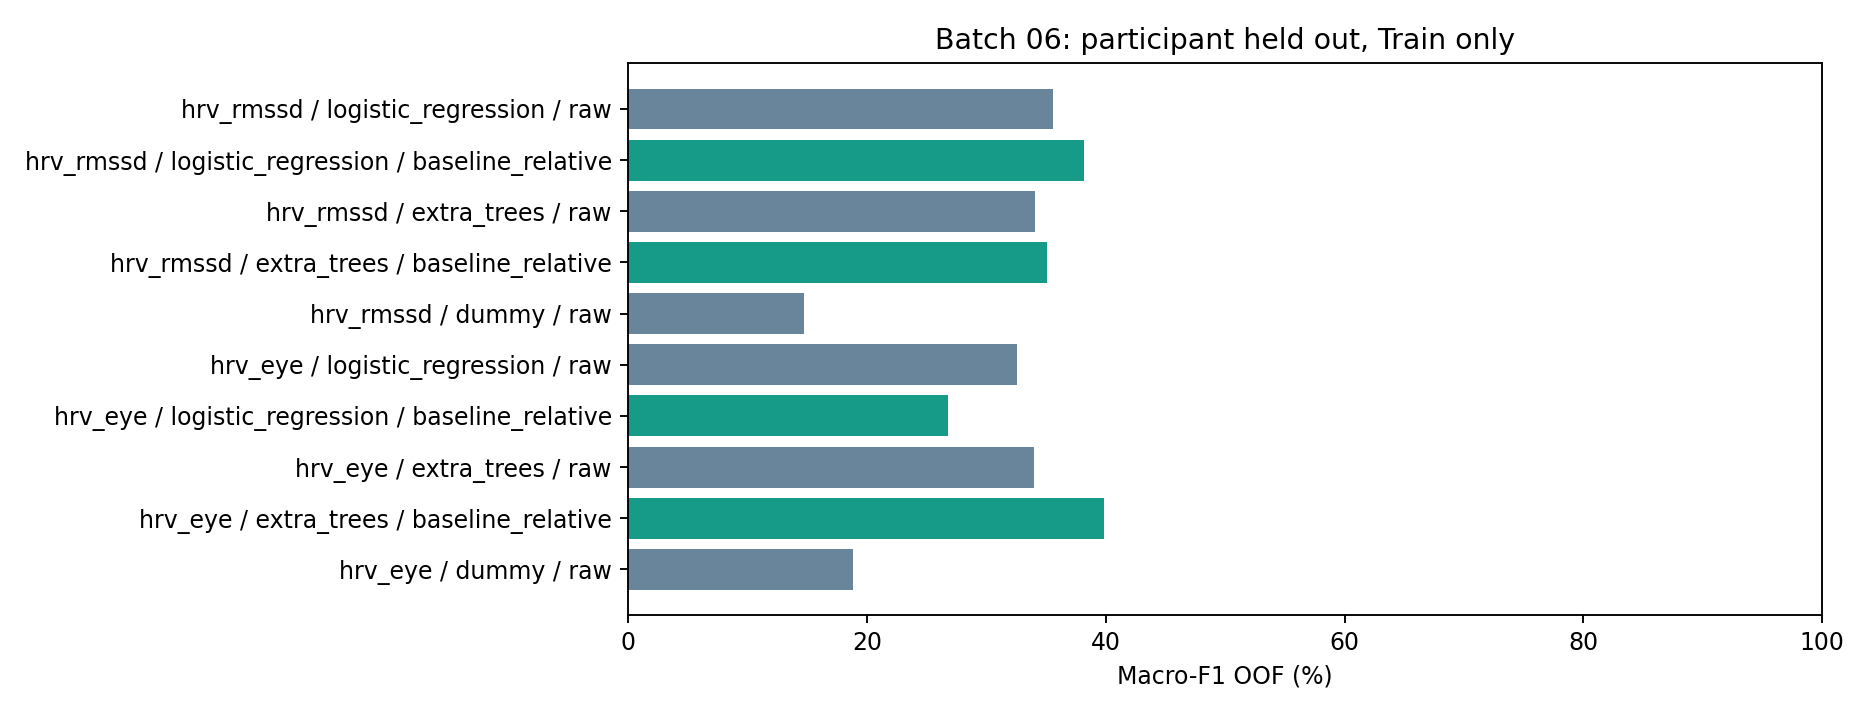

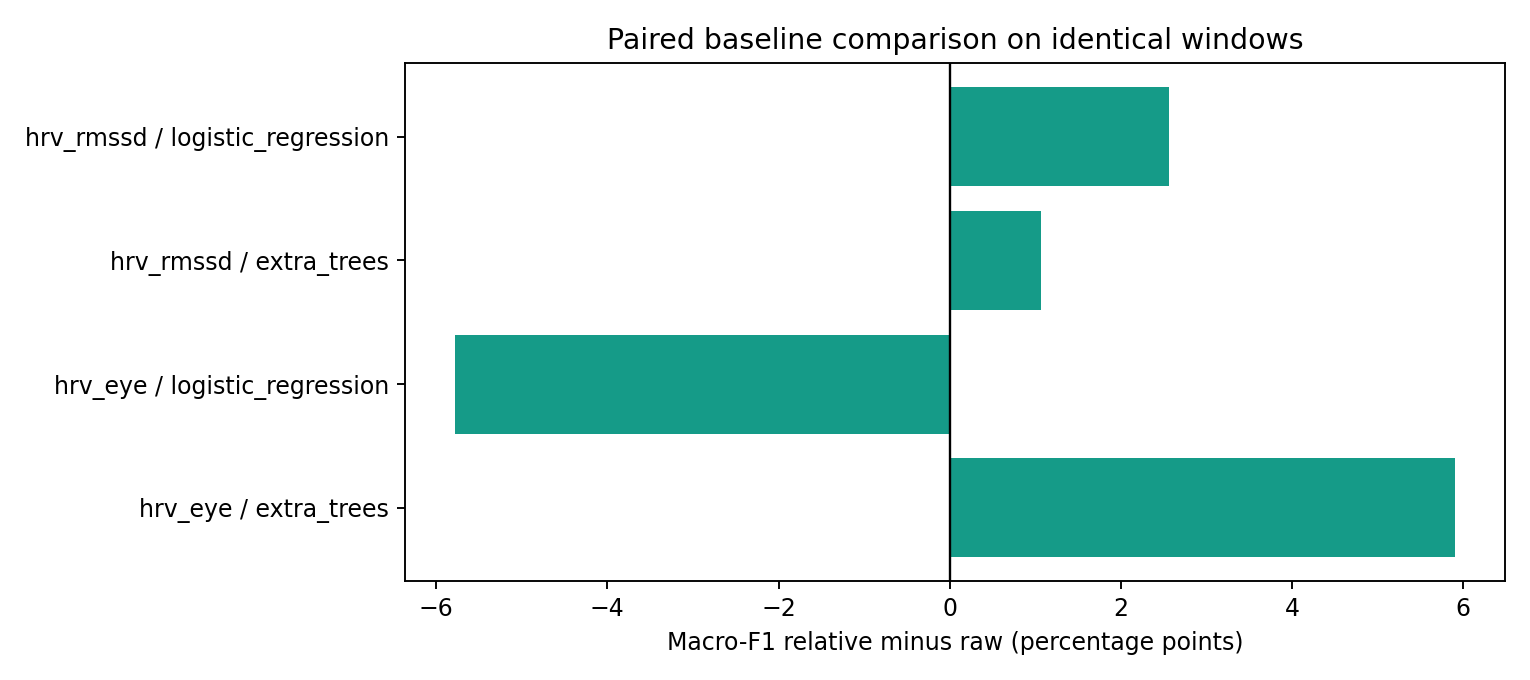

Folder hasil: /content/drive/MyDrive/Penelitian-Adaptive-IDE/models/batch-06/outputs/exp01/baseline_20261123T192338Z_8d8cee5e


In [7]:
from IPython.display import Image, Markdown, display

display(training['leaderboard'])
display(training['paired'])
display(training['validation'])
display(Markdown((training['run_dir'] / 'RESULTS.md').read_text(encoding='utf-8')))
for name in ('participant_oof.png', 'paired_change.png'):
    display(Image(filename=str(training['run_dir'] / 'figures' / name)))
print('Folder hasil:', training['run_dir'])